# 07 — Capacity Adequacy and Gap Analysis

This stage aligns the probabilistic peak-demand scenarios from Stage 06 with ERCOT's published supply-side capacity data. It evaluates capacity margins, reserve margins, possible shortfalls, and deterministic supply-stress scenarios.

**Interpretation boundaries:** The 2025 historical backtest is distinct from 2026–2029 planning assumptions. Nameplate capacity is not equivalent to peak-hour availability; proposed or queued projects are not automatically firm capacity; and independently observed regional peaks cannot be summed as though they occur simultaneously.

Stages 01–06 address *how much electricity may be needed*. Stage 07 addresses *how much capacity the system is assumed to make available and how that compares with demand*. Official supply datasets are used for adequacy comparisons, not to redefine the demand forecasts.

**Historical supply-data vintage:** This model uses the ERCOT **December 2024 Revised CDR** as a fixed 2025–2029 planning snapshot. Its project pipeline, operating-capacity assumptions, and future margins should not be presented as current ERCOT forecasts or realized system outcomes. The conditional stress tests are sensitivity results, not predictions of event occurrence.

## 07.00 — Workflow and comparison framework

1. Audit the annual, seasonal, monthly, and regional demand inputs from Stage 06.
2. Register ERCOT CDR, MORA, SARA, and GIS sources and publication dates.
3. Distinguish installed, seasonal-rated, available, ELCC-adjusted, and firm-capacity concepts.
4. Align supply and demand for consistent planning years, seasons, and—where supported—months.
5. Calculate capacity and reserve margins and identify first shortfall years.
6. Screen generation outages, low wind/solar output, reduced storage contribution, winter events, and summer heat scenarios.
7. Prepare annual, seasonal, synchronized regional allocations, and sensitivity summaries.

**Definitions:** `capacity_margin_mw = available_capacity_mw - peak_demand_mw` and `reserve_margin = capacity_margin_mw / peak_demand_mw`.

The implemented final continuous-year outputs focus on seasonal comparisons; this notebook does not establish a complete monthly probabilistic adequacy model.

In [ ]:
# 07.01 — Environment, repository paths, and output directories
from pathlib import Path
import json
import platform

import numpy as np
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display = print

def locate_project_root():
    """Locate the project from either the repository root or its notebooks folder."""
    working_dir = Path.cwd().resolve()
    for candidate in (working_dir, *working_dir.parents):
        if (candidate / 'report').is_dir() and (candidate / 'notebooks').is_dir():
            return candidate
    if working_dir.name == 'notebooks':
        return working_dir.parent
    return working_dir

PROJECT_ROOT = locate_project_root()

def display_project_path(path):
    """Use a repository-relative path in printed output to avoid revealing local directories."""
    candidate = Path(path)
    try:
        return str(candidate.resolve().relative_to(PROJECT_ROOT.resolve()))
    except ValueError:
        return candidate.name

PEAK_INPUT_DIR = PROJECT_ROOT / 'report' / 'tables' / 'peak_uncertainty'
CAPACITY_RAW_DIR = PROJECT_ROOT / 'data' / 'raw' / 'ercot_capacity'
CAPACITY_PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed' / 'capacity'
CAPACITY_TABLE_DIR = PROJECT_ROOT / 'report' / 'tables' / 'capacity_adequacy'
CAPACITY_FIGURE_DIR = PROJECT_ROOT / 'report' / 'figures' / 'capacity_adequacy'

for directory in [CAPACITY_RAW_DIR, CAPACITY_PROCESSED_DIR, CAPACITY_TABLE_DIR, CAPACITY_FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print('Project folder:', PROJECT_ROOT.name)
print('Python:', platform.python_version())
print('pandas:', pd.__version__)

In [ ]:
# 07.02 — Audit Stage 06 input files
REQUIRED_DEMAND_INPUTS = {
    'annual': '06_16_final_annual_capacity_planning.csv',
    'seasonal': '06_16_final_seasonal_capacity_planning.csv',
    'monthly': '06_16_final_monthly_capacity_planning.csv',
    'regional': '06_18_regional_capacity_allocation.csv',
    'key_metrics': '06_19_final_key_metrics.csv',
    'methodology': '06_19_final_methodology_summary.csv',
    'qa': '06_19_final_qa_checks.csv',
}

input_audit_records = []
demand_tables = {}
for table_name, filename in REQUIRED_DEMAND_INPUTS.items():
    path = PEAK_INPUT_DIR / filename
    exists = path.exists()
    table = pd.read_csv(path) if exists else None
    if exists:
        demand_tables[table_name] = table
    input_audit_records.append({
        'table_name': table_name,
        'filename': filename,
        'exists': exists,
        'rows': len(table) if exists else None,
        'columns': len(table.columns) if exists else None,
    })

input_audit = pd.DataFrame(input_audit_records)
display(input_audit)

if not input_audit['exists'].all():
    missing = input_audit.loc[~input_audit['exists'], 'filename'].tolist()
    raise FileNotFoundError(f'Missing required stage-06 inputs: {missing}')

qa_table = demand_tables['qa'].copy()
qa_passed = qa_table['passed'].astype(str).str.lower().eq('true')
if not qa_passed.all():
    failed_checks = qa_table.loc[~qa_passed, 'check'].tolist()
    raise ValueError(f'Stage-06 QA failures remain: {failed_checks}')

annual_demand = demand_tables['annual'].copy()
required_annual_columns = [
    'bootstrap_peak_p50_mw',
    'bootstrap_peak_p90_mw',
    'bootstrap_peak_p95_mw',
]
missing_columns = sorted(set(required_annual_columns) - set(annual_demand.columns))
if missing_columns:
    raise ValueError(f'Annual demand table missing columns: {missing_columns}')

quantiles_ordered = bool((annual_demand['bootstrap_peak_p50_mw'] <= annual_demand['bootstrap_peak_p90_mw']).all() and (annual_demand['bootstrap_peak_p90_mw'] <= annual_demand['bootstrap_peak_p95_mw']).all())
if not quantiles_ordered:
    raise ValueError('Annual P50/P90/P95 ordering check failed.')

annual_scenarios = annual_demand.loc[:, required_annual_columns].T.reset_index()
annual_scenarios.columns = ['scenario', 'peak_demand_mw']
annual_scenarios['peak_demand_gw'] = annual_scenarios['peak_demand_mw'] / 1000
display(annual_scenarios.round(3))

input_audit.to_csv(CAPACITY_TABLE_DIR / '07_02_stage06_input_audit.csv', index=False)

,table_name,filename,exists,rows,columns
0,annual,06_16_final_annual_capacity_planning.csv,True,1,15
1,seasonal,06_16_final_seasonal_capacity_planning.csv,True,4,14
2,monthly,06_16_final_monthly_capacity_planning.csv,True,12,14
3,regional,06_18_regional_capacity_allocation.csv,True,8,19
4,key_metrics,06_19_final_key_metrics.csv,True,7,3
5,methodology,06_19_final_methodology_summary.csv,True,7,4
6,qa,06_19_final_qa_checks.csv,True,10,4


,scenario,peak_demand_mw,peak_demand_gw
0,bootstrap_peak_p50_mw,84782.949,84.783
1,bootstrap_peak_p90_mw,85646.229,85.646
2,bootstrap_peak_p95_mw,85938.352,85.938


## 07.03 — Capacity terminology and ERCOT data roles

- **Installed capacity:** nameplate or nominal capacity; not directly interchangeable with capacity available at peak demand.
- **Seasonal-rated capacity:** capacity reflecting seasonal ratings, particularly relevant to thermal resources.
- **Available capacity:** capacity potentially deliverable in the relevant period after accounting for applicable availability constraints.
- **Capacity contribution / ELCC:** reliability-adjusted contributions from wind, solar, and battery energy storage; not simply nameplate MW.
- **Firm capacity:** capacity that meets a specified dependability definition; interpretation depends on the ERCOT report and metric.

**Source roles:** CDR supplies multiyear planning assumptions and reported capacity contributions; MORA informs monthly probabilistic risk analyses; SARA covers seasonal extreme-case assessments; GIS supports screening of prospective projects. Registering a source does not mean all of its metrics are used in the final model.

In [ ]:
# 07.04 — Register official supply-side data sources
capacity_source_registry = pd.DataFrame([
    {
        'source_id': 'ERCOT_CDR',
        'report_family': 'Capacity, Demand and Reserves',
        'planning_horizon': 'multi-year / seasonal',
        'primary_use': 'planning capacity, ELCC contribution, additions and retirements, reserve margin benchmark',
        'status': 'required_not_ingested',
        'local_file': '',
        'publication_date': '',
        'source_url': 'https://www.ercot.com/gridinfo/sysplan',
    },
    {
        'source_id': 'ERCOT_MORA',
        'report_family': 'Monthly Outlook for Resource Adequacy',
        'planning_horizon': 'monthly / hourly scenarios',
        'primary_use': 'monthly resource availability, outages, probabilistic shortfall risk',
        'status': 'required_not_ingested',
        'local_file': '',
        'publication_date': '',
        'source_url': 'https://www.ercot.com/gridinfo/resource',
    },
    {
        'source_id': 'ERCOT_SARA',
        'report_family': 'Seasonal Assessment of Resource Adequacy',
        'planning_horizon': 'seasonal stress scenarios',
        'primary_use': 'extreme load, thermal outages, low wind/solar and seasonal reserve stress',
        'status': 'required_not_ingested',
        'local_file': '',
        'publication_date': '',
        'source_url': 'https://www.ercot.com/gridinfo/resource',
    },
    {
        'source_id': 'ERCOT_GIS',
        'report_family': 'Generator Interconnection Status',
        'planning_horizon': 'project pipeline',
        'primary_use': 'screen future additions by development milestone; never treat queue capacity as firm',
        'status': 'optional_not_ingested',
        'local_file': '',
        'publication_date': '',
        'source_url': 'https://www.ercot.com/news/presentations',
    },
])

capacity_source_registry.to_csv(CAPACITY_TABLE_DIR / '07_04_capacity_source_registry.csv', index=False)
display(capacity_source_registry)

if capacity_source_registry['status'].eq('ingested').any():
    raise ValueError('Source status must remain not_ingested until files and publication dates are verified.')

,source_id,report_family,planning_horizon,primary_use,status,local_file,publication_date,source_url
0,ERCOT_CDR,"Capacity, Demand and Reserves",multi-year / seasonal,"planning capacity, ELCC contribution, addition...",required_not_ingested,,,https://www.ercot.com/gridinfo/sysplan
1,ERCOT_MORA,Monthly Outlook for Resource Adequacy,monthly / hourly scenarios,"monthly resource availability, outages, probab...",required_not_ingested,,,https://www.ercot.com/gridinfo/resource
2,ERCOT_SARA,Seasonal Assessment of Resource Adequacy,seasonal stress scenarios,"extreme load, thermal outages, low wind/solar ...",required_not_ingested,,,https://www.ercot.com/gridinfo/resource
3,ERCOT_GIS,Generator Interconnection Status,project pipeline,screen future additions by development milesto...,optional_not_ingested,,,https://www.ercot.com/news/presentations


## Next checkpoint

Run Sections 07.01–07.04 first. Capacity normalization and reserve-margin calculations should begin only after the Stage 06 input audit passes and the official CDR workbook's filename, publication vintage, worksheet names, and units have been recorded.

In [ ]:
# 07.05 — Download and audit the 2025–2029 ERCOT CDR vintage
# ============================================================

# ============================================================

import hashlib

CDR_2024_FILENAME = (
    "CapacityDemandandReservesReport_December2024.xlsx"
)

cdr_2024_path = (
    CAPACITY_RAW_DIR
    / CDR_2024_FILENAME
)

CDR_2024_SOURCE_URL = (
    "https://www.ercot.com/files/docs/"
    "2025/02/12/"
    "CapacityDemandandReservesReport_December2024.xlsx"
)

CDR_2024_PUBLICATION_DATE = (
    pd.Timestamp("2025-02-13")
)

CDR_2024_PLANNING_START_YEAR = 2025

CDR_2024_PLANNING_END_YEAR = 2029

cdr_2024_exists = (
    cdr_2024_path.exists()
)

if not cdr_2024_exists:
    raise FileNotFoundError(
        "ERCOT CDR Excel file not found.\n"
        f"Place the file at: {cdr_2024_path}\n"
        f"Official download URL: {CDR_2024_SOURCE_URL}"
    )

cdr_2024_size_bytes = (
    cdr_2024_path.stat().st_size
)

cdr_2024_size_kb = (
    cdr_2024_size_bytes
    / 1024
)

cdr_2024_hash_calculator = (
    hashlib.sha256()
)

with cdr_2024_path.open("rb") as cdr_file:

    for file_chunk in iter(
        lambda: cdr_file.read(1024 * 1024),
        b"",
    ):

        cdr_2024_hash_calculator.update(
            file_chunk
        )

cdr_2024_sha256 = (
    cdr_2024_hash_calculator.hexdigest()
)

cdr_2024_workbook = (
    pd.ExcelFile(
        cdr_2024_path,
        engine="openpyxl",
    )
)

cdr_2024_sheet_names = (
    cdr_2024_workbook.sheet_names
)

cdr_2024_sheet_count = (
    len(cdr_2024_sheet_names)
)

cdr_2024_sheet_inventory = (
    pd.DataFrame(
        {

            "sheet_order": range(
                1,
                cdr_2024_sheet_count + 1,
            ),

            "sheet_name": (
                cdr_2024_sheet_names
            ),
        }
    )
)

cdr_2024_file_audit = (
    pd.DataFrame(
        [
            {

                "source_organization":
                    "ERCOT",

                "report_family":
                    "Capacity, Demand and Reserves",

                "report_version":
                    "December 2024 Revised",

                "publication_date":
                    CDR_2024_PUBLICATION_DATE.date(),

                "planning_start_year":
                    CDR_2024_PLANNING_START_YEAR,

                "planning_end_year":
                    CDR_2024_PLANNING_END_YEAR,

                "filename":
                    CDR_2024_FILENAME,

                "local_path":
                    str(cdr_2024_path),

                "source_url":
                    CDR_2024_SOURCE_URL,

                "size_bytes":
                    cdr_2024_size_bytes,

                "size_kb":
                    cdr_2024_size_kb,

                "sheet_count":
                    cdr_2024_sheet_count,

                "sha256":
                    cdr_2024_sha256,

                "readable":
                    True,

                "analysis_role": (
                    "2025 historical planning benchmark; "
                    "not real-time availability"
                ),
            }
        ]
    )
)

cdr_2024_file_audit_path = (
    CAPACITY_TABLE_DIR
    / "07_05_cdr_2024_file_audit.csv"
)

cdr_2024_sheet_inventory_path = (
    CAPACITY_TABLE_DIR
    / "07_05_cdr_2024_sheet_inventory.csv"
)

cdr_2024_file_audit.to_csv(
    cdr_2024_file_audit_path,
    index=False,
)

cdr_2024_sheet_inventory.to_csv(
    cdr_2024_sheet_inventory_path,
    index=False,
)

print(
    "ERCOT CDR file audit results:"
)

display(
    cdr_2024_file_audit
)

print(
    "\nCDR worksheet count: ",
    cdr_2024_sheet_count,
)

print(
    "\nCDR worksheet inventory:"
)

display(
    cdr_2024_sheet_inventory
)

print(
    "\nSaved file audit: ",
    cdr_2024_file_audit_path,
)

print(
    "Saved worksheet inventory: ",
    cdr_2024_sheet_inventory_path,
)

,source_organization,report_family,report_version,publication_date,planning_start_year,planning_end_year,filename,local_path,source_url,size_bytes,size_kb,sheet_count,sha256,readable,analysis_role
0,ERCOT,"Capacity, Demand and Reserves",December 2024 Revised,2025-02-13,2025,2029,CapacityDemandandReservesReport_December2024.xlsx,[project-root]/data/...,https://www.ercot.com/files/docs/2025/02/12/Ca...,864521,844.258789,18,847018a349df09186900f17971ab7da0f68833e29e2383...,True,2025 historical planning benchmark; not real-t...


,sheet_order,sheet_name
0,1,TitlePage
1,2,Contents
2,3,Disclaimer
3,4,Main Report-------->
4,5,Findings & Discussion
5,6,Load-Resource Scenarios
6,7,Summer Summary
7,8,Winter Summary
8,9,Data Tables-------->
9,10,Unit Details


> **Stage note.** Before extracting numerical values, inspect the CDR workbook’s merged headers and locate the required metric rows.

In [ ]:
# 07.06 — Locate critical CDR worksheet fields
# ============================================================

# ============================================================

CDR_TARGET_SHEETS = [

    "Summer Summary",

    "Winter Summary",

    "Unit Details",

    "Capacity by Resource Type",

    "ELCCs",
]

CDR_SEARCH_KEYWORDS = [

    "Firm Peak Load",

    "Total Capacity",

    "Reserve Margin",

    "Operational Generation Capacity",

    "Installed Summer-rated Capacity",

    "Installed Winter-rated Capacity",

    "Planned Resource Additions",

    "Capacity Pending Retirement",

    "Effective Load Carrying Capabilities",

    "Energy Storage",

    "Resource Type",

    "Status",
]

def trim_empty_sheet_edges(
    raw_table,
):

    trimmed_table = (
        raw_table.dropna(
            axis=0,
            how="all",
        )
        .copy()
    )

    trimmed_table = (
        trimmed_table.dropna(
            axis=1,
            how="all",
        )
        .copy()
    )

    return trimmed_table

def combine_row_text(
    row_values,
):

    clean_values = (
        row_values.fillna("")
    )

    string_values = (
        clean_values.astype(str)
    )

    combined_text = (
        " | ".join(
            string_values.tolist()
        )
    )

    combined_text = (
        combined_text.strip()
    )

    return combined_text

def scan_keyword_rows(
    sheet_name,
    sheet_table,
    search_keywords,
):

    match_records = []

    for row_index, row_values in (
        sheet_table.iterrows()
    ):

        row_text = combine_row_text(
            row_values
        )

        row_text_lower = (
            row_text.lower()
        )

        for keyword in search_keywords:

            keyword_found = (
                keyword.lower()
                in row_text_lower
            )

            if not keyword_found:
                continue

            match_records.append(
                {

                    "sheet_name":
                        sheet_name,

                    "excel_row":
                        int(row_index) + 1,

                    "matched_keyword":
                        keyword,

                    "row_text_preview":
                        row_text[:1000],
                }
            )

    match_table = (
        pd.DataFrame(
            match_records
        )
    )

    return match_table

cdr_raw_sheet_tables = {}

cdr_sheet_structure_records = []

cdr_keyword_match_tables = []

for sheet_name in CDR_TARGET_SHEETS:

    raw_sheet_table = (
        pd.read_excel(
            cdr_2024_path,
            sheet_name=sheet_name,
            header=None,
            engine="openpyxl",
        )
    )

    cdr_raw_sheet_tables[
        sheet_name
    ] = raw_sheet_table

    trimmed_sheet_table = (
        trim_empty_sheet_edges(
            raw_sheet_table
        )
    )

    if trimmed_sheet_table.empty:
        raise ValueError(
            f"Worksheet is empty: {sheet_name}"
        )

    first_nonempty_excel_row = (
        int(
            trimmed_sheet_table
            .index
            .min()
        )
        + 1
    )

    last_nonempty_excel_row = (
        int(
            trimmed_sheet_table
            .index
            .max()
        )
        + 1
    )

    cdr_sheet_structure_records.append(
        {

            "sheet_name":
                sheet_name,

            "original_rows":
                raw_sheet_table.shape[0],

            "original_columns":
                raw_sheet_table.shape[1],

            "nonempty_rows":
                trimmed_sheet_table.shape[0],

            "nonempty_columns":
                trimmed_sheet_table.shape[1],

            "first_nonempty_excel_row":
                first_nonempty_excel_row,

            "last_nonempty_excel_row":
                last_nonempty_excel_row,
        }
    )

    current_keyword_matches = (
        scan_keyword_rows(
            sheet_name=sheet_name,
            sheet_table=trimmed_sheet_table,
            search_keywords=(
                CDR_SEARCH_KEYWORDS
            ),
        )
    )

    if not current_keyword_matches.empty:
        cdr_keyword_match_tables.append(
            current_keyword_matches
        )

    sheet_preview = (
        trimmed_sheet_table
        .head(60)
        .iloc[:, :30]
        .copy()
    )

    sheet_preview.index = (
        sheet_preview.index
        + 1
    )

    sheet_preview.index.name = (
        "excel_row"
    )

    safe_sheet_filename = (
        sheet_name.lower()
        .replace(" ", "_")
        .replace("&", "and")
    )

    sheet_preview_path = (
        CAPACITY_TABLE_DIR
        / (
            "07_06_preview_"
            f"{safe_sheet_filename}.csv"
        )
    )

    sheet_preview.to_csv(
        sheet_preview_path,
        index=True,
        header=False,
    )

cdr_sheet_structure_summary = (
    pd.DataFrame(
        cdr_sheet_structure_records
    )
)

if cdr_keyword_match_tables:

    cdr_keyword_matches = (
        pd.concat(
            cdr_keyword_match_tables,
            ignore_index=True,
        )
    )

else:

    cdr_keyword_matches = (
        pd.DataFrame(
            columns=[
                "sheet_name",
                "excel_row",
                "matched_keyword",
                "row_text_preview",
            ]
        )
    )

cdr_keyword_matches = (
    cdr_keyword_matches.sort_values(
        [
            "sheet_name",
            "excel_row",
            "matched_keyword",
        ]
    )
    .reset_index(
        drop=True
    )
)

cdr_sheet_structure_summary_path = (
    CAPACITY_TABLE_DIR
    / "07_06_cdr_sheet_structure_summary.csv"
)

cdr_keyword_matches_path = (
    CAPACITY_TABLE_DIR
    / "07_06_cdr_keyword_matches.csv"
)

cdr_sheet_structure_summary.to_csv(
    cdr_sheet_structure_summary_path,
    index=False,
)

cdr_keyword_matches.to_csv(
    cdr_keyword_matches_path,
    index=False,
)

print(
    "CDR key worksheet structure summary:"
)

display(
    cdr_sheet_structure_summary
)

print(
    "\nKeyword-match count: ",
    len(cdr_keyword_matches),
)

display(
    cdr_keyword_matches[
        [
            "sheet_name",
            "excel_row",
            "matched_keyword",
        ]
    ]
)

print(
    "\nSaved worksheet structure summary: ",
    cdr_sheet_structure_summary_path,
)

print(
    "Saved keyword matches: ",
    cdr_keyword_matches_path,
)

,sheet_name,original_rows,original_columns,nonempty_rows,nonempty_columns,first_nonempty_excel_row,last_nonempty_excel_row
0,Summer Summary,61,18,54,17,1,61
1,Winter Summary,61,18,54,17,1,61
2,Unit Details,1641,21,1639,21,2,1641
3,Capacity by Resource Type,65,6,62,5,2,65
4,ELCCs,44,21,40,21,1,44


,sheet_name,excel_row,matched_keyword
0,Capacity by Resource Type,10,Energy Storage
1,Capacity by Resource Type,25,Energy Storage
2,Capacity by Resource Type,39,Energy Storage
3,Capacity by Resource Type,50,Energy Storage
4,ELCCs,3,Energy Storage
...,...,...,...
60,Winter Summary,44,Planned Resource Additions
61,Winter Summary,46,Effective Load Carrying Capabilities
62,Winter Summary,53,Energy Storage
63,Winter Summary,56,Total Capacity


> **Stage note.** Worksheet inspection identifies where the headers and relevant capacity metrics appear in the source workbook.

In [ ]:
# 07.07 — Extract the official seasonal supply and demand benchmarks
# ============================================================

# ============================================================

def normalize_planning_period(
    period_value,
):

    if pd.isna(period_value):
        raise ValueError(
            "Missing CDR planning-period label."
        )

    if isinstance(
        period_value,
        (int, np.integer),
    ):
        return str(
            int(period_value)
        )

    if isinstance(
        period_value,
        (float, np.floating),
    ) and float(period_value).is_integer():
        return str(
            int(period_value)
        )

    return str(
        period_value
    ).strip()

def find_unique_metric_row(
    raw_table,
    metric_label,
    contains=False,
):

    matched_row_indices = []

    for row_index, row_values in (
        raw_table.iterrows()
    ):

        clean_row_values = (
            row_values.fillna("")
        )

        cell_text_values = [
            str(cell_value).strip()
            for cell_value in clean_row_values
        ]

        if contains:

            row_matches = any(
                metric_label.lower()
                in cell_text.lower()
                for cell_text in cell_text_values
            )

        else:

            row_matches = any(
                cell_text == metric_label
                for cell_text in cell_text_values
            )

        if row_matches:
            matched_row_indices.append(
                row_index
            )

    if len(matched_row_indices) == 0:
        raise ValueError(
            f"Metric not found: {metric_label}"
        )

    if len(matched_row_indices) > 1:
        raise ValueError(
            f"Metric occurs multiple times: {metric_label}；"
            f"Matched row(s): {matched_row_indices}"
        )

    return matched_row_indices[0]

def extract_cdr_summary(
    sheet_name,
    season_name,
):

    raw_summary = (
        pd.read_excel(
            cdr_2024_path,
            sheet_name=sheet_name,
            header=None,
            engine="openpyxl",
        )
    )

    firm_peak_load_row = (
        find_unique_metric_row(
            raw_table=raw_summary,
            metric_label=(
                "Firm Peak Load, MW"
            ),
        )
    )

    operational_capacity_row = (
        find_unique_metric_row(
            raw_table=raw_summary,
            metric_label=(
                "Operational Generation "
                "Capacity, Total"
            ),
        )
    )

    non_synchronous_ties_row = (
        find_unique_metric_row(
            raw_table=raw_summary,
            metric_label=(
                "Non-Synchronous Ties"
            ),
            contains=True,
        )
    )

    planned_capacity_row = (
        find_unique_metric_row(
            raw_table=raw_summary,
            metric_label=(
                "Planned Generation Capacity "
                "Total, Net of Unconfirmed "
                "Planned Retirements"
            ),
        )
    )

    total_capacity_row = (
        find_unique_metric_row(
            raw_table=raw_summary,
            metric_label=(
                "Total Capacity"
            ),
        )
    )

    reserve_margin_row = (
        find_unique_metric_row(
            raw_table=raw_summary,
            metric_label=(
                "Reserve Margin"
            ),
        )
    )

    summary_records = []

    for period_group_index in range(5):

        first_period_column = (
            3
            + period_group_index * 3
        )

        planning_period = (
            normalize_planning_period(
                raw_summary.iloc[
                    2,
                    first_period_column,
                ]
            )
        )

        view_column_offsets = {

            "peak_load_hour": 0,

            "peak_net_load_hour": 1,
        }

        for (
            risk_view,
            view_column_offset,
        ) in view_column_offsets.items():

            value_column = (
                first_period_column
                + view_column_offset
            )

            peak_hour_ending = (
                pd.to_numeric(
                    raw_summary.iloc[
                        4,
                        value_column,
                    ],
                    errors="raise",
                )
            )

            firm_peak_load_mw = (
                pd.to_numeric(
                    raw_summary.iloc[
                        firm_peak_load_row,
                        value_column,
                    ],
                    errors="raise",
                )
            )

            operational_capacity_mw = (
                pd.to_numeric(
                    raw_summary.iloc[
                        operational_capacity_row,
                        value_column,
                    ],
                    errors="raise",
                )
            )

            non_synchronous_ties_mw = (
                pd.to_numeric(
                    raw_summary.iloc[
                        non_synchronous_ties_row,
                        value_column,
                    ],
                    errors="raise",
                )
            )

            planned_capacity_net_mw = (
                pd.to_numeric(
                    raw_summary.iloc[
                        planned_capacity_row,
                        value_column,
                    ],
                    errors="raise",
                )
            )

            total_capacity_mw = (
                pd.to_numeric(
                    raw_summary.iloc[
                        total_capacity_row,
                        value_column,
                    ],
                    errors="raise",
                )
            )

            official_reserve_margin = (
                pd.to_numeric(
                    raw_summary.iloc[
                        reserve_margin_row,
                        value_column,
                    ],
                    errors="raise",
                )
            )

            summary_records.append(
                {

                    "season":
                        season_name,

                    "planning_period":
                        planning_period,

                    "risk_view":
                        risk_view,

                    "peak_hour_ending":
                        int(
                            peak_hour_ending
                        ),

                    "official_firm_peak_load_mw":
                        float(
                            firm_peak_load_mw
                        ),

                    "operational_generation_capacity_mw":
                        float(
                            operational_capacity_mw
                        ),

                    "non_synchronous_ties_mw":
                        float(
                            non_synchronous_ties_mw
                        ),

                    "planned_generation_capacity_net_mw":
                        float(
                            planned_capacity_net_mw
                        ),

                    "official_total_capacity_mw":
                        float(
                            total_capacity_mw
                        ),

                    "official_reserve_margin":
                        float(
                            official_reserve_margin
                        ),

                    "source_sheet":
                        sheet_name,

                    "source_vintage":
                        "December 2024 Revised",

                    "publication_date":
                        pd.Timestamp(
                            "2025-02-13"
                        ),
                }
            )

    summary_table = (
        pd.DataFrame(
            summary_records
        )
    )

    return summary_table

cdr_summer_summary = (
    extract_cdr_summary(
        sheet_name=(
            "Summer Summary"
        ),
        season_name=(
            "Summer"
        ),
    )
)

cdr_winter_summary = (
    extract_cdr_summary(
        sheet_name=(
            "Winter Summary"
        ),
        season_name=(
            "Winter"
        ),
    )
)

cdr_seasonal_supply_benchmark = (
    pd.concat(
        [
            cdr_summer_summary,
            cdr_winter_summary,
        ],
        ignore_index=True,
    )
)

cdr_seasonal_supply_benchmark[
    "calculated_total_capacity_mw"
] = (
    cdr_seasonal_supply_benchmark[
        "operational_generation_capacity_mw"
    ]
    + cdr_seasonal_supply_benchmark[
        "non_synchronous_ties_mw"
    ]
    + cdr_seasonal_supply_benchmark[
        "planned_generation_capacity_net_mw"
    ]
)

cdr_seasonal_supply_benchmark[
    "total_capacity_reconciliation_mw"
] = (
    cdr_seasonal_supply_benchmark[
        "official_total_capacity_mw"
    ]
    - cdr_seasonal_supply_benchmark[
        "calculated_total_capacity_mw"
    ]
)

cdr_seasonal_supply_benchmark[
    "calculated_reserve_margin"
] = (
    (
        cdr_seasonal_supply_benchmark[
            "official_total_capacity_mw"
        ]
        - cdr_seasonal_supply_benchmark[
            "official_firm_peak_load_mw"
        ]
    )
    / cdr_seasonal_supply_benchmark[
        "official_firm_peak_load_mw"
    ]
)

cdr_seasonal_supply_benchmark[
    "reserve_margin_reconciliation_pct_point"
] = (
    (
        cdr_seasonal_supply_benchmark[
            "official_reserve_margin"
        ]
        - cdr_seasonal_supply_benchmark[
            "calculated_reserve_margin"
        ]
    )
    * 100
)

total_capacity_reconciliation_passed = (
    cdr_seasonal_supply_benchmark[
        "total_capacity_reconciliation_mw"
    ]
    .abs()
    .le(0.1)
    .all()
)

reserve_margin_reconciliation_passed = (
    cdr_seasonal_supply_benchmark[
        "reserve_margin_reconciliation_pct_point"
    ]
    .abs()
    .le(0.000001)
    .all()
)

if not total_capacity_reconciliation_passed:
    raise ValueError(
        "CDR capacity components do not reconcile to the official total."
    )

if not reserve_margin_reconciliation_passed:
    raise ValueError(
        "CDR reserve margin does not reconcile to the official result."
    )

cdr_07_07_qa = (
    pd.DataFrame(
        [
            {

                "check":
                    "Expected 20 seasonal-view rows",

                "passed":
                    len(
                        cdr_seasonal_supply_benchmark
                    ) == 20,

                "observed":
                    len(
                        cdr_seasonal_supply_benchmark
                    ),

                "expected":
                    20,
            },
            {

                "check":
                    "Total capacity components reconcile",

                "passed":
                    total_capacity_reconciliation_passed,

                "observed":
                    cdr_seasonal_supply_benchmark[
                        "total_capacity_reconciliation_mw"
                    ]
                    .abs()
                    .max(),

                "expected":
                    "<= 0.1 MW",
            },
            {

                "check":
                    "Reserve margin formula reconciles",

                "passed":
                    reserve_margin_reconciliation_passed,

                "observed":
                    cdr_seasonal_supply_benchmark[
                        "reserve_margin_reconciliation_pct_point"
                    ]
                    .abs()
                    .max(),

                "expected":
                    "<= 0.000001 percentage point",
            },
        ]
    )
)

cdr_seasonal_supply_benchmark_path = (
    CAPACITY_TABLE_DIR
    / "07_07_cdr_seasonal_supply_benchmark.csv"
)

cdr_07_07_qa_path = (
    CAPACITY_TABLE_DIR
    / "07_07_cdr_seasonal_supply_qa.csv"
)

cdr_seasonal_supply_benchmark.to_csv(
    cdr_seasonal_supply_benchmark_path,
    index=False,
)

cdr_07_07_qa.to_csv(
    cdr_07_07_qa_path,
    index=False,
)

cdr_near_term_benchmark = (
    cdr_seasonal_supply_benchmark.loc[
        (
            cdr_seasonal_supply_benchmark[
                "season"
            ].eq("Summer")
            & cdr_seasonal_supply_benchmark[
                "planning_period"
            ].eq("2025")
        )
        |
        (
            cdr_seasonal_supply_benchmark[
                "season"
            ].eq("Winter")
            & cdr_seasonal_supply_benchmark[
                "planning_period"
            ].eq("2025/26")
        )
    ]
    .copy()
)

cdr_near_term_benchmark[
    "official_reserve_margin_pct"
] = (
    cdr_near_term_benchmark[
        "official_reserve_margin"
    ]
    * 100
)

print(
    "ERCOT seasonal demand and supply baseline: "
)

display(
    cdr_near_term_benchmark[
        [
            "season",
            "planning_period",
            "risk_view",
            "peak_hour_ending",
            "official_firm_peak_load_mw",
            "official_total_capacity_mw",
            "official_reserve_margin_pct",
        ]
    ]
    .round(2)
)

print(
    "\n07.07 quality assurance: "
)

display(
    cdr_07_07_qa
)

print(
    "\nSaved CDR seasonal supply-demand baseline: ",
    cdr_seasonal_supply_benchmark_path,
)

print(
    "Saved 07.07 QA: ",
    cdr_07_07_qa_path,
)

,season,planning_period,risk_view,peak_hour_ending,official_firm_peak_load_mw,official_total_capacity_mw,official_reserve_margin_pct
0,Summer,2025,peak_load_hour,17,86716.91,103105.48,18.90
1,Summer,2025,peak_net_load_hour,21,82963.97,91651.80,10.47
10,Winter,2025/26,peak_load_hour,8,78607.89,97254.73,23.72
11,Winter,2025/26,peak_net_load_hour,19,72843.42,96438.15,32.39


,check,passed,observed,expected
0,Expected 20 seasonal-view rows,True,20.0,20
1,Total capacity components reconcile,True,0.0,<= 0.1 MW
2,Reserve margin formula reconciles,True,0.0,<= 0.000001 percentage point


> **Stage note.** The official CDR benchmark reports summer peak-load-hour reserve margins falling from approximately 18.90% in 2025 to 5.16% in 2026 and −8.29% in 2027. These are ERCOT’s own modeled planning inputs, **not forecasts produced by this project**.

> **Stage note.** The next step compares historical 2019–2025 system peak growth with the growth implicit in the ERCOT CDR demand assumptions before building 2026–2029 planning scenarios.

In [ ]:
# 07.08 — Compare observed peak growth with ERCOT planning growth
# ============================================================

# ============================================================

HISTORICAL_ANNUAL_PEAK_PATH = (
    PROJECT_ROOT
    / "report"
    / "tables"
    / "annual_system_peak_zone_contribution_2019_2025.csv"
)

MODEL_2025_DEMAND_PATH = (
    PEAK_INPUT_DIR
    / "06_16_final_annual_capacity_planning.csv"
)

CDR_SEASONAL_BENCHMARK_PATH = (
    CAPACITY_TABLE_DIR
    / "07_07_cdr_seasonal_supply_benchmark.csv"
)

for required_path in [
    HISTORICAL_ANNUAL_PEAK_PATH,
    MODEL_2025_DEMAND_PATH,
    CDR_SEASONAL_BENCHMARK_PATH,
]:

    if not required_path.exists():
        raise FileNotFoundError(
            f"Missing required 07.08 input: {required_path}"
        )

historical_peak_source = (
    pd.read_csv(
        HISTORICAL_ANNUAL_PEAK_PATH
    )
)

model_2025_demand_source = (
    pd.read_csv(
        MODEL_2025_DEMAND_PATH
    )
)

cdr_seasonal_benchmark_source = (
    pd.read_csv(
        CDR_SEASONAL_BENCHMARK_PATH
    )
)

historical_peak_source[
    "year"
] = (
    pd.to_numeric(
        historical_peak_source[
            "year"
        ],
        errors="raise",
    )
    .astype(int)
)

historical_peak_validation = (
    historical_peak_source.groupby(
        "year",
        as_index=False,
    )
    .agg(

        actual_peak_mw=(
            "ERCOT",
            "first",
        ),

        unique_system_peak_values=(
            "ERCOT",
            "nunique",
        ),

        zone_count=(
            "zone",
            "nunique",
        ),

        row_count=(
            "zone",
            "size",
        ),

        peak_timestamp_utc=(
            "HourEnding_utc",
            "first",
        ),
    )
)

unique_peak_check = (
    historical_peak_validation[
        "unique_system_peak_values"
    ]
    .eq(1)
    .all()
)

zone_count_check = (
    historical_peak_validation[
        "zone_count"
    ]
    .eq(8)
    .all()
)

row_count_check = (
    historical_peak_validation[
        "row_count"
    ]
    .eq(8)
    .all()
)

if not (
    unique_peak_check
    and zone_count_check
    and row_count_check
):
    raise ValueError(
        "Annual peak regional-contribution table failed integrity checks."
    )

historical_peak_growth = (
    historical_peak_validation[
        [
            "year",
            "actual_peak_mw",
            "peak_timestamp_utc",
        ]
    ]
    .sort_values(
        "year"
    )
    .reset_index(
        drop=True
    )
    .copy()
)

historical_peak_growth[
    "year_over_year_growth_pct"
] = (
    historical_peak_growth[
        "actual_peak_mw"
    ]
    .pct_change()
    * 100
)

def calculate_cagr(
    start_value,
    end_value,
    number_of_years,
):

    if start_value <= 0:
        raise ValueError(
            "CAGR starting value must be positive."
        )

    if end_value <= 0:
        raise ValueError(
            "CAGR ending value must be positive."
        )

    if number_of_years <= 0:
        raise ValueError(
            "CAGR period length must be positive."
        )

    cagr_value = (
        (
            end_value
            / start_value
        )
        ** (
            1
            / number_of_years
        )
        - 1
    )

    return float(
        cagr_value
    )

historical_2019_peak_mw = (
    historical_peak_growth.loc[
        historical_peak_growth[
            "year"
        ].eq(2019),
        "actual_peak_mw",
    ]
    .iloc[0]
)

historical_2022_peak_mw = (
    historical_peak_growth.loc[
        historical_peak_growth[
            "year"
        ].eq(2022),
        "actual_peak_mw",
    ]
    .iloc[0]
)

historical_2025_peak_mw = (
    historical_peak_growth.loc[
        historical_peak_growth[
            "year"
        ].eq(2025),
        "actual_peak_mw",
    ]
    .iloc[0]
)

historical_full_period_cagr = (
    calculate_cagr(
        start_value=(
            historical_2019_peak_mw
        ),
        end_value=(
            historical_2025_peak_mw
        ),
        number_of_years=6,
    )
)

historical_recent_cagr = (
    calculate_cagr(
        start_value=(
            historical_2022_peak_mw
        ),
        end_value=(
            historical_2025_peak_mw
        ),
        number_of_years=3,
    )
)

historical_median_yoy_growth = (
    historical_peak_growth[
        "year_over_year_growth_pct"
    ]
    .dropna()
    .median()
    / 100
)

official_summer_demand_growth = (
    cdr_seasonal_benchmark_source.loc[
        cdr_seasonal_benchmark_source[
            "season"
        ].eq("Summer")
        & cdr_seasonal_benchmark_source[
            "risk_view"
        ].eq("peak_load_hour")
    ]
    .copy()
)

official_summer_demand_growth[
    "planning_year"
] = (
    pd.to_numeric(
        official_summer_demand_growth[
            "planning_period"
        ],
        errors="raise",
    )
    .astype(int)
)

official_summer_demand_growth = (
    official_summer_demand_growth.sort_values(
        "planning_year"
    )
    .reset_index(
        drop=True
    )
)

official_summer_demand_growth[
    "official_yoy_growth_pct"
] = (
    official_summer_demand_growth[
        "official_firm_peak_load_mw"
    ]
    .pct_change()
    * 100
)

official_2025_peak_mw = (
    official_summer_demand_growth.loc[
        official_summer_demand_growth[
            "planning_year"
        ].eq(2025),
        "official_firm_peak_load_mw",
    ]
    .iloc[0]
)

official_2029_peak_mw = (
    official_summer_demand_growth.loc[
        official_summer_demand_growth[
            "planning_year"
        ].eq(2029),
        "official_firm_peak_load_mw",
    ]
    .iloc[0]
)

official_2025_2029_cagr = (
    calculate_cagr(
        start_value=(
            official_2025_peak_mw
        ),
        end_value=(
            official_2029_peak_mw
        ),
        number_of_years=4,
    )
)

model_2025_demand_row = (
    model_2025_demand_source.iloc[0]
)

demand_starting_points_2025 = (
    pd.DataFrame(
        [
            {

                "demand_reference":
                    "2025 actual peak",

                "peak_demand_mw":
                    float(
                        model_2025_demand_row[
                            "actual_peak_mw"
                        ]
                    ),

                "analysis_role":
                    "historical backtest reference",
            },
            {

                "demand_reference":
                    "Model bootstrap P50",

                "peak_demand_mw":
                    float(
                        model_2025_demand_row[
                            "bootstrap_peak_p50_mw"
                        ]
                    ),

                "analysis_role":
                    "central model demand baseline",
            },
            {

                "demand_reference":
                    "Model bootstrap P90",

                "peak_demand_mw":
                    float(
                        model_2025_demand_row[
                            "bootstrap_peak_p90_mw"
                        ]
                    ),

                "analysis_role":
                    "reliability demand baseline",
            },
            {

                "demand_reference":
                    "Model bootstrap P95",

                "peak_demand_mw":
                    float(
                        model_2025_demand_row[
                            "bootstrap_peak_p95_mw"
                        ]
                    ),

                "analysis_role":
                    "conservative demand baseline",
            },
            {

                "demand_reference":
                    "ERCOT CDR 2025 Firm Peak Load",

                "peak_demand_mw":
                    float(
                        official_2025_peak_mw
                    ),

                "analysis_role":
                    "external benchmark only",
            },
        ]
    )
)

future_growth_diagnostics = (
    pd.DataFrame(
        [
            {

                "growth_metric":
                    "Historical peak CAGR 2019-2025",

                "growth_rate":
                    historical_full_period_cagr,

                "interpretation":
                    "long-run observed system peak trend",
            },
            {

                "growth_metric":
                    "Recent peak CAGR 2022-2025",

                "growth_rate":
                    historical_recent_cagr,

                "interpretation":
                    "recent observed system peak trend",
            },
            {

                "growth_metric":
                    "Median historical YoY growth",

                "growth_rate":
                    historical_median_yoy_growth,

                "interpretation":
                    "robust center of volatile annual growth",
            },
            {

                "growth_metric":
                    "ERCOT CDR CAGR 2025-2029",

                "growth_rate":
                    official_2025_2029_cagr,

                "interpretation":
                    "external planning-growth benchmark",
            },
        ]
    )
)

future_growth_diagnostics[
    "growth_rate_pct"
] = (
    future_growth_diagnostics[
        "growth_rate"
    ]
    * 100
)

growth_diagnostics_qa = (
    pd.DataFrame(
        [
            {

                "check":
                    "Historical years 2019-2025 complete",

                "passed":
                    len(
                        historical_peak_growth
                    ) == 7,

                "observed":
                    len(
                        historical_peak_growth
                    ),

                "expected":
                    7,
            },
            {

                "check":
                    "Official summer years 2025-2029 complete",

                "passed":
                    len(
                        official_summer_demand_growth
                    ) == 5,

                "observed":
                    len(
                        official_summer_demand_growth
                    ),

                "expected":
                    5,
            },
            {

                "check":
                    "2025 demand starting points complete",

                "passed":
                    len(
                        demand_starting_points_2025
                    ) == 5,

                "observed":
                    len(
                        demand_starting_points_2025
                    ),

                "expected":
                    5,
            },
        ]
    )
)

if not growth_diagnostics_qa[
    "passed"
].all():
    raise ValueError(
        "07.08 growth diagnostics did not pass all QA checks."
    )

historical_peak_growth_path = (
    CAPACITY_TABLE_DIR
    / "07_08_historical_peak_growth.csv"
)

official_demand_growth_path = (
    CAPACITY_TABLE_DIR
    / "07_08_official_demand_growth_benchmark.csv"
)

demand_starting_points_path = (
    CAPACITY_TABLE_DIR
    / "07_08_2025_demand_starting_points.csv"
)

future_growth_diagnostics_path = (
    CAPACITY_TABLE_DIR
    / "07_08_future_growth_diagnostics.csv"
)

growth_diagnostics_qa_path = (
    CAPACITY_TABLE_DIR
    / "07_08_future_growth_qa.csv"
)

historical_peak_growth.to_csv(
    historical_peak_growth_path,
    index=False,
)

official_summer_demand_growth.to_csv(
    official_demand_growth_path,
    index=False,
)

demand_starting_points_2025.to_csv(
    demand_starting_points_path,
    index=False,
)

future_growth_diagnostics.to_csv(
    future_growth_diagnostics_path,
    index=False,
)

growth_diagnostics_qa.to_csv(
    growth_diagnostics_qa_path,
    index=False,
)

print(
    "Observed system peak growth, 2019–2025: "
)

display(
    historical_peak_growth.round(2)
)

print(
    "\nFuture demand growth diagnostics: "
)

display(
    future_growth_diagnostics[
        [
            "growth_metric",
            "growth_rate_pct",
            "interpretation",
        ]
    ]
    .round(3)
)

print(
    "\n2025 future-demand scenario anchor: "
)

display(
    demand_starting_points_2025.round(2)
)

print(
    "\n07.08 quality assurance: "
)

display(
    growth_diagnostics_qa
)

,year,actual_peak_mw,peak_timestamp_utc,year_over_year_growth_pct
0,2019,74665.58,2019-08-12 22:00:00+00:00,NaN
1,2020,74327.84,2020-08-13 22:00:00+00:00,-0.45
2,2021,73650.57,2021-08-24 22:00:00+00:00,-0.91
3,2022,80037.84,2022-07-20 22:00:00+00:00,8.67
4,2023,85464.12,2023-08-10 23:00:00+00:00,6.78
5,2024,85198.85,2024-08-20 23:00:00+00:00,-0.31
6,2025,83679.00,2025-08-18 23:00:00+00:00,-1.78


,growth_metric,growth_rate_pct,interpretation
0,Historical peak CAGR 2019-2025,1.918,long-run observed system peak trend
1,Recent peak CAGR 2022-2025,1.494,recent observed system peak trend
2,Median historical YoY growth,-0.381,robust center of volatile annual growth
3,ERCOT CDR CAGR 2025-2029,12.135,external planning-growth benchmark


,demand_reference,peak_demand_mw,analysis_role
0,2025 actual peak,83679.00,historical backtest reference
1,Model bootstrap P50,84782.95,central model demand baseline
2,Model bootstrap P90,85646.23,reliability demand baseline
3,Model bootstrap P95,85938.35,conservative demand baseline
4,ERCOT CDR 2025 Firm Peak Load,86716.91,external benchmark only


,check,passed,observed,expected
0,Historical years 2019-2025 complete,True,7,7
1,Official summer years 2025-2029 complete,True,5,5
2,2025 demand starting points complete,True,5,5


In [ ]:
# 07.09 — Construct conditional 2025–2029 demand scenarios
# ============================================================

# ============================================================

DEMAND_STARTING_POINTS_PATH = (
    CAPACITY_TABLE_DIR
    / "07_08_2025_demand_starting_points.csv"
)

GROWTH_DIAGNOSTICS_PATH = (
    CAPACITY_TABLE_DIR
    / "07_08_future_growth_diagnostics.csv"
)

OFFICIAL_GROWTH_PATH = (
    CAPACITY_TABLE_DIR
    / "07_08_official_demand_growth_benchmark.csv"
)

demand_starting_points = (
    pd.read_csv(
        DEMAND_STARTING_POINTS_PATH
    )
)

growth_diagnostics = (
    pd.read_csv(
        GROWTH_DIAGNOSTICS_PATH
    )
)

official_growth_path = (
    pd.read_csv(
        OFFICIAL_GROWTH_PATH
    )
)

def get_unique_metric(
    metric_table,
    metric_name,
    value_column,
):

    metric_rows = (
        metric_table.loc[
            metric_table[
                "growth_metric"
            ].eq(metric_name)
        ]
    )

    if len(metric_rows) != 1:
        raise ValueError(
            f"Growth metric must be unique: {metric_name}；"
            f"Observed rows: {len(metric_rows)}"
        )

    metric_value = float(
        metric_rows[
            value_column
        ]
        .iloc[0]
    )

    return metric_value

recent_historical_cagr = (
    get_unique_metric(
        metric_table=(
            growth_diagnostics
        ),
        metric_name=(
            "Recent peak CAGR 2022-2025"
        ),
        value_column=(
            "growth_rate"
        ),
    )
)

long_run_historical_cagr = (
    get_unique_metric(
        metric_table=(
            growth_diagnostics
        ),
        metric_name=(
            "Historical peak CAGR 2019-2025"
        ),
        value_column=(
            "growth_rate"
        ),
    )
)

demand_quantile_reference_lookup = {

    "P50": "Model bootstrap P50",

    "P90": "Model bootstrap P90",

    "P95": "Model bootstrap P95",
}

demand_starting_point_lookup = {}

for (
    demand_quantile,
    demand_reference,
) in demand_quantile_reference_lookup.items():

    starting_point_rows = (
        demand_starting_points.loc[
            demand_starting_points[
                "demand_reference"
            ].eq(demand_reference)
        ]
    )

    if len(starting_point_rows) != 1:
        raise ValueError(
            f"Demand anchor must be unique: {demand_reference}"
        )

    demand_starting_point_lookup[
        demand_quantile
    ] = float(
        starting_point_rows[
            "peak_demand_mw"
        ]
        .iloc[0]
    )

official_growth_path[
    "planning_year"
] = (
    pd.to_numeric(
        official_growth_path[
            "planning_year"
        ],
        errors="raise",
    )
    .astype(int)
)

official_growth_path = (
    official_growth_path.sort_values(
        "planning_year"
    )
    .reset_index(
        drop=True
    )
)

official_2025_demand_mw = float(
    official_growth_path.loc[
        official_growth_path[
            "planning_year"
        ].eq(2025),
        "official_firm_peak_load_mw",
    ]
    .iloc[0]
)

official_growth_path[
    "official_growth_multiplier_from_2025"
] = (
    official_growth_path[
        "official_firm_peak_load_mw"
    ]
    / official_2025_demand_mw
)

official_growth_path[
    "official_yoy_growth_rate"
] = (
    official_growth_path[
        "official_firm_peak_load_mw"
    ]
    .pct_change()
)

official_growth_multiplier_lookup = (
    official_growth_path.set_index(
        "planning_year"
    )[
        "official_growth_multiplier_from_2025"
    ]
    .to_dict()
)

official_yoy_growth_lookup = (
    official_growth_path.set_index(
        "planning_year"
    )[
        "official_yoy_growth_rate"
    ]
    .to_dict()
)

growth_scenario_assumptions = (
    pd.DataFrame(
        [
            {

                "growth_scenario":
                    "Low growth",

                "growth_method":
                    "constant_cagr",

                "constant_annual_growth_rate":
                    recent_historical_cagr,

                "assumption_source":
                    "Observed peak CAGR 2022-2025",

                "interpretation":
                    "recent historical growth continues",
            },
            {

                "growth_scenario":
                    "Base growth",

                "growth_method":
                    "constant_cagr",

                "constant_annual_growth_rate":
                    long_run_historical_cagr,

                "assumption_source":
                    "Observed peak CAGR 2019-2025",

                "interpretation":
                    "long-run historical growth continues",
            },
            {

                "growth_scenario":
                    "Planning stress growth",

                "growth_method":
                    "official_path_multiplier",

                "constant_annual_growth_rate":
                    np.nan,

                "assumption_source":
                    "ERCOT December 2024 CDR growth path",

                "interpretation":
                    (
                        "official large-load planning "
                        "growth applied to model baseline"
                    ),
            },
        ]
    )
)

def build_growth_multiplier(
    forecast_year,
    growth_scenario,
):

    years_after_2025 = (
        forecast_year
        - 2025
    )

    if growth_scenario == "Low growth":

        growth_multiplier = (
            1
            + recent_historical_cagr
        ) ** years_after_2025

        annual_growth_rate = (
            recent_historical_cagr
        )

    elif growth_scenario == "Base growth":

        growth_multiplier = (
            1
            + long_run_historical_cagr
        ) ** years_after_2025

        annual_growth_rate = (
            long_run_historical_cagr
        )

    elif growth_scenario == (
        "Planning stress growth"
    ):

        growth_multiplier = float(
            official_growth_multiplier_lookup[
                forecast_year
            ]
        )

        annual_growth_rate = (
            official_yoy_growth_lookup.get(
                forecast_year,
                np.nan,
            )
        )

    else:
        raise ValueError(
            f"Unknown growth scenario: {growth_scenario}"
        )

    return (
        float(growth_multiplier),
        (
            float(annual_growth_rate)
            if pd.notna(
                annual_growth_rate
            )
            else np.nan
        ),
    )

future_demand_scenario_records = []

FORECAST_YEARS = list(
    range(
        2025,
        2030,
    )
)

for growth_scenario in (
    growth_scenario_assumptions[
        "growth_scenario"
    ]
):

    for forecast_year in FORECAST_YEARS:

        (
            growth_multiplier,
            annual_growth_rate,
        ) = build_growth_multiplier(
            forecast_year=forecast_year,
            growth_scenario=(
                growth_scenario
            ),
        )

        external_official_demand_mw = float(
            official_growth_path.loc[
                official_growth_path[
                    "planning_year"
                ].eq(forecast_year),
                "official_firm_peak_load_mw",
            ]
            .iloc[0]
        )

        for (
            demand_quantile,
            base_2025_demand_mw,
        ) in (
            demand_starting_point_lookup.items()
        ):

            projected_peak_demand_mw = (
                base_2025_demand_mw
                * growth_multiplier
            )

            future_demand_scenario_records.append(
                {

                    "forecast_year":
                        forecast_year,

                    "growth_scenario":
                        growth_scenario,

                    "demand_quantile":
                        demand_quantile,

                    "base_2025_demand_mw":
                        float(
                            base_2025_demand_mw
                        ),

                    "growth_multiplier_from_2025":
                        growth_multiplier,

                    "annual_growth_rate":
                        annual_growth_rate,

                    "projected_peak_demand_mw":
                        float(
                            projected_peak_demand_mw
                        ),

                    "external_official_demand_mw":
                        external_official_demand_mw,

                    "model_minus_official_mw":
                        float(
                            projected_peak_demand_mw
                            - external_official_demand_mw
                        ),

                    "demand_baseline_source":
                        (
                            "2025 daily-block bootstrap "
                            f"{demand_quantile}"
                        ),

                    "growth_source":
                        growth_scenario_assumptions.loc[
                            growth_scenario_assumptions[
                                "growth_scenario"
                            ].eq(growth_scenario),
                            "assumption_source",
                        ]
                        .iloc[0],
                }
            )

future_peak_demand_scenarios = (
    pd.DataFrame(
        future_demand_scenario_records
    )
)

future_peak_demand_scenarios = (
    future_peak_demand_scenarios.sort_values(
        [
            "forecast_year",
            "growth_scenario",
            "demand_quantile",
        ]
    )
    .reset_index(
        drop=True
    )
)

expected_row_count_passed = (
    len(
        future_peak_demand_scenarios
    )
    == 45
)

base_year_records = (
    future_peak_demand_scenarios.loc[
        future_peak_demand_scenarios[
            "forecast_year"
        ].eq(2025)
    ]
)

base_year_multiplier_passed = (
    base_year_records[
        "growth_multiplier_from_2025"
    ]
    .sub(1)
    .abs()
    .le(1e-12)
    .all()
)

quantile_order_check = (
    future_peak_demand_scenarios.pivot_table(
        index=[
            "forecast_year",
            "growth_scenario",
        ],
        columns="demand_quantile",
        values="projected_peak_demand_mw",
        aggfunc="first",
    )
)

p50_p90_order_passed = (
    quantile_order_check[
        "P50"
    ]
    .le(
        quantile_order_check[
            "P90"
        ]
    )
    .all()
)

p90_p95_order_passed = (
    quantile_order_check[
        "P90"
    ]
    .le(
        quantile_order_check[
            "P95"
        ]
    )
    .all()
)

growth_order_check = (
    future_peak_demand_scenarios.pivot_table(
        index=[
            "forecast_year",
            "demand_quantile",
        ],
        columns="growth_scenario",
        values="projected_peak_demand_mw",
        aggfunc="first",
    )
)

low_base_order_passed = (
    growth_order_check[
        "Low growth"
    ]
    .le(
        growth_order_check[
            "Base growth"
        ]
        + 1e-9
    )
    .all()
)

base_stress_order_passed = (
    growth_order_check[
        "Base growth"
    ]
    .le(
        growth_order_check[
            "Planning stress growth"
        ]
        + 1e-9
    )
    .all()
)

future_demand_scenario_qa = (
    pd.DataFrame(
        [
            {

                "check":
                    "Expected 45 scenario rows",

                "passed":
                    expected_row_count_passed,

                "observed":
                    len(
                        future_peak_demand_scenarios
                    ),

                "expected":
                    45,
            },
            {

                "check":
                    "2025 multipliers equal 1",

                "passed":
                    base_year_multiplier_passed,

                "observed":
                    base_year_records[
                        "growth_multiplier_from_2025"
                    ]
                    .sub(1)
                    .abs()
                    .max(),

                "expected":
                    0,
            },
            {

                "check":
                    "P50 <= P90 <= P95",

                "passed":
                    (
                        p50_p90_order_passed
                        and p90_p95_order_passed
                    ),

                "observed":
                    int(
                        (
                            quantile_order_check[
                                "P50"
                            ]
                            > quantile_order_check[
                                "P90"
                            ]
                        ).sum()
                        +
                        (
                            quantile_order_check[
                                "P90"
                            ]
                            > quantile_order_check[
                                "P95"
                            ]
                        ).sum()
                    ),

                "expected":
                    0,
            },
            {

                "check":
                    (
                        "Low <= Base <= "
                        "Planning stress"
                    ),

                "passed":
                    (
                        low_base_order_passed
                        and base_stress_order_passed
                    ),

                "observed":
                    int(
                        (
                            growth_order_check[
                                "Low growth"
                            ]
                            > growth_order_check[
                                "Base growth"
                            ]
                            + 1e-9
                        ).sum()
                        +
                        (
                            growth_order_check[
                                "Base growth"
                            ]
                            > growth_order_check[
                                "Planning stress growth"
                            ]
                            + 1e-9
                        ).sum()
                    ),

                "expected":
                    0,
            },
        ]
    )
)

if not future_demand_scenario_qa[
    "passed"
].all():
    raise ValueError(
        "07.09 future demand scenarios did not pass all QA checks."
    )

growth_scenario_assumptions_path = (
    CAPACITY_TABLE_DIR
    / "07_09_growth_scenario_assumptions.csv"
)

future_peak_demand_scenarios_path = (
    CAPACITY_TABLE_DIR
    / "07_09_future_peak_demand_scenarios.csv"
)

future_demand_scenario_qa_path = (
    CAPACITY_TABLE_DIR
    / "07_09_future_peak_demand_qa.csv"
)

growth_scenario_assumptions.to_csv(
    growth_scenario_assumptions_path,
    index=False,
)

future_peak_demand_scenarios.to_csv(
    future_peak_demand_scenarios_path,
    index=False,
)

future_demand_scenario_qa.to_csv(
    future_demand_scenario_qa_path,
    index=False,
)

future_demand_display = (
    future_peak_demand_scenarios.loc[
        future_peak_demand_scenarios[
            "forecast_year"
        ].ge(2026),
        [
            "forecast_year",
            "growth_scenario",
            "demand_quantile",
            "growth_multiplier_from_2025",
            "projected_peak_demand_mw",
            "external_official_demand_mw",
        ],
    ]
    .copy()
)

future_demand_display[
    "projected_peak_demand_gw"
] = (
    future_demand_display[
        "projected_peak_demand_mw"
    ]
    / 1000
)

print(
    "Future peak-demand scenarios, 2026–2029: "
)

display(
    future_demand_display[
        [
            "forecast_year",
            "growth_scenario",
            "demand_quantile",
            "projected_peak_demand_gw",
        ]
    ]
    .round(3)
)

print(
    "\n07.09 quality assurance: "
)

display(
    future_demand_scenario_qa
)

,forecast_year,growth_scenario,demand_quantile,projected_peak_demand_gw
9,2026,Base growth,P50,86.409
10,2026,Base growth,P90,87.289
11,2026,Base growth,P95,87.586
12,2026,Low growth,P50,86.050
13,2026,Low growth,P90,86.926
14,2026,Low growth,P95,87.222
15,2026,Planning stress growth,P50,100.335
16,2026,Planning stress growth,P90,101.357
17,2026,Planning stress growth,P95,101.703
18,2027,Base growth,P50,88.066


,check,passed,observed,expected
0,Expected 45 scenario rows,True,45.0,45
1,2025 multipliers equal 1,True,0.0,0
2,P50 <= P90 <= P95,True,0.0,0
3,Low <= Base <= Planning stress,True,0.0,0


In [ ]:
# 07.10A — Join summer supply and demand and calculate capacity margins
from pathlib import Path

import numpy as np

import pandas as pd

from IPython.display import display

PROJECT_ROOT = locate_project_root()

CAPACITY_TABLE_DIR = PROJECT_ROOT / "report" / "tables" / "capacity_adequacy"

DEMAND_SCENARIO_PATH = (
    CAPACITY_TABLE_DIR
    / "07_09_future_peak_demand_scenarios.csv"
)

SUPPLY_BENCHMARK_PATH = (
    CAPACITY_TABLE_DIR
    / "07_07_cdr_seasonal_supply_benchmark.csv"
)

ADEQUACY_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_10_summer_capacity_adequacy_scenarios.csv"
)

FIRST_DEFICIT_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_10_first_deficit_year.csv"
)

QA_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_10_summer_capacity_adequacy_qa.csv"
)

for input_path in [DEMAND_SCENARIO_PATH, SUPPLY_BENCHMARK_PATH]:

    if not input_path.exists():

        raise FileNotFoundError(f"Missing input file: {input_path}")

demand_scenarios = pd.read_csv(DEMAND_SCENARIO_PATH)

supply_benchmark = pd.read_csv(SUPPLY_BENCHMARK_PATH)

demand_scenarios["forecast_year"] = pd.to_numeric(
    demand_scenarios["forecast_year"],
    errors="raise",
).astype(int)

summer_supply = supply_benchmark.loc[
    (supply_benchmark["season"] == "Summer")
    & (supply_benchmark["risk_view"] == "peak_load_hour")
].copy()

summer_supply["forecast_year"] = pd.to_numeric(
    summer_supply["planning_period"],
    errors="raise",
).astype(int)

expected_supply_years = set(range(2025, 2030))

observed_supply_years = set(
    summer_supply["forecast_year"].tolist()
)

if observed_supply_years != expected_supply_years:

    raise ValueError(
        "Unexpected summer supply years: "
        f"observed={sorted(observed_supply_years)}"
    )

if summer_supply["forecast_year"].duplicated().any():

    raise ValueError(
        "Duplicate years in the summer peak_load_hour supply table."
    )

supply_columns = [
    "forecast_year",
    "official_firm_peak_load_mw",
    "operational_generation_capacity_mw",
    "non_synchronous_ties_mw",
    "planned_generation_capacity_net_mw",
    "official_total_capacity_mw",
    "official_reserve_margin",
    "peak_hour_ending",
    "source_sheet",
    "source_vintage",
    "publication_date",
]

summer_supply = summer_supply[supply_columns].copy()

summer_supply = summer_supply.rename(
    columns={
        "official_firm_peak_load_mw":
            "ercot_official_firm_peak_load_mw",
        "official_total_capacity_mw":
            "ercot_planning_total_capacity_mw",
        "official_reserve_margin":
            "ercot_official_reserve_margin",
    }
)

adequacy = demand_scenarios.merge(
    summer_supply,
    on="forecast_year",
    how="left",
    validate="many_to_one",
    indicator=True,
)

missing_supply_rows = int(
    (adequacy["_merge"] != "both").sum()
)

if missing_supply_rows > 0:

    missing_years = sorted(
        adequacy.loc[
            adequacy["_merge"] != "both",
            "forecast_year",
        ].unique()
    )

    raise ValueError(
        f"These demand years have no matched supply data: {missing_years}"
    )

adequacy = adequacy.drop(columns="_merge")

adequacy["supply_components_calculated_mw"] = (
    adequacy["operational_generation_capacity_mw"]
    + adequacy["non_synchronous_ties_mw"]
    + adequacy["planned_generation_capacity_net_mw"]
)

adequacy["supply_component_reconciliation_mw"] = (
    adequacy["ercot_planning_total_capacity_mw"]
    - adequacy["supply_components_calculated_mw"]
)

adequacy["official_demand_reconciliation_mw"] = (
    adequacy["external_official_demand_mw"]
    - adequacy["ercot_official_firm_peak_load_mw"]
)

adequacy["capacity_margin_mw"] = (
    adequacy["ercot_planning_total_capacity_mw"]
    - adequacy["projected_peak_demand_mw"]
)

adequacy["reserve_margin"] = (
    adequacy["capacity_margin_mw"]
    / adequacy["projected_peak_demand_mw"]
)

adequacy["capacity_balance_status"] = np.where(
    adequacy["capacity_margin_mw"] < 0,
    "Deficit",
    "Positive margin",
)

adequacy["forecast_role"] = np.where(
    adequacy["forecast_year"] == 2025,
    "historical backtest anchor",
    "future planning scenario",
)

adequacy["comparison_scope"] = (
    "Summer system peak-load hour"
)

growth_order = {
    "Low growth": 0,
    "Base growth": 1,
    "Planning stress growth": 2,
}

quantile_order = {
    "P50": 0,
    "P90": 1,
    "P95": 2,
}

adequacy["_growth_order"] = (
    adequacy["growth_scenario"].map(growth_order)
)

adequacy["_quantile_order"] = (
    adequacy["demand_quantile"].map(quantile_order)
)

adequacy = adequacy.sort_values(
    [
        "forecast_year",
        "_growth_order",
        "_quantile_order",
    ]
)

adequacy = adequacy.drop(
    columns=["_growth_order", "_quantile_order"]
)

adequacy = adequacy.reset_index(drop=True)

In [ ]:
# 07.10B — Determine first deficits, QA, and save
scenario_keys = [
    "growth_scenario",
    "demand_quantile",
]

future_adequacy = adequacy.loc[
    adequacy["forecast_year"] >= 2026
].copy()

all_scenario_keys = (
    adequacy[scenario_keys]
    .drop_duplicates()
    .copy()
)

deficit_rows = future_adequacy.loc[
    future_adequacy["capacity_margin_mw"] < 0
].copy()

deficit_rows = deficit_rows.sort_values(
    scenario_keys + ["forecast_year"]
)

first_deficit = (
    deficit_rows
    .groupby(scenario_keys, as_index=False)
    .first()
)

first_deficit = first_deficit[
    scenario_keys
    + [
        "forecast_year",
        "capacity_margin_mw",
        "reserve_margin",
    ]
]

first_deficit = first_deficit.rename(
    columns={
        "forecast_year":
            "first_deficit_year",
        "capacity_margin_mw":
            "margin_at_first_deficit_mw",
        "reserve_margin":
            "reserve_margin_at_first_deficit",
    }
)

worst_row_index = (
    future_adequacy
    .groupby(scenario_keys)["capacity_margin_mw"]
    .idxmin()
)

worst_balance = future_adequacy.loc[
    worst_row_index,
    scenario_keys
    + [
        "forecast_year",
        "capacity_margin_mw",
        "reserve_margin",
    ],
].copy()

worst_balance = worst_balance.rename(
    columns={
        "forecast_year":
            "year_of_minimum_margin",
        "capacity_margin_mw":
            "minimum_capacity_margin_mw_2026_2029",
        "reserve_margin":
            "minimum_reserve_margin_2026_2029",
    }
)

first_deficit_summary = all_scenario_keys.merge(
    first_deficit,
    on=scenario_keys,
    how="left",
    validate="one_to_one",
)

first_deficit_summary = first_deficit_summary.merge(
    worst_balance,
    on=scenario_keys,
    how="left",
    validate="one_to_one",
)

first_deficit_summary["has_deficit_2026_2029"] = (
    first_deficit_summary["first_deficit_year"].notna()
)

first_deficit_summary["assessment"] = (
    first_deficit_summary.apply(
        lambda row: (
            f"First deficit in "
            f"{int(row['first_deficit_year'])}"
            if pd.notna(row["first_deficit_year"])
            else "No deficit through 2029"
        ),
        axis=1,
    )
)

first_deficit_summary["first_deficit_year"] = (
    first_deficit_summary["first_deficit_year"]
    .astype("Int64")
)

first_deficit_summary["_growth_order"] = (
    first_deficit_summary["growth_scenario"]
    .map(growth_order)
)

first_deficit_summary["_quantile_order"] = (
    first_deficit_summary["demand_quantile"]
    .map(quantile_order)
)

first_deficit_summary = (
    first_deficit_summary
    .sort_values(
        ["_growth_order", "_quantile_order"]
    )
)

first_deficit_summary = first_deficit_summary.drop(
    columns=["_growth_order", "_quantile_order"]
)

first_deficit_summary = (
    first_deficit_summary.reset_index(drop=True)
)

reserve_margin_recalculated = (
    (
        adequacy["ercot_planning_total_capacity_mw"]
        - adequacy["projected_peak_demand_mw"]
    )
    / adequacy["projected_peak_demand_mw"]
)

reserve_margin_max_error = float(
    (
        adequacy["reserve_margin"]
        - reserve_margin_recalculated
    )
    .abs()
    .max()
)

component_reconciliation_max_error = float(
    adequacy["supply_component_reconciliation_mw"]
    .abs()
    .max()
)

official_demand_reconciliation_max_error = float(
    adequacy["official_demand_reconciliation_mw"]
    .abs()
    .max()
)

expected_status = np.where(
    adequacy["capacity_margin_mw"] < 0,
    "Deficit",
    "Positive margin",
)

status_mismatch_count = int(
    (
        adequacy["capacity_balance_status"]
        != expected_status
    ).sum()
)

qa = pd.DataFrame(
    [
        {
            "check": "Expected 45 adequacy rows",
            "passed": len(adequacy) == 45,
            "observed": len(adequacy),
            "expected": 45,
        },
        {
            "check": "Expected five Summer peak-load supply years",
            "passed": len(summer_supply) == 5,
            "observed": len(summer_supply),
            "expected": 5,
        },
        {
            "check": "No missing supply matches",
            "passed": missing_supply_rows == 0,
            "observed": missing_supply_rows,
            "expected": 0,
        },
        {
            "check": "Supply components reconcile",
            "passed":
                component_reconciliation_max_error <= 1e-6,
            "observed":
                component_reconciliation_max_error,
            "expected": "<= 1e-6 MW",
        },
        {
            "check": "Official demand benchmark reconciles",
            "passed":
                official_demand_reconciliation_max_error <= 1e-6,
            "observed":
                official_demand_reconciliation_max_error,
            "expected": "<= 1e-6 MW",
        },
        {
            "check": "Reserve-margin formula reconciles",
            "passed": reserve_margin_max_error <= 1e-12,
            "observed": reserve_margin_max_error,
            "expected": "<= 1e-12",
        },
        {
            "check": "Capacity status matches margin sign",
            "passed": status_mismatch_count == 0,
            "observed": status_mismatch_count,
            "expected": 0,
        },
        {
            "check": "Expected nine first-deficit summaries",
            "passed": len(first_deficit_summary) == 9,
            "observed": len(first_deficit_summary),
            "expected": 9,
        },
    ]
)

adequacy.to_csv(
    ADEQUACY_OUTPUT_PATH,
    index=False,
)

first_deficit_summary.to_csv(
    FIRST_DEFICIT_OUTPUT_PATH,
    index=False,
)

qa.to_csv(
    QA_OUTPUT_PATH,
    index=False,
)

display_columns = [
    "forecast_year",
    "growth_scenario",
    "demand_quantile",
    "projected_peak_demand_mw",
    "ercot_planning_total_capacity_mw",
    "capacity_margin_mw",
    "reserve_margin",
    "capacity_balance_status",
]

display(
    future_adequacy[display_columns]
    .round(
        {
            "projected_peak_demand_mw": 3,
            "ercot_planning_total_capacity_mw": 3,
            "capacity_margin_mw": 3,
            "reserve_margin": 6,
        }
    )
)

display(
    first_deficit_summary.round(
        {
            "margin_at_first_deficit_mw": 3,
            "reserve_margin_at_first_deficit": 6,
            "minimum_capacity_margin_mw_2026_2029": 3,
            "minimum_reserve_margin_2026_2029": 6,
        }
    )
)

display(qa)

print("Saved capacity scenarios: ", ADEQUACY_OUTPUT_PATH.relative_to(PROJECT_ROOT))

print("Saved first-deficit results: ", FIRST_DEFICIT_OUTPUT_PATH.relative_to(PROJECT_ROOT))

print("Saved QA: ", QA_OUTPUT_PATH.relative_to(PROJECT_ROOT))

if not qa["passed"].all():

    failed_checks = qa.loc[
        ~qa["passed"],
        "check",
    ].tolist()

    raise AssertionError(
        f"07.10 QA did not fully pass: {failed_checks}"
    )

,forecast_year,growth_scenario,demand_quantile,projected_peak_demand_mw,ercot_planning_total_capacity_mw,capacity_margin_mw,reserve_margin,capacity_balance_status
9,2026,Low growth,P50,86049.609,107920.898,21871.288,0.254171,Positive margin
10,2026,Low growth,P90,86925.787,107920.898,20995.111,0.241529,Positive margin
11,2026,Low growth,P95,87222.274,107920.898,20698.624,0.237309,Positive margin
12,2026,Base growth,P50,86408.778,107920.898,21512.120,0.248958,Positive margin
13,2026,Base growth,P90,87288.612,107920.898,20632.285,0.236369,Positive margin
14,2026,Base growth,P95,87586.337,107920.898,20334.561,0.232166,Positive margin
15,2026,Planning stress growth,P50,100335.243,107920.898,7585.655,0.075603,Positive margin
16,2026,Planning stress growth,P90,101356.880,107920.898,6564.017,0.064761,Positive margin
17,2026,Planning stress growth,P95,101702.589,107920.898,6218.309,0.061142,Positive margin
18,2027,Low growth,P50,87335.194,107628.293,20293.099,0.232359,Positive margin


,growth_scenario,demand_quantile,first_deficit_year,margin_at_first_deficit_mw,reserve_margin_at_first_deficit,year_of_minimum_margin,minimum_capacity_margin_mw_2026_2029,minimum_reserve_margin_2026_2029,has_deficit_2026_2029,assessment
0,Low growth,P50,<NA>,NaN,NaN,2029,2658.778,0.029554,False,No deficit through 2029
1,Low growth,P90,<NA>,NaN,NaN,2029,1742.740,0.019176,False,No deficit through 2029
2,Low growth,P95,<NA>,NaN,NaN,2029,1432.765,0.015712,False,No deficit through 2029
3,Base growth,P50,<NA>,NaN,NaN,2029,1147.317,0.012542,False,No deficit through 2029
4,Base growth,P90,<NA>,NaN,NaN,2029,215.889,0.002336,False,No deficit through 2029
5,Base growth,P95,2029,-99.294,-0.001071,2029,-99.294,-0.001071,True,First deficit in 2029
6,Planning stress growth,P50,2027,-7113.586,-0.061996,2029,-41430.314,-0.309058,True,First deficit in 2027
7,Planning stress growth,P90,2027,-8281.915,-0.071451,2029,-42795.277,-0.316023,True,First deficit in 2027
8,Planning stress growth,P95,2027,-8677.262,-0.074607,2029,-43257.163,-0.318348,True,First deficit in 2027


,check,passed,observed,expected
0,Expected 45 adequacy rows,True,4.500000e+01,45
1,Expected five Summer peak-load supply years,True,5.000000e+00,5
2,No missing supply matches,True,0.000000e+00,0
3,Supply components reconcile,True,1.455192e-11,<= 1e-6 MW
4,Official demand benchmark reconciles,True,0.000000e+00,<= 1e-6 MW
5,Reserve-margin formula reconciles,True,0.000000e+00,<= 1e-12
6,Capacity status matches margin sign,True,0.000000e+00,0
7,Expected nine first-deficit summaries,True,9.000000e+00,9


> **Stage note.** The 13.75% planning reserve-margin target is a scenario comparison benchmark, **not** a real-time reliability guarantee. ERCOT CDR figures are planning snapshots.

In [ ]:
# 07.11A — Calculate the planning reserve-margin target shortfall
from pathlib import Path

import numpy as np

import pandas as pd

from IPython.display import display

PROJECT_ROOT = locate_project_root()

CAPACITY_TABLE_DIR = (
    PROJECT_ROOT
    / "report"
    / "tables"
    / "capacity_adequacy"
)

ADEQUACY_INPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_10_summer_capacity_adequacy_scenarios.csv"
)

TARGET_ASSUMPTION_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_11_target_reserve_margin_assumption.csv"
)

TARGET_GAP_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_11_target_reserve_margin_gap.csv"
)

FIRST_TARGET_SHORTFALL_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_11_first_target_shortfall_year.csv"
)

TARGET_QA_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_11_target_reserve_margin_qa.csv"
)

TARGET_RESERVE_MARGIN = 0.1375

CAPACITY_TOLERANCE_MW = 1e-6

TARGET_SOURCE_URL = (
    "https://www.ercot.com/gridinfo/resource"
)

if not ADEQUACY_INPUT_PATH.exists():

    raise FileNotFoundError(
        f"Missing input file: {ADEQUACY_INPUT_PATH}"
    )

target_gap = pd.read_csv(
    ADEQUACY_INPUT_PATH
)

target_gap["forecast_year"] = pd.to_numeric(
    target_gap["forecast_year"],
    errors="raise",
).astype(int)

required_columns = {
    "forecast_year",
    "growth_scenario",
    "demand_quantile",
    "projected_peak_demand_mw",
    "ercot_planning_total_capacity_mw",
    "reserve_margin",
}

missing_columns = (
    required_columns
    .difference(target_gap.columns)
)

if missing_columns:

    raise KeyError(
        "07.10 input table is missing columns: "
        f"{sorted(missing_columns)}"
    )

target_gap["target_reserve_margin"] = (
    TARGET_RESERVE_MARGIN
)

target_gap["target_required_capacity_mw"] = (
    target_gap["projected_peak_demand_mw"]
    * (
        1
        + target_gap["target_reserve_margin"]
    )
)

target_gap["capacity_surplus_to_target_mw"] = (
    target_gap["ercot_planning_total_capacity_mw"]
    - target_gap["target_required_capacity_mw"]
)

target_gap["additional_capacity_needed_mw"] = (
    (
        target_gap["target_required_capacity_mw"]
        - target_gap[
            "ercot_planning_total_capacity_mw"
        ]
    )
    .clip(lower=0)
)

target_gap["reserve_margin_gap_to_target"] = (
    target_gap["reserve_margin"]
    - target_gap["target_reserve_margin"]
)

target_gap[
    "reserve_margin_shortfall_pct_point"
] = (
    (
        -target_gap["reserve_margin_gap_to_target"]
    )
    .clip(lower=0)
    * 100
)

target_gap["target_margin_status"] = np.where(
    target_gap["additional_capacity_needed_mw"]
    <= CAPACITY_TOLERANCE_MW,
    "Meets 13.75% target",
    "Below 13.75% target",
)

target_gap["target_source_url"] = (
    TARGET_SOURCE_URL
)

target_assumption = pd.DataFrame(
    [
        {
            "assumption":
                "Minimum target reserve margin benchmark",
            "target_reserve_margin":
                TARGET_RESERVE_MARGIN,
            "target_reserve_margin_pct":
                TARGET_RESERVE_MARGIN * 100,
            "source_organization":
                "ERCOT",
            "source_url":
                TARGET_SOURCE_URL,
            "application_scope":
                "Summer peak-load capacity scenarios",
            "interpretation":
                "Planning benchmark; not a guarantee "
                "of real-time reliability",
        }
    ]
)

display(target_assumption)

,assumption,target_reserve_margin,target_reserve_margin_pct,source_organization,source_url,application_scope,interpretation
0,Minimum target reserve margin benchmark,0.1375,13.75,ERCOT,https://www.ercot.com/gridinfo/resource,Summer peak-load capacity scenarios,Planning benchmark; not a guarantee of real-ti...


In [ ]:
# 07.11B — Determine first target shortfalls and run QA
scenario_keys = [
    "growth_scenario",
    "demand_quantile",
]

future_target_gap = target_gap.loc[
    target_gap["forecast_year"] >= 2026
].copy()

all_scenario_keys = (
    future_target_gap[scenario_keys]
    .drop_duplicates()
    .copy()
)

target_shortfall_rows = future_target_gap.loc[
    future_target_gap[
        "additional_capacity_needed_mw"
    ]
    > CAPACITY_TOLERANCE_MW
].copy()

target_shortfall_rows = (
    target_shortfall_rows
    .sort_values(
        scenario_keys + ["forecast_year"]
    )
)

first_target_shortfall = (
    target_shortfall_rows
    .groupby(
        scenario_keys,
        as_index=False,
    )
    .first()
)

first_target_shortfall = first_target_shortfall[
    scenario_keys
    + [
        "forecast_year",
        "additional_capacity_needed_mw",
        "reserve_margin",
        "reserve_margin_shortfall_pct_point",
    ]
]

first_target_shortfall = (
    first_target_shortfall.rename(
        columns={
            "forecast_year":
                "first_target_shortfall_year",
            "additional_capacity_needed_mw":
                "additional_capacity_needed_at_"
                "first_shortfall_mw",
            "reserve_margin":
                "reserve_margin_at_first_shortfall",
            "reserve_margin_shortfall_pct_point":
                "shortfall_at_first_year_pct_point",
        }
    )
)

first_target_shortfall_summary = (
    all_scenario_keys.merge(
        first_target_shortfall,
        on=scenario_keys,
        how="left",
        validate="one_to_one",
    )
)

first_target_shortfall_summary[
    "first_target_shortfall_year"
] = (
    first_target_shortfall_summary[
        "first_target_shortfall_year"
    ]
    .astype("Int64")
)

first_target_shortfall_summary[
    "has_target_shortfall_2026_2029"
] = (
    first_target_shortfall_summary[
        "first_target_shortfall_year"
    ]
    .notna()
)

first_target_shortfall_summary["assessment"] = (
    first_target_shortfall_summary.apply(
        lambda row: (
            "Below target from "
            f"{int(row['first_target_shortfall_year'])}"
            if pd.notna(
                row["first_target_shortfall_year"]
            )
            else "Meets target through 2029"
        ),
        axis=1,
    )
)

growth_order = {
    "Low growth": 0,
    "Base growth": 1,
    "Planning stress growth": 2,
}

quantile_order = {
    "P50": 0,
    "P90": 1,
    "P95": 2,
}

first_target_shortfall_summary[
    "_growth_order"
] = (
    first_target_shortfall_summary[
        "growth_scenario"
    ]
    .map(growth_order)
)

first_target_shortfall_summary[
    "_quantile_order"
] = (
    first_target_shortfall_summary[
        "demand_quantile"
    ]
    .map(quantile_order)
)

first_target_shortfall_summary = (
    first_target_shortfall_summary
    .sort_values(
        ["_growth_order", "_quantile_order"]
    )
)

first_target_shortfall_summary = (
    first_target_shortfall_summary.drop(
        columns=[
            "_growth_order",
            "_quantile_order",
        ]
    )
)

first_target_shortfall_summary = (
    first_target_shortfall_summary
    .reset_index(drop=True)
)

required_capacity_recalculated = (
    target_gap["projected_peak_demand_mw"]
    * (1 + TARGET_RESERVE_MARGIN)
)

required_capacity_max_error = float(
    (
        target_gap["target_required_capacity_mw"]
        - required_capacity_recalculated
    )
    .abs()
    .max()
)

additional_capacity_recalculated = (
    (
        required_capacity_recalculated
        - target_gap[
            "ercot_planning_total_capacity_mw"
        ]
    )
    .clip(lower=0)
)

additional_capacity_max_error = float(
    (
        target_gap["additional_capacity_needed_mw"]
        - additional_capacity_recalculated
    )
    .abs()
    .max()
)

expected_target_status = np.where(
    additional_capacity_recalculated
    <= CAPACITY_TOLERANCE_MW,
    "Meets 13.75% target",
    "Below 13.75% target",
)

target_status_mismatch_count = int(
    (
        target_gap["target_margin_status"]
        != expected_target_status
    ).sum()
)

missing_numeric_count = int(
    target_gap[
        [
            "projected_peak_demand_mw",
            "ercot_planning_total_capacity_mw",
            "reserve_margin",
            "target_required_capacity_mw",
            "additional_capacity_needed_mw",
        ]
    ]
    .isna()
    .sum()
    .sum()
)

target_qa = pd.DataFrame(
    [
        {
            "check":
                "Expected 45 target-gap rows",
            "passed":
                len(target_gap) == 45,
            "observed":
                len(target_gap),
            "expected":
                45,
        },
        {
            "check":
                "Target reserve margin equals 13.75%",
            "passed":
                abs(
                    TARGET_RESERVE_MARGIN - 0.1375
                ) <= 1e-12,
            "observed":
                TARGET_RESERVE_MARGIN,
            "expected":
                0.1375,
        },
        {
            "check":
                "No missing key numeric values",
            "passed":
                missing_numeric_count == 0,
            "observed":
                missing_numeric_count,
            "expected":
                0,
        },
        {
            "check":
                "Required-capacity formula reconciles",
            "passed":
                required_capacity_max_error <= 1e-9,
            "observed":
                required_capacity_max_error,
            "expected":
                "<= 1e-9 MW",
        },
        {
            "check":
                "Additional-capacity formula reconciles",
            "passed":
                additional_capacity_max_error <= 1e-9,
            "observed":
                additional_capacity_max_error,
            "expected":
                "<= 1e-9 MW",
        },
        {
            "check":
                "Additional capacity is nonnegative",
            "passed":
                bool(
                    (
                        target_gap[
                            "additional_capacity_needed_mw"
                        ]
                        >= 0
                    ).all()
                ),
            "observed":
                float(
                    target_gap[
                        "additional_capacity_needed_mw"
                    ].min()
                ),
            "expected":
                ">= 0 MW",
        },
        {
            "check":
                "Target status matches capacity gap",
            "passed":
                target_status_mismatch_count == 0,
            "observed":
                target_status_mismatch_count,
            "expected":
                0,
        },
        {
            "check":
                "Expected nine first-shortfall summaries",
            "passed":
                len(
                    first_target_shortfall_summary
                ) == 9,
            "observed":
                len(
                    first_target_shortfall_summary
                ),
            "expected":
                9,
        },
    ]
)

target_assumption.to_csv(
    TARGET_ASSUMPTION_OUTPUT_PATH,
    index=False,
)

target_gap.to_csv(
    TARGET_GAP_OUTPUT_PATH,
    index=False,
)

first_target_shortfall_summary.to_csv(
    FIRST_TARGET_SHORTFALL_OUTPUT_PATH,
    index=False,
)

target_qa.to_csv(
    TARGET_QA_OUTPUT_PATH,
    index=False,
)

display(
    first_target_shortfall_summary.round(
        {
            "additional_capacity_needed_at_"
            "first_shortfall_mw": 3,
            "reserve_margin_at_first_shortfall": 6,
            "shortfall_at_first_year_pct_point": 3,
        }
    )
)

display(target_qa)

print(
    "Saved reserve-margin target assumption: ",
    display_project_path(TARGET_ASSUMPTION_OUTPUT_PATH),
)

print(
    "Saved target-margin shortfall: ",
    display_project_path(TARGET_GAP_OUTPUT_PATH),
)

print(
    "Saved first target-margin shortfall: ",
    display_project_path(FIRST_TARGET_SHORTFALL_OUTPUT_PATH),
)

print(
    "Saved QA: ",
    display_project_path(TARGET_QA_OUTPUT_PATH),
)

if not target_qa["passed"].all():

    failed_checks = target_qa.loc[
        ~target_qa["passed"],
        "check",
    ].tolist()

    raise AssertionError(
        f"07.11 QA did not fully pass: {failed_checks}"
    )

,growth_scenario,demand_quantile,first_target_shortfall_year,additional_capacity_needed_at_first_shortfall_mw,reserve_margin_at_first_shortfall,shortfall_at_first_year_pct_point,has_target_shortfall_2026_2029,assessment
0,Low growth,P50,2028,7457.861,0.053363,8.414,True,Below target from 2028
1,Low growth,P90,2028,8484.515,0.042746,9.475,True,Below target from 2028
2,Low growth,P95,2028,8831.922,0.039201,9.830,True,Below target from 2028
3,Base growth,P50,2028,8725.696,0.040283,9.722,True,Below target from 2028
4,Base growth,P90,2028,9765.260,0.029797,10.770,True,Below target from 2028
5,Base growth,P95,2028,10117.034,0.026297,11.120,True,Below target from 2028
6,Planning stress growth,P50,2026,6210.441,0.075603,6.190,True,Below target from 2026
7,Planning stress growth,P90,2026,7372.554,0.064761,7.274,True,Below target from 2026
8,Planning stress growth,P95,2026,7765.797,0.061142,7.636,True,Below target from 2026


,check,passed,observed,expected
0,Expected 45 target-gap rows,True,45.0000,45
1,Target reserve margin equals 13.75%,True,0.1375,0.1375
2,No missing key numeric values,True,0.0000,0
3,Required-capacity formula reconciles,True,0.0000,<= 1e-9 MW
4,Additional-capacity formula reconciles,True,0.0000,<= 1e-9 MW
5,Additional capacity is nonnegative,True,0.0000,>= 0 MW
6,Target status matches capacity gap,True,0.0000,0
7,Expected nine first-shortfall summaries,True,9.0000,9


> **Stage note.** Next, Section 07.12 extracts installed capacities by resource category and ELCC-based capacity credits.

In [ ]:
# 07.12A — Extract installed capacity by resource class
from pathlib import Path

import re

import pandas as pd

from IPython.display import display

PROJECT_ROOT = locate_project_root()

CAPACITY_RAW_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "ercot_capacity"
)

CAPACITY_TABLE_DIR = (
    PROJECT_ROOT
    / "report"
    / "tables"
    / "capacity_adequacy"
)

CDR_2024_PATH = (
    CAPACITY_RAW_DIR
    / "CapacityDemandandReservesReport_December2024.xlsx"
)

RESOURCE_INVENTORY_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_12_resource_type_installed_capacity.csv"
)

RESOURCE_FAMILY_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_12_resource_type_family_summary.csv"
)

TOTAL_RECONCILIATION_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_12_total_resources_reconciliation.csv"
)

ELCC_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_12_elcc_long.csv"
)

RESOURCE_ELCC_QA_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_12_resource_elcc_qa.csv"
)

SOURCE_VINTAGE = "December 2024 Revised"

if not CDR_2024_PATH.exists():

    raise FileNotFoundError(
        f"Missing ERCOT CDR file: {CDR_2024_PATH}"
    )

resource_raw = pd.read_excel(
    CDR_2024_PATH,
    sheet_name="Capacity by Resource Type",
    header=None,
)

elcc_raw = pd.read_excel(
    CDR_2024_PATH,
    sheet_name="ELCCs",
    header=None,
)

def clean_resource_label(value):

    cleaned_value = re.sub(
        r"\s*\[\d+\]\s*$",
        "",
        str(value),
    )

    return cleaned_value.strip()

def parse_planning_period(value):

    period_match = re.fullmatch(
        r"(Summer|Winter)\s+(.+)",
        str(value).strip(),
    )

    if period_match is None:

        raise ValueError(
            f"Cannot parse planning period: {value}"
        )

    return (
        period_match.group(1),
        period_match.group(2),
    )

resource_labels = (
    resource_raw.iloc[:, 1]
    .fillna("")
    .astype(str)
    .str.strip()
)

operational_header_idx = resource_labels[
    resource_labels.str.startswith(
        "Operational Resources"
    )
].index[0]

planned_header_idx = resource_labels[
    resource_labels.str.startswith(
        "Planned Resources"
    )
].index[0]

total_resources_idx = resource_labels[
    resource_labels.str.startswith(
        "Total Resources"
    )
].index[0]

resource_segments = [
    (
        "Operational",
        operational_header_idx,
        planned_header_idx,
    ),
    (
        "Planned",
        planned_header_idx,
        total_resources_idx,
    ),
]

top_family_map = {
    "Thermal":
        "Thermal",
    "Renewable, Intermittent":
        "Renewable Intermittent",
    "Renewable, Other":
        "Renewable Other",
    "Energy Storage, Available State of Charge":
        "Energy Storage",
    "DC Tie Net Imports":
        "DC Tie Net Imports",
}

resource_subgroups = {
    "Natural Gas",
    "Solar",
    "Wind",
    "Batteries",
}

thermal_direct_details = {
    "Coal",
    "Nuclear",
    "Diesel",
}

inventory_records = []

for (
    resource_status,
    header_idx,
    end_idx,
) in resource_segments:

    period_row_idx = None

    for candidate_idx in range(
        header_idx,
        min(header_idx + 3, len(resource_raw)),
    ):

        candidate_values = (
            resource_raw
            .iloc[candidate_idx, 2:6]
            .astype(str)
        )

        period_count = candidate_values.str.match(
            r"^(Summer|Winter)\s+"
        ).sum()

        if period_count == 4:

            period_row_idx = candidate_idx

            break

    if period_row_idx is None:

        raise ValueError(
            f"Could not find {resource_status} planning-period header."
        )

    current_family = None

    current_subgroup = None

    for row_idx in range(
        period_row_idx + 1,
        end_idx,
    ):

        raw_resource_label = (
            resource_raw.iloc[row_idx, 1]
        )

        if pd.isna(raw_resource_label):

            continue

        resource_label = clean_resource_label(
            raw_resource_label
        )

        if resource_label in top_family_map:

            current_family = top_family_map[
                resource_label
            ]

            current_subgroup = None

            aggregation_role = (
                "standalone"
                if resource_label
                == "DC Tie Net Imports"
                else "family_total"
            )

            parent_resource = None

        elif resource_label in resource_subgroups:

            current_subgroup = resource_label

            aggregation_role = "subgroup_total"

            parent_resource = current_family

        else:

            if resource_label in thermal_direct_details:

                current_subgroup = None

            aggregation_role = "detail"

            parent_resource = (
                current_subgroup
                if current_subgroup is not None
                else current_family
            )

        for col_idx in range(2, 6):

            season, planning_period = (
                parse_planning_period(
                    resource_raw.iloc[
                        period_row_idx,
                        col_idx,
                    ]
                )
            )

            installed_capacity_mw = pd.to_numeric(
                resource_raw.iloc[
                    row_idx,
                    col_idx,
                ],
                errors="raise",
            )

            inventory_records.append(
                {
                    "resource_status":
                        resource_status,
                    "resource_family":
                        current_family,
                    "parent_resource":
                        parent_resource,
                    "resource_label":
                        resource_label,
                    "aggregation_role":
                        aggregation_role,
                    "season":
                        season,
                    "planning_period":
                        planning_period,
                    "installed_capacity_mw":
                        float(installed_capacity_mw),
                    "capacity_basis":
                        "installed_capacity_rating",
                    "source_sheet":
                        "Capacity by Resource Type",
                    "source_row_number":
                        int(row_idx + 1),
                    "source_vintage":
                        SOURCE_VINTAGE,
                }
            )

resource_inventory = pd.DataFrame(
    inventory_records
)

resource_family_summary = resource_inventory.loc[
    resource_inventory[
        "aggregation_role"
    ].isin(
        ["family_total", "standalone"]
    )
].copy()

official_total_records = []

for col_idx in range(2, 6):

    season, planning_period = (
        parse_planning_period(
            resource_raw.iloc[
                planned_header_idx,
                col_idx,
            ]
        )
    )

    official_total_records.append(
        {
            "season":
                season,
            "planning_period":
                planning_period,
            "official_total_resources_mw":
                float(
                    pd.to_numeric(
                        resource_raw.iloc[
                            total_resources_idx,
                            col_idx,
                        ],
                        errors="raise",
                    )
                ),
        }
    )

official_totals = pd.DataFrame(
    official_total_records
)

calculated_totals = (
    resource_family_summary
    .groupby(
        ["season", "planning_period"],
        as_index=False,
    )["installed_capacity_mw"]
    .sum()
)

calculated_totals = calculated_totals.rename(
    columns={
        "installed_capacity_mw":
            "calculated_total_resources_mw"
    }
)

total_reconciliation = official_totals.merge(
    calculated_totals,
    on=["season", "planning_period"],
    how="left",
    validate="one_to_one",
)

total_reconciliation["reconciliation_mw"] = (
    total_reconciliation[
        "official_total_resources_mw"
    ]
    - total_reconciliation[
        "calculated_total_resources_mw"
    ]
)

display(
    resource_family_summary.head(20)
)

display(
    total_reconciliation.round(6)
)

,resource_status,resource_family,parent_resource,resource_label,aggregation_role,season,planning_period,installed_capacity_mw,capacity_basis,source_sheet,source_row_number,source_vintage
0,Operational,Thermal,NaN,Thermal,family_total,Summer,2025,85290.974,installed_capacity_rating,Capacity by Resource Type,4,December 2024 Revised
1,Operational,Thermal,NaN,Thermal,family_total,Summer,2029,82374.974,installed_capacity_rating,Capacity by Resource Type,4,December 2024 Revised
2,Operational,Thermal,NaN,Thermal,family_total,Winter,2025/26,85829.344,installed_capacity_rating,Capacity by Resource Type,4,December 2024 Revised
3,Operational,Thermal,NaN,Thermal,family_total,Winter,2029/30,82756.344,installed_capacity_rating,Capacity by Resource Type,4,December 2024 Revised
36,Operational,Renewable Intermittent,NaN,"Renewable, Intermittent",family_total,Summer,2025,67363.980,installed_capacity_rating,Capacity by Resource Type,13,December 2024 Revised
37,Operational,Renewable Intermittent,NaN,"Renewable, Intermittent",family_total,Summer,2029,67363.980,installed_capacity_rating,Capacity by Resource Type,13,December 2024 Revised
38,Operational,Renewable Intermittent,NaN,"Renewable, Intermittent",family_total,Winter,2025/26,67363.980,installed_capacity_rating,Capacity by Resource Type,13,December 2024 Revised
39,Operational,Renewable Intermittent,NaN,"Renewable, Intermittent",family_total,Winter,2029/30,67363.980,installed_capacity_rating,Capacity by Resource Type,13,December 2024 Revised
72,Operational,Renewable Other,NaN,"Renewable, Other",family_total,Summer,2025,724.850,installed_capacity_rating,Capacity by Resource Type,22,December 2024 Revised
73,Operational,Renewable Other,NaN,"Renewable, Other",family_total,Summer,2029,724.850,installed_capacity_rating,Capacity by Resource Type,22,December 2024 Revised


,season,planning_period,official_total_resources_mw,calculated_total_resources_mw,reconciliation_mw
0,Summer,2025,173584.374,173584.374,-0.0
1,Summer,2029,213761.044,213761.044,0.0
2,Winter,2025/26,183954.014,183954.014,0.0
3,Winter,2029/30,214142.414,214142.414,0.0


In [ ]:
# 07.12B — Extract ELCC credits and validate
elcc_labels = (
    elcc_raw.iloc[:, 0]
    .fillna("")
    .astype(str)
    .str.strip()
)

risk_header_idx = elcc_labels[
    elcc_labels.eq("Risk Period")
].index[0]

season_header_idx = risk_header_idx - 1

year_header_idx = risk_header_idx - 2

resource_header_idx = elcc_labels[
    elcc_labels.eq("Resource Type")
].index[0]

year_headers = (
    elcc_raw
    .iloc[year_header_idx, 1:21]
    .ffill()
)

elcc_records = []

for row_idx in range(
    resource_header_idx + 1,
    len(elcc_raw),
):

    raw_resource_type = (
        elcc_raw.iloc[row_idx, 0]
    )

    if pd.isna(raw_resource_type):

        break

    resource_type = str(
        raw_resource_type
    ).strip()

    if resource_type.startswith("Wind -"):

        resource_family = "Wind"

    elif resource_type.startswith("Solar -"):

        resource_family = "Solar"

    elif resource_type.startswith("BESS -"):

        resource_family = "BESS"

    else:

        raise ValueError(
            f"Cannot classify ELCC resource: {resource_type}"
        )

    for col_idx in range(1, 21):

        year_text = str(
            year_headers.iloc[col_idx - 1]
        )

        forecast_year_match = re.search(
            r"20\d{2}",
            year_text,
        )

        if forecast_year_match is None:

            raise ValueError(
                f"Cannot parse ELCC year: {year_text}"
            )

        forecast_year = int(
            forecast_year_match.group(0)
        )

        season = str(
            elcc_raw.iloc[
                season_header_idx,
                col_idx,
            ]
        ).strip()

        risk_period = str(
            elcc_raw.iloc[
                risk_header_idx,
                col_idx,
            ]
        ).strip()

        elcc_fraction = float(
            pd.to_numeric(
                elcc_raw.iloc[
                    row_idx,
                    col_idx,
                ],
                errors="raise",
            )
        )

        duration_match = re.search(
            r"(\d+(?:\.\d+)?)\s*hr",
            resource_type,
        )

        elcc_records.append(
            {
                "forecast_year":
                    forecast_year,
                "season":
                    season,
                "risk_period":
                    risk_period,
                "resource_family":
                    resource_family,
                "resource_type":
                    resource_type,
                "bess_duration_hours":
                    (
                        float(duration_match.group(1))
                        if duration_match
                        else pd.NA
                    ),
                "elcc_fraction":
                    elcc_fraction,
                "elcc_pct":
                    elcc_fraction * 100,
                "source_sheet":
                    "ELCCs",
                "source_row_number":
                    int(row_idx + 1),
                "source_vintage":
                    SOURCE_VINTAGE,
            }
        )

elcc_long = pd.DataFrame(
    elcc_records
)

missing_installed_capacity_count = int(
    resource_inventory[
        "installed_capacity_mw"
    ]
    .isna()
    .sum()
)

total_reconciliation_max_error = float(
    total_reconciliation[
        "reconciliation_mw"
    ]
    .abs()
    .max()
)

elcc_range_passed = bool(
    elcc_long[
        "elcc_fraction"
    ]
    .between(0, 1)
    .all()
)

observed_elcc_years = set(
    elcc_long[
        "forecast_year"
    ].unique()
)

expected_elcc_years = set(
    range(2025, 2030)
)

resource_elcc_qa = pd.DataFrame(
    [
        {
            "check":
                "Expected 204 installed-capacity rows",
            "passed":
                len(resource_inventory) == 204,
            "observed":
                len(resource_inventory),
            "expected":
                204,
        },
        {
            "check":
                "No missing installed-capacity values",
            "passed":
                missing_installed_capacity_count == 0,
            "observed":
                missing_installed_capacity_count,
            "expected":
                0,
        },
        {
            "check":
                "Total Resources reconcile",
            "passed":
                total_reconciliation_max_error
                <= 1e-6,
            "observed":
                total_reconciliation_max_error,
            "expected":
                "<= 1e-6 MW",
        },
        {
            "check":
                "Expected 360 ELCC rows",
            "passed":
                len(elcc_long) == 360,
            "observed":
                len(elcc_long),
            "expected":
                360,
        },
        {
            "check":
                "ELCC values are between zero and one",
            "passed":
                elcc_range_passed,
            "observed":
                (
                    f"{elcc_long['elcc_fraction'].min():.6f}"
                    " to "
                    f"{elcc_long['elcc_fraction'].max():.6f}"
                ),
            "expected":
                "0 to 1",
        },
        {
            "check":
                "Expected ELCC years 2025-2029",
            "passed":
                observed_elcc_years
                == expected_elcc_years,
            "observed":
                str(
                    sorted(observed_elcc_years)
                ),
            "expected":
                "[2025, 2026, 2027, 2028, 2029]",
        },
    ]
)

resource_inventory.to_csv(
    RESOURCE_INVENTORY_OUTPUT_PATH,
    index=False,
)

resource_family_summary.to_csv(
    RESOURCE_FAMILY_OUTPUT_PATH,
    index=False,
)

total_reconciliation.to_csv(
    TOTAL_RECONCILIATION_OUTPUT_PATH,
    index=False,
)

elcc_long.to_csv(
    ELCC_OUTPUT_PATH,
    index=False,
)

resource_elcc_qa.to_csv(
    RESOURCE_ELCC_QA_OUTPUT_PATH,
    index=False,
)

display(
    elcc_long.loc[
        elcc_long["season"] == "Summer"
    ]
    .head(20)
    .round(
        {
            "elcc_fraction": 6,
            "elcc_pct": 3,
        }
    )
)

display(resource_elcc_qa)

print(
    "Saved installed resource capacity: ",
    display_project_path(RESOURCE_INVENTORY_OUTPUT_PATH),
)

print(
    "Saved resource-family summary: ",
    display_project_path(RESOURCE_FAMILY_OUTPUT_PATH),
)

print(
    "Saved total-capacity reconciliation: ",
    display_project_path(TOTAL_RECONCILIATION_OUTPUT_PATH),
)

print(
    "Saved long-format ELCC table: ",
    display_project_path(ELCC_OUTPUT_PATH),
)

print(
    "Saved QA: ",
    display_project_path(RESOURCE_ELCC_QA_OUTPUT_PATH),
)

if not resource_elcc_qa["passed"].all():

    failed_checks = resource_elcc_qa.loc[
        ~resource_elcc_qa["passed"],
        "check",
    ].tolist()

    raise AssertionError(
        f"07.12 QA did not fully pass: {failed_checks}"
    )

,forecast_year,season,risk_period,resource_family,resource_type,bess_duration_hours,elcc_fraction,elcc_pct,source_sheet,source_row_number,source_vintage
2,2025,Summer,Afternoon,Wind,Wind - Coastal,<NA>,0.308323,30.832,ELCCs,25,December 2024 Revised
3,2025,Summer,Evening,Wind,Wind - Coastal,<NA>,0.163731,16.373,ELCCs,25,December 2024 Revised
6,2026,Summer,Afternoon,Wind,Wind - Coastal,<NA>,0.315557,31.556,ELCCs,25,December 2024 Revised
7,2026,Summer,Evening,Wind,Wind - Coastal,<NA>,0.169975,16.998,ELCCs,25,December 2024 Revised
10,2027,Summer,Afternoon,Wind,Wind - Coastal,<NA>,0.318079,31.808,ELCCs,25,December 2024 Revised
11,2027,Summer,Evening,Wind,Wind - Coastal,<NA>,0.164649,16.465,ELCCs,25,December 2024 Revised
14,2028,Summer,Afternoon,Wind,Wind - Coastal,<NA>,0.319507,31.951,ELCCs,25,December 2024 Revised
15,2028,Summer,Evening,Wind,Wind - Coastal,<NA>,0.164649,16.465,ELCCs,25,December 2024 Revised
18,2029,Summer,Afternoon,Wind,Wind - Coastal,<NA>,0.319811,31.981,ELCCs,25,December 2024 Revised
19,2029,Summer,Evening,Wind,Wind - Coastal,<NA>,0.164649,16.465,ELCCs,25,December 2024 Revised


,check,passed,observed,expected
0,Expected 204 installed-capacity rows,True,204,204
1,No missing installed-capacity values,True,0,0
2,Total Resources reconcile,True,0.0,<= 1e-6 MW
3,Expected 360 ELCC rows,True,360,360
4,ELCC values are between zero and one,True,0.004743 to 0.984185,0 to 1
5,Expected ELCC years 2025-2029,True,"[np.int64(2025), np.int64(2026), np.int64(2027...","[2025, 2026, 2027, 2028, 2029]"


> **Stage note.** The saved 07.12 checks report 204 installed-capacity rows, 360 ELCC rows, and reconciliation of official resource totals; the reported maximum total-capacity difference is approximately 2.9 × 10⁻¹¹ MW. These are historical saved QA results, not a fresh execution.

In [ ]:
# 07.13A — Match resources to ELCC and calculate effective capacity
from pathlib import Path

import pandas as pd

PROJECT_ROOT = locate_project_root()

CAPACITY_TABLE_DIR = PROJECT_ROOT / "report" / "tables" / "capacity_adequacy"

CAPACITY_TABLE_DIR.mkdir(parents=True, exist_ok=True)

RESOURCE_CAPACITY_PATH = (
    CAPACITY_TABLE_DIR
    / "07_12_resource_type_installed_capacity.csv"
)

ELCC_LONG_PATH = (
    CAPACITY_TABLE_DIR
    / "07_12_elcc_long.csv"
)

resource_capacity = pd.read_csv(RESOURCE_CAPACITY_PATH)

elcc_long = pd.read_csv(ELCC_LONG_PATH)

resource_capacity["forecast_year"] = (
    resource_capacity["planning_period"]
    .astype(str)
    .str.extract(r"(20\d{2})", expand=False)
    .astype(int)
)

bess_duration_mapping = pd.DataFrame(
    [
        {

            "resource_label": "Duration 1-hour or less",

            "lower_duration_hours": 1.0,

            "upper_duration_hours": 1.0,

            "mapping_interpretation": "Exact conservative mapping to 1-hour ELCC",
        },
        {

            "resource_label": "Duration greater than 1-hour and less than 4-hour",

            "lower_duration_hours": 2.0,

            "upper_duration_hours": 3.0,

            "mapping_interpretation": "Official capacity bin spans 2-3 hours; report an ELCC range",
        },
        {

            "resource_label": "Duration 4 hour or more",

            "lower_duration_hours": 4.0,

            "upper_duration_hours": 12.0,

            "mapping_interpretation": "Official capacity bin is open-ended; use 4-12 hour ELCC range available in CDR",
        },
    ]
)

wind_solar_capacity = resource_capacity.loc[
    (resource_capacity["aggregation_role"] == "detail")
    & (resource_capacity["parent_resource"].isin(["Wind", "Solar"]))
].copy()

wind_solar_capacity["resource_family_effective"] = (
    wind_solar_capacity["parent_resource"]
)

wind_solar_capacity["elcc_resource_type_lower"] = (
    wind_solar_capacity.apply(
        lambda row: (
            f"Wind - {row['resource_label']}"
            if row["parent_resource"] == "Wind"
            else f"Solar - {str(row['resource_label']).replace('Far West', 'FarWest')}"
        ),
        axis=1,
    )
)

wind_solar_capacity["elcc_resource_type_upper"] = (
    wind_solar_capacity["elcc_resource_type_lower"]
)

wind_solar_capacity["mapping_basis"] = "exact_region_match"

bess_capacity = resource_capacity.loc[
    (resource_capacity["aggregation_role"] == "detail")
    & (resource_capacity["parent_resource"] == "Batteries")
    & (
        resource_capacity["resource_label"].isin(
            bess_duration_mapping["resource_label"]
        )
    )
].copy()

bess_capacity = bess_capacity.merge(
    bess_duration_mapping,
    on="resource_label",
    how="left",
    validate="many_to_one",
)

bess_capacity["resource_family_effective"] = "BESS"

bess_capacity["elcc_resource_type_lower"] = (
    "BESS - "
    + bess_capacity["lower_duration_hours"].map(
        lambda value: f"{value:.1f} hr"
    )
)

bess_capacity["elcc_resource_type_upper"] = (
    "BESS - "
    + bess_capacity["upper_duration_hours"].map(
        lambda value: f"{value:.1f} hr"
    )
)

bess_capacity["mapping_basis"] = "duration_bin_range"

mapped_resource_capacity = pd.concat(
    [
        wind_solar_capacity,
        bess_capacity,
    ],
    ignore_index=True,
    sort=False,
)

elcc_lookup = elcc_long[
    [
        "forecast_year",
        "season",
        "risk_period",
        "resource_type",
        "elcc_fraction",
        "elcc_pct",
    ]
].copy()

elcc_lower_lookup = elcc_lookup.rename(
    columns={
        "resource_type": "elcc_resource_type_lower",
        "elcc_fraction": "elcc_fraction_lower",
        "elcc_pct": "elcc_pct_lower",
    }
)

elcc_upper_lookup = elcc_lookup.rename(
    columns={
        "resource_type": "elcc_resource_type_upper",
        "elcc_fraction": "elcc_fraction_upper",
        "elcc_pct": "elcc_pct_upper",
    }
)

effective_capacity_detail = mapped_resource_capacity.merge(
    elcc_lower_lookup,
    on=[
        "forecast_year",
        "season",
        "elcc_resource_type_lower",
    ],
    how="left",
    validate="many_to_many",
)

effective_capacity_detail = effective_capacity_detail.merge(
    elcc_upper_lookup,
    on=[
        "forecast_year",
        "season",
        "risk_period",
        "elcc_resource_type_upper",
    ],
    how="left",
    validate="many_to_one",
)

effective_capacity_detail["effective_capacity_lower_mw"] = (
    effective_capacity_detail["installed_capacity_mw"]
    * effective_capacity_detail["elcc_fraction_lower"]
)

effective_capacity_detail["effective_capacity_upper_mw"] = (
    effective_capacity_detail["installed_capacity_mw"]
    * effective_capacity_detail["elcc_fraction_upper"]
)

effective_capacity_detail["effective_capacity_range_mw"] = (
    effective_capacity_detail["effective_capacity_upper_mw"]
    - effective_capacity_detail["effective_capacity_lower_mw"]
)

effective_capacity_detail["calculation_scope"] = (
    "2025 and 2029 CDR installed-capacity endpoints only"
)

effective_capacity_columns = [
    "forecast_year",
    "season",
    "planning_period",
    "risk_period",
    "resource_status",
    "resource_family_effective",
    "resource_label",
    "installed_capacity_mw",
    "mapping_basis",
    "elcc_resource_type_lower",
    "elcc_resource_type_upper",
    "elcc_fraction_lower",
    "elcc_fraction_upper",
    "effective_capacity_lower_mw",
    "effective_capacity_upper_mw",
    "effective_capacity_range_mw",
    "calculation_scope",
    "source_vintage",
]

effective_capacity_detail = effective_capacity_detail[
    effective_capacity_columns
].copy()

effective_capacity_detail = effective_capacity_detail.sort_values(
    [
        "forecast_year",
        "season",
        "risk_period",
        "resource_family_effective",
        "resource_status",
        "resource_label",
    ]
).reset_index(drop=True)

display(bess_duration_mapping)

display(effective_capacity_detail.head(20))

print("07.13 effective-capacity detail shape: ", effective_capacity_detail.shape)

,resource_label,lower_duration_hours,upper_duration_hours,mapping_interpretation
0,Duration 1-hour or less,1.0,1.0,Exact conservative mapping to 1-hour ELCC
1,Duration greater than 1-hour and less than 4-hour,2.0,3.0,Official capacity bin spans 2-3 hours; report ...
2,Duration 4 hour or more,4.0,12.0,Official capacity bin is open-ended; use 4-12 ...


,forecast_year,season,planning_period,risk_period,resource_status,resource_family_effective,resource_label,installed_capacity_mw,mapping_basis,elcc_resource_type_lower,elcc_resource_type_upper,elcc_fraction_lower,elcc_fraction_upper,effective_capacity_lower_mw,effective_capacity_upper_mw,effective_capacity_range_mw,calculation_scope,source_vintage
0,2025,Summer,2025,Afternoon,Operational,BESS,Duration 1-hour or less,4268.11,duration_bin_range,BESS - 1.0 hr,BESS - 1.0 hr,0.744444,0.744444,3177.369415,3177.369415,0.000000,2025 and 2029 CDR installed-capacity endpoints...,December 2024 Revised
1,2025,Summer,2025,Afternoon,Operational,BESS,Duration 4 hour or more,145.80,duration_bin_range,BESS - 4.0 hr,BESS - 12.0 hr,0.981961,0.981961,143.169930,143.169930,0.000000,2025 and 2029 CDR installed-capacity endpoints...,December 2024 Revised
2,2025,Summer,2025,Afternoon,Operational,BESS,Duration greater than 1-hour and less than 4-hour,4773.49,duration_bin_range,BESS - 2.0 hr,BESS - 3.0 hr,0.981955,0.981961,4687.350066,4687.381549,0.031484,2025 and 2029 CDR installed-capacity endpoints...,December 2024 Revised
3,2025,Summer,2025,Afternoon,Planned,BESS,Duration 1-hour or less,1966.60,duration_bin_range,BESS - 1.0 hr,BESS - 1.0 hr,0.744444,0.744444,1464.023816,1464.023816,0.000000,2025 and 2029 CDR installed-capacity endpoints...,December 2024 Revised
4,2025,Summer,2025,Afternoon,Planned,BESS,Duration 4 hour or more,121.50,duration_bin_range,BESS - 4.0 hr,BESS - 12.0 hr,0.981961,0.981961,119.308275,119.308275,0.000000,2025 and 2029 CDR installed-capacity endpoints...,December 2024 Revised
5,2025,Summer,2025,Afternoon,Planned,BESS,Duration greater than 1-hour and less than 4-hour,2157.36,duration_bin_range,BESS - 2.0 hr,BESS - 3.0 hr,0.981955,0.981961,2118.429396,2118.443625,0.014229,2025 and 2029 CDR installed-capacity endpoints...,December 2024 Revised
6,2025,Summer,2025,Afternoon,Operational,Solar,Far West,5262.26,exact_region_match,Solar - FarWest,Solar - FarWest,0.361404,0.361404,1901.799769,1901.799769,0.000000,2025 and 2029 CDR installed-capacity endpoints...,December 2024 Revised
7,2025,Summer,2025,Afternoon,Operational,Solar,Other,18180.91,exact_region_match,Solar - Other,Solar - Other,0.272099,0.272099,4947.011871,4947.011871,0.000000,2025 and 2029 CDR installed-capacity endpoints...,December 2024 Revised
8,2025,Summer,2025,Afternoon,Operational,Solar,West,4374.41,exact_region_match,Solar - West,Solar - West,0.361404,0.361404,1580.927573,1580.927573,0.000000,2025 and 2029 CDR installed-capacity endpoints...,December 2024 Revised
9,2025,Summer,2025,Afternoon,Planned,Solar,Far West,146.50,exact_region_match,Solar - FarWest,Solar - FarWest,0.361404,0.361404,52.945629,52.945629,0.000000,2025 and 2029 CDR installed-capacity endpoints...,December 2024 Revised


In [ ]:
# 07.13B — Aggregate effective capacity and reconcile sources
status_summary_keys = [
    "forecast_year",
    "season",
    "planning_period",
    "risk_period",
    "resource_status",
    "resource_family_effective",
]

effective_capacity_by_status = (
    effective_capacity_detail.groupby(
        status_summary_keys,
        as_index=False,
    ).agg(
        installed_capacity_mw=("installed_capacity_mw", "sum"),
        effective_capacity_lower_mw=(
            "effective_capacity_lower_mw",
            "sum",
        ),
        effective_capacity_upper_mw=(
            "effective_capacity_upper_mw",
            "sum",
        ),
    )
)

combined_summary_keys = [
    "forecast_year",
    "season",
    "planning_period",
    "risk_period",
    "resource_family_effective",
]

effective_capacity_combined = (
    effective_capacity_detail.groupby(
        combined_summary_keys,
        as_index=False,
    ).agg(
        installed_capacity_mw=("installed_capacity_mw", "sum"),
        effective_capacity_lower_mw=(
            "effective_capacity_lower_mw",
            "sum",
        ),
        effective_capacity_upper_mw=(
            "effective_capacity_upper_mw",
            "sum",
        ),
    )
)

effective_capacity_combined["resource_status"] = (
    "Operational + Planned"
)

effective_capacity_summary = pd.concat(
    [
        effective_capacity_by_status,
        effective_capacity_combined,
    ],
    ignore_index=True,
    sort=False,
)

effective_capacity_summary["capacity_credit_lower"] = (
    effective_capacity_summary["effective_capacity_lower_mw"]
    / effective_capacity_summary["installed_capacity_mw"]
)

effective_capacity_summary["capacity_credit_upper"] = (
    effective_capacity_summary["effective_capacity_upper_mw"]
    / effective_capacity_summary["installed_capacity_mw"]
)

effective_capacity_summary = (
    effective_capacity_summary.sort_values(
        [
            "forecast_year",
            "season",
            "risk_period",
            "resource_family_effective",
            "resource_status",
        ]
    ).reset_index(drop=True)
)

source_resource_detail = resource_capacity.loc[
    (
        resource_capacity["parent_resource"].isin(
            ["Wind", "Solar"]
        )
        & (resource_capacity["aggregation_role"] == "detail")
    )
    | (
        (resource_capacity["parent_resource"] == "Batteries")
        & (resource_capacity["aggregation_role"] == "detail")
    )
].copy()

source_resource_detail = (
    source_resource_detail.groupby(
        [
            "resource_status",
            "season",
            "planning_period",
            "parent_resource",
        ],
        as_index=False,
    )["installed_capacity_mw"].sum()
)

source_resource_subtotal = resource_capacity.loc[
    (resource_capacity["aggregation_role"] == "subgroup_total")
    & (
        resource_capacity["resource_label"].isin(
            ["Wind", "Solar", "Batteries"]
        )
    ),
    [
        "resource_status",
        "season",
        "planning_period",
        "resource_label",
        "installed_capacity_mw",
    ],
].copy()

source_resource_subtotal = source_resource_subtotal.rename(
    columns={
        "resource_label": "parent_resource",
        "installed_capacity_mw": "official_subgroup_capacity_mw",
    }
)

source_capacity_reconciliation = source_resource_subtotal.merge(
    source_resource_detail,
    on=[
        "resource_status",
        "season",
        "planning_period",
        "parent_resource",
    ],
    how="left",
    validate="one_to_one",
)

source_capacity_reconciliation["reconciliation_mw"] = (
    source_capacity_reconciliation["official_subgroup_capacity_mw"]
    - source_capacity_reconciliation["installed_capacity_mw"]
)

missing_elcc_count = int(
    effective_capacity_detail[
        [
            "elcc_fraction_lower",
            "elcc_fraction_upper",
        ]
    ].isna().sum().sum()
)

exact_mapping_rows = effective_capacity_detail.loc[
    effective_capacity_detail["mapping_basis"]
    == "exact_region_match"
].copy()

exact_mapping_max_error = float(
    (
        exact_mapping_rows["effective_capacity_upper_mw"]
        - exact_mapping_rows["effective_capacity_lower_mw"]
    ).abs().max()
)

bound_violation_count = int(
    (
        effective_capacity_detail["effective_capacity_lower_mw"]
        > effective_capacity_detail["effective_capacity_upper_mw"]
        + 1e-9
    ).sum()
)

source_reconciliation_max_error = float(
    source_capacity_reconciliation["reconciliation_mw"]
    .abs()
    .max()
)

effective_capacity_qa = pd.DataFrame(
    [
        {

            "check": "Expected 144 effective-capacity detail rows",

            "passed": len(effective_capacity_detail) == 144,

            "observed": len(effective_capacity_detail),

            "expected": 144,
        },
        {

            "check": "No missing ELCC matches",

            "passed": missing_elcc_count == 0,

            "observed": missing_elcc_count,

            "expected": 0,
        },
        {

            "check": "Only endpoint years 2025 and 2029",

            "passed": set(
                effective_capacity_detail["forecast_year"].unique()
            )
            == {2025, 2029},

            "observed": str(
                sorted(
                    effective_capacity_detail[
                        "forecast_year"
                    ].unique()
                )
            ),

            "expected": "[2025, 2029]",
        },
        {

            "check": "Wind and solar exact mappings reconcile",

            "passed": exact_mapping_max_error <= 1e-9,

            "observed": exact_mapping_max_error,

            "expected": "<= 1e-9 MW",
        },
        {

            "check": "Effective-capacity lower bounds do not exceed upper bounds",

            "passed": bound_violation_count == 0,

            "observed": bound_violation_count,

            "expected": 0,
        },
        {

            "check": "Resource subgroup installed capacities reconcile",

            "passed": source_reconciliation_max_error <= 1e-6,

            "observed": source_reconciliation_max_error,

            "expected": "<= 1e-6 MW",
        },
        {

            "check": "Expected 72 effective-capacity summary rows",

            "passed": len(effective_capacity_summary) == 72,

            "observed": len(effective_capacity_summary),

            "expected": 72,
        },
    ]
)

EFFECTIVE_CAPACITY_DETAIL_PATH = (
    CAPACITY_TABLE_DIR
    / "07_13_ibr_effective_capacity_detail.csv"
)

EFFECTIVE_CAPACITY_SUMMARY_PATH = (
    CAPACITY_TABLE_DIR
    / "07_13_ibr_effective_capacity_summary.csv"
)

BESS_DURATION_MAPPING_PATH = (
    CAPACITY_TABLE_DIR
    / "07_13_bess_duration_mapping.csv"
)

SOURCE_RECONCILIATION_PATH = (
    CAPACITY_TABLE_DIR
    / "07_13_source_capacity_reconciliation.csv"
)

EFFECTIVE_CAPACITY_QA_PATH = (
    CAPACITY_TABLE_DIR
    / "07_13_ibr_effective_capacity_qa.csv"
)

effective_capacity_detail.to_csv(
    EFFECTIVE_CAPACITY_DETAIL_PATH,
    index=False,
)

effective_capacity_summary.to_csv(
    EFFECTIVE_CAPACITY_SUMMARY_PATH,
    index=False,
)

bess_duration_mapping.to_csv(
    BESS_DURATION_MAPPING_PATH,
    index=False,
)

source_capacity_reconciliation.to_csv(
    SOURCE_RECONCILIATION_PATH,
    index=False,
)

effective_capacity_qa.to_csv(
    EFFECTIVE_CAPACITY_QA_PATH,
    index=False,
)

display(effective_capacity_summary.head(20))

display(source_capacity_reconciliation)

display(effective_capacity_qa)

print("Saved effective-capacity detail: ", EFFECTIVE_CAPACITY_DETAIL_PATH.relative_to(PROJECT_ROOT))
print("Saved effective-capacity summary: ", EFFECTIVE_CAPACITY_SUMMARY_PATH.relative_to(PROJECT_ROOT))
print("Saved storage-duration mapping: ", BESS_DURATION_MAPPING_PATH.relative_to(PROJECT_ROOT))
print("Saved source-capacity reconciliation: ", SOURCE_RECONCILIATION_PATH.relative_to(PROJECT_ROOT))
print("Saved effective-capacity QA: ", EFFECTIVE_CAPACITY_QA_PATH.relative_to(PROJECT_ROOT))

assert effective_capacity_qa["passed"].all(), (
    effective_capacity_qa.loc[
        ~effective_capacity_qa["passed"],
        "check",
    ].tolist()
)

,forecast_year,season,planning_period,risk_period,resource_status,resource_family_effective,installed_capacity_mw,effective_capacity_lower_mw,effective_capacity_upper_mw,capacity_credit_lower,capacity_credit_upper
0,2025,Summer,2025,Afternoon,Operational,BESS,9187.40,8007.889411,8007.920894,0.871616,0.871620
1,2025,Summer,2025,Afternoon,Operational + Planned,BESS,13432.86,11709.650898,11709.696611,0.871717,0.871720
2,2025,Summer,2025,Afternoon,Planned,BESS,4245.46,3701.761488,3701.775717,0.871934,0.871937
3,2025,Summer,2025,Afternoon,Operational,Solar,27817.58,8429.739213,8429.739213,0.303036,0.303036
4,2025,Summer,2025,Afternoon,Operational + Planned,Solar,32993.98,9929.011630,9929.011630,0.300934,0.300934
5,2025,Summer,2025,Afternoon,Planned,Solar,5176.40,1499.272417,1499.272417,0.289636,0.289636
6,2025,Summer,2025,Afternoon,Operational,Wind,39546.40,7859.328445,7859.328445,0.198737,0.198737
7,2025,Summer,2025,Afternoon,Operational + Planned,Wind,39787.91,7933.744535,7933.744535,0.199401,0.199401
8,2025,Summer,2025,Afternoon,Planned,Wind,241.51,74.416090,74.416090,0.308128,0.308128
9,2025,Summer,2025,Evening,Operational,BESS,9187.40,8007.889411,8007.920894,0.871616,0.871620


,resource_status,season,planning_period,parent_resource,official_subgroup_capacity_mw,installed_capacity_mw,reconciliation_mw
0,Operational,Summer,2025,Solar,27817.58,27817.58,3.637979e-12
1,Operational,Summer,2029,Solar,27817.58,27817.58,3.637979e-12
2,Operational,Winter,2025/26,Solar,27817.58,27817.58,3.637979e-12
3,Operational,Winter,2029/30,Solar,27817.58,27817.58,3.637979e-12
4,Operational,Summer,2025,Wind,39546.40,39546.40,0.000000e+00
5,Operational,Summer,2029,Wind,39546.40,39546.40,0.000000e+00
6,Operational,Winter,2025/26,Wind,39546.40,39546.40,0.000000e+00
7,Operational,Winter,2029/30,Wind,39546.40,39546.40,0.000000e+00
8,Operational,Summer,2025,Batteries,9187.40,9187.40,0.000000e+00
9,Operational,Summer,2029,Batteries,9289.10,9289.10,0.000000e+00


,check,passed,observed,expected
0,Expected 144 effective-capacity detail rows,True,144,144
1,No missing ELCC matches,True,0,0
2,Only endpoint years 2025 and 2029,True,"[np.int64(2025), np.int64(2029)]","[2025, 2029]"
3,Wind and solar exact mappings reconcile,True,0.0,<= 1e-9 MW
4,Effective-capacity lower bounds do not exceed ...,True,0,0
5,Resource subgroup installed capacities reconcile,True,0.0,<= 1e-6 MW
6,Expected 72 effective-capacity summary rows,True,72,72


## 07.14 — Summer/winter adequacy at the two ELCC endpoints

This preliminary seasonal model evaluates only **2025 and 2029**, because Stage 07.13 has corresponding installed-capacity endpoints. Summer demand comes directly from the 07.09 P50/P90/P95 planning scenarios. Winter demand is scaled using ERCOT's winter-to-summer peak-demand ratio. Published ERCOT total capacity remains the supply benchmark; ELCC-based wind/solar/storage contributions explain the resource mix and **must not be added again** to that total.

The **13.75% target reserve margin** is applied only to summer in accordance with the stated assumption. Winter results report calculated reserve margins without applying the summer target. ERCOT demand projections are used for seasonal scaling and external comparison—not to retrain the forecasting models from Stages 01–06.

In [ ]:
# 07.14A — Construct seasonal demand scaling and peak-risk periods
from pathlib import Path

import numpy as np

import pandas as pd

PROJECT_ROOT = locate_project_root()

CAPACITY_TABLE_DIR = PROJECT_ROOT / "report" / "tables" / "capacity_adequacy"

CAPACITY_TABLE_DIR.mkdir(parents=True, exist_ok=True)

SEASONAL_SUPPLY_PATH = (
    CAPACITY_TABLE_DIR
    / "07_07_cdr_seasonal_supply_benchmark.csv"
)

FUTURE_DEMAND_PATH = (
    CAPACITY_TABLE_DIR
    / "07_09_future_peak_demand_scenarios.csv"
)

IBR_EFFECTIVE_CAPACITY_PATH = (
    CAPACITY_TABLE_DIR
    / "07_13_ibr_effective_capacity_summary.csv"
)

TARGET_MARGIN_PATH = (
    CAPACITY_TABLE_DIR
    / "07_11_target_reserve_margin_assumption.csv"
)

QA_0713_PATH = (
    CAPACITY_TABLE_DIR
    / "07_13_ibr_effective_capacity_qa.csv"
)

seasonal_supply = pd.read_csv(SEASONAL_SUPPLY_PATH)

future_demand = pd.read_csv(FUTURE_DEMAND_PATH)

ibr_effective_capacity = pd.read_csv(
    IBR_EFFECTIVE_CAPACITY_PATH
)

target_margin_assumption = pd.read_csv(
    TARGET_MARGIN_PATH
)

qa_0713 = pd.read_csv(QA_0713_PATH)

qa_0713_pass_mask = (
    qa_0713["passed"]
    .astype(str)
    .str.lower()
    .eq("true")
)

assert qa_0713_pass_mask.all(), (
    "07.13 has failing QA checks; cannot proceed to 07.14."
)

seasonal_supply = seasonal_supply.loc[
    seasonal_supply["risk_view"] == "peak_load_hour"
].copy()

seasonal_supply["forecast_year"] = (
    seasonal_supply["planning_period"]
    .astype(str)
    .str.extract(r"(20\d{2})", expand=False)
    .astype(int)
)

seasonal_supply = seasonal_supply.loc[
    seasonal_supply["forecast_year"].isin([2025, 2029])
].copy()

summer_demand_reference = seasonal_supply.loc[
    seasonal_supply["season"] == "Summer",
    [
        "forecast_year",
        "official_firm_peak_load_mw",
    ],
].copy()

summer_demand_reference = summer_demand_reference.rename(
    columns={
        "official_firm_peak_load_mw":
        "summer_official_firm_peak_load_mw"
    }
)

seasonal_demand_scaling = seasonal_supply.merge(
    summer_demand_reference,
    on="forecast_year",
    how="left",
    validate="many_to_one",
)

seasonal_demand_scaling["seasonal_demand_scaling_factor"] = (
    seasonal_demand_scaling["official_firm_peak_load_mw"]
    / seasonal_demand_scaling[
        "summer_official_firm_peak_load_mw"
    ]
)

seasonal_demand_scaling["seasonal_scaling_basis"] = (
    "ERCOT official seasonal firm-peak ratio; "
    "preserves project demand level and quantile"
)

def map_peak_hour_to_risk_period(hour_ending):

    hour_ending = int(hour_ending)

    if 5 <= hour_ending <= 10:
        return "Morning"

    if 11 <= hour_ending <= 18:
        return "Afternoon"

    if 19 <= hour_ending <= 23:
        return "Evening"

    return "Overnight"

seasonal_demand_scaling["risk_period"] = (
    seasonal_demand_scaling["peak_hour_ending"]
    .map(map_peak_hour_to_risk_period)
)

display(
    seasonal_demand_scaling[
        [
            "forecast_year",
            "season",
            "planning_period",
            "peak_hour_ending",
            "risk_period",
            "official_firm_peak_load_mw",
            "summer_official_firm_peak_load_mw",
            "seasonal_demand_scaling_factor",
        ]
    ]
)

,forecast_year,season,planning_period,peak_hour_ending,risk_period,official_firm_peak_load_mw,summer_official_firm_peak_load_mw,seasonal_demand_scaling_factor
0,2025,Summer,2025,17,Afternoon,86716.912245,86716.912245,1.000000
1,2029,Summer,2029,22,Evening,137111.219199,137111.219199,1.000000
2,2025,Winter,2025/26,8,Morning,78607.892000,86716.912245,0.906489
3,2029,Winter,2029/30,8,Morning,131997.892000,137111.219199,0.962707


In [ ]:
# 07.14B — Calculate seasonal capacity and reserve margins
ibr_combined = ibr_effective_capacity.loc[
    ibr_effective_capacity["resource_status"]
    == "Operational + Planned"
].copy()

ibr_combined = ibr_combined.merge(
    seasonal_demand_scaling[
        [
            "forecast_year",
            "season",
            "risk_period",
        ]
    ],
    on=[
        "forecast_year",
        "season",
        "risk_period",
    ],
    how="inner",
    validate="many_to_one",
)

seasonal_ibr_contribution = (
    ibr_combined.groupby(
        [
            "forecast_year",
            "season",
            "planning_period",
            "risk_period",
        ],
        as_index=False,
    ).agg(
        ibr_installed_capacity_mw=(
            "installed_capacity_mw",
            "sum",
        ),
        ibr_effective_capacity_lower_mw=(
            "effective_capacity_lower_mw",
            "sum",
        ),
        ibr_effective_capacity_upper_mw=(
            "effective_capacity_upper_mw",
            "sum",
        ),
    )
)

demand_endpoints = future_demand.loc[
    future_demand["forecast_year"].isin([2025, 2029])
].copy()

seasonal_adequacy = demand_endpoints.merge(
    seasonal_demand_scaling,
    on="forecast_year",
    how="left",
    validate="many_to_many",
    suffixes=("", "_supply"),
)

seasonal_adequacy["seasonal_projected_peak_demand_mw"] = (
    seasonal_adequacy["projected_peak_demand_mw"]
    * seasonal_adequacy["seasonal_demand_scaling_factor"]
)

seasonal_adequacy["model_minus_official_seasonal_mw"] = (
    seasonal_adequacy["seasonal_projected_peak_demand_mw"]
    - seasonal_adequacy["official_firm_peak_load_mw"]
)

seasonal_adequacy["weather_stress_proxy"] = (
    seasonal_adequacy["demand_quantile"].map(
        {
            "P50": "Central demand",
            "P90": "High-demand stress",
            "P95": "Extreme-demand stress",
        }
    )
)

seasonal_adequacy["stress_interpretation"] = (
    "Demand quantile is a probabilistic stress proxy, "
    "not deterministic weather attribution"
)

seasonal_adequacy = seasonal_adequacy.merge(
    seasonal_ibr_contribution,
    on=[
        "forecast_year",
        "season",
        "planning_period",
        "risk_period",
    ],
    how="left",
    validate="many_to_one",
)

seasonal_adequacy["ibr_effective_share_lower"] = (
    seasonal_adequacy["ibr_effective_capacity_lower_mw"]
    / seasonal_adequacy["official_total_capacity_mw"]
)

seasonal_adequacy["ibr_effective_share_upper"] = (
    seasonal_adequacy["ibr_effective_capacity_upper_mw"]
    / seasonal_adequacy["official_total_capacity_mw"]
)

seasonal_adequacy["capacity_margin_mw"] = (
    seasonal_adequacy["official_total_capacity_mw"]
    - seasonal_adequacy["seasonal_projected_peak_demand_mw"]
)

seasonal_adequacy["reserve_margin"] = (
    seasonal_adequacy["capacity_margin_mw"]
    / seasonal_adequacy["seasonal_projected_peak_demand_mw"]
)

seasonal_adequacy["capacity_balance_status"] = np.where(
    seasonal_adequacy["capacity_margin_mw"] >= 0,
    "Positive margin",
    "Deficit",
)

target_reserve_margin = float(
    target_margin_assumption.loc[
        0,
        "target_reserve_margin",
    ]
)

target_source_url = str(
    target_margin_assumption.loc[
        0,
        "source_url",
    ]
)

seasonal_adequacy["target_reserve_margin"] = np.where(
    seasonal_adequacy["season"] == "Summer",
    target_reserve_margin,
    np.nan,
)

seasonal_adequacy["target_required_capacity_mw"] = (
    seasonal_adequacy["seasonal_projected_peak_demand_mw"]
    * (
        1
        + seasonal_adequacy["target_reserve_margin"]
    )
)

seasonal_adequacy["capacity_surplus_to_target_mw"] = (
    seasonal_adequacy["official_total_capacity_mw"]
    - seasonal_adequacy["target_required_capacity_mw"]
)

seasonal_adequacy["additional_capacity_needed_mw"] = (
    -seasonal_adequacy["capacity_surplus_to_target_mw"]
).clip(lower=0)

seasonal_adequacy["target_margin_status"] = np.where(
    seasonal_adequacy["season"] == "Winter",
    "Not evaluated - summer benchmark only",
    np.where(
        seasonal_adequacy["reserve_margin"]
        >= target_reserve_margin,
        "Meets 13.75% target",
        "Below 13.75% target",
    ),
)

seasonal_adequacy["target_source_url"] = np.where(
    seasonal_adequacy["season"] == "Summer",
    target_source_url,
    pd.NA,
)

seasonal_adequacy["target_scope_note"] = np.where(
    seasonal_adequacy["season"] == "Summer",
    "ERCOT 13.75% planning benchmark applied",
    "No winter target inferred from summer-only assumption",
)

seasonal_adequacy["comparison_scope"] = (
    "Seasonal peak-load hour; IBR ELCC is attribution only "
    "and is not added to official total capacity"
)

> **Stage note.** The 07.09 demand scenarios cover 45 year–growth–quantile combinations. This preliminary endpoint analysis uses only 2025 and 2029 to align with the available 07.13 ELCC endpoints.

In [ ]:
# 07.14C — Finalize seasonal adequacy and QA
seasonal_adequacy_columns = [
    "forecast_year",
    "season",
    "planning_period",
    "peak_hour_ending",
    "risk_period",
    "growth_scenario",
    "demand_quantile",
    "weather_stress_proxy",
    "stress_interpretation",
    "projected_peak_demand_mw",
    "seasonal_demand_scaling_factor",
    "seasonal_projected_peak_demand_mw",
    "official_firm_peak_load_mw",
    "model_minus_official_seasonal_mw",
    "operational_generation_capacity_mw",
    "non_synchronous_ties_mw",
    "planned_generation_capacity_net_mw",
    "official_total_capacity_mw",
    "official_reserve_margin",
    "ibr_installed_capacity_mw",
    "ibr_effective_capacity_lower_mw",
    "ibr_effective_capacity_upper_mw",
    "ibr_effective_share_lower",
    "ibr_effective_share_upper",
    "capacity_margin_mw",
    "reserve_margin",
    "capacity_balance_status",
    "target_reserve_margin",
    "target_required_capacity_mw",
    "capacity_surplus_to_target_mw",
    "additional_capacity_needed_mw",
    "target_margin_status",
    "target_source_url",
    "target_scope_note",
    "demand_baseline_source",
    "growth_source",
    "source_sheet",
    "source_vintage",
    "publication_date",
    "seasonal_scaling_basis",
    "comparison_scope",
]

seasonal_adequacy = seasonal_adequacy[
    seasonal_adequacy_columns
].copy()

seasonal_adequacy = seasonal_adequacy.sort_values(
    [
        "forecast_year",
        "season",
        "growth_scenario",
        "demand_quantile",
    ]
).reset_index(drop=True)

seasonal_demand_scaling_output = (
    seasonal_demand_scaling[
        [
            "forecast_year",
            "season",
            "planning_period",
            "peak_hour_ending",
            "risk_period",
            "official_firm_peak_load_mw",
            "summer_official_firm_peak_load_mw",
            "seasonal_demand_scaling_factor",
            "seasonal_scaling_basis",
            "source_vintage",
        ]
    ]
    .sort_values(
        [
            "forecast_year",
            "season",
        ]
    )
    .reset_index(drop=True)
)

calculated_official_supply_mw = (
    seasonal_adequacy["operational_generation_capacity_mw"]
    + seasonal_adequacy["non_synchronous_ties_mw"]
    + seasonal_adequacy["planned_generation_capacity_net_mw"]
)

capacity_margin_formula_error = (
    seasonal_adequacy["capacity_margin_mw"]
    - (
        seasonal_adequacy["official_total_capacity_mw"]
        - seasonal_adequacy[
            "seasonal_projected_peak_demand_mw"
        ]
    )
).abs().max()

reserve_margin_formula_error = (
    seasonal_adequacy["reserve_margin"]
    - (
        seasonal_adequacy["capacity_margin_mw"]
        / seasonal_adequacy[
            "seasonal_projected_peak_demand_mw"
        ]
    )
).abs().max()

summer_rows = seasonal_adequacy["season"] == "Summer"

winter_rows = seasonal_adequacy["season"] == "Winter"

critical_missing_count = int(
    seasonal_adequacy[
        [
            "seasonal_projected_peak_demand_mw",
            "official_total_capacity_mw",
            "ibr_effective_capacity_lower_mw",
            "ibr_effective_capacity_upper_mw",
        ]
    ].isna().sum().sum()
)

ibr_bound_violation_count = int(
    (
        seasonal_adequacy[
            "ibr_effective_capacity_lower_mw"
        ]
        > seasonal_adequacy[
            "ibr_effective_capacity_upper_mw"
        ]
        + 1e-9
    ).sum()
)

official_supply_reconciliation_error = float(
    (
        calculated_official_supply_mw
        - seasonal_adequacy["official_total_capacity_mw"]
    ).abs().max()
)

seasonal_adequacy_qa = pd.DataFrame(
    [
        {
            "check": "07.13 QA passed before seasonal adequacy",
            "passed": qa_0713_pass_mask.all(),
            "observed": int(qa_0713_pass_mask.sum()),
            "expected": len(qa_0713),
        },
        {
            "check": "Expected 36 seasonal adequacy scenarios",
            "passed": len(seasonal_adequacy) == 36,
            "observed": len(seasonal_adequacy),
            "expected": 36,
        },
        {
            "check": "Expected four seasonal scaling rows",
            "passed": len(seasonal_demand_scaling_output) == 4,
            "observed": len(seasonal_demand_scaling_output),
            "expected": 4,
        },
        {
            "check": "Only endpoint years 2025 and 2029",
            "passed": set(
                seasonal_adequacy["forecast_year"]
            )
            == {2025, 2029},
            "observed": str(
                sorted(
                    seasonal_adequacy[
                        "forecast_year"
                    ].unique()
                )
            ),
            "expected": "[2025, 2029]",
        },
        {
            "check": "No missing demand, supply, or IBR matches",
            "passed": critical_missing_count == 0,
            "observed": critical_missing_count,
            "expected": 0,
        },
        {
            "check": "All peak hours map to available ELCC risk periods",
            "passed": not seasonal_demand_scaling[
                "risk_period"
            ].eq("Overnight").any(),
            "observed": str(
                sorted(
                    seasonal_demand_scaling[
                        "risk_period"
                    ].unique()
                )
            ),
            "expected": "Morning/Afternoon/Evening only",
        },
        {
            "check": "Official supply components reconcile",
            "passed": (
                official_supply_reconciliation_error
                <= 1e-6
            ),
            "observed": official_supply_reconciliation_error,
            "expected": "<= 1e-6 MW",
        },
        {
            "check": "IBR effective-capacity lower bounds do not exceed upper bounds",
            "passed": ibr_bound_violation_count == 0,
            "observed": ibr_bound_violation_count,
            "expected": 0,
        },
        {
            "check": "Capacity margin formula reconciles",
            "passed": capacity_margin_formula_error <= 1e-9,
            "observed": float(
                capacity_margin_formula_error
            ),
            "expected": "<= 1e-9 MW",
        },
        {
            "check": "Reserve margin formula reconciles",
            "passed": reserve_margin_formula_error <= 1e-12,
            "observed": float(
                reserve_margin_formula_error
            ),
            "expected": "<= 1e-12",
        },
        {
            "check": "Summer target benchmark is populated",
            "passed": seasonal_adequacy.loc[
                summer_rows,
                "target_reserve_margin",
            ].notna().all(),
            "observed": int(
                seasonal_adequacy.loc[
                    summer_rows,
                    "target_reserve_margin",
                ].notna().sum()
            ),
            "expected": int(summer_rows.sum()),
        },
        {
            "check": "Winter does not inherit summer-only target benchmark",
            "passed": seasonal_adequacy.loc[
                winter_rows,
                "target_reserve_margin",
            ].isna().all(),
            "observed": int(
                seasonal_adequacy.loc[
                    winter_rows,
                    "target_reserve_margin",
                ].notna().sum()
            ),
            "expected": 0,
        },
    ]
)

SEASONAL_ADEQUACY_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_14_seasonal_capacity_adequacy_scenarios.csv"
)

SEASONAL_SCALING_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_14_seasonal_demand_scaling.csv"
)

SEASONAL_IBR_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_14_seasonal_ibr_contribution.csv"
)

SEASONAL_ADEQUACY_QA_PATH = (
    CAPACITY_TABLE_DIR
    / "07_14_seasonal_capacity_adequacy_qa.csv"
)

seasonal_adequacy.to_csv(
    SEASONAL_ADEQUACY_OUTPUT_PATH,
    index=False,
)

seasonal_demand_scaling_output.to_csv(
    SEASONAL_SCALING_OUTPUT_PATH,
    index=False,
)

seasonal_ibr_contribution.to_csv(
    SEASONAL_IBR_OUTPUT_PATH,
    index=False,
)

seasonal_adequacy_qa.to_csv(
    SEASONAL_ADEQUACY_QA_PATH,
    index=False,
)

display(seasonal_adequacy.head(20))

display(seasonal_ibr_contribution)

display(seasonal_adequacy_qa)

print("Saved seasonal adequacy scenarios: ", SEASONAL_ADEQUACY_OUTPUT_PATH.relative_to(PROJECT_ROOT))
print("Saved seasonal demand ratio: ", SEASONAL_SCALING_OUTPUT_PATH.relative_to(PROJECT_ROOT))
print("Saved seasonal IBR contributions: ", SEASONAL_IBR_OUTPUT_PATH.relative_to(PROJECT_ROOT))
print("Saved seasonal adequacy QA: ", SEASONAL_ADEQUACY_QA_PATH.relative_to(PROJECT_ROOT))

assert seasonal_adequacy_qa["passed"].all(), (
    seasonal_adequacy_qa.loc[
        ~seasonal_adequacy_qa["passed"],
        "check",
    ].tolist()
)

,forecast_year,season,planning_period,peak_hour_ending,risk_period,growth_scenario,demand_quantile,weather_stress_proxy,stress_interpretation,projected_peak_demand_mw,...,target_margin_status,target_source_url,target_scope_note,demand_baseline_source,growth_source,source_sheet,source_vintage,publication_date,seasonal_scaling_basis,comparison_scope
0,2025,Summer,2025,17,Afternoon,Base growth,P50,Central demand,Demand quantile is a probabilistic stress prox...,84782.949201,...,Meets 13.75% target,https://www.ercot.com/gridinfo/resource,ERCOT 13.75% planning benchmark applied,2025 daily-block bootstrap P50,Observed peak CAGR 2019-2025,Summer Summary,December 2024 Revised,2025-02-13,ERCOT official seasonal firm-peak ratio; prese...,Seasonal peak-load hour; IBR ELCC is attributi...
1,2025,Summer,2025,17,Afternoon,Base growth,P90,High-demand stress,Demand quantile is a probabilistic stress prox...,85646.229475,...,Meets 13.75% target,https://www.ercot.com/gridinfo/resource,ERCOT 13.75% planning benchmark applied,2025 daily-block bootstrap P90,Observed peak CAGR 2019-2025,Summer Summary,December 2024 Revised,2025-02-13,ERCOT official seasonal firm-peak ratio; prese...,Seasonal peak-load hour; IBR ELCC is attributi...
2,2025,Summer,2025,17,Afternoon,Base growth,P95,Extreme-demand stress,Demand quantile is a probabilistic stress prox...,85938.352071,...,Meets 13.75% target,https://www.ercot.com/gridinfo/resource,ERCOT 13.75% planning benchmark applied,2025 daily-block bootstrap P95,Observed peak CAGR 2019-2025,Summer Summary,December 2024 Revised,2025-02-13,ERCOT official seasonal firm-peak ratio; prese...,Seasonal peak-load hour; IBR ELCC is attributi...
3,2025,Summer,2025,17,Afternoon,Low growth,P50,Central demand,Demand quantile is a probabilistic stress prox...,84782.949201,...,Meets 13.75% target,https://www.ercot.com/gridinfo/resource,ERCOT 13.75% planning benchmark applied,2025 daily-block bootstrap P50,Observed peak CAGR 2022-2025,Summer Summary,December 2024 Revised,2025-02-13,ERCOT official seasonal firm-peak ratio; prese...,Seasonal peak-load hour; IBR ELCC is attributi...
4,2025,Summer,2025,17,Afternoon,Low growth,P90,High-demand stress,Demand quantile is a probabilistic stress prox...,85646.229475,...,Meets 13.75% target,https://www.ercot.com/gridinfo/resource,ERCOT 13.75% planning benchmark applied,2025 daily-block bootstrap P90,Observed peak CAGR 2022-2025,Summer Summary,December 2024 Revised,2025-02-13,ERCOT official seasonal firm-peak ratio; prese...,Seasonal peak-load hour; IBR ELCC is attributi...
5,2025,Summer,2025,17,Afternoon,Low growth,P95,Extreme-demand stress,Demand quantile is a probabilistic stress prox...,85938.352071,...,Meets 13.75% target,https://www.ercot.com/gridinfo/resource,ERCOT 13.75% planning benchmark applied,2025 daily-block bootstrap P95,Observed peak CAGR 2022-2025,Summer Summary,December 2024 Revised,2025-02-13,ERCOT official seasonal firm-peak ratio; prese...,Seasonal peak-load hour; IBR ELCC is attributi...
6,2025,Summer,2025,17,Afternoon,Planning stress growth,P50,Central demand,Demand quantile is a probabilistic stress prox...,84782.949201,...,Meets 13.75% target,https://www.ercot.com/gridinfo/resource,ERCOT 13.75% planning benchmark applied,2025 daily-block bootstrap P50,ERCOT December 2024 CDR growth path,Summer Summary,December 2024 Revised,2025-02-13,ERCOT official seasonal firm-peak ratio; prese...,Seasonal peak-load hour; IBR ELCC is attributi...
7,2025,Summer,2025,17,Afternoon,Planning stress growth,P90,High-demand stress,Demand quantile is a probabilistic stress prox...,85646.229475,...,Meets 13.75% target,https://www.ercot.com/gridinfo/resource,ERCOT 13.75% planning benchmark applied,2025 daily-block bootstrap P90,ERCOT December 2024 CDR growth path,Summer Summary,December 2024 Revised,2025-02-13,ERCOT official seasonal firm-peak ratio; prese...,Seasonal peak-load hour; IBR ELCC is attributi...
8,2025,Summer,2025,17,Afternoon,Planning stress growth,P95,Extreme-demand stress,Demand

,forecast_year,season,planning_period,risk_period,ibr_installed_capacity_mw,ibr_effective_capacity_lower_mw,ibr_effective_capacity_upper_mw
0,2025,Summer,2025,Afternoon,86214.75,29572.407063,29572.452776
1,2025,Winter,2025/26,Morning,95683.92,17619.868582,20369.019476
2,2029,Summer,2029,Evening,127309.32,19510.537946,24828.422878
3,2029,Winter,2029/30,Morning,127309.32,17906.528646,21910.595845


,check,passed,observed,expected
0,07.13 QA passed before seasonal adequacy,True,7,7
1,Expected 36 seasonal adequacy scenarios,True,36,36
2,Expected four seasonal scaling rows,True,4,4
3,Only endpoint years 2025 and 2029,True,"[np.int64(2025), np.int64(2029)]","[2025, 2029]"
4,"No missing demand, supply, or IBR matches",True,0,0
5,All peak hours map to available ELCC risk periods,True,"['Afternoon', 'Evening', 'Morning']",Morning/Afternoon/Evening only
6,Official supply components reconcile,True,0.0,<= 1e-6 MW
7,IBR effective-capacity lower bounds do not exc...,True,0,0
8,Capacity margin formula reconciles,True,0.0,<= 1e-9 MW
9,Reserve margin formula reconciles,True,0.0,<= 1e-12


In [ ]:
# 07.15A — Define editable deterministic supply-stress assumptions
from pathlib import Path

import numpy as np

import pandas as pd

PROJECT_ROOT = locate_project_root()

CAPACITY_TABLE_DIR = PROJECT_ROOT / "report" / "tables" / "capacity_adequacy"

CAPACITY_TABLE_DIR.mkdir(parents=True, exist_ok=True)

ADEQUACY_0714_PATH = (
    CAPACITY_TABLE_DIR
    / "07_14_seasonal_capacity_adequacy_scenarios.csv"
)

QA_0714_PATH = (
    CAPACITY_TABLE_DIR
    / "07_14_seasonal_capacity_adequacy_qa.csv"
)

IBR_SUMMARY_0713_PATH = (
    CAPACITY_TABLE_DIR
    / "07_13_ibr_effective_capacity_summary.csv"
)

seasonal_adequacy = pd.read_csv(ADEQUACY_0714_PATH)

qa_0714 = pd.read_csv(QA_0714_PATH)

ibr_effective_summary = pd.read_csv(
    IBR_SUMMARY_0713_PATH
)

qa_0714_pass_mask = (
    qa_0714["passed"]
    .astype(str)
    .str.lower()
    .eq("true")
)

assert qa_0714_pass_mask.all(), (
    "07.14 has failing QA checks; cannot proceed to 07.15."
)

supply_stress_assumptions = pd.DataFrame(
    [
        {

            "stress_order": 1,

            "stress_scenario": "Baseline",

            "severity": "Reference",

            "non_ibr_operational_outage_rate": 0.00,

            "wind_solar_derate_rate": 0.00,

            "bess_derate_rate": 0.00,

            "planned_project_delay_rate": 0.00,

            "ibr_shock_scope": "operational_plus_planned",

            "assumption_type": "Deterministic sensitivity",

            "interpretation": "No additional supply shock",
        },
        {

            "stress_order": 2,

            "stress_scenario": "Thermal or dispatchable outage proxy",

            "severity": "Single stress",

            "non_ibr_operational_outage_rate": 0.15,

            "wind_solar_derate_rate": 0.00,

            "bess_derate_rate": 0.00,

            "planned_project_delay_rate": 0.00,

            "ibr_shock_scope": "operational_plus_planned",

            "assumption_type": "Editable sensitivity assumption",

            "interpretation": (
                "15% outage applied to non-IBR operational-capacity "
                "proxy; not a unit-level forced-outage forecast"
            ),
        },
        {

            "stress_order": 3,

            "stress_scenario": "Low wind and solar",

            "severity": "Single stress",

            "non_ibr_operational_outage_rate": 0.00,

            "wind_solar_derate_rate": 0.50,

            "bess_derate_rate": 0.00,

            "planned_project_delay_rate": 0.00,

            "ibr_shock_scope": "operational_plus_planned",

            "assumption_type": "Editable sensitivity assumption",

            "interpretation": (
                "50% reduction in ELCC-credited wind and solar "
                "contribution"
            ),
        },
        {

            "stress_order": 4,

            "stress_scenario": "BESS derating",

            "severity": "Single stress",

            "non_ibr_operational_outage_rate": 0.00,

            "wind_solar_derate_rate": 0.00,

            "bess_derate_rate": 0.50,

            "planned_project_delay_rate": 0.00,

            "ibr_shock_scope": "operational_plus_planned",

            "assumption_type": "Editable sensitivity assumption",

            "interpretation": (
                "50% reduction in ELCC-credited battery contribution"
            ),
        },
        {

            "stress_order": 5,

            "stress_scenario": "Planned project delay",

            "severity": "Single stress",

            "non_ibr_operational_outage_rate": 0.00,

            "wind_solar_derate_rate": 0.00,

            "bess_derate_rate": 0.00,

            "planned_project_delay_rate": 1.00,

            "ibr_shock_scope": "operational_plus_planned",

            "assumption_type": "Editable sensitivity assumption",

            "interpretation": (
                "100% of CDR planned net generation capacity is "
                "unavailable at the planning peak"
            ),
        },
        {

            "stress_order": 6,

            "stress_scenario": "Compound extreme",

            "severity": "Compound stress",

            "non_ibr_operational_outage_rate": 0.15,

            "wind_solar_derate_rate": 0.50,

            "bess_derate_rate": 0.50,

            "planned_project_delay_rate": 1.00,

            "ibr_shock_scope": "operational_only",

            "assumption_type": "Editable sensitivity assumption",

            "interpretation": (
                "Combined outage, low renewable contribution, battery "
                "derating, and full planned-project delay; IBR shocks "
                "use operational assets only to avoid double counting "
                "delayed projects"
            ),
        },
    ]
)

display(supply_stress_assumptions)

,stress_order,stress_scenario,severity,non_ibr_operational_outage_rate,wind_solar_derate_rate,bess_derate_rate,planned_project_delay_rate,ibr_shock_scope,assumption_type,interpretation
0,1,Baseline,Reference,0.00,0.0,0.0,0.0,operational_plus_planned,Deterministic sensitivity,No additional supply shock
1,2,Thermal or dispatchable outage proxy,Single stress,0.15,0.0,0.0,0.0,operational_plus_planned,Editable sensitivity assumption,15% outage applied to non-IBR operational-capa...
2,3,Low wind and solar,Single stress,0.00,0.5,0.0,0.0,operational_plus_planned,Editable sensitivity assumption,50% reduction in ELCC-credited wind and solar ...
3,4,BESS derating,Single stress,0.00,0.0,0.5,0.0,operational_plus_planned,Editable sensitivity assumption,50% reduction in ELCC-credited battery contrib...
4,5,Planned project delay,Single stress,0.00,0.0,0.0,1.0,operational_plus_planned,Editable sensitivity assumption,100% of CDR planned net generation capacity is...
5,6,Compound extreme,Compound stress,0.15,0.5,0.5,1.0,operational_only,Editable sensitivity assumption,"Combined outage, low renewable contribution, b..."


In [ ]:
# 07.15B — Construct resource components and stress outcomes
peak_risk_keys = seasonal_adequacy[
    [
        "forecast_year",
        "season",
        "planning_period",
        "risk_period",
    ]
].drop_duplicates()

selected_ibr = ibr_effective_summary.merge(
    peak_risk_keys,
    on=[
        "forecast_year",
        "season",
        "planning_period",
        "risk_period",
    ],
    how="inner",
    validate="many_to_one",
)

selected_ibr = selected_ibr.loc[
    selected_ibr["resource_status"].isin(
        [
            "Operational",
            "Planned",
        ]
    )
].copy()

component_pivot = selected_ibr.pivot_table(
    index=[
        "forecast_year",
        "season",
        "planning_period",
        "risk_period",
    ],
    columns=[
        "resource_status",
        "resource_family_effective",
    ],
    values=[
        "effective_capacity_lower_mw",
        "effective_capacity_upper_mw",
    ],
    aggfunc="sum",
).reset_index()

component_pivot.columns = [
    (
        "_".join(
            str(part)
            for part in column
            if str(part) != ""
        )
        .lower()
        .replace(" ", "_")
        .replace("+", "plus")
    )
    if isinstance(column, tuple)
    else str(column)
    for column in component_pivot.columns
]

base_supply_components = seasonal_adequacy[
    [
        "forecast_year",
        "season",
        "planning_period",
        "risk_period",
        "operational_generation_capacity_mw",
        "planned_generation_capacity_net_mw",
        "official_total_capacity_mw",
    ]
].drop_duplicates()

supply_component_baseline = base_supply_components.merge(
    component_pivot,
    on=[
        "forecast_year",
        "season",
        "planning_period",
        "risk_period",
    ],
    how="left",
    validate="one_to_one",
)

for bound in ["lower", "upper"]:

    supply_component_baseline[
        f"operational_wind_solar_{bound}_mw"
    ] = (
        supply_component_baseline[
            f"effective_capacity_{bound}_mw_operational_solar"
        ]
        + supply_component_baseline[
            f"effective_capacity_{bound}_mw_operational_wind"
        ]
    )

    supply_component_baseline[
        f"planned_wind_solar_{bound}_mw"
    ] = (
        supply_component_baseline[
            f"effective_capacity_{bound}_mw_planned_solar"
        ]
        + supply_component_baseline[
            f"effective_capacity_{bound}_mw_planned_wind"
        ]
    )

    supply_component_baseline[
        f"operational_bess_{bound}_mw"
    ] = supply_component_baseline[
        f"effective_capacity_{bound}_mw_operational_bess"
    ]

    supply_component_baseline[
        f"planned_bess_{bound}_mw"
    ] = supply_component_baseline[
        f"effective_capacity_{bound}_mw_planned_bess"
    ]

supply_component_baseline["operational_ibr_lower_mw"] = (
    supply_component_baseline[
        "operational_wind_solar_lower_mw"
    ]
    + supply_component_baseline[
        "operational_bess_lower_mw"
    ]
)

supply_component_baseline["operational_ibr_upper_mw"] = (
    supply_component_baseline[
        "operational_wind_solar_upper_mw"
    ]
    + supply_component_baseline[
        "operational_bess_upper_mw"
    ]
)

supply_component_baseline[
    "non_ibr_operational_proxy_lower_mw"
] = (
    supply_component_baseline[
        "operational_generation_capacity_mw"
    ]
    - supply_component_baseline[
        "operational_ibr_upper_mw"
    ]
).clip(lower=0)

supply_component_baseline[
    "non_ibr_operational_proxy_upper_mw"
] = (
    supply_component_baseline[
        "operational_generation_capacity_mw"
    ]
    - supply_component_baseline[
        "operational_ibr_lower_mw"
    ]
).clip(lower=0)

supply_component_baseline["proxy_interpretation"] = (
    "Residual non-IBR operational capacity proxy; includes "
    "dispatchable non-thermal resources and is not unit-level "
    "thermal capacity"
)

supply_stress_scenarios = seasonal_adequacy.merge(
    supply_component_baseline,
    on=[
        "forecast_year",
        "season",
        "planning_period",
        "risk_period",
        "operational_generation_capacity_mw",
        "planned_generation_capacity_net_mw",
        "official_total_capacity_mw",
    ],
    how="left",
    validate="many_to_one",
)

supply_stress_scenarios = supply_stress_scenarios.merge(
    supply_stress_assumptions,
    how="cross",
)

operational_only_mask = (
    supply_stress_scenarios["ibr_shock_scope"]
    .eq("operational_only")
)

supply_stress_scenarios[
    "wind_solar_stress_base_lower_mw"
] = np.where(
    operational_only_mask,
    supply_stress_scenarios[
        "operational_wind_solar_lower_mw"
    ],
    supply_stress_scenarios[
        "operational_wind_solar_lower_mw"
    ]
    + supply_stress_scenarios[
        "planned_wind_solar_lower_mw"
    ],
)

supply_stress_scenarios[
    "wind_solar_stress_base_upper_mw"
] = np.where(
    operational_only_mask,
    supply_stress_scenarios[
        "operational_wind_solar_upper_mw"
    ],
    supply_stress_scenarios[
        "operational_wind_solar_upper_mw"
    ]
    + supply_stress_scenarios[
        "planned_wind_solar_upper_mw"
    ],
)

supply_stress_scenarios[
    "bess_stress_base_lower_mw"
] = np.where(
    operational_only_mask,
    supply_stress_scenarios[
        "operational_bess_lower_mw"
    ],
    supply_stress_scenarios[
        "operational_bess_lower_mw"
    ]
    + supply_stress_scenarios[
        "planned_bess_lower_mw"
    ],
)

supply_stress_scenarios[
    "bess_stress_base_upper_mw"
] = np.where(
    operational_only_mask,
    supply_stress_scenarios[
        "operational_bess_upper_mw"
    ],
    supply_stress_scenarios[
        "operational_bess_upper_mw"
    ]
    + supply_stress_scenarios[
        "planned_bess_upper_mw"
    ],
)

supply_stress_scenarios[
    "non_ibr_outage_loss_lower_mw"
] = (
    supply_stress_scenarios[
        "non_ibr_operational_outage_rate"
    ]
    * supply_stress_scenarios[
        "non_ibr_operational_proxy_lower_mw"
    ]
)

supply_stress_scenarios[
    "non_ibr_outage_loss_upper_mw"
] = (
    supply_stress_scenarios[
        "non_ibr_operational_outage_rate"
    ]
    * supply_stress_scenarios[
        "non_ibr_operational_proxy_upper_mw"
    ]
)

supply_stress_scenarios[
    "wind_solar_loss_lower_mw"
] = (
    supply_stress_scenarios[
        "wind_solar_derate_rate"
    ]
    * supply_stress_scenarios[
        "wind_solar_stress_base_lower_mw"
    ]
)

supply_stress_scenarios[
    "wind_solar_loss_upper_mw"
] = (
    supply_stress_scenarios[
        "wind_solar_derate_rate"
    ]
    * supply_stress_scenarios[
        "wind_solar_stress_base_upper_mw"
    ]
)

supply_stress_scenarios[
    "bess_loss_lower_mw"
] = (
    supply_stress_scenarios["bess_derate_rate"]
    * supply_stress_scenarios[
        "bess_stress_base_lower_mw"
    ]
)

supply_stress_scenarios[
    "bess_loss_upper_mw"
] = (
    supply_stress_scenarios["bess_derate_rate"]
    * supply_stress_scenarios[
        "bess_stress_base_upper_mw"
    ]
)

supply_stress_scenarios[
    "planned_delay_loss_mw"
] = (
    supply_stress_scenarios[
        "planned_project_delay_rate"
    ]
    * supply_stress_scenarios[
        "planned_generation_capacity_net_mw"
    ]
)

supply_stress_scenarios[
    "total_supply_loss_lower_mw"
] = (
    supply_stress_scenarios[
        "non_ibr_outage_loss_lower_mw"
    ]
    + supply_stress_scenarios[
        "wind_solar_loss_lower_mw"
    ]
    + supply_stress_scenarios[
        "bess_loss_lower_mw"
    ]
    + supply_stress_scenarios[
        "planned_delay_loss_mw"
    ]
)

supply_stress_scenarios[
    "total_supply_loss_upper_mw"
] = (
    supply_stress_scenarios[
        "non_ibr_outage_loss_upper_mw"
    ]
    + supply_stress_scenarios[
        "wind_solar_loss_upper_mw"
    ]
    + supply_stress_scenarios[
        "bess_loss_upper_mw"
    ]
    + supply_stress_scenarios[
        "planned_delay_loss_mw"
    ]
)

supply_stress_scenarios[
    "stressed_available_capacity_lower_mw"
] = (
    supply_stress_scenarios[
        "official_total_capacity_mw"
    ]
    - supply_stress_scenarios[
        "total_supply_loss_upper_mw"
    ]
).clip(lower=0)

supply_stress_scenarios[
    "stressed_available_capacity_upper_mw"
] = (
    supply_stress_scenarios[
        "official_total_capacity_mw"
    ]
    - supply_stress_scenarios[
        "total_supply_loss_lower_mw"
    ]
).clip(lower=0)

supply_stress_scenarios[
    "stressed_capacity_margin_lower_mw"
] = (
    supply_stress_scenarios[
        "stressed_available_capacity_lower_mw"
    ]
    - supply_stress_scenarios[
        "seasonal_projected_peak_demand_mw"
    ]
)

supply_stress_scenarios[
    "stressed_capacity_margin_upper_mw"
] = (
    supply_stress_scenarios[
        "stressed_available_capacity_upper_mw"
    ]
    - supply_stress_scenarios[
        "seasonal_projected_peak_demand_mw"
    ]
)

supply_stress_scenarios[
    "stressed_reserve_margin_lower"
] = (
    supply_stress_scenarios[
        "stressed_capacity_margin_lower_mw"
    ]
    / supply_stress_scenarios[
        "seasonal_projected_peak_demand_mw"
    ]
)

supply_stress_scenarios[
    "stressed_reserve_margin_upper"
] = (
    supply_stress_scenarios[
        "stressed_capacity_margin_upper_mw"
    ]
    / supply_stress_scenarios[
        "seasonal_projected_peak_demand_mw"
    ]
)

supply_stress_scenarios["stress_capacity_status"] = (
    np.select(
        [
            supply_stress_scenarios[
                "stressed_capacity_margin_lower_mw"
            ]
            >= 0,
            supply_stress_scenarios[
                "stressed_capacity_margin_upper_mw"
            ]
            < 0,
        ],
        [
            "Positive across uncertainty range",
            "Deficit across uncertainty range",
        ],
        default="Boundary-sensitive",
    )
)

supply_stress_scenarios[
    "additional_capacity_to_zero_margin_lower_mw"
] = (
    -supply_stress_scenarios[
        "stressed_capacity_margin_upper_mw"
    ]
).clip(lower=0)

supply_stress_scenarios[
    "additional_capacity_to_zero_margin_upper_mw"
] = (
    -supply_stress_scenarios[
        "stressed_capacity_margin_lower_mw"
    ]
).clip(lower=0)

supply_stress_scenarios[
    "additional_capacity_to_target_lower_mw"
] = (
    supply_stress_scenarios[
        "target_required_capacity_mw"
    ]
    - supply_stress_scenarios[
        "stressed_available_capacity_upper_mw"
    ]
).clip(lower=0)

supply_stress_scenarios[
    "additional_capacity_to_target_upper_mw"
] = (
    supply_stress_scenarios[
        "target_required_capacity_mw"
    ]
    - supply_stress_scenarios[
        "stressed_available_capacity_lower_mw"
    ]
).clip(lower=0)

supply_stress_scenarios["stress_target_status"] = np.where(
    supply_stress_scenarios["season"].eq("Winter"),
    "Not evaluated - summer benchmark only",
    np.select(
        [
            supply_stress_scenarios[
                "stressed_reserve_margin_lower"
            ]
            >= supply_stress_scenarios[
                "target_reserve_margin"
            ],
            supply_stress_scenarios[
                "stressed_reserve_margin_upper"
            ]
            < supply_stress_scenarios[
                "target_reserve_margin"
            ],
        ],
        [
            "Meets target across uncertainty range",
            "Below target across uncertainty range",
        ],
        default="Target boundary-sensitive",
    ),
)

supply_stress_scenarios["stress_scope_note"] = (
    "Deterministic sensitivity test, not event probability "
    "or forced-outage forecast"
)

> **Stage note.** Operational/planned status, resource families, and ELCC lower/upper bounds from 07.13 are used to attribute modeled supply losses.

In [ ]:
# 07.15C — Summarize supply-stress results and QA
supply_stress_summary = (
    supply_stress_scenarios.groupby(
        [
            "stress_order",
            "stress_scenario",
            "forecast_year",
            "season",
        ],
        as_index=False,
    ).agg(
        scenario_count=(
            "demand_quantile",
            "size",
        ),
        minimum_reserve_margin_lower=(
            "stressed_reserve_margin_lower",
            "min",
        ),
        maximum_reserve_margin_upper=(
            "stressed_reserve_margin_upper",
            "max",
        ),
        maximum_zero_margin_capacity_need_mw=(
            "additional_capacity_to_zero_margin_upper_mw",
            "max",
        ),
        maximum_target_capacity_need_mw=(
            "additional_capacity_to_target_upper_mw",
            "max",
        ),
        deficit_case_count=(
            "stress_capacity_status",
            lambda values: int(
                values.astype(str)
                .str.contains("Deficit")
                .sum()
            ),
        ),
    )
)

stress_rate_columns = supply_stress_assumptions[
    [
        "non_ibr_operational_outage_rate",
        "wind_solar_derate_rate",
        "bess_derate_rate",
        "planned_project_delay_rate",
    ]
]

baseline_stress_rows = supply_stress_scenarios.loc[
    supply_stress_scenarios["stress_scenario"]
    == "Baseline"
].copy()

baseline_capacity_error = (
    baseline_stress_rows[
        "stressed_available_capacity_lower_mw"
    ]
    - baseline_stress_rows[
        "official_total_capacity_mw"
    ]
).abs().max()

baseline_margin_error = (
    baseline_stress_rows[
        "stressed_capacity_margin_lower_mw"
    ]
    - baseline_stress_rows[
        "capacity_margin_mw"
    ]
).abs().max()

baseline_reserve_error = (
    baseline_stress_rows[
        "stressed_reserve_margin_lower"
    ]
    - baseline_stress_rows[
        "reserve_margin"
    ]
).abs().max()

stress_margin_formula_error = (
    supply_stress_scenarios[
        "stressed_capacity_margin_lower_mw"
    ]
    - (
        supply_stress_scenarios[
            "stressed_available_capacity_lower_mw"
        ]
        - supply_stress_scenarios[
            "seasonal_projected_peak_demand_mw"
        ]
    )
).abs().max()

stress_reserve_formula_error = (
    supply_stress_scenarios[
        "stressed_reserve_margin_lower"
    ]
    - (
        supply_stress_scenarios[
            "stressed_capacity_margin_lower_mw"
        ]
        / supply_stress_scenarios[
            "seasonal_projected_peak_demand_mw"
        ]
    )
).abs().max()

stress_missing_count = int(
    supply_stress_scenarios[
        [
            "non_ibr_operational_proxy_lower_mw",
            "wind_solar_stress_base_lower_mw",
            "bess_stress_base_lower_mw",
            "stressed_available_capacity_lower_mw",
            "stressed_available_capacity_upper_mw",
        ]
    ].isna().sum().sum()
)

supply_stress_qa = pd.DataFrame(
    [
        {
            "check": "07.14 QA passed before supply stress testing",
            "passed": qa_0714_pass_mask.all(),
            "observed": int(qa_0714_pass_mask.sum()),
            "expected": len(qa_0714),
        },
        {
            "check": "Expected six supply stress assumptions",
            "passed": len(supply_stress_assumptions) == 6,
            "observed": len(supply_stress_assumptions),
            "expected": 6,
        },
        {
            "check": "All stress rates are between zero and one",
            "passed": (
                stress_rate_columns.ge(0).all().all()
                and stress_rate_columns.le(1).all().all()
            ),
            "observed": (
                f"{stress_rate_columns.min().min()} "
                f"to {stress_rate_columns.max().max()}"
            ),
            "expected": "[0, 1]",
        },
        {
            "check": "Expected 216 supply stress scenario rows",
            "passed": len(supply_stress_scenarios) == 216,
            "observed": len(supply_stress_scenarios),
            "expected": 216,
        },
        {
            "check": "Expected 24 supply stress summary rows",
            "passed": len(supply_stress_summary) == 24,
            "observed": len(supply_stress_summary),
            "expected": 24,
        },
        {
            "check": "No missing component or stress calculations",
            "passed": stress_missing_count == 0,
            "observed": stress_missing_count,
            "expected": 0,
        },
        {
            "check": "Supply loss lower bounds do not exceed upper bounds",
            "passed": not (
                supply_stress_scenarios[
                    "total_supply_loss_lower_mw"
                ]
                > supply_stress_scenarios[
                    "total_supply_loss_upper_mw"
                ]
                + 1e-9
            ).any(),
            "observed": int(
                (
                    supply_stress_scenarios[
                        "total_supply_loss_lower_mw"
                    ]
                    > supply_stress_scenarios[
                        "total_supply_loss_upper_mw"
                    ]
                    + 1e-9
                ).sum()
            ),
            "expected": 0,
        },
        {
            "check": "Stressed capacity lower bounds do not exceed upper bounds",
            "passed": not (
                supply_stress_scenarios[
                    "stressed_available_capacity_lower_mw"
                ]
                > supply_stress_scenarios[
                    "stressed_available_capacity_upper_mw"
                ]
                + 1e-9
            ).any(),
            "observed": int(
                (
                    supply_stress_scenarios[
                        "stressed_available_capacity_lower_mw"
                    ]
                    > supply_stress_scenarios[
                        "stressed_available_capacity_upper_mw"
                    ]
                    + 1e-9
                ).sum()
            ),
            "expected": 0,
        },
        {
            "check": "Stress tests never increase official supply",
            "passed": not (
                supply_stress_scenarios[
                    "stressed_available_capacity_upper_mw"
                ]
                > supply_stress_scenarios[
                    "official_total_capacity_mw"
                ]
                + 1e-9
            ).any(),
            "observed": int(
                (
                    supply_stress_scenarios[
                        "stressed_available_capacity_upper_mw"
                    ]
                    > supply_stress_scenarios[
                        "official_total_capacity_mw"
                    ]
                    + 1e-9
                ).sum()
            ),
            "expected": 0,
        },
        {
            "check": "Stressed capacities remain nonnegative after floor",
            "passed": supply_stress_scenarios[
                "stressed_available_capacity_lower_mw"
            ].ge(0).all(),
            "observed": float(
                supply_stress_scenarios[
                    "stressed_available_capacity_lower_mw"
                ].min()
            ),
            "expected": ">= 0 MW",
        },
        {
            "check": "Baseline available capacity reconciles to 07.14",
            "passed": baseline_capacity_error <= 1e-9,
            "observed": float(baseline_capacity_error),
            "expected": "<= 1e-9 MW",
        },
        {
            "check": "Baseline capacity margin reconciles to 07.14",
            "passed": baseline_margin_error <= 1e-9,
            "observed": float(baseline_margin_error),
            "expected": "<= 1e-9 MW",
        },
        {
            "check": "Baseline reserve margin reconciles to 07.14",
            "passed": baseline_reserve_error <= 1e-12,
            "observed": float(baseline_reserve_error),
            "expected": "<= 1e-12",
        },
        {
            "check": "Stressed capacity margin formula reconciles",
            "passed": stress_margin_formula_error <= 1e-9,
            "observed": float(stress_margin_formula_error),
            "expected": "<= 1e-9 MW",
        },
        {
            "check": "Stressed reserve margin formula reconciles",
            "passed": stress_reserve_formula_error <= 1e-12,
            "observed": float(stress_reserve_formula_error),
            "expected": "<= 1e-12",
        },
        {
            "check": "Compound stress uses operational-only IBR scope",
            "passed": supply_stress_assumptions.loc[
                supply_stress_assumptions[
                    "stress_scenario"
                ]
                == "Compound extreme",
                "ibr_shock_scope",
            ].eq("operational_only").all(),
            "observed": supply_stress_assumptions.loc[
                supply_stress_assumptions[
                    "stress_scenario"
                ]
                == "Compound extreme",
                "ibr_shock_scope",
            ].iloc[0],
            "expected": "operational_only",
        },
    ]
)

SUPPLY_COMPONENT_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_15_supply_component_baseline.csv"
)

SUPPLY_STRESS_ASSUMPTION_PATH = (
    CAPACITY_TABLE_DIR
    / "07_15_supply_stress_assumptions.csv"
)

SUPPLY_STRESS_SCENARIO_PATH = (
    CAPACITY_TABLE_DIR
    / "07_15_supply_stress_scenarios.csv"
)

SUPPLY_STRESS_SUMMARY_PATH = (
    CAPACITY_TABLE_DIR
    / "07_15_supply_stress_summary.csv"
)

SUPPLY_STRESS_QA_PATH = (
    CAPACITY_TABLE_DIR
    / "07_15_supply_stress_qa.csv"
)

supply_component_baseline.to_csv(
    SUPPLY_COMPONENT_OUTPUT_PATH,
    index=False,
)

supply_stress_assumptions.to_csv(
    SUPPLY_STRESS_ASSUMPTION_PATH,
    index=False,
)

supply_stress_scenarios.to_csv(
    SUPPLY_STRESS_SCENARIO_PATH,
    index=False,
)

supply_stress_summary.to_csv(
    SUPPLY_STRESS_SUMMARY_PATH,
    index=False,
)

supply_stress_qa.to_csv(
    SUPPLY_STRESS_QA_PATH,
    index=False,
)

display(supply_stress_summary)

display(supply_stress_qa)

print("Saved supply-composition baseline: ", SUPPLY_COMPONENT_OUTPUT_PATH.relative_to(PROJECT_ROOT))
print("Saved supply-stress assumptions: ", SUPPLY_STRESS_ASSUMPTION_PATH.relative_to(PROJECT_ROOT))
print("Saved supply-stress scenarios: ", SUPPLY_STRESS_SCENARIO_PATH.relative_to(PROJECT_ROOT))
print("Saved supply-stress summary: ", SUPPLY_STRESS_SUMMARY_PATH.relative_to(PROJECT_ROOT))
print("Saved supply-stress QA: ", SUPPLY_STRESS_QA_PATH.relative_to(PROJECT_ROOT))

assert supply_stress_qa["passed"].all(), (
    supply_stress_qa.loc[
        ~supply_stress_qa["passed"],
        "check",
    ].tolist()
)

,stress_order,stress_scenario,forecast_year,season,scenario_count,minimum_reserve_margin_lower,maximum_reserve_margin_upper,maximum_zero_margin_capacity_need_mw,maximum_target_capacity_need_mw,deficit_case_count
0,1,Baseline,2025,Summer,9,0.199761,0.216111,0.000000,0.000000,0
1,1,Baseline,2025,Winter,9,0.248422,0.265435,0.000000,NaN,0
2,1,Baseline,2029,Summer,9,-0.318348,0.029554,43257.162631,61940.691478,4
3,1,Baseline,2029,Winter,9,-0.261139,0.115961,34160.301683,NaN,3
4,2,Thermal or dispatchable outage proxy,2025,Summer,9,0.073290,0.087916,0.000000,5518.138311,0
5,2,Thermal or dispatchable outage proxy,2025,Winter,9,0.097335,0.114801,0.000000,NaN,0
6,2,Thermal or dispatchable outage proxy,2029,Summer,9,-0.398086,-0.088263,54092.053517,72775.582363,9
7,2,Thermal or dispatchable outage proxy,2029,Winter,9,-0.350575,-0.017147,45859.741162,NaN,9
8,3,Low wind and solar,2025,Summer,9,0.095833,0.110767,0.000000,3580.772425,0
9,3,Low wind and solar,2025,Winter,9,0.192803,0.209059,0.000000,NaN,0


,check,passed,observed,expected
0,07.14 QA passed before supply stress testing,True,12,12
1,Expected six supply stress assumptions,True,6,6
2,All stress rates are between zero and one,True,0.0 to 1.0,"[0, 1]"
3,Expected 216 supply stress scenario rows,True,216,216
4,Expected 24 supply stress summary rows,True,24,24
5,No missing component or stress calculations,True,0,0
6,Supply loss lower bounds do not exceed upper b...,True,0,0
7,Stressed capacity lower bounds do not exceed u...,True,0,0
8,Stress tests never increase official supply,True,0,0
9,Stressed capacities remain nonnegative after f...,True,65919.041795,>= 0 MW


> **Stage note.** The eight load zones are NCENT, COAST, SCENT, FWEST, SOUTH, EAST, NORTH, and WEST. Calibrated synchronized shares sum to one. Independent regional maxima occur at different times and must **not** be summed to construct the system peak. Regional demand, supply, and gap allocations use the synchronized shares.

In [ ]:
# 07.16A — Prepare synchronized regional peak shares
from pathlib import Path

import pandas as pd

PROJECT_ROOT = locate_project_root()

CAPACITY_TABLE_DIR = PROJECT_ROOT / "report" / "tables" / "capacity_adequacy"

PEAK_UNCERTAINTY_TABLE_DIR = PROJECT_ROOT / "report" / "tables" / "peak_uncertainty"

CAPACITY_TABLE_DIR.mkdir(parents=True, exist_ok=True)

STRESS_SCENARIO_0715_PATH = (
    CAPACITY_TABLE_DIR
    / "07_15_supply_stress_scenarios.csv"
)

QA_0715_PATH = (
    CAPACITY_TABLE_DIR
    / "07_15_supply_stress_qa.csv"
)

REGIONAL_SHARE_SOURCE_PATH = (
    PEAK_UNCERTAINTY_TABLE_DIR
    / "06_18_regional_capacity_allocation.csv"
)

supply_stress_scenarios = pd.read_csv(
    STRESS_SCENARIO_0715_PATH
)

qa_0715 = pd.read_csv(QA_0715_PATH)

regional_share_source = pd.read_csv(
    REGIONAL_SHARE_SOURCE_PATH
)

qa_0715_pass_mask = (
    qa_0715["passed"]
    .astype(str)
    .str.lower()
    .eq("true")
)

assert qa_0715_pass_mask.all(), (
    "07.15 has failing QA checks; cannot proceed to 07.16."
)

regional_share_assumptions = regional_share_source[
    [
        "timestamp_utc",
        "zone",
        "calibrated_peak_share",
        "calibrated_peak_share_pct",
        "actual_load_at_system_peak_mw",
        "actual_share_at_system_peak_pct",
        "share_backtest_error_pct_point",
        "actual_regional_peak_mw",
        "regional_peak_coincides_with_system_peak",
    ]
].copy()

regional_share_assumptions["share_application"] = (
    "Static calibrated system-coincident peak share applied "
    "to all 2025 and 2029 seasonal planning scenarios"
)

regional_share_assumptions["allocation_interpretation"] = (
    "Portfolio planning allocation only; not physical zonal "
    "supply adequacy and not transmission-constrained reliability"
)

regional_share_assumptions["independent_peak_exclusion_note"] = (
    "Regional independent peaks are retained for audit only "
    "and are not summed or used as system demand"
)

display(
    regional_share_assumptions[
        [
            "zone",
            "calibrated_peak_share",
            "calibrated_peak_share_pct",
            "actual_share_at_system_peak_pct",
            "share_backtest_error_pct_point",
        ]
    ]
)

print(
    "Sum of calibrated regional shares: ",
    regional_share_assumptions[
        "calibrated_peak_share"
    ].sum(),
)

,zone,calibrated_peak_share,calibrated_peak_share_pct,actual_share_at_system_peak_pct,share_backtest_error_pct_point
0,NCENT,0.302219,30.221876,31.766183,-1.544307
1,COAST,0.267865,26.786487,26.708610,0.077878
2,SCENT,0.174908,17.490799,17.351979,0.138821
3,FWEST,0.090962,9.096222,8.420567,0.675654
4,SOUTH,0.077224,7.722372,7.778351,-0.055978
5,EAST,0.035701,3.570061,3.452109,0.117952
6,NORTH,0.027481,2.748106,2.321396,0.426710
7,WEST,0.023641,2.364075,2.200805,0.163270


In [ ]:
# 07.16B — Allocate system demand, supply, and shortfalls to regions
regional_capacity_allocation = (
    supply_stress_scenarios.merge(
        regional_share_assumptions,
        how="cross",
    )
)

regional_capacity_allocation[
    "allocated_peak_demand_mw"
] = (
    regional_capacity_allocation[
        "seasonal_projected_peak_demand_mw"
    ]
    * regional_capacity_allocation[
        "calibrated_peak_share"
    ]
)

regional_capacity_allocation[
    "allocated_official_capacity_mw"
] = (
    regional_capacity_allocation[
        "official_total_capacity_mw"
    ]
    * regional_capacity_allocation[
        "calibrated_peak_share"
    ]
)

regional_capacity_allocation[
    "allocated_supply_loss_lower_mw"
] = (
    regional_capacity_allocation[
        "total_supply_loss_lower_mw"
    ]
    * regional_capacity_allocation[
        "calibrated_peak_share"
    ]
)

regional_capacity_allocation[
    "allocated_supply_loss_upper_mw"
] = (
    regional_capacity_allocation[
        "total_supply_loss_upper_mw"
    ]
    * regional_capacity_allocation[
        "calibrated_peak_share"
    ]
)

regional_capacity_allocation[
    "allocated_stressed_capacity_lower_mw"
] = (
    regional_capacity_allocation[
        "stressed_available_capacity_lower_mw"
    ]
    * regional_capacity_allocation[
        "calibrated_peak_share"
    ]
)

regional_capacity_allocation[
    "allocated_stressed_capacity_upper_mw"
] = (
    regional_capacity_allocation[
        "stressed_available_capacity_upper_mw"
    ]
    * regional_capacity_allocation[
        "calibrated_peak_share"
    ]
)

regional_capacity_allocation[
    "allocated_capacity_margin_lower_mw"
] = (
    regional_capacity_allocation[
        "stressed_capacity_margin_lower_mw"
    ]
    * regional_capacity_allocation[
        "calibrated_peak_share"
    ]
)

regional_capacity_allocation[
    "allocated_capacity_margin_upper_mw"
] = (
    regional_capacity_allocation[
        "stressed_capacity_margin_upper_mw"
    ]
    * regional_capacity_allocation[
        "calibrated_peak_share"
    ]
)

regional_capacity_allocation[
    "allocated_zero_margin_need_lower_mw"
] = (
    regional_capacity_allocation[
        "additional_capacity_to_zero_margin_lower_mw"
    ]
    * regional_capacity_allocation[
        "calibrated_peak_share"
    ]
)

regional_capacity_allocation[
    "allocated_zero_margin_need_upper_mw"
] = (
    regional_capacity_allocation[
        "additional_capacity_to_zero_margin_upper_mw"
    ]
    * regional_capacity_allocation[
        "calibrated_peak_share"
    ]
)

regional_capacity_allocation[
    "allocated_target_need_lower_mw"
] = (
    regional_capacity_allocation[
        "additional_capacity_to_target_lower_mw"
    ]
    * regional_capacity_allocation[
        "calibrated_peak_share"
    ]
)

regional_capacity_allocation[
    "allocated_target_need_upper_mw"
] = (
    regional_capacity_allocation[
        "additional_capacity_to_target_upper_mw"
    ]
    * regional_capacity_allocation[
        "calibrated_peak_share"
    ]
)

regional_capacity_allocation[
    "inherited_system_reserve_margin_lower"
] = regional_capacity_allocation[
    "stressed_reserve_margin_lower"
]

regional_capacity_allocation[
    "inherited_system_reserve_margin_upper"
] = regional_capacity_allocation[
    "stressed_reserve_margin_upper"
]

regional_capacity_allocation[
    "regional_planning_status"
] = regional_capacity_allocation[
    "stress_capacity_status"
]

regional_capacity_allocation[
    "regional_target_status"
] = regional_capacity_allocation[
    "stress_target_status"
]

regional_allocation_columns = [
    "forecast_year",
    "season",
    "planning_period",
    "peak_hour_ending",
    "risk_period",
    "growth_scenario",
    "demand_quantile",
    "weather_stress_proxy",
    "stress_order",
    "stress_scenario",
    "severity",
    "zone",
    "calibrated_peak_share",
    "calibrated_peak_share_pct",
    "share_backtest_error_pct_point",
    "seasonal_projected_peak_demand_mw",
    "official_total_capacity_mw",
    "stressed_available_capacity_lower_mw",
    "stressed_available_capacity_upper_mw",
    "stressed_capacity_margin_lower_mw",
    "stressed_capacity_margin_upper_mw",
    "allocated_peak_demand_mw",
    "allocated_official_capacity_mw",
    "allocated_supply_loss_lower_mw",
    "allocated_supply_loss_upper_mw",
    "allocated_stressed_capacity_lower_mw",
    "allocated_stressed_capacity_upper_mw",
    "allocated_capacity_margin_lower_mw",
    "allocated_capacity_margin_upper_mw",
    "allocated_zero_margin_need_lower_mw",
    "allocated_zero_margin_need_upper_mw",
    "allocated_target_need_lower_mw",
    "allocated_target_need_upper_mw",
    "inherited_system_reserve_margin_lower",
    "inherited_system_reserve_margin_upper",
    "regional_planning_status",
    "regional_target_status",
    "timestamp_utc",
    "actual_load_at_system_peak_mw",
    "actual_share_at_system_peak_pct",
    "actual_regional_peak_mw",
    "regional_peak_coincides_with_system_peak",
    "share_application",
    "allocation_interpretation",
    "independent_peak_exclusion_note",
    "source_vintage",
    "stress_scope_note",
]

regional_capacity_allocation = (
    regional_capacity_allocation[
        regional_allocation_columns
    ].copy()
)

regional_capacity_allocation = (
    regional_capacity_allocation.sort_values(
        [
            "forecast_year",
            "season",
            "growth_scenario",
            "demand_quantile",
            "stress_order",
            "zone",
        ]
    ).reset_index(drop=True)
)

display(regional_capacity_allocation.head(20))

print(
    "07.16 regional capacity allocation shape: ",
    regional_capacity_allocation.shape,
)

,forecast_year,season,planning_period,peak_hour_ending,risk_period,growth_scenario,demand_quantile,weather_stress_proxy,stress_order,stress_scenario,...,timestamp_utc,actual_load_at_system_peak_mw,actual_share_at_system_peak_pct,actual_regional_peak_mw,regional_peak_coincides_with_system_peak,share_application,allocation_interpretation,independent_peak_exclusion_note,source_vintage,stress_scope_note
0,2025,Summer,2025,17,Afternoon,Base growth,P50,Central demand,1,Baseline,...,2025-08-18 22:00:00+00:00,22349.497921,26.708610,23006.703211,False,Static calibrated system-coincident peak share...,Portfolio planning allocation only; not physic...,Regional independent peaks are retained for au...,December 2024 Revised,"Deterministic sensitivity test, not event prob..."
1,2025,Summer,2025,17,Afternoon,Base growth,P50,Central demand,1,Baseline,...,2025-08-18 22:00:00+00:00,2888.690723,3.452109,3696.721811,False,Static calibrated system-coincident peak share...,Portfolio planning allocation only; not physic...,Regional independent peaks are retained for au...,December 2024 Revised,"Deterministic sensitivity test, not event prob..."
2,2025,Summer,2025,17,Afternoon,Base growth,P50,Central demand,1,Baseline,...,2025-08-18 22:00:00+00:00,7046.246760,8.420567,8773.080101,False,Static calibrated system-coincident peak share...,Portfolio planning allocation only; not physic...,Regional independent peaks are retained for au...,December 2024 Revised,"Deterministic sensitivity test, not event prob..."
3,2025,Summer,2025,17,Afternoon,Base growth,P50,Central demand,1,Baseline,...,2025-08-18 22:00:00+00:00,26581.624761,31.766183,27531.756431,False,Static calibrated system-coincident peak share...,Portfolio planning allocation only; not physic...,Regional independent peaks are retained for au...,December 2024 Revised,"Deterministic sensitivity test, not event prob..."
4,2025,Summer,2025,17,Afternoon,Base growth,P50,Central demand,1,Baseline,...,2025-08-18 22:00:00+00:00,1942.520791,2.321396,2732.085977,False,Static calibrated system-coincident peak share...,Portfolio planning allocation only; not physic...,Regional independent peaks are retained for au...,December 2024 Revised,"Deterministic sensitivity test, not event prob..."
5,2025,Summer,2025,17,Afternoon,Base growth,P50,Central demand,1,Baseline,...,2025-08-18 22:00:00+00:00,14519.962760,17.351979,14799.326075,False,Static calibrated system-coincident peak share...,Portfolio planning allocation only; not physic...,Regional independent peaks are retained for au...,December 2024 Revised,"Deterministic sensitivity test, not event prob..."
6,2025,Summer,2025,17,Afternoon,Base growth,P50,Central demand,1,Baseline,...,2025-08-18 22:00:00+00:00,6508.846311,7.778351,7155.621786,False,Static calibrated system-coincident peak share...,Portfolio planning allocation only; not physic...,Regional independent peaks are retained for au...,December 2024 Revised,"Deterministic sensitivity test, not event prob..."
7,2025,Summer,2025,17,Afternoon,Base growth,P50,Central demand,1,Baseline,...,2025-08-18 22:00:00+00:00,1841.611669,2.200805,2116.513358,False,Static calibrated system-coincident peak share...,Portfolio planning allocation only; not physic...,Regional independent peaks are retained for au...,December 2024 Revised,"Deterministic sensitivity test, not event prob..."
8,2025,Summer,2025,17,Afternoon,Base growth,P50,Central demand,2,Thermal or dispatchable outage proxy,...,2025-08-18 22:00:00+00:00,22349.497921,26.708610,23006.703211,False,Static calibrated system-coincident peak share...,Portfolio planning allocation only; not physic...,Regional independent peaks are retained for au...,December 2024 Revised,"Deterministic sensitivity test, not event prob..."
9,2025,Summer,2025,17,Afternoon,Base growth,P50,Central demand,2,Thermal or dispatchable outage proxy,...,2025-08-18 22:00:00+00:00,2888.690723,3.452109,3696.721811,False,Static calibrated system-coincident peak share...,Portfolio planning allocation onl

> **Stage note.** The preliminary system-level stress analysis generates 216 combinations, each allocated to eight zones, yielding 1,728 regional rows.

In [ ]:
# 07.16C — System-level reconciliation and regional QA
system_scenario_keys = [
    "forecast_year",
    "season",
    "planning_period",
    "growth_scenario",
    "demand_quantile",
    "stress_order",
    "stress_scenario",
]

regional_allocation_sums = (
    regional_capacity_allocation.groupby(
        system_scenario_keys,
        as_index=False,
    ).agg(
        regional_demand_sum_mw=(
            "allocated_peak_demand_mw",
            "sum",
        ),
        regional_official_capacity_sum_mw=(
            "allocated_official_capacity_mw",
            "sum",
        ),
        regional_supply_loss_lower_sum_mw=(
            "allocated_supply_loss_lower_mw",
            "sum",
        ),
        regional_supply_loss_upper_sum_mw=(
            "allocated_supply_loss_upper_mw",
            "sum",
        ),
        regional_stressed_capacity_lower_sum_mw=(
            "allocated_stressed_capacity_lower_mw",
            "sum",
        ),
        regional_stressed_capacity_upper_sum_mw=(
            "allocated_stressed_capacity_upper_mw",
            "sum",
        ),
        regional_margin_lower_sum_mw=(
            "allocated_capacity_margin_lower_mw",
            "sum",
        ),
        regional_margin_upper_sum_mw=(
            "allocated_capacity_margin_upper_mw",
            "sum",
        ),
        regional_zero_need_lower_sum_mw=(
            "allocated_zero_margin_need_lower_mw",
            "sum",
        ),
        regional_zero_need_upper_sum_mw=(
            "allocated_zero_margin_need_upper_mw",
            "sum",
        ),
        regional_target_need_lower_sum_mw=(
            "allocated_target_need_lower_mw",
            lambda values: values.sum(min_count=1),
        ),
        regional_target_need_upper_sum_mw=(
            "allocated_target_need_upper_mw",
            lambda values: values.sum(min_count=1),
        ),
    )
)

system_stress_reference = supply_stress_scenarios[
    system_scenario_keys
    + [
        "seasonal_projected_peak_demand_mw",
        "official_total_capacity_mw",
        "total_supply_loss_lower_mw",
        "total_supply_loss_upper_mw",
        "stressed_available_capacity_lower_mw",
        "stressed_available_capacity_upper_mw",
        "stressed_capacity_margin_lower_mw",
        "stressed_capacity_margin_upper_mw",
        "additional_capacity_to_zero_margin_lower_mw",
        "additional_capacity_to_zero_margin_upper_mw",
        "additional_capacity_to_target_lower_mw",
        "additional_capacity_to_target_upper_mw",
    ]
].drop_duplicates()

regional_allocation_reconciliation = (
    regional_allocation_sums.merge(
        system_stress_reference,
        on=system_scenario_keys,
        how="left",
        validate="one_to_one",
    )
)

reconciliation_comparisons = [
    (
        "demand",
        "regional_demand_sum_mw",
        "seasonal_projected_peak_demand_mw",
    ),
    (
        "official_capacity",
        "regional_official_capacity_sum_mw",
        "official_total_capacity_mw",
    ),
    (
        "supply_loss_lower",
        "regional_supply_loss_lower_sum_mw",
        "total_supply_loss_lower_mw",
    ),
    (
        "supply_loss_upper",
        "regional_supply_loss_upper_sum_mw",
        "total_supply_loss_upper_mw",
    ),
    (
        "stressed_capacity_lower",
        "regional_stressed_capacity_lower_sum_mw",
        "stressed_available_capacity_lower_mw",
    ),
    (
        "stressed_capacity_upper",
        "regional_stressed_capacity_upper_sum_mw",
        "stressed_available_capacity_upper_mw",
    ),
    (
        "margin_lower",
        "regional_margin_lower_sum_mw",
        "stressed_capacity_margin_lower_mw",
    ),
    (
        "margin_upper",
        "regional_margin_upper_sum_mw",
        "stressed_capacity_margin_upper_mw",
    ),
    (
        "zero_need_lower",
        "regional_zero_need_lower_sum_mw",
        "additional_capacity_to_zero_margin_lower_mw",
    ),
    (
        "zero_need_upper",
        "regional_zero_need_upper_sum_mw",
        "additional_capacity_to_zero_margin_upper_mw",
    ),
    (
        "target_need_lower",
        "regional_target_need_lower_sum_mw",
        "additional_capacity_to_target_lower_mw",
    ),
    (
        "target_need_upper",
        "regional_target_need_upper_sum_mw",
        "additional_capacity_to_target_upper_mw",
    ),
]

for label, regional_column, system_column in (
    reconciliation_comparisons
):

    regional_allocation_reconciliation[
        f"{label}_reconciliation_mw"
    ] = (
        regional_allocation_reconciliation[
            regional_column
        ]
        - regional_allocation_reconciliation[
            system_column
        ]
    )

regional_capacity_summary = (
    regional_capacity_allocation.groupby(
        [
            "zone",
            "calibrated_peak_share",
            "calibrated_peak_share_pct",
            "forecast_year",
            "season",
            "stress_order",
            "stress_scenario",
        ],
        as_index=False,
    ).agg(
        scenario_count=(
            "demand_quantile",
            "size",
        ),
        maximum_allocated_peak_demand_mw=(
            "allocated_peak_demand_mw",
            "max",
        ),
        minimum_allocated_margin_lower_mw=(
            "allocated_capacity_margin_lower_mw",
            "min",
        ),
        maximum_allocated_zero_margin_need_mw=(
            "allocated_zero_margin_need_upper_mw",
            "max",
        ),
        maximum_allocated_target_need_mw=(
            "allocated_target_need_upper_mw",
            "max",
        ),
        deficit_case_count=(
            "regional_planning_status",
            lambda values: int(
                values.astype(str)
                .str.contains("Deficit")
                .sum()
            ),
        ),
    )
)

reconciliation_error_columns = [
    column
    for column in regional_allocation_reconciliation.columns
    if column.endswith("_reconciliation_mw")
]

regional_reconciliation_max_error = float(
    regional_allocation_reconciliation[
        reconciliation_error_columns
    ].abs().max().max()
)

inherited_reserve_margin_error = float(
    (
        regional_capacity_allocation[
            "inherited_system_reserve_margin_lower"
        ]
        - (
            regional_capacity_allocation[
                "stressed_capacity_margin_lower_mw"
            ]
            / regional_capacity_allocation[
                "seasonal_projected_peak_demand_mw"
            ]
        )
    ).abs().max()
)

regional_missing_count = int(
    regional_capacity_allocation[
        [
            "allocated_peak_demand_mw",
            "allocated_stressed_capacity_lower_mw",
            "allocated_stressed_capacity_upper_mw",
        ]
    ].isna().sum().sum()
)

regional_capacity_qa = pd.DataFrame(
    [
        {
            "check": "07.15 QA passed before regional allocation",
            "passed": qa_0715_pass_mask.all(),
            "observed": int(qa_0715_pass_mask.sum()),
            "expected": len(qa_0715),
        },
        {
            "check": "Expected eight regional zones",
            "passed": len(regional_share_assumptions) == 8,
            "observed": len(regional_share_assumptions),
            "expected": 8,
        },
        {
            "check": "Regional zone names are unique",
            "passed": regional_share_assumptions[
                "zone"
            ].is_unique,
            "observed": int(
                regional_share_assumptions[
                    "zone"
                ].nunique()
            ),
            "expected": 8,
        },
        {
            "check": "Calibrated regional shares sum to one",
            "passed": abs(
                regional_share_assumptions[
                    "calibrated_peak_share"
                ].sum()
                - 1
            )
            <= 1e-12,
            "observed": float(
                regional_share_assumptions[
                    "calibrated_peak_share"
                ].sum()
            ),
            "expected": 1.0,
        },
        {
            "check": "All calibrated regional shares are positive",
            "passed": regional_share_assumptions[
                "calibrated_peak_share"
            ].gt(0).all(),
            "observed": float(
                regional_share_assumptions[
                    "calibrated_peak_share"
                ].min()
            ),
            "expected": "> 0",
        },
        {
            "check": "Expected 1728 regional scenario rows",
            "passed": len(regional_capacity_allocation) == 1728,
            "observed": len(regional_capacity_allocation),
            "expected": 1728,
        },
        {
            "check": "Expected 216 allocation reconciliation rows",
            "passed": (
                len(regional_allocation_reconciliation)
                == 216
            ),
            "observed": len(
                regional_allocation_reconciliation
            ),
            "expected": 216,
        },
        {
            "check": "Expected 192 regional summary rows",
            "passed": len(regional_capacity_summary) == 192,
            "observed": len(regional_capacity_summary),
            "expected": 192,
        },
        {
            "check": "No missing regional allocations",
            "passed": regional_missing_count == 0,
            "observed": regional_missing_count,
            "expected": 0,
        },
        {
            "check": "All regional allocations reconcile to system totals",
            "passed": (
                regional_reconciliation_max_error
                <= 1e-6
            ),
            "observed": regional_reconciliation_max_error,
            "expected": "<= 1e-6 MW",
        },
        {
            "check": "Inherited reserve margin formula reconciles",
            "passed": (
                inherited_reserve_margin_error
                <= 1e-12
            ),
            "observed": inherited_reserve_margin_error,
            "expected": "<= 1e-12",
        },
        {
            "check": "Regional independent peaks are not used as system demand",
            "passed": regional_share_assumptions[
                "regional_peak_coincides_with_system_peak"
            ]
            .astype(str)
            .str.lower()
            .eq("false")
            .all(),
            "observed": int(
                regional_share_assumptions[
                    "regional_peak_coincides_with_system_peak"
                ]
                .astype(str)
                .str.lower()
                .eq("true")
                .sum()
            ),
            "expected": 0,
        },
    ]
)

REGIONAL_SHARE_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_16_regional_share_assumptions.csv"
)

REGIONAL_ALLOCATION_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_16_regional_capacity_allocation_scenarios.csv"
)

REGIONAL_SUMMARY_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_16_regional_capacity_allocation_summary.csv"
)

REGIONAL_RECONCILIATION_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_16_regional_allocation_reconciliation.csv"
)

REGIONAL_QA_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_16_regional_capacity_allocation_qa.csv"
)

regional_share_assumptions.to_csv(
    REGIONAL_SHARE_OUTPUT_PATH,
    index=False,
)

regional_capacity_allocation.to_csv(
    REGIONAL_ALLOCATION_OUTPUT_PATH,
    index=False,
)

regional_capacity_summary.to_csv(
    REGIONAL_SUMMARY_OUTPUT_PATH,
    index=False,
)

regional_allocation_reconciliation.to_csv(
    REGIONAL_RECONCILIATION_OUTPUT_PATH,
    index=False,
)

regional_capacity_qa.to_csv(
    REGIONAL_QA_OUTPUT_PATH,
    index=False,
)

display(regional_capacity_summary.head(24))

display(regional_capacity_qa)

print("Saved regional share assumptions: ", REGIONAL_SHARE_OUTPUT_PATH.relative_to(PROJECT_ROOT))
print("Saved regional allocation detail: ", REGIONAL_ALLOCATION_OUTPUT_PATH.relative_to(PROJECT_ROOT))
print("Saved regional allocation summary: ", REGIONAL_SUMMARY_OUTPUT_PATH.relative_to(PROJECT_ROOT))
print("Saved regional-to-system reconciliation: ", REGIONAL_RECONCILIATION_OUTPUT_PATH.relative_to(PROJECT_ROOT))
print("Saved regional allocation QA: ", REGIONAL_QA_OUTPUT_PATH.relative_to(PROJECT_ROOT))

assert regional_capacity_qa["passed"].all(), (
    regional_capacity_qa.loc[
        ~regional_capacity_qa["passed"],
        "check",
    ].tolist()
)

,zone,calibrated_peak_share,calibrated_peak_share_pct,forecast_year,season,stress_order,stress_scenario,scenario_count,maximum_allocated_peak_demand_mw,minimum_allocated_margin_lower_mw,maximum_allocated_zero_margin_need_mw,maximum_allocated_target_need_mw,deficit_case_count
0,COAST,0.267865,26.786487,2025,Summer,1,Baseline,9,23019.865842,4598.470863,0.000000,0.000000,0
1,COAST,0.267865,26.786487,2025,Summer,2,Thermal or dispatchable outage proxy,9,23019.865842,1687.116130,0.000000,1478.115423,0
2,COAST,0.267865,26.786487,2025,Summer,3,Low wind and solar,9,23019.865842,2206.068399,0.000000,959.163154,0
3,COAST,0.267865,26.786487,2025,Summer,4,BESS derating,9,23019.865842,3030.162660,0.000000,135.068893,0
4,COAST,0.267865,26.786487,2025,Summer,5,Planned project delay,9,23019.865842,3116.419799,0.000000,48.811754,0
5,COAST,0.267865,26.786487,2025,Summer,6,Compound extreme,9,23019.865842,-3049.089821,3049.089821,6214.321375,9
6,COAST,0.267865,26.786487,2025,Winter,1,Baseline,9,20867.245859,5183.879417,0.000000,NaN,0
7,COAST,0.267865,26.786487,2025,Winter,2,Thermal or dispatchable outage proxy,9,20867.245859,2031.117419,0.000000,NaN,0
8,COAST,0.267865,26.786487,2025,Winter,3,Low wind and solar,9,20867.245859,4023.276515,0.000000,NaN,0
9,COAST,0.267865,26.786487,2025,Winter,4,BESS derating,9,20867.245859,3616.409902,0.000000,NaN,0


,check,passed,observed,expected
0,07.15 QA passed before regional allocation,True,1.600000e+01,16
1,Expected eight regional zones,True,8.000000e+00,8
2,Regional zone names are unique,True,8.000000e+00,8
3,Calibrated regional shares sum to one,True,1.000000e+00,1.0
4,All calibrated regional shares are positive,True,2.364075e-02,> 0
5,Expected 1728 regional scenario rows,True,1.728000e+03,1728
6,Expected 216 allocation reconciliation rows,True,2.160000e+02,216
7,Expected 192 regional summary rows,True,1.920000e+02,192
8,No missing regional allocations,True,0.000000e+00,0
9,All regional allocations reconcile to system t...,True,2.910383e-11,<= 1e-6 MW


> **Stage note.** Section 07.17 consolidates system-level adequacy, stress tests, and regional allocations into final decision tables; it does not introduce a new model.

In [ ]:
# 07.17A — Build the system adequacy decision table
from pathlib import Path

import pandas as pd

PROJECT_ROOT = locate_project_root()

CAPACITY_TABLE_DIR = PROJECT_ROOT / "report" / "tables" / "capacity_adequacy"

CAPACITY_TABLE_DIR.mkdir(parents=True, exist_ok=True)

STRESS_SCENARIO_PATH = (
    CAPACITY_TABLE_DIR
    / "07_15_supply_stress_scenarios.csv"
)

STRESS_SUMMARY_PATH = (
    CAPACITY_TABLE_DIR
    / "07_15_supply_stress_summary.csv"
)

REGIONAL_ALLOCATION_PATH = (
    CAPACITY_TABLE_DIR
    / "07_16_regional_capacity_allocation_scenarios.csv"
)

QA_0716_PATH = (
    CAPACITY_TABLE_DIR
    / "07_16_regional_capacity_allocation_qa.csv"
)

supply_stress_scenarios = pd.read_csv(
    STRESS_SCENARIO_PATH
)

supply_stress_summary = pd.read_csv(
    STRESS_SUMMARY_PATH
)

regional_allocation = pd.read_csv(
    REGIONAL_ALLOCATION_PATH
)

qa_0716 = pd.read_csv(QA_0716_PATH)

qa_0716_pass_mask = (
    qa_0716["passed"]
    .astype(str)
    .str.lower()
    .eq("true")
)

assert qa_0716_pass_mask.all(), (
    "07.16 has failing QA checks; cannot prepare final decision tables."
)

system_decision_columns = [
    "forecast_year",
    "season",
    "planning_period",
    "peak_hour_ending",
    "risk_period",
    "growth_scenario",
    "demand_quantile",
    "weather_stress_proxy",
    "stress_order",
    "stress_scenario",
    "severity",
    "seasonal_projected_peak_demand_mw",
    "official_total_capacity_mw",
    "total_supply_loss_lower_mw",
    "total_supply_loss_upper_mw",
    "stressed_available_capacity_lower_mw",
    "stressed_available_capacity_upper_mw",
    "stressed_capacity_margin_lower_mw",
    "stressed_capacity_margin_upper_mw",
    "stressed_reserve_margin_lower",
    "stressed_reserve_margin_upper",
    "stress_capacity_status",
    "additional_capacity_to_zero_margin_lower_mw",
    "additional_capacity_to_zero_margin_upper_mw",
    "target_reserve_margin",
    "additional_capacity_to_target_lower_mw",
    "additional_capacity_to_target_upper_mw",
    "stress_target_status",
    "demand_baseline_source",
    "growth_source",
    "source_vintage",
    "interpretation",
    "stress_scope_note",
]

system_adequacy_decision_table = (
    supply_stress_scenarios[
        system_decision_columns
    ].copy()
)

system_adequacy_decision_table = (
    system_adequacy_decision_table.sort_values(
        [
            "forecast_year",
            "season",
            "stress_order",
            "growth_scenario",
            "demand_quantile",
        ]
    ).reset_index(drop=True)
)

system_adequacy_decision_table["decision_scope"] = (
    "Deterministic system planning scenario; "
    "stress magnitude is not event probability"
)

display(system_adequacy_decision_table.head(20))

print(
    "System capacity decision table shape: ",
    system_adequacy_decision_table.shape,
)

,forecast_year,season,planning_period,peak_hour_ending,risk_period,growth_scenario,demand_quantile,weather_stress_proxy,stress_order,stress_scenario,...,target_reserve_margin,additional_capacity_to_target_lower_mw,additional_capacity_to_target_upper_mw,stress_target_status,demand_baseline_source,growth_source,source_vintage,interpretation,stress_scope_note,decision_scope
0,2025,Summer,2025,17,Afternoon,Base growth,P50,Central demand,1,Baseline,...,0.1375,0.000000,0.000000,Meets target across uncertainty range,2025 daily-block bootstrap P50,Observed peak CAGR 2019-2025,December 2024 Revised,No additional supply shock,"Deterministic sensitivity test, not event prob...",Deterministic system planning scenario; stress...
1,2025,Summer,2025,17,Afternoon,Base growth,P90,High-demand stress,1,Baseline,...,0.1375,0.000000,0.000000,Meets target across uncertainty range,2025 daily-block bootstrap P90,Observed peak CAGR 2019-2025,December 2024 Revised,No additional supply shock,"Deterministic sensitivity test, not event prob...",Deterministic system planning scenario; stress...
2,2025,Summer,2025,17,Afternoon,Base growth,P95,Extreme-demand stress,1,Baseline,...,0.1375,0.000000,0.000000,Meets target across uncertainty range,2025 daily-block bootstrap P95,Observed peak CAGR 2019-2025,December 2024 Revised,No additional supply shock,"Deterministic sensitivity test, not event prob...",Deterministic system planning scenario; stress...
3,2025,Summer,2025,17,Afternoon,Low growth,P50,Central demand,1,Baseline,...,0.1375,0.000000,0.000000,Meets target across uncertainty range,2025 daily-block bootstrap P50,Observed peak CAGR 2022-2025,December 2024 Revised,No additional supply shock,"Deterministic sensitivity test, not event prob...",Deterministic system planning scenario; stress...
4,2025,Summer,2025,17,Afternoon,Low growth,P90,High-demand stress,1,Baseline,...,0.1375,0.000000,0.000000,Meets target across uncertainty range,2025 daily-block bootstrap P90,Observed peak CAGR 2022-2025,December 2024 Revised,No additional supply shock,"Deterministic sensitivity test, not event prob...",Deterministic system planning scenario; stress...
5,2025,Summer,2025,17,Afternoon,Low growth,P95,Extreme-demand stress,1,Baseline,...,0.1375,0.000000,0.000000,Meets target across uncertainty range,2025 daily-block bootstrap P95,Observed peak CAGR 2022-2025,December 2024 Revised,No additional supply shock,"Deterministic sensitivity test, not event prob...",Deterministic system planning scenario; stress...
6,2025,Summer,2025,17,Afternoon,Planning stress growth,P50,Central demand,1,Baseline,...,0.1375,0.000000,0.000000,Meets target across uncertainty range,2025 daily-block bootstrap P50,ERCOT December 2024 CDR growth path,December 2024 Revised,No additional supply shock,"Deterministic sensitivity test, not event prob...",Deterministic system planning scenario; stress...
7,2025,Summer,2025,17,Afternoon,Planning stress growth,P90,High-demand stress,1,Baseline,...,0.1375,0.000000,0.000000,Meets target across uncertainty range,2025 daily-block bootstrap P90,ERCOT December 2024 CDR growth path,December 2024 Revised,No additional supply shock,"Deterministic sensitivity test, not event prob...",Deterministic system planning scenario; stress...
8,2025,Summer,2025,17,Afternoon,Planning stress growth,P95,Extreme-demand stress,1,Baseline,...,0.1375,0.000000,0.000000,Meets target across uncertainty range,2025 daily-block bootstrap P95,ERCOT December 2024 CDR growth path,December 2024 Revised,No additional supply shock,"Deterministic sensitivity test, not event prob...",Deterministic system planning scenario; stress...
9,2025,Summer,2025,17,Afternoon,Base growth,P50,Central demand,2,Thermal or dispatchable outage proxy,...,0.1375,4203.862823,4203.867546,Below target across uncertainty range,2025 daily-block bootstrap P50,Observed peak CAGR 2019-2025,December 2024 Revised,15% outage applied to non-IBR operational-capa...,"Deterministic sensitivity test, not event prob...",Deterministic s

In [ ]:
# 07.17B — Rank stress scenarios
supply_stress_ranking = (
    supply_stress_summary.sort_values(
        [
            "forecast_year",
            "season",
            "minimum_reserve_margin_lower",
            "maximum_zero_margin_capacity_need_mw",
            "stress_order",
        ],
        ascending=[
            True,
            True,
            True,
            False,
            True,
        ],
    ).reset_index(drop=True)
)

supply_stress_ranking[
    "risk_rank_within_year_season"
] = (
    supply_stress_ranking.groupby(
        [
            "forecast_year",
            "season",
        ]
    ).cumcount()
    + 1
)

supply_stress_ranking["risk_tier"] = (
    supply_stress_ranking[
        "risk_rank_within_year_season"
    ].map(
        {
            1: "Highest",
            2: "High",
            3: "Medium",
            4: "Medium",
            5: "Lower",
            6: "Lower",
        }
    )
)

supply_stress_ranking["ranking_basis"] = (
    "Ranked by minimum reserve-margin lower bound, then "
    "maximum zero-margin capacity need; severity only, "
    "not probability"
)

> **Stage note.** Because all growth scenarios share the same 2025 starting point, multiple worst-case rows may tie. The analysis records the number of tied outcomes.

In [ ]:
# 07.17B — Identify tied worst-case system outcomes
expected_worst_case = (
    system_adequacy_decision_table.groupby(
        [
            "forecast_year",
            "season",
        ],
        as_index=False,
    )[
        "additional_capacity_to_zero_margin_upper_mw"
    ].max()
)

expected_worst_case = expected_worst_case.rename(
    columns={
        "additional_capacity_to_zero_margin_upper_mw":
        "expected_system_worst_case_capacity_need_mw"
    }
)

worst_case_candidates = (
    system_adequacy_decision_table.merge(
        expected_worst_case,
        on=[
            "forecast_year",
            "season",
        ],
        how="left",
        validate="many_to_one",
    )
)

worst_case_candidates = worst_case_candidates.loc[
    (
        worst_case_candidates[
            "additional_capacity_to_zero_margin_upper_mw"
        ]
        - worst_case_candidates[
            "expected_system_worst_case_capacity_need_mw"
        ]
    ).abs()
    <= 1e-9
].copy()

worst_case_tie_metadata = (
    worst_case_candidates.groupby(
        [
            "forecast_year",
            "season",
        ],
        as_index=False,
    ).agg(
        worst_case_tie_count=(
            "stress_scenario",
            "size",
        ),
        tied_growth_scenarios=(
            "growth_scenario",
            lambda values: " | ".join(
                sorted(
                    values.astype(str).unique()
                )
            ),
        ),
        tied_demand_quantiles=(
            "demand_quantile",
            lambda values: " | ".join(
                sorted(
                    values.astype(str).unique()
                )
            ),
        ),
        tied_stress_scenarios=(
            "stress_scenario",
            lambda values: " | ".join(
                sorted(
                    values.astype(str).unique()
                )
            ),
        ),
    )
)

worst_case_candidates = (
    worst_case_candidates.sort_values(
        [
            "forecast_year",
            "season",
            "growth_scenario",
            "demand_quantile",
            "stress_order",
        ]
    )
)

system_worst_case_summary = (
    worst_case_candidates.groupby(
        [
            "forecast_year",
            "season",
        ],
        as_index=False,
    ).first()
)

system_worst_case_summary = (
    system_worst_case_summary.merge(
        worst_case_tie_metadata,
        on=[
            "forecast_year",
            "season",
        ],
        how="left",
        validate="one_to_one",
    )
)

system_worst_case_summary = (
    system_worst_case_summary.rename(
        columns={
            "additional_capacity_to_zero_margin_upper_mw":
            "system_worst_case_capacity_need_mw"
        }
    )
)

system_worst_case_summary[
    "worst_case_selection_rule"
] = (
    "Maximum additional capacity required to restore zero "
    "capacity margin within modeled scenarios"
)

> **Stage note.** The regional ranking is a synchronized allocation of system-level capacity needs. It is not a directly observed region-specific reliability score.

In [ ]:
# 07.17B — Rank regional allocation priorities
worst_case_join_keys = [
    "forecast_year",
    "season",
    "growth_scenario",
    "demand_quantile",
    "stress_order",
    "stress_scenario",
]

system_worst_case_keys = (
    system_worst_case_summary[
        worst_case_join_keys
        + [
            "system_worst_case_capacity_need_mw",
        ]
    ].copy()
)

regional_capacity_priority = (
    regional_allocation.merge(
        system_worst_case_keys,
        on=worst_case_join_keys,
        how="inner",
        validate="many_to_one",
    )
)

regional_capacity_priority = (
    regional_capacity_priority[
        [
            "forecast_year",
            "season",
            "planning_period",
            "growth_scenario",
            "demand_quantile",
            "stress_order",
            "stress_scenario",
            "zone",
            "calibrated_peak_share",
            "calibrated_peak_share_pct",
            "allocated_peak_demand_mw",
            "allocated_stressed_capacity_lower_mw",
            "allocated_stressed_capacity_upper_mw",
            "allocated_capacity_margin_lower_mw",
            "allocated_capacity_margin_upper_mw",
            "allocated_zero_margin_need_lower_mw",
            "allocated_zero_margin_need_upper_mw",
            "allocated_target_need_lower_mw",
            "allocated_target_need_upper_mw",
            "inherited_system_reserve_margin_lower",
            "inherited_system_reserve_margin_upper",
            "regional_planning_status",
            "system_worst_case_capacity_need_mw",
            "allocation_interpretation",
        ]
    ].copy()
)

regional_capacity_priority = (
    regional_capacity_priority.rename(
        columns={
            "allocated_zero_margin_need_upper_mw":
            "regional_worst_case_capacity_need_mw"
        }
    )
)

regional_capacity_priority[
    "regional_share_of_system_capacity_need"
] = (
    regional_capacity_priority[
        "regional_worst_case_capacity_need_mw"
    ]
    / regional_capacity_priority[
        "system_worst_case_capacity_need_mw"
    ]
)

regional_capacity_priority[
    "regional_priority_rank"
] = (
    regional_capacity_priority.groupby(
        [
            "forecast_year",
            "season",
        ]
    )[
        "regional_worst_case_capacity_need_mw"
    ]
    .rank(
        method="first",
        ascending=False,
    )
    .astype(int)
)

regional_capacity_priority[
    "priority_interpretation"
] = (
    "Allocated planning responsibility under the system "
    "worst case; not physical zonal reliability"
)

regional_capacity_priority = (
    regional_capacity_priority.sort_values(
        [
            "forecast_year",
            "season",
            "regional_priority_rank",
        ]
    ).reset_index(drop=True)
)

In [ ]:
# 07.17C — Final decision-table QA and export
worst_case_selection_error = float(
    (
        system_worst_case_summary[
            "system_worst_case_capacity_need_mw"
        ]
        - system_worst_case_summary[
            "expected_system_worst_case_capacity_need_mw"
        ]
    ).abs().max()
)

regional_priority_sum = (
    regional_capacity_priority.groupby(
        [
            "forecast_year",
            "season",
        ],
        as_index=False,
    )[
        "regional_worst_case_capacity_need_mw"
    ].sum()
)

regional_priority_sum = regional_priority_sum.merge(
    system_worst_case_summary[
        [
            "forecast_year",
            "season",
            "system_worst_case_capacity_need_mw",
        ]
    ],
    on=[
        "forecast_year",
        "season",
    ],
    how="left",
    validate="one_to_one",
)

regional_priority_reconciliation_error = float(
    (
        regional_priority_sum[
            "regional_worst_case_capacity_need_mw"
        ]
        - regional_priority_sum[
            "system_worst_case_capacity_need_mw"
        ]
    ).abs().max()
)

critical_system_missing_count = int(
    system_adequacy_decision_table[
        [
            "seasonal_projected_peak_demand_mw",
            "stressed_available_capacity_lower_mw",
            "stressed_capacity_margin_lower_mw",
            "stressed_reserve_margin_lower",
        ]
    ].isna().sum().sum()
)

stress_rank_complete = (
    supply_stress_ranking.groupby(
        [
            "forecast_year",
            "season",
        ]
    )[
        "risk_rank_within_year_season"
    ].apply(
        lambda values: set(values) == set(range(1, 7))
    )
)

final_tables_qa = pd.DataFrame(
    [
        {
            "check": "07.16 QA passed before final decision tables",
            "passed": qa_0716_pass_mask.all(),
            "observed": int(qa_0716_pass_mask.sum()),
            "expected": len(qa_0716),
        },
        {
            "check": "Expected 216 system decision rows",
            "passed": (
                len(system_adequacy_decision_table)
                == 216
            ),
            "observed": len(
                system_adequacy_decision_table
            ),
            "expected": 216,
        },
        {
            "check": "Expected 24 stress ranking rows",
            "passed": len(supply_stress_ranking) == 24,
            "observed": len(supply_stress_ranking),
            "expected": 24,
        },
        {
            "check": "Each year-season has stress ranks one through six",
            "passed": stress_rank_complete.all(),
            "observed": int(
                supply_stress_ranking.groupby(
                    [
                        "forecast_year",
                        "season",
                    ]
                )[
                    "risk_rank_within_year_season"
                ].nunique().min()
            ),
            "expected": 6,
        },
        {
            "check": "Expected four system worst-case rows",
            "passed": (
                len(system_worst_case_summary)
                == 4
            ),
            "observed": len(
                system_worst_case_summary
            ),
            "expected": 4,
        },
        {
            "check": "Worst-case capacity need equals grouped maximum",
            "passed": (
                worst_case_selection_error
                <= 1e-9
            ),
            "observed": worst_case_selection_error,
            "expected": "<= 1e-9 MW",
        },
        {
            "check": "Expected 32 regional priority rows",
            "passed": (
                len(regional_capacity_priority)
                == 32
            ),
            "observed": len(
                regional_capacity_priority
            ),
            "expected": 32,
        },
        {
            "check": "Each worst-case year-season contains eight zones",
            "passed": (
                regional_capacity_priority.groupby(
                    [
                        "forecast_year",
                        "season",
                    ]
                )["zone"]
                .nunique()
                .eq(8)
                .all()
            ),
            "observed": int(
                regional_capacity_priority.groupby(
                    [
                        "forecast_year",
                        "season",
                    ]
                )["zone"]
                .nunique()
                .min()
            ),
            "expected": 8,
        },
        {
            "check": "Regional worst-case needs reconcile to system need",
            "passed": (
                regional_priority_reconciliation_error
                <= 1e-6
            ),
            "observed": (
                regional_priority_reconciliation_error
            ),
            "expected": "<= 1e-6 MW",
        },
        {
            "check": "No missing critical system decision metrics",
            "passed": critical_system_missing_count == 0,
            "observed": critical_system_missing_count,
            "expected": 0,
        },
    ]
)

SYSTEM_DECISION_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_17_system_adequacy_decision_table.csv"
)

STRESS_RANKING_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_17_supply_stress_ranking.csv"
)

WORST_CASE_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_17_system_worst_case_summary.csv"
)

REGIONAL_PRIORITY_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_17_regional_capacity_priority.csv"
)

FINAL_TABLES_QA_OUTPUT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_17_final_tables_qa.csv"
)

system_adequacy_decision_table.to_csv(
    SYSTEM_DECISION_OUTPUT_PATH,
    index=False,
)

supply_stress_ranking.to_csv(
    STRESS_RANKING_OUTPUT_PATH,
    index=False,
)

system_worst_case_summary.to_csv(
    WORST_CASE_OUTPUT_PATH,
    index=False,
)

regional_capacity_priority.to_csv(
    REGIONAL_PRIORITY_OUTPUT_PATH,
    index=False,
)

final_tables_qa.to_csv(
    FINAL_TABLES_QA_OUTPUT_PATH,
    index=False,
)

display(
    system_worst_case_summary[
        [
            "forecast_year",
            "season",
            "growth_scenario",
            "demand_quantile",
            "stress_scenario",
            "system_worst_case_capacity_need_mw",
            "worst_case_tie_count",
            "tied_growth_scenarios",
        ]
    ]
)

display(supply_stress_ranking)

display(final_tables_qa)

print("Saved system capacity decision table: ", SYSTEM_DECISION_OUTPUT_PATH.relative_to(PROJECT_ROOT))
print("Saved supply-stress severity ranking: ", STRESS_RANKING_OUTPUT_PATH.relative_to(PROJECT_ROOT))
print("Saved worst-case system scenarios: ", WORST_CASE_OUTPUT_PATH.relative_to(PROJECT_ROOT))
print("Saved regional capacity allocation priorities: ", REGIONAL_PRIORITY_OUTPUT_PATH.relative_to(PROJECT_ROOT))
print("Saved final-table QA: ", FINAL_TABLES_QA_OUTPUT_PATH.relative_to(PROJECT_ROOT))

assert final_tables_qa["passed"].all(), (
    final_tables_qa.loc[
        ~final_tables_qa["passed"],
        "check",
    ].tolist()
)

,forecast_year,season,growth_scenario,demand_quantile,stress_scenario,system_worst_case_capacity_need_mw,worst_case_tie_count,tied_growth_scenarios
0,2025,Summer,Base growth,P95,Compound extreme,11382.940125,3,Base growth | Low growth | Planning stress growth
1,2025,Winter,Base growth,P95,Compound extreme,4853.435264,3,Base growth | Low growth | Planning stress growth
2,2029,Summer,Planning stress growth,P95,Compound extreme,69961.167998,1,Planning stress growth
3,2029,Winter,Planning stress growth,P95,Compound extreme,59048.746244,1,Planning stress growth


,stress_order,stress_scenario,forecast_year,season,scenario_count,minimum_reserve_margin_lower,maximum_reserve_margin_upper,maximum_zero_margin_capacity_need_mw,maximum_target_capacity_need_mw,deficit_case_count,risk_rank_within_year_season,risk_tier,ranking_basis
0,6,Compound extreme,2025,Summer,9,-0.132455,-0.120632,11382.940125,23199.463534,9,1,Highest,"Ranked by minimum reserve-margin lower bound, ..."
1,2,Thermal or dispatchable outage proxy,2025,Summer,9,0.073290,0.087916,0.000000,5518.138311,0,2,High,"Ranked by minimum reserve-margin lower bound, ..."
2,3,Low wind and solar,2025,Summer,9,0.095833,0.110767,0.000000,3580.772425,0,3,Medium,"Ranked by minimum reserve-margin lower bound, ..."
3,4,BESS derating,2025,Summer,9,0.131633,0.147054,0.000000,504.242648,0,4,Medium,"Ranked by minimum reserve-margin lower bound, ..."
4,5,Planned project delay,2025,Summer,9,0.135380,0.150852,0.000000,182.225290,0,5,Lower,"Ranked by minimum reserve-margin lower bound, ..."
5,1,Baseline,2025,Summer,9,0.199761,0.216111,0.000000,0.000000,0,6,Lower,"Ranked by minimum reserve-margin lower bound, ..."
6,6,Compound extreme,2025,Winter,9,-0.062302,-0.038639,4853.435264,NaN,9,1,Highest,"Ranked by minimum reserve-margin lower bound, ..."
7,2,Thermal or dispatchable outage proxy,2025,Winter,9,0.097335,0.114801,0.000000,NaN,0,2,High,"Ranked by minimum reserve-margin lower bound, ..."
8,4,BESS derating,2025,Winter,9,0.173306,0.207180,0.000000,NaN,0,3,Medium,"Ranked by minimum reserve-margin lower bound, ..."
9,5,Planned project delay,2025,Winter,9,0.177605,0.193653,0.000000,NaN,0,4,Medium,"Ranked by minimum reserve-margin lower bound, ..."


,check,passed,observed,expected
0,07.16 QA passed before final decision tables,True,1.200000e+01,12
1,Expected 216 system decision rows,True,2.160000e+02,216
2,Expected 24 stress ranking rows,True,2.400000e+01,24
3,Each year-season has stress ranks one through six,True,6.000000e+00,6
4,Expected four system worst-case rows,True,4.000000e+00,4
5,Worst-case capacity need equals grouped maximum,True,0.000000e+00,<= 1e-9 MW
6,Expected 32 regional priority rows,True,3.200000e+01,32
7,Each worst-case year-season contains eight zones,True,8.000000e+00,8
8,Regional worst-case needs reconcile to system ...,True,1.455192e-11,<= 1e-6 MW
9,No missing critical system decision metrics,True,0.000000e+00,0


In [ ]:
# 07.18A — Draft final key metrics, methods, and limitations
from pathlib import Path

import pandas as pd

from IPython.display import display

PROJECT_ROOT = locate_project_root()

CAPACITY_TABLE_DIR = PROJECT_ROOT / "report" / "tables" / "capacity_adequacy"

CAPACITY_FIGURE_DIR = PROJECT_ROOT / "report" / "figures" / "capacity_adequacy"

CAPACITY_TABLE_DIR.mkdir(parents=True, exist_ok=True)

CAPACITY_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

WORST_CASE_PATH = CAPACITY_TABLE_DIR / "07_17_system_worst_case_summary.csv"

STRESS_RANKING_PATH = CAPACITY_TABLE_DIR / "07_17_supply_stress_ranking.csv"

REGIONAL_PRIORITY_PATH = CAPACITY_TABLE_DIR / "07_17_regional_capacity_priority.csv"

DECISION_TABLE_PATH = CAPACITY_TABLE_DIR / "07_17_system_adequacy_decision_table.csv"

FINAL_TABLES_QA_PATH = CAPACITY_TABLE_DIR / "07_17_final_tables_qa.csv"

required_07_17_paths = [
    WORST_CASE_PATH,
    STRESS_RANKING_PATH,
    REGIONAL_PRIORITY_PATH,
    DECISION_TABLE_PATH,
    FINAL_TABLES_QA_PATH,
]

missing_07_17_paths = [
    str(path)
    for path in required_07_17_paths
    if not path.exists()
]

if missing_07_17_paths:
    raise FileNotFoundError(
        f"Missing 07.17 inputs; run 07.17 first: {missing_07_17_paths}"
    )

worst_case_df = pd.read_csv(WORST_CASE_PATH)

stress_ranking_df = pd.read_csv(STRESS_RANKING_PATH)

regional_priority_df = pd.read_csv(REGIONAL_PRIORITY_PATH)

decision_table_df = pd.read_csv(DECISION_TABLE_PATH)

final_tables_qa_df = pd.read_csv(FINAL_TABLES_QA_PATH)

final_metric_columns = [
    "forecast_year",
    "season",
    "planning_period",
    "growth_scenario",
    "demand_quantile",
    "stress_scenario",
    "seasonal_projected_peak_demand_mw",
    "official_total_capacity_mw",
    "stressed_available_capacity_lower_mw",
    "stressed_reserve_margin_lower",
    "system_worst_case_capacity_need_mw",
    "additional_capacity_to_target_upper_mw",
    "worst_case_tie_count",
    "tied_growth_scenarios",
    "worst_case_selection_rule",
]

final_key_metrics_df = worst_case_df[final_metric_columns].copy()

final_key_metrics_df["stressed_reserve_margin_lower_pct"] = (
    final_key_metrics_df["stressed_reserve_margin_lower"] * 100.0
)

final_key_metrics_df["result_scope"] = (
    "Deterministic planning stress screen; "
    "not an event probability or market-profit forecast"
)

season_order = {
    "Summer": 1,
    "Winter": 2,
}

final_key_metrics_df["_season_order"] = (
    final_key_metrics_df["season"].map(season_order)
)

final_key_metrics_df = (
    final_key_metrics_df
    .sort_values(
        ["forecast_year", "_season_order"]
    )
    .drop(columns="_season_order")
    .reset_index(drop=True)
)

methodology_rows = [

    {
        "method_order": 1,
        "module": "Demand starting point",
        "method": "Use stage-06 annual P50/P90/P95 system peak-demand scenarios as the 2025 demand starting points.",
        "main_input": "Stage-06 final annual, seasonal and monthly planning tables",
        "main_output": "2025 demand starting points",
        "interpretation_boundary": "Historical backtests and future planning assumptions remain separate.",
    },

    {
        "method_order": 2,
        "module": "Future demand growth",
        "method": "Construct low, base and planning-stress growth paths using historical diagnostics and the official CDR benchmark.",
        "main_input": "07_08 growth diagnostics and official demand benchmark",
        "main_output": "2025 and 2029 P50/P90/P95 peak-demand scenarios",
        "interpretation_boundary": "Official demand values are benchmarks rather than replacements for the project demand model.",
    },

    {
        "method_order": 3,
        "module": "Official supply benchmark",
        "method": "Use ERCOT December 2024 Revised CDR total-capacity values for the covered planning years and seasons.",
        "main_input": "07_07 seasonal supply benchmark",
        "main_output": "Official total capacity by year and season",
        "interpretation_boundary": "CDR is a point-in-time planning outlook rather than realized hourly availability.",
    },

    {
        "method_order": 4,
        "module": "Seasonal demand scaling",
        "method": "Keep summer demand at the annual peak and scale winter demand with the official winter-to-summer firm-peak ratio.",
        "main_input": "07_14 seasonal demand scaling",
        "main_output": "Summer and winter demand scenarios",
        "interpretation_boundary": "The scaling ratio is a planning approximation rather than an hourly winter-load model.",
    },

    {
        "method_order": 5,
        "module": "Target reserve margin",
        "method": "Calculate zero-margin need for all seasons and apply the 13.75% target reserve margin to summer cases only.",
        "main_input": "07_11 target reserve-margin assumption",
        "main_output": "Zero-margin and target-margin capacity needs",
        "interpretation_boundary": "No winter target is imposed without a separate documented assumption.",
    },

    {
        "method_order": 6,
        "module": "IBR effective capacity",
        "method": "Translate wind, solar and BESS installed capacity into planning contribution with matched ELCC factors.",
        "main_input": "07_12 resource capacity and ELCC tables",
        "main_output": "07_13 IBR effective-capacity detail and summary",
        "interpretation_boundary": "ELCC contribution is reconciled to official capacity and is not added to it again.",
    },

    {
        "method_order": 7,
        "module": "Supply stress testing",
        "method": "Apply six deterministic cases covering baseline, outages, renewable derating, BESS derating, project delay and compound stress.",
        "main_input": "07_15 editable stress assumptions",
        "main_output": "216 demand-supply planning cases",
        "interpretation_boundary": "Stress magnitudes rank consequences and are not occurrence probabilities.",
    },

    {
        "method_order": 8,
        "module": "Regional allocation",
        "method": "Allocate synchronized system scenarios to eight ERCOT weather zones using calibrated system-peak shares.",
        "main_input": "06_18 regional calibrated peak shares",
        "main_output": "Regional planning responsibility by scenario",
        "interpretation_boundary": "Regional values are portfolio allocations rather than independent zonal peaks.",
    },

    {
        "method_order": 9,
        "module": "Decision ranking",
        "method": "Rank supply stresses by the lowest reserve margin and largest zero-margin capacity need.",
        "main_input": "07_15 system stress scenarios",
        "main_output": "07_17 stress ranking and worst-case tables",
        "interpretation_boundary": "Rank one means most severe within the designed stress set, not most likely.",
    },

    {
        "method_order": 10,
        "module": "Decision scope",
        "method": "Use the outputs as transparent planning screens for procurement, demand response and further reliability analysis.",
        "main_input": "Audited 07.07-07.17 outputs",
        "main_output": "Final metrics, figures and QA registry",
        "interpretation_boundary": "The analysis does not yet estimate hourly LOLP, LOLE, EUE, congestion, prices, bids or trading profit.",
    },
]

methodology_summary_df = pd.DataFrame(methodology_rows)

limitation_rows = [

    {
        "limitation_order": 1,
        "limitation": "Point-in-time supply vintage",
        "current_effect": "Results inherit the project, retirement and capacity assumptions in the December 2024 Revised CDR.",
        "recommended_extension": "Refresh the supply-event table when a newer CDR, MORA or SARA release becomes available.",
        "candidate_stage": "08 refresh protocol / 09 industrial extension",
    },

    {
        "limitation_order": 2,
        "limitation": "Sparse supply endpoints",
        "current_effect": "Official supply is evaluated at the available 2025 and 2029 planning endpoints.",
        "recommended_extension": "Add documented commissioning and retirement dates before producing intermediate-year capacity paths.",
        "candidate_stage": "09 supply-event model",
    },

    {
        "limitation_order": 3,
        "limitation": "Static seasonal scaling",
        "current_effect": "Winter demand is derived from an official scaling factor rather than a separate hourly weather model.",
        "recommended_extension": "Fit season-specific hourly models with temperature, calendar and extreme-weather interactions.",
        "candidate_stage": "09 supply-aware load model",
    },

    {
        "limitation_order": 4,
        "limitation": "Deterministic stress assumptions",
        "current_effect": "The 15% and 50% derating assumptions measure consequences but do not estimate probabilities.",
        "recommended_extension": "Calibrate outage and availability distributions from historical unit and weather data.",
        "candidate_stage": "09 probabilistic simulation",
    },

    {
        "limitation_order": 5,
        "limitation": "Aggregate non-IBR outage proxy",
        "current_effect": "Dispatchable outages use an aggregate non-IBR rate rather than unit-level forced-outage behavior.",
        "recommended_extension": "Use unit capacity, fuel, outage rate, maintenance schedule and common-mode event fields.",
        "candidate_stage": "09 unit availability model",
    },

    {
        "limitation_order": 6,
        "limitation": "No correlated hourly uncertainty",
        "current_effect": "Demand, renewable output, outages and storage availability are not simulated jointly hour by hour.",
        "recommended_extension": "Run weather-year or Monte Carlo simulations preserving temporal and cross-variable dependence.",
        "candidate_stage": "09 reliability simulation",
    },

    {
        "limitation_order": 7,
        "limitation": "No transmission-constrained zonal model",
        "current_effect": "Regional shares cannot identify congestion or local deliverability risk.",
        "recommended_extension": "Add transfer limits, transmission constraints and nodal or zonal deliverability.",
        "candidate_stage": "09 network-aware extension",
    },

    {
        "limitation_order": 8,
        "limitation": "No market-price or bidding layer",
        "current_effect": "Capacity shortfall does not directly produce forecasts of prices, bids, dispatch or profit.",
        "recommended_extension": "Link supply-demand states to scarcity-price, DA/RT spread and decision-optimization models.",
        "candidate_stage": "09 market and profit model",
    },
]

limitations_df = pd.DataFrame(limitation_rows)

FINAL_KEY_METRICS_PATH = (
    CAPACITY_TABLE_DIR
    / "07_18_final_key_metrics.csv"
)

METHODOLOGY_SUMMARY_PATH = (
    CAPACITY_TABLE_DIR
    / "07_18_methodology_summary.csv"
)

LIMITATIONS_PATH = (
    CAPACITY_TABLE_DIR
    / "07_18_limitations_and_next_steps.csv"
)

final_key_metrics_df.to_csv(
    FINAL_KEY_METRICS_PATH,
    index=False,
)

methodology_summary_df.to_csv(
    METHODOLOGY_SUMMARY_PATH,
    index=False,
)

limitations_df.to_csv(
    LIMITATIONS_PATH,
    index=False,
)

display(final_key_metrics_df)

display(methodology_summary_df)

display(limitations_df)

print("Saved final key metrics: ", FINAL_KEY_METRICS_PATH.relative_to(PROJECT_ROOT))

print("Saved methodology summary: ", METHODOLOGY_SUMMARY_PATH.relative_to(PROJECT_ROOT))

print("Saved limitations and next steps: ", LIMITATIONS_PATH.relative_to(PROJECT_ROOT))

,forecast_year,season,planning_period,growth_scenario,demand_quantile,stress_scenario,seasonal_projected_peak_demand_mw,official_total_capacity_mw,stressed_available_capacity_lower_mw,stressed_reserve_margin_lower,system_worst_case_capacity_need_mw,additional_capacity_to_target_upper_mw,worst_case_tie_count,tied_growth_scenarios,worst_case_selection_rule,stressed_reserve_margin_lower_pct,result_scope
0,2025,Summer,2025,Base growth,P95,Compound extreme,85938.352071,103105.481138,74555.411946,-0.132455,11382.940125,23199.463534,3,Base growth | Low growth | Planning stress growth,Maximum additional capacity required to restor...,-13.245472,Deterministic planning stress screen; not an e...
1,2025,Winter,2025/26,Base growth,P95,Compound extreme,77902.136081,97254.727339,73048.700817,-0.062302,4853.435264,NaN,3,Base growth | Low growth | Planning stress growth,Maximum additional capacity required to restor...,-6.230170,Deterministic planning stress screen; not an e...
2,2029,Summer,2029,Planning stress growth,P95,Compound extreme,135880.209792,92623.047161,65919.041795,-0.514874,69961.167998,88644.696844,1,Planning stress growth,Maximum additional capacity required to restor...,-51.487386,Deterministic planning stress screen; not an e...
3,2029,Winter,2029/30,Planning stress growth,P95,Compound extreme,130812.790973,96652.489290,71764.044729,-0.451399,59048.746244,NaN,1,Planning stress growth,Maximum additional capacity required to restor...,-45.139887,Deterministic planning stress screen; not an e...


,method_order,module,method,main_input,main_output,interpretation_boundary
0,1,Demand starting point,Use stage-06 annual P50/P90/P95 system peak-de...,"Stage-06 final annual, seasonal and monthly pl...",2025 demand starting points,Historical backtests and future planning assum...
1,2,Future demand growth,"Construct low, base and planning-stress growth...",07_08 growth diagnostics and official demand b...,2025 and 2029 P50/P90/P95 peak-demand scenarios,Official demand values are benchmarks rather t...
2,3,Official supply benchmark,Use ERCOT December 2024 Revised CDR total-capa...,07_07 seasonal supply benchmark,Official total capacity by year and season,CDR is a point-in-time planning outlook rather...
3,4,Seasonal demand scaling,Keep summer demand at the annual peak and scal...,07_14 seasonal demand scaling,Summer and winter demand scenarios,The scaling ratio is a planning approximation ...
4,5,Target reserve margin,Calculate zero-margin need for all seasons and...,07_11 target reserve-margin assumption,Zero-margin and target-margin capacity needs,No winter target is imposed without a separate...
5,6,IBR effective capacity,"Translate wind, solar and BESS installed capac...",07_12 resource capacity and ELCC tables,07_13 IBR effective-capacity detail and summary,ELCC contribution is reconciled to official ca...
6,7,Supply stress testing,Apply six deterministic cases covering baselin...,07_15 editable stress assumptions,216 demand-supply planning cases,Stress magnitudes rank consequences and are no...
7,8,Regional allocation,Allocate synchronized system scenarios to eigh...,06_18 regional calibrated peak shares,Regional planning responsibility by scenario,Regional values are portfolio allocations rath...
8,9,Decision ranking,Rank supply stresses by the lowest reserve mar...,07_15 system stress scenarios,07_17 stress ranking and worst-case tables,Rank one means most severe within the designed...
9,10,Decision scope,Use the outputs as transparent planning screen...,Audited 07.07-07.17 outputs,"Final metrics, figures and QA registry",The analysis does not yet estimate hourly LOLP...


,limitation_order,limitation,current_effect,recommended_extension,candidate_stage
0,1,Point-in-time supply vintage,"Results inherit the project, retirement and ca...",Refresh the supply-event table when a newer CD...,08 refresh protocol / 09 industrial extension
1,2,Sparse supply endpoints,Official supply is evaluated at the available ...,Add documented commissioning and retirement da...,09 supply-event model
2,3,Static seasonal scaling,Winter demand is derived from an official scal...,Fit season-specific hourly models with tempera...,09 supply-aware load model
3,4,Deterministic stress assumptions,The 15% and 50% derating assumptions measure c...,Calibrate outage and availability distribution...,09 probabilistic simulation
4,5,Aggregate non-IBR outage proxy,Dispatchable outages use an aggregate non-IBR ...,"Use unit capacity, fuel, outage rate, maintena...",09 unit availability model
5,6,No correlated hourly uncertainty,"Demand, renewable output, outages and storage ...",Run weather-year or Monte Carlo simulations pr...,09 reliability simulation
6,7,No transmission-constrained zonal model,Regional shares cannot identify congestion or ...,"Add transfer limits, transmission constraints ...",09 network-aware extension
7,8,No market-price or bidding layer,Capacity shortfall does not directly produce f...,"Link supply-demand states to scarcity-price, D...",09 market and profit model


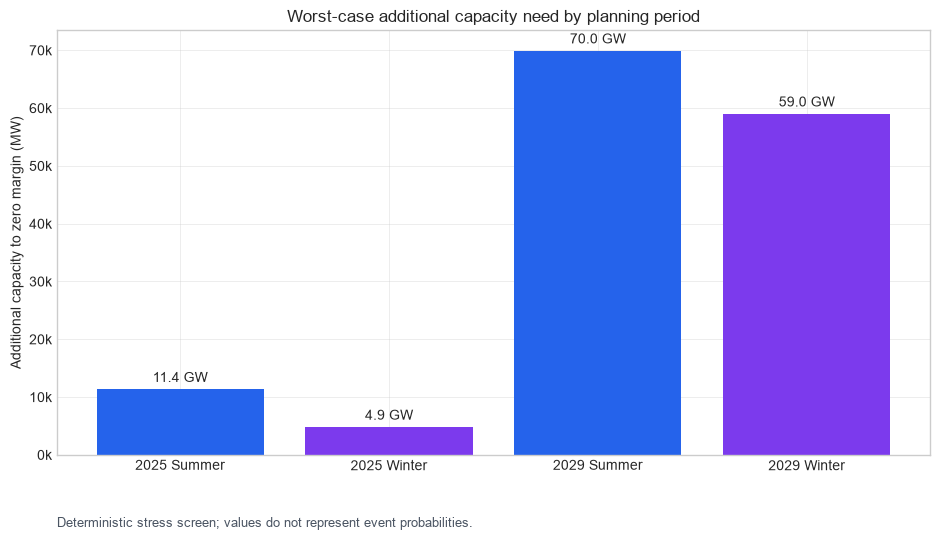

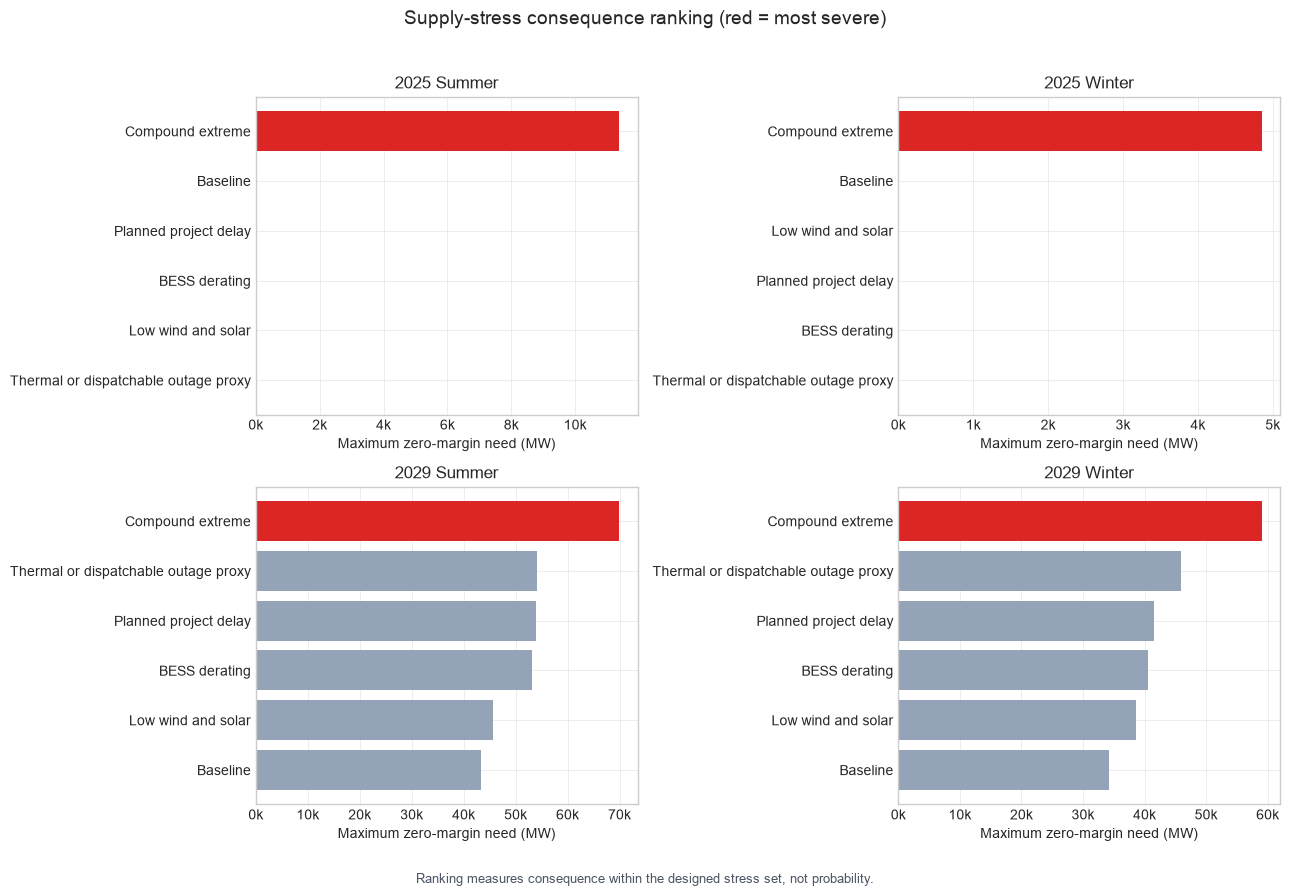

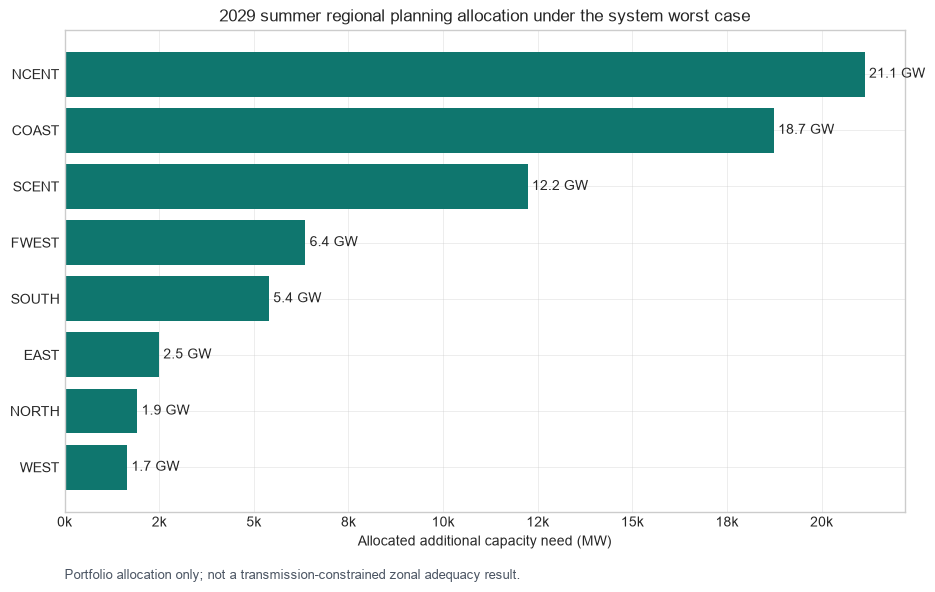

In [ ]:
# 07.18B — Plot the preliminary final charts
import matplotlib.pyplot as plt

from matplotlib.ticker import FuncFormatter

from IPython.display import Image

plt.style.use("seaborn-v0_8-whitegrid")

mw_formatter = FuncFormatter(
    lambda value, position: f"{value / 1000:,.0f}k"
)

worst_plot_df = final_key_metrics_df.copy()

worst_plot_df["scenario_label"] = (
    worst_plot_df["forecast_year"].astype(str)
    + " "
    + worst_plot_df["season"]
)

worst_plot_df["_season_order"] = (
    worst_plot_df["season"].map(season_order)
)

worst_plot_df = (
    worst_plot_df
    .sort_values(
        ["forecast_year", "_season_order"]
    )
    .reset_index(drop=True)
)

figure_1, axis_1 = plt.subplots(
    figsize=(9.5, 5.5)
)

bar_colors_1 = [
    "#2563EB" if season == "Summer" else "#7C3AED"
    for season in worst_plot_df["season"]
]

bars_1 = axis_1.bar(
    worst_plot_df["scenario_label"],
    worst_plot_df["system_worst_case_capacity_need_mw"],
    color=bar_colors_1,
)

axis_1.set_title(
    "Worst-case additional capacity need by planning period"
)

axis_1.set_ylabel(
    "Additional capacity to zero margin (MW)"
)

axis_1.yaxis.set_major_formatter(
    mw_formatter
)

axis_1.bar_label(
    bars_1,
    labels=[
        f"{value / 1000:,.1f} GW"
        for value
        in worst_plot_df[
            "system_worst_case_capacity_need_mw"
        ]
    ],
    padding=3,
)

axis_1.text(
    0.0,
    -0.17,
    "Deterministic stress screen; values do not represent event probabilities.",
    transform=axis_1.transAxes,
    fontsize=9,
    color="#4B5563",
)

figure_1.tight_layout()

FIGURE_1_PATH = (
    CAPACITY_FIGURE_DIR
    / "07_18_system_worst_case_capacity_need.png"
)

figure_1.savefig(
    FIGURE_1_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

plt.close(figure_1)

period_order = [
    (2025, "Summer"),
    (2025, "Winter"),
    (2029, "Summer"),
    (2029, "Winter"),
]

figure_2, axes_2 = plt.subplots(
    2,
    2,
    figsize=(13, 9),
)

for axis_2, (year_value, season_value) in zip(
    axes_2.flatten(),
    period_order,
):

    subset_2 = stress_ranking_df[
        (
            stress_ranking_df["forecast_year"]
            == year_value
        )
        & (
            stress_ranking_df["season"]
            == season_value
        )
    ].copy()

    subset_2 = subset_2.sort_values(
        "maximum_zero_margin_capacity_need_mw",
        ascending=True,
    )

    colors_2 = [
        "#DC2626" if rank == 1 else "#94A3B8"
        for rank
        in subset_2[
            "risk_rank_within_year_season"
        ]
    ]

    axis_2.barh(
        subset_2["stress_scenario"],
        subset_2[
            "maximum_zero_margin_capacity_need_mw"
        ],
        color=colors_2,
    )

    axis_2.set_title(
        f"{year_value} {season_value}"
    )

    axis_2.set_xlabel(
        "Maximum zero-margin need (MW)"
    )

    axis_2.xaxis.set_major_formatter(
        mw_formatter
    )

figure_2.suptitle(
    "Supply-stress consequence ranking (red = most severe)",
    fontsize=14,
)

figure_2.text(
    0.5,
    0.01,
    "Ranking measures consequence within the designed stress set, not probability.",
    ha="center",
    fontsize=9,
    color="#4B5563",
)

figure_2.tight_layout(
    rect=[0, 0.04, 1, 0.96]
)

FIGURE_2_PATH = (
    CAPACITY_FIGURE_DIR
    / "07_18_supply_stress_ranking.png"
)

figure_2.savefig(
    FIGURE_2_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

plt.close(figure_2)

regional_plot_df = regional_priority_df[
    (
        regional_priority_df["forecast_year"]
        == 2029
    )
    & (
        regional_priority_df["season"]
        == "Summer"
    )
].copy()

regional_plot_df = regional_plot_df.sort_values(
    "regional_worst_case_capacity_need_mw",
    ascending=True,
)

figure_3, axis_3 = plt.subplots(
    figsize=(9.5, 6.0)
)

bars_3 = axis_3.barh(
    regional_plot_df["zone"],
    regional_plot_df[
        "regional_worst_case_capacity_need_mw"
    ],
    color="#0F766E",
)

axis_3.set_title(
    "2029 summer regional planning allocation under the system worst case"
)

axis_3.set_xlabel(
    "Allocated additional capacity need (MW)"
)

axis_3.xaxis.set_major_formatter(
    mw_formatter
)

axis_3.bar_label(
    bars_3,
    labels=[
        f"{value / 1000:,.1f} GW"
        for value
        in regional_plot_df[
            "regional_worst_case_capacity_need_mw"
        ]
    ],
    padding=3,
)

axis_3.text(
    0.0,
    -0.14,
    "Portfolio allocation only; not a transmission-constrained zonal adequacy result.",
    transform=axis_3.transAxes,
    fontsize=9,
    color="#4B5563",
)

figure_3.tight_layout()

FIGURE_3_PATH = (
    CAPACITY_FIGURE_DIR
    / "07_18_regional_capacity_priority.png"
)

figure_3.savefig(
    FIGURE_3_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

plt.close(figure_3)

print("Final charts saved under: ", CAPACITY_FIGURE_DIR.relative_to(PROJECT_ROOT))

> **Stage note.** The preliminary charts summarize 2025/2029 endpoint outputs; later sections extend to continuous 2025–2029 results.

In [ ]:
# 07.18C — Audit the preliminary whole-stage outputs
qa_filenames = [
    "07_07_cdr_seasonal_supply_qa.csv",
    "07_08_future_growth_qa.csv",
    "07_09_future_peak_demand_qa.csv",
    "07_10_summer_capacity_adequacy_qa.csv",
    "07_11_target_reserve_margin_qa.csv",
    "07_12_resource_elcc_qa.csv",
    "07_13_ibr_effective_capacity_qa.csv",
    "07_14_seasonal_capacity_adequacy_qa.csv",
    "07_15_supply_stress_qa.csv",
    "07_16_regional_capacity_allocation_qa.csv",
    "07_17_final_tables_qa.csv",
]

qa_registry_rows = []

for qa_filename in qa_filenames:

    qa_source_path = (
        CAPACITY_TABLE_DIR
        / qa_filename
    )

    if not qa_source_path.exists():
        raise FileNotFoundError(
            f"Missing QA file: {qa_source_path}"
        )

    qa_source_df = pd.read_csv(
        qa_source_path
    )

    normalized_pass = (
        qa_source_df["passed"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(
            [
                "true",
                "1",
                "pass",
                "passed",
                "\u901a\u8fc7",
            ]
        )
    )

    qa_registry_rows.append(
        {
            "qa_file": qa_filename,
            "qa_check_count": len(
                qa_source_df
            ),
            "qa_pass_count": int(
                normalized_pass.sum()
            ),
            "all_checks_passed": bool(
                normalized_pass.all()
            ),
            "qa_scope": qa_filename.removesuffix(
                ".csv"
            ),
        }
    )

full_stage_qa_registry_df = pd.DataFrame(
    qa_registry_rows
)

regional_reconciliation_df = (
    regional_priority_df
    .groupby(
        [
            "forecast_year",
            "season",
        ],
        as_index=False,
    )
    .agg(
        regional_capacity_need_sum_mw=(
            "regional_worst_case_capacity_need_mw",
            "sum",
        ),
        system_capacity_need_mw=(
            "system_worst_case_capacity_need_mw",
            "first",
        ),
        region_count=(
            "zone",
            "nunique",
        ),
    )
)

regional_reconciliation_df[
    "absolute_difference_mw"
] = (
    regional_reconciliation_df[
        "regional_capacity_need_sum_mw"
    ]
    - regional_reconciliation_df[
        "system_capacity_need_mw"
    ]
).abs()

expected_periods = {
    (2025, "Summer"),
    (2025, "Winter"),
    (2029, "Summer"),
    (2029, "Winter"),
}

observed_periods = set(
    map(
        tuple,
        worst_case_df[
            [
                "forecast_year",
                "season",
            ]
        ].itertuples(
            index=False,
            name=None,
        ),
    )
)

rank_one_count = int(
    (
        stress_ranking_df[
            "risk_rank_within_year_season"
        ]
        == 1
    ).sum()
)

rank_one_df = stress_ranking_df[
    stress_ranking_df[
        "risk_rank_within_year_season"
    ]
    == 1
].copy()

expected_figure_paths = [
    FIGURE_1_PATH,
    FIGURE_2_PATH,
    FIGURE_3_PATH,
]

figures_complete = all(
    path.exists()
    and path.stat().st_size > 0
    for path in expected_figure_paths
)

final_tables_qa_pass = (
    final_tables_qa_df["passed"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(
        [
            "true",
            "1",
            "pass",
            "passed",
            "\u901a\u8fc7",
        ]
    )
)

final_stage_qa_rows = [

    {
        "check": "All required 07.17 inputs exist",
        "passed": len(missing_07_17_paths) == 0,
        "observed": (
            len(required_07_17_paths)
            - len(missing_07_17_paths)
        ),
        "expected": len(required_07_17_paths),
    },

    {
        "check": "All 07.17 final-table QA checks pass",
        "passed": bool(
            final_tables_qa_pass.all()
        ),
        "observed": int(
            final_tables_qa_pass.sum()
        ),
        "expected": len(
            final_tables_qa_df
        ),
    },

    {
        "check": "All registered 07.07-07.17 QA modules pass",
        "passed": bool(
            full_stage_qa_registry_df[
                "all_checks_passed"
            ].all()
        ),
        "observed": int(
            full_stage_qa_registry_df[
                "all_checks_passed"
            ].sum()
        ),
        "expected": len(
            full_stage_qa_registry_df
        ),
    },

    {
        "check": "Worst-case summary covers four year-season periods",
        "passed": (
            observed_periods
            == expected_periods
            and len(worst_case_df) == 4
        ),
        "observed": len(
            observed_periods
        ),
        "expected": 4,
    },

    {
        "check": "Stress ranking contains 24 rows",
        "passed": len(
            stress_ranking_df
        ) == 24,
        "observed": len(
            stress_ranking_df
        ),
        "expected": 24,
    },

    {
        "check": "Exactly one rank-one stress exists per year-season",
        "passed": rank_one_count == 4,
        "observed": rank_one_count,
        "expected": 4,
    },

    {
        "check": "Compound extreme is rank one in every year-season",
        "passed": bool(
            (
                rank_one_df[
                    "stress_scenario"
                ]
                == "Compound extreme"
            ).all()
        ),
        "observed": int(
            (
                rank_one_df[
                    "stress_scenario"
                ]
                == "Compound extreme"
            ).sum()
        ),
        "expected": 4,
    },

    {
        "check": "Regional priority contains eight zones for four periods",
        "passed": (
            len(regional_priority_df) == 32
            and bool(
                (
                    regional_reconciliation_df[
                        "region_count"
                    ]
                    == 8
                ).all()
            )
        ),
        "observed": len(
            regional_priority_df
        ),
        "expected": 32,
    },

    {
        "check": "Regional capacity needs reconcile to system totals",
        "passed": bool(
            (
                regional_reconciliation_df[
                    "absolute_difference_mw"
                ]
                <= 1e-6
            ).all()
        ),
        "observed": float(
            regional_reconciliation_df[
                "absolute_difference_mw"
            ].max()
        ),
        "expected": "<= 1e-6 MW",
    },

    {
        "check": "Final key metrics contain four rows",
        "passed": len(
            final_key_metrics_df
        ) == 4,
        "observed": len(
            final_key_metrics_df
        ),
        "expected": 4,
    },

    {
        "check": "Final key numeric fields contain no missing values",
        "passed": not final_key_metrics_df[
            [
                "seasonal_projected_peak_demand_mw",
                "official_total_capacity_mw",
                "system_worst_case_capacity_need_mw",
            ]
        ].isna().any().any(),
        "observed": int(
            final_key_metrics_df[
                [
                    "seasonal_projected_peak_demand_mw",
                    "official_total_capacity_mw",
                    "system_worst_case_capacity_need_mw",
                ]
            ].isna().sum().sum()
        ),
        "expected": 0,
    },

    {
        "check": "Methodology summary contains ten modules",
        "passed": len(
            methodology_summary_df
        ) == 10,
        "observed": len(
            methodology_summary_df
        ),
        "expected": 10,
    },

    {
        "check": "Limitations register contains eight items",
        "passed": len(
            limitations_df
        ) == 8,
        "observed": len(
            limitations_df
        ),
        "expected": 8,
    },

    {
        "check": "All three final figures were saved",
        "passed": figures_complete,
        "observed": sum(
            path.exists()
            and path.stat().st_size > 0
            for path in expected_figure_paths
        ),
        "expected": 3,
    },
]

final_stage_qa_df = pd.DataFrame(
    final_stage_qa_rows
)

FULL_STAGE_QA_REGISTRY_PATH = (
    CAPACITY_TABLE_DIR
    / "07_18_full_stage_qa_registry.csv"
)

FINAL_STAGE_QA_PATH = (
    CAPACITY_TABLE_DIR
    / "07_18_final_stage_qa.csv"
)

full_stage_qa_registry_df.to_csv(
    FULL_STAGE_QA_REGISTRY_PATH,
    index=False,
)

final_stage_qa_df.to_csv(
    FINAL_STAGE_QA_PATH,
    index=False,
)

display(full_stage_qa_registry_df)

display(final_stage_qa_df)

if not final_stage_qa_df["passed"].all():

    failed_checks = final_stage_qa_df.loc[
        ~final_stage_qa_df["passed"],
        "check",
    ].tolist()

    raise AssertionError(
        f"07.18 final QA did not fully pass: {failed_checks}"
    )

print(
    "07.18 final QA passed: "
    f"{int(final_stage_qa_df['passed'].sum())}"
    f"/{len(final_stage_qa_df)}"
)

print(
    "Saved full-stage QA registry: ",
    display_project_path(FULL_STAGE_QA_REGISTRY_PATH),
)

print(
    "Saved final QA: ",
    display_project_path(FINAL_STAGE_QA_PATH),
)

print(
    "07.18 complete; awaiting final file audit before closing Stage 07."
)

,qa_file,qa_check_count,qa_pass_count,all_checks_passed,qa_scope
0,07_07_cdr_seasonal_supply_qa.csv,3,3,True,07_07_cdr_seasonal_supply_qa
1,07_08_future_growth_qa.csv,3,3,True,07_08_future_growth_qa
2,07_09_future_peak_demand_qa.csv,4,4,True,07_09_future_peak_demand_qa
3,07_10_summer_capacity_adequacy_qa.csv,8,8,True,07_10_summer_capacity_adequacy_qa
4,07_11_target_reserve_margin_qa.csv,8,8,True,07_11_target_reserve_margin_qa
5,07_12_resource_elcc_qa.csv,6,6,True,07_12_resource_elcc_qa
6,07_13_ibr_effective_capacity_qa.csv,7,7,True,07_13_ibr_effective_capacity_qa
7,07_14_seasonal_capacity_adequacy_qa.csv,12,12,True,07_14_seasonal_capacity_adequacy_qa
8,07_15_supply_stress_qa.csv,16,16,True,07_15_supply_stress_qa
9,07_16_regional_capacity_allocation_qa.csv,12,12,True,07_16_regional_capacity_allocation_qa


,check,passed,observed,expected
0,All required 07.17 inputs exist,True,5.000000e+00,5
1,All 07.17 final-table QA checks pass,True,1.000000e+01,10
2,All registered 07.07-07.17 QA modules pass,True,1.100000e+01,11
3,Worst-case summary covers four year-season per...,True,4.000000e+00,4
4,Stress ranking contains 24 rows,True,2.400000e+01,24
5,Exactly one rank-one stress exists per year-se...,True,4.000000e+00,4
6,Compound extreme is rank one in every year-season,True,4.000000e+00,4
7,Regional priority contains eight zones for fou...,True,3.200000e+01,32
8,Regional capacity needs reconcile to system to...,True,1.455192e-11,<= 1e-6 MW
9,Final key metrics contain four rows,True,4.000000e+00,4


> **Stage note.** The preliminary 07.18 QA checks focus on endpoint-level outputs. Later 07.22 QA integrates the full 2025–2029 analysis.

> **Stage note.** Continue to 07.19 for unit-level annual capacity and to 07.20 for continuous effective capacity.

## 07.19 — Unit-level seasonal capacity across 2025–2029

Read the CDR `Unit Details` tables and reshape their wide 2025–2029 summer and winter capacity fields into a long panel.

**Limitations:** Unit-level seasonal ratings describe the resource mix; they are not equivalent to peak-hour system availability. Missing PUN-resource seasonal values are not automatically treated as zero. The final supply benchmark remains the official total from 07.07, and this extension does not retroactively alter the previously validated 07.12–07.18 outputs.

In [ ]:
# 07.19A — Expand CDR Unit Details into a unit-level seasonal panel

from pathlib import Path

import pandas as pd

from IPython.display import display

PROJECT_ROOT = locate_project_root()

CAPACITY_RAW_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "ercot_capacity"
)

CAPACITY_TABLE_DIR = (
    PROJECT_ROOT
    / "report"
    / "tables"
    / "capacity_adequacy"
)

CAPACITY_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CDR_2024_PATH = (
    CAPACITY_RAW_DIR
    / "CapacityDemandandReservesReport_December2024.xlsx"
)

if not CDR_2024_PATH.exists():

    raise FileNotFoundError(
        f"Missing original CDR file: {CDR_2024_PATH}"
    )

unit_details_raw = pd.read_excel(
    CDR_2024_PATH,
    sheet_name="Unit Details",
    header=8,
    usecols="A:U",
    engine="openpyxl",
)

unit_details_raw = unit_details_raw.loc[
    unit_details_raw["UNIT NAME"].notna()
].copy()

unit_details_raw["source_row_number"] = (
    unit_details_raw.index
    + 10
)

unit_details_raw = unit_details_raw.rename(
    columns={

        "UNIT NAME":
            "unit_name",

        "INTERCONNECTION REQUEST\n NUMBER (INR)":
            "interconnection_request_number",

        "UNIT CODE":
            "unit_code",

        "TECHNOLOGY":
            "technology",

        "FUEL":
            "fuel",

        "CDR STATUS":
            "cdr_status",

        "CDR RESOURCE ATTRIBUTE ":
            "cdr_resource_attribute",

        "COUNTY":
            "county",

        "ZONE":
            "zone",

        "IN-SERVICE\nDATE":
            "in_service_date",

        "INSTALLED CAPACITY\n(MW)":
            "installed_capacity_mw",
    }
)

summer_period_columns = [
    2025,
    2026,
    2027,
    2028,
    2029,
]

winter_period_columns = [
    "2025/26",
    "2026/27",
    "2027/28",
    "2028/29",
    "2029/30",
]

seasonal_period_columns = (
    summer_period_columns
    + winter_period_columns
)

unit_identity_columns = [
    "source_row_number",
    "unit_name",
    "interconnection_request_number",
    "unit_code",
    "technology",
    "fuel",
    "cdr_status",
    "cdr_resource_attribute",
    "county",
    "zone",
    "in_service_date",
    "installed_capacity_mw",
]

unit_seasonal_long = unit_details_raw.melt(
    id_vars=unit_identity_columns,
    value_vars=seasonal_period_columns,
    var_name="planning_period",
    value_name="unit_seasonal_capability_mw",
)

unit_seasonal_long["planning_period"] = (
    unit_seasonal_long["planning_period"]
    .astype(str)
)

unit_seasonal_long["forecast_year"] = (
    unit_seasonal_long["planning_period"]
    .str.extract(
        r"(20\d{2})",
        expand=False,
    )
    .astype(int)
)

unit_seasonal_long["season"] = (
    unit_seasonal_long["planning_period"]
    .str.contains(
        "/",
        regex=False,
    )
    .map(
        {
            False: "Summer",
            True: "Winter",
        }
    )
)

unit_seasonal_long[
    "unit_seasonal_capability_mw"
] = pd.to_numeric(
    unit_seasonal_long[
        "unit_seasonal_capability_mw"
    ],
    errors="coerce",
)

unit_seasonal_long[
    "installed_capacity_mw"
] = pd.to_numeric(
    unit_seasonal_long[
        "installed_capacity_mw"
    ],
    errors="raise",
)

unit_seasonal_long[
    "capability_reported"
] = unit_seasonal_long[
    "unit_seasonal_capability_mw"
].notna()

unit_seasonal_long["source_sheet"] = (
    "Unit Details"
)

unit_seasonal_long["source_vintage"] = (
    "December 2024 Revised"
)

unit_seasonal_long["capacity_basis"] = (
    "Unit seasonal capability; "
    "not official expected available capacity"
)

unit_seasonal_long = (
    unit_seasonal_long.sort_values(
        [
            "forecast_year",
            "season",
            "cdr_status",
            "fuel",
            "unit_name",
            "source_row_number",
        ]
    )
    .reset_index(drop=True)
)

display(
    unit_seasonal_long.head(20)
)

print(
    "Number of Unit Details resources: ",
    len(unit_details_raw),
)

print(
    "Unit-level seasonal long-table shape: ",
    unit_seasonal_long.shape,
)

,source_row_number,unit_name,interconnection_request_number,unit_code,technology,fuel,cdr_status,cdr_resource_attribute,county,zone,in_service_date,installed_capacity_mw,planning_period,unit_seasonal_capability_mw,forecast_year,season,capability_reported,source_sheet,source_vintage,capacity_basis
0,1596,DOW G66,NaN,DOWGEN_DOW_G66,CC,GAS,EXT-OUT,PUN,BRAZORIA,NaN,1983-01-01,105.00,2025,NaN,2025,Summer,False,Unit Details,December 2024 Revised,Unit seasonal capability; not official expecte...
1,1132,CHISHOLM GRID,NaN,CHISMGRD_BES1,BA,STORAGE,EXT-OUT,CONV,TARRANT,NORTH,2021-07-09,101.70,2025,0.0,2025,Summer,True,Unit Details,December 2024 Revised,Unit seasonal capability; not official expecte...
2,1567,BRANDON (LP&L) (DGR) (INDEFINITE MOTHBALL AS O...,NaN,BRANDON_UNIT1,GT,GAS,MOTH-IND,CONV-DGR,LUBBOCK,PANHANDLE,2021-06-03,25.00,2025,20.0,2025,Summer,True,Unit Details,December 2024 Revised,Unit seasonal capability; not official expecte...
3,1602,DOW ST64,NaN,DOWGEN_DOW_ST64,CC,GAS,MOTH-IND,PUN,BRAZORIA,NaN,1982-01-01,50.00,2025,NaN,2025,Summer,False,Unit Details,December 2024 Revised,Unit seasonal capability; not official expecte...
4,1568,R MASSENGALE CTG 1 (LP&L) (INDEFINITE MOTHBALL...,NaN,MASSENGL_G6,CC,GAS,MOTH-IND,CONV,LUBBOCK,PANHANDLE,1988-02-18,20.00,2025,18.0,2025,Summer,True,Unit Details,December 2024 Revised,Unit seasonal capability; not official expecte...
5,1569,R MASSENGALE CTG 2 (LP&L) (INDEFINITE MOTHBALL...,NaN,MASSENGL_G7,CC,GAS,MOTH-IND,CONV,LUBBOCK,PANHANDLE,2021-06-03,20.00,2025,18.0,2025,Summer,True,Unit Details,December 2024 Revised,Unit seasonal capability; not official expecte...
6,1570,R MASSENGALE STG (LP&L) (INDEFINITE MOTHBALL A...,NaN,MASSENGL_G8,CC,GAS,MOTH-IND,CONV,LUBBOCK,PANHANDLE,2021-06-03,58.90,2025,38.0,2025,Summer,True,Unit Details,December 2024 Revised,Unit seasonal capability; not official expecte...
7,1571,RAY OLINGER STG 1 (INDEFINITE MOTHBALL AS OF 4...,NaN,OLINGR_OLING_1,ST,GAS,MOTH-IND,CONV,COLLIN,NORTH,2021-06-03,78.00,2025,78.0,2025,Summer,True,Unit Details,December 2024 Revised,Unit seasonal capability; not official expecte...
8,1573,TY COOKE CTG 1 (LP&L) (INDEFINITE MOTHBALL AS ...,NaN,TY_COOKE_GT2,GT,GAS,MOTH-IND,CONV,LUBBOCK,PANHANDLE,1999-05-27,18.70,2025,14.0,2025,Summer,True,Unit Details,December 2024 Revised,Unit seasonal capability; not official expecte...
9,1574,TY COOKE CTG 2 (LP&L) (INDEFINITE MOTHBALL AS ...,NaN,TY_COOKE_GT3,GT,GAS,MOTH-IND,CONV,LUBBOCK,PANHANDLE,2021-06-03,26.60,2025,17.0,2025,Summer,True,Unit Details,December 2024 Revised,Unit seasonal capability; not official expecte...


In [ ]:
# 07.19B-1 — Aggregate unit-level seasonal capacity

unit_period_summary = (
    unit_seasonal_long.groupby(
        [
            "forecast_year",
            "season",
            "planning_period",
        ],
        as_index=False,
    )
    .agg(

        unit_count=(
            "unit_name",
            "size",
        ),

        reported_unit_count=(
            "capability_reported",
            "sum",
        ),

        total_unit_seasonal_capability_mw=(
            "unit_seasonal_capability_mw",
            "sum",
        ),
    )
)

unit_period_summary["missing_unit_count"] = (
    unit_period_summary["unit_count"]
    - unit_period_summary["reported_unit_count"]
)

raw_period_totals = pd.DataFrame(
    [
        {

            "planning_period": str(
                period_column
            ),

            "raw_wide_total_mw": float(
                pd.to_numeric(
                    unit_details_raw[
                        period_column
                    ],
                    errors="coerce",
                ).sum(
                    skipna=True
                )
            ),
        }
        for period_column
        in seasonal_period_columns
    ]
)

unit_period_summary = (
    unit_period_summary.merge(
        raw_period_totals,
        on="planning_period",
        how="left",
        validate="one_to_one",
    )
)

unit_period_summary[
    "wide_to_long_reconciliation_mw"
] = (
    unit_period_summary[
        "total_unit_seasonal_capability_mw"
    ]
    - unit_period_summary[
        "raw_wide_total_mw"
    ]
)

unit_period_summary["interpretation"] = (
    "Unit capability attribution total; "
    "do not substitute for official available capacity"
)

unit_period_summary = (
    unit_period_summary.sort_values(
        [
            "forecast_year",
            "season",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    unit_period_summary
)

print(
    "Number of year-season combinations: ",
    len(unit_period_summary),
)

print(
    "Maximum reconciliation error (MW): ",
    unit_period_summary[
        "wide_to_long_reconciliation_mw"
    ].abs().max(),
)

,forecast_year,season,planning_period,unit_count,reported_unit_count,total_unit_seasonal_capability_mw,missing_unit_count,raw_wide_total_mw,wide_to_long_reconciliation_mw,interpretation
0,2025,Summer,2025,1631,1572,159993.85,59,159993.85,2.910383e-11,Unit capability attribution total; do not subs...
1,2025,Winter,2025/26,1631,1572,175468.97,59,175468.97,0.000000e+00,Unit capability attribution total; do not subs...
2,2026,Summer,2026,1631,1572,182298.00,59,182298.00,0.000000e+00,Unit capability attribution total; do not subs...
3,2026,Winter,2026/27,1631,1572,193521.67,59,193521.67,2.910383e-11,Unit capability attribution total; do not subs...
4,2027,Summer,2027,1631,1572,193154.40,59,193154.40,2.910383e-11,Unit capability attribution total; do not subs...
5,2027,Winter,2027/28,1631,1572,202370.47,59,202370.47,0.000000e+00,Unit capability attribution total; do not subs...
6,2028,Summer,2028,1631,1572,199198.90,59,199198.90,0.000000e+00,Unit capability attribution total; do not subs...
7,2028,Winter,2028/29,1631,1572,205605.37,59,205605.37,0.000000e+00,Unit capability attribution total; do not subs...
8,2029,Summer,2029,1631,1572,200420.60,59,200420.60,2.910383e-11,Unit capability attribution total; do not subs...
9,2029,Winter,2029/30,1631,1572,206172.37,59,206172.37,0.000000e+00,Unit capability attribution total; do not subs...


In [ ]:
# 07.19B-2 — Reconcile unit-level data and save QA

missing_capability_mask = (
    unit_seasonal_long[
        "unit_seasonal_capability_mw"
    ].isna()
)

clean_resource_attribute = (
    unit_seasonal_long[
        "cdr_resource_attribute"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
)

pun_resource_mask = (
    clean_resource_attribute.eq("PUN")
)

missing_capability_count = int(
    missing_capability_mask.sum()
)

missing_pun_count = int(
    (
        missing_capability_mask
        & pun_resource_mask
    ).sum()
)

missing_outside_pun_count = int(
    (
        missing_capability_mask
        & ~pun_resource_mask
    ).sum()
)

duplicate_unit_period_count = int(
    unit_seasonal_long.duplicated(
        [
            "source_row_number",
            "planning_period",
        ]
    ).sum()
)

observed_years = sorted(
    unit_seasonal_long[
        "forecast_year"
    ]
    .astype(int)
    .unique()
    .tolist()
)

observed_seasons = sorted(
    unit_seasonal_long[
        "season"
    ]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

documented_statuses = {
    "EXT-OUT",
    "MOTH-IND",
    "MOTH-SEA",
    "OPER",
    "OPER-SYN",
    "OPER-UNR",
    "PLAN",
    "PLAN-RPR",
    "RMR",
}

observed_statuses = set(
    unit_seasonal_long[
        "cdr_status"
    ]
    .dropna()
    .astype(str)
    .str.strip()
    .unique()
    .tolist()
)

unexpected_statuses = sorted(
    observed_statuses
    - documented_statuses
)

maximum_reconciliation_error_mw = float(
    unit_period_summary[
        "wide_to_long_reconciliation_mw"
    ].abs().max()
)

unit_seasonal_qa = pd.DataFrame(
    [
        {

            "qa_check": "Unit Details resource count",
            "observed_value": str(len(unit_details_raw)),
            "expected_value": "1631",
            "qa_passed": len(unit_details_raw) == 1631,
        },
        {

            "qa_check": "Planning-period count",
            "observed_value": str(len(unit_period_summary)),
            "expected_value": "10",
            "qa_passed": len(unit_period_summary) == 10,
        },
        {

            "qa_check": "Unit-period row count",
            "observed_value": str(len(unit_seasonal_long)),
            "expected_value": "16310",
            "qa_passed": len(unit_seasonal_long) == 16310,
        },
        {

            "qa_check": "Forecast years",
            "observed_value": str(observed_years),
            "expected_value": "[2025, 2026, 2027, 2028, 2029]",
            "qa_passed": observed_years == [
                2025,
                2026,
                2027,
                2028,
                2029,
            ],
        },
        {

            "qa_check": "Seasons",
            "observed_value": str(observed_seasons),
            "expected_value": "['Summer', 'Winter']",
            "qa_passed": observed_seasons == [
                "Summer",
                "Winter",
            ],
        },
        {

            "qa_check": "Missing capability count",
            "observed_value": str(missing_capability_count),
            "expected_value": "590",
            "qa_passed": missing_capability_count == 590,
        },
        {

            "qa_check": "Missing capability outside PUN",
            "observed_value": str(missing_outside_pun_count),
            "expected_value": "0",
            "qa_passed": missing_outside_pun_count == 0,
        },
        {

            "qa_check": "Missing PUN capability count",
            "observed_value": str(missing_pun_count),
            "expected_value": "590",
            "qa_passed": missing_pun_count == 590,
        },
        {

            "qa_check": "Duplicate unit-period keys",
            "observed_value": str(duplicate_unit_period_count),
            "expected_value": "0",
            "qa_passed": duplicate_unit_period_count == 0,
        },
        {

            "qa_check": "Unexpected CDR statuses",
            "observed_value": str(unexpected_statuses),
            "expected_value": "[]",
            "qa_passed": len(unexpected_statuses) == 0,
        },
        {

            "qa_check": "Maximum reconciliation error MW",
            "observed_value": str(
                maximum_reconciliation_error_mw
            ),
            "expected_value": "<= 0.000001",
            "qa_passed": (
                maximum_reconciliation_error_mw
                <= 0.000001
            ),
        },
    ]
)

unit_seasonal_qa["qa_status"] = (
    unit_seasonal_qa[
        "qa_passed"
    ].map(
        {
            True: "PASS",
            False: "FAIL",
        }
    )
)

unit_long_path = (
    CAPACITY_TABLE_DIR
    / "07_19_cdr_unit_seasonal_capacity_long.csv"
)

unit_summary_path = (
    CAPACITY_TABLE_DIR
    / "07_19_cdr_unit_seasonal_capacity_summary.csv"
)

unit_qa_path = (
    CAPACITY_TABLE_DIR
    / "07_19_cdr_unit_seasonal_capacity_qa.csv"
)

unit_seasonal_qa.to_csv(
    unit_qa_path,
    index=False,
)

all_qa_passed = bool(
    unit_seasonal_qa[
        "qa_passed"
    ].all()
)

assert all_qa_passed, (
    "07.19 has failing QA checks; "
    "see 07_19_cdr_unit_seasonal_capacity_qa.csv."
)

unit_seasonal_long.to_csv(
    unit_long_path,
    index=False,
)

unit_period_summary.to_csv(
    unit_summary_path,
    index=False,
)

display(
    unit_seasonal_qa
)

print(
    "07.19 QA pass count: ",
    f"{int(unit_seasonal_qa['qa_passed'].sum())}"
    f"/{len(unit_seasonal_qa)}",
)

print(
    "Saved unit-level long table: ",
    unit_long_path,
)

print(
    "Saved seasonal summary: ",
    unit_summary_path,
)

print(
    "Saved QA table: ",
    unit_qa_path,
)

,qa_check,observed_value,expected_value,qa_passed,qa_status
0,Unit Details resource count,1631,1631,True,PASS
1,Planning-period count,10,10,True,PASS
2,Unit-period row count,16310,16310,True,PASS
3,Forecast years,"[2025, 2026, 2027, 2028, 2029]","[2025, 2026, 2027, 2028, 2029]",True,PASS
4,Seasons,"['Summer', 'Winter']","['Summer', 'Winter']",True,PASS
5,Missing capability count,590,590,True,PASS
6,Missing capability outside PUN,0,0,True,PASS
7,Missing PUN capability count,590,590,True,PASS
8,Duplicate unit-period keys,0,0,True,PASS
9,Unexpected CDR statuses,[],[],True,PASS


## Transition from unit-level data to reliability-adjusted capacity

**07.19:** What is the planned year-by-year composition of generating resources in 2025–2029?

**07.20:** How much effective capacity can those wind, solar, and storage resources contribute during peak-risk periods, under the selected ELCC assumptions?

> **Stage note.** Section 07.19 establishes annual unit-level resource capacity without replacing the official total supply benchmark.

> **Stage note.** Section 07.20 constructs year-by-year effective IBR contributions using resource type, seasonal risk periods, and ELCC assumptions.

In [ ]:
# 07.20A-1 — Audit continuous-year IBR inputs

from pathlib import Path

import pandas as pd

from IPython.display import display

PROJECT_ROOT = locate_project_root()

CAPACITY_TABLE_DIR = (
    PROJECT_ROOT
    / "report"
    / "tables"
    / "capacity_adequacy"
)

UNIT_SEASONAL_PATH = (
    CAPACITY_TABLE_DIR
    / "07_19_cdr_unit_seasonal_capacity_long.csv"
)

RESOURCE_ENDPOINT_PATH = (
    CAPACITY_TABLE_DIR
    / "07_12_resource_type_installed_capacity.csv"
)

ELCC_LONG_PATH = (
    CAPACITY_TABLE_DIR
    / "07_12_elcc_long.csv"
)

BESS_DURATION_PATH = (
    CAPACITY_TABLE_DIR
    / "07_13_bess_duration_mapping.csv"
)

required_0720_files = {
    "Unit-level seasonal capacity":
        UNIT_SEASONAL_PATH,

    "Official installed-capacity endpoints":
        RESOURCE_ENDPOINT_PATH,

    "Annual ELCC":
        ELCC_LONG_PATH,

    "Storage-duration mapping":
        BESS_DURATION_PATH,
}

missing_0720_files = [
    str(file_path)
    for file_path
    in required_0720_files.values()
    if not file_path.exists()
]

assert not missing_0720_files, (
    "Missing 07.20 input file: "
    f"{missing_0720_files}"
)

unit_seasonal_capacity = pd.read_csv(
    UNIT_SEASONAL_PATH
)

resource_capacity_endpoints = pd.read_csv(
    RESOURCE_ENDPOINT_PATH
)

elcc_long_0720 = pd.read_csv(
    ELCC_LONG_PATH
)

bess_duration_mapping_0720 = pd.read_csv(
    BESS_DURATION_PATH
)

unit_seasonal_capacity[
    "forecast_year"
] = pd.to_numeric(
    unit_seasonal_capacity[
        "forecast_year"
    ],
    errors="raise",
).astype(int)

unit_seasonal_capacity[
    "unit_seasonal_capability_mw"
] = pd.to_numeric(
    unit_seasonal_capacity[
        "unit_seasonal_capability_mw"
    ],
    errors="coerce",
)

elcc_long_0720[
    "forecast_year"
] = pd.to_numeric(
    elcc_long_0720[
        "forecast_year"
    ],
    errors="raise",
).astype(int)

elcc_long_0720[
    "elcc_fraction"
] = pd.to_numeric(
    elcc_long_0720[
        "elcc_fraction"
    ],
    errors="raise",
)

resource_capacity_endpoints[
    "forecast_year"
] = (
    resource_capacity_endpoints[
        "planning_period"
    ]
    .astype(str)
    .str.extract(
        r"(20\d{2})",
        expand=False,
    )
    .astype(int)
)

resource_capacity_endpoints[
    "installed_capacity_mw"
] = pd.to_numeric(
    resource_capacity_endpoints[
        "installed_capacity_mw"
    ],
    errors="raise",
)

bess_duration_mapping_0720[
    "lower_duration_hours"
] = pd.to_numeric(
    bess_duration_mapping_0720[
        "lower_duration_hours"
    ],
    errors="raise",
)

bess_duration_mapping_0720[
    "upper_duration_hours"
] = pd.to_numeric(
    bess_duration_mapping_0720[
        "upper_duration_hours"
    ],
    errors="raise",
)

expected_0720_years = [
    2025,
    2026,
    2027,
    2028,
    2029,
]

unit_capacity_years = sorted(
    unit_seasonal_capacity[
        "forecast_year"
    ].unique().tolist()
)

elcc_years = sorted(
    elcc_long_0720[
        "forecast_year"
    ].unique().tolist()
)

capacity_endpoint_years = sorted(
    resource_capacity_endpoints[
        "forecast_year"
    ].unique().tolist()
)

assert unit_capacity_years == expected_0720_years, (
    "Unit-level capacity year coverage is incomplete: "
    f"{unit_capacity_years}"
)

assert elcc_years == expected_0720_years, (
    "ELCC year coverage is incomplete: "
    f"{elcc_years}"
)

assert capacity_endpoint_years == [
    2025,
    2029,
], (
    "Unexpected official installed-capacity endpoints: "
    f"{capacity_endpoint_years}"
)

assert len(
    bess_duration_mapping_0720
) == 3, (
    "Storage-duration mapping does not contain the expected three groups."
)

input_audit_0720 = pd.DataFrame(
    [
        {

            "input_name": input_name,

            "file_name": file_path.name,

            "file_exists": file_path.exists(),
        }
        for input_name, file_path
        in required_0720_files.items()
    ]
)

display(
    input_audit_0720
)

print(
    "Unit-level seasonal-capacity shape: ",
    unit_seasonal_capacity.shape,
)

print(
    "Annual ELCC shape: ",
    elcc_long_0720.shape,
)

print(
    "Official installed-capacity endpoint shape: ",
    resource_capacity_endpoints.shape,
)

print(
    "Number of storage-duration groups: ",
    len(bess_duration_mapping_0720),
)

print(
    "07.20A-1 input audit: PASS"
)

,input_name,file_name,file_exists
0,Unit-level seasonal capacity,07_19_cdr_unit_seasonal_capacity_long.csv,True
1,Official installed-capacity endpoints,07_12_resource_type_installed_capacity.csv,True
2,Annual ELCC,07_12_elcc_long.csv,True
3,Storage-duration mapping,07_13_bess_duration_mapping.csv,True


In [ ]:
# 07.20A-2 — Classify annual wind, solar, and storage resources
fuel_to_ibr_family = {

    "WIND-C": "Wind",

    "WIND-P": "Wind",

    "WIND-O": "Wind",

    "SOLAR-FW": "Solar",

    "SOLAR-W": "Solar",

    "SOLAR-O": "Solar",

    "STORAGE": "BESS",
}

fuel_to_ibr_label = {

    "WIND-C": "Coastal",

    "WIND-P": "Panhandle",

    "WIND-O": "Other",

    "SOLAR-FW": "Far West",

    "SOLAR-W": "West",

    "SOLAR-O": "Other",

    "STORAGE": (
        "Duration not reported at unit level"
    ),
}

planned_cdr_statuses = {

    "PLAN",

    "PLAN-RPR",
}

ibr_unit_source = (
    unit_seasonal_capacity.loc[
        unit_seasonal_capacity[
            "fuel"
        ].isin(
            fuel_to_ibr_family
        )
    ]
    .copy()
)

ibr_unit_source[
    "resource_status"
] = (
    ibr_unit_source[
        "cdr_status"
    ]
    .isin(
        planned_cdr_statuses
    )
    .map(
        {
            True: "Planned",
            False: "Operational",
        }
    )
)

ibr_unit_source[
    "resource_family_effective"
] = (
    ibr_unit_source[
        "fuel"
    ].map(
        fuel_to_ibr_family
    )
)

ibr_unit_source[
    "resource_label"
] = (
    ibr_unit_source[
        "fuel"
    ].map(
        fuel_to_ibr_label
    )
)

unmapped_family_count = int(
    ibr_unit_source[
        "resource_family_effective"
    ].isna().sum()
)

unmapped_label_count = int(
    ibr_unit_source[
        "resource_label"
    ].isna().sum()
)

assert unmapped_family_count == 0, (
    "Unmapped IBR resource families detected."
)

assert unmapped_label_count == 0, (
    "Unmapped IBR resource labels detected."
)

ibr_unit_annual = (
    ibr_unit_source.groupby(
        [
            "forecast_year",
            "season",
            "planning_period",
            "resource_status",
            "resource_family_effective",
            "resource_label",
        ],
        as_index=False,
    )
    .agg(

        unit_count=(
            "unit_name",
            "size",
        ),

        reported_unit_count=(
            "unit_seasonal_capability_mw",
            "count",
        ),

        raw_unit_seasonal_capability_mw=(
            "unit_seasonal_capability_mw",
            lambda values: values.sum(
                min_count=1
            ),
        ),
    )
)

ibr_unit_annual[
    "missing_unit_count"
] = (
    ibr_unit_annual[
        "unit_count"
    ]
    - ibr_unit_annual[
        "reported_unit_count"
    ]
)

ibr_unit_annual["capacity_basis"] = (
    "Unit Details seasonal capability "
    "before endpoint calibration"
)

ibr_unit_annual = (
    ibr_unit_annual.sort_values(
        [
            "forecast_year",
            "season",
            "resource_status",
            "resource_family_effective",
            "resource_label",
        ]
    )
    .reset_index(
        drop=True
    )
)

ibr_group_count_check = (
    ibr_unit_annual.groupby(
        [
            "forecast_year",
            "season",
        ]
    )
    .size()
)

assert (
    ibr_group_count_check.eq(14).all()
), (
    "Some year-season combinations lack the expected 14 IBR resource categories."
)

assert len(
    ibr_unit_annual
) == 140, (
    "The annual IBR summary should contain 140 rows."
)

display(
    ibr_unit_annual.head(20)
)

print(
    "IBR unit-by-planning-period records: ",
    len(ibr_unit_source),
)

print(
    "Annual IBR resource-category summary rows: ",
    len(ibr_unit_annual),
)

print(
    "Resource families: ",
    sorted(
        ibr_unit_annual[
            "resource_family_effective"
        ].unique().tolist()
    ),
)

print(
    "Resource statuses: ",
    sorted(
        ibr_unit_annual[
            "resource_status"
        ].unique().tolist()
    ),
)

print(
    "07.20A-2 resource-classification audit: PASS"
)

,forecast_year,season,planning_period,resource_status,resource_family_effective,resource_label,unit_count,reported_unit_count,raw_unit_seasonal_capability_mw,missing_unit_count,capacity_basis
0,2025,Summer,2025,Operational,BESS,Duration not reported at unit level,181,181,9066.73,0,Unit Details seasonal capability before endpoi...
1,2025,Summer,2025,Operational,Solar,Far West,45,45,5239.20,0,Unit Details seasonal capability before endpoi...
2,2025,Summer,2025,Operational,Solar,Other,179,176,17860.40,3,Unit Details seasonal capability before endpoi...
3,2025,Summer,2025,Operational,Solar,West,36,36,4349.20,0,Unit Details seasonal capability before endpoi...
4,2025,Summer,2025,Operational,Wind,Coastal,41,41,5430.20,0,Unit Details seasonal capability before endpoi...
5,2025,Summer,2025,Operational,Wind,Other,294,294,29298.90,0,Unit Details seasonal capability before endpoi...
6,2025,Summer,2025,Operational,Wind,Panhandle,39,39,4665.80,0,Unit Details seasonal capability before endpoi...
7,2025,Summer,2025,Planned,BESS,Duration not reported at unit level,136,136,4235.51,0,Unit Details seasonal capability before endpoi...
8,2025,Summer,2025,Planned,Solar,Far West,5,5,146.50,0,Unit Details seasonal capability before endpoi...
9,2025,Summer,2025,Planned,Solar,Other,87,87,4159.90,0,Unit Details seasonal capability before endpoi...


> **Stage note.** Next, compare detailed wind, solar, and storage resource capacities with official 2025/2029 endpoint values.

In [ ]:
# 07.20A-3 — Reconcile resource endpoints and storage-duration shares

endpoint_ibr_detail = (
    resource_capacity_endpoints.loc[

        resource_capacity_endpoints[
            "aggregation_role"
        ].eq(
            "detail"
        )

        & resource_capacity_endpoints[
            "parent_resource"
        ].isin(
            [
                "Wind",
                "Solar",
                "Batteries",
            ]
        )

        & ~(
            resource_capacity_endpoints[
                "parent_resource"
            ].eq(
                "Batteries"
            )
            & resource_capacity_endpoints[
                "resource_label"
            ].eq(
                "Other"
            )
        )
    ]
    .copy()
)

endpoint_ibr_detail[
    "resource_family_effective"
] = (
    endpoint_ibr_detail[
        "parent_resource"
    ].replace(
        {
            "Batteries": "BESS",
        }
    )
)

endpoint_ibr_detail = (
    endpoint_ibr_detail.rename(
        columns={
            "installed_capacity_mw":
                "official_endpoint_installed_capacity_mw",
        }
    )
)

endpoint_ibr_detail = (
    endpoint_ibr_detail[
        [
            "forecast_year",
            "season",
            "planning_period",
            "resource_status",
            "resource_family_effective",
            "resource_label",
            "official_endpoint_installed_capacity_mw",
            "source_sheet",
            "source_row_number",
            "source_vintage",
        ]
    ]
    .sort_values(
        [
            "forecast_year",
            "season",
            "resource_status",
            "resource_family_effective",
            "resource_label",
        ]
    )
    .reset_index(
        drop=True
    )
)

wind_solar_endpoint = (
    endpoint_ibr_detail.loc[
        endpoint_ibr_detail[
            "resource_family_effective"
        ].isin(
            [
                "Wind",
                "Solar",
            ]
        )
    ]
    .copy()
)

bess_duration_endpoint = (
    endpoint_ibr_detail.loc[
        endpoint_ibr_detail[
            "resource_family_effective"
        ].eq(
            "BESS"
        )
    ]
    .copy()
)

bess_endpoint_totals = (
    bess_duration_endpoint.groupby(
        [
            "forecast_year",
            "season",
            "planning_period",
            "resource_status",
        ],
        as_index=False,
    )
    .agg(

        official_bess_endpoint_total_mw=(
            "official_endpoint_installed_capacity_mw",
            "sum",
        )
    )
)

bess_duration_endpoint = (
    bess_duration_endpoint.merge(
        bess_endpoint_totals,
        on=[
            "forecast_year",
            "season",
            "planning_period",
            "resource_status",
        ],
        how="left",
        validate="many_to_one",
    )
)

bess_duration_endpoint[
    "duration_capacity_share"
] = (
    bess_duration_endpoint[
        "official_endpoint_installed_capacity_mw"
    ]
    / bess_duration_endpoint[
        "official_bess_endpoint_total_mw"
    ]
)

bess_duration_endpoint[
    "duration_share_basis"
] = (
    "Official 2025/2029 Capacity by "
    "Resource Type duration mix"
)

assert len(
    endpoint_ibr_detail
) == 72, (
    "The official IBR endpoint detail should contain 72 rows."
)

assert len(
    wind_solar_endpoint
) == 48, (
    "Official wind and solar endpoints should contain 48 rows."
)

assert len(
    bess_duration_endpoint
) == 24, (
    "Official storage-duration endpoints should contain 24 rows."
)

bess_share_check = (
    bess_duration_endpoint.groupby(
        [
            "forecast_year",
            "season",
            "resource_status",
        ]
    )[
        "duration_capacity_share"
    ]
    .sum()
)

maximum_bess_share_error = float(
    (
        bess_share_check
        - 1.0
    ).abs().max()
)

assert (
    maximum_bess_share_error
    <= 0.000001
), (
    "Some storage endpoint duration shares do not sum to 100%."
)

display(
    wind_solar_endpoint.head(12)
)

display(
    bess_duration_endpoint[
        [
            "forecast_year",
            "season",
            "resource_status",
            "resource_label",
            "official_endpoint_installed_capacity_mw",
            "official_bess_endpoint_total_mw",
            "duration_capacity_share",
        ]
    ].head(12)
)

print(
    "Official IBR endpoint detail rows: ",
    len(endpoint_ibr_detail),
)

print(
    "Wind/solar endpoint rows: ",
    len(wind_solar_endpoint),
)

print(
    "Storage-duration endpoint rows: ",
    len(bess_duration_endpoint),
)

print(
    "Maximum storage-duration share discrepancy: ",
    maximum_bess_share_error,
)

print(
    "07.20A-3 official-endpoint audit: PASS"
)

,forecast_year,season,planning_period,resource_status,resource_family_effective,resource_label,official_endpoint_installed_capacity_mw,source_sheet,source_row_number,source_vintage
3,2025,Summer,2025,Operational,Solar,Far West,5262.26,Capacity by Resource Type,15,December 2024 Revised
4,2025,Summer,2025,Operational,Solar,Other,18180.91,Capacity by Resource Type,17,December 2024 Revised
5,2025,Summer,2025,Operational,Solar,West,4374.41,Capacity by Resource Type,16,December 2024 Revised
6,2025,Summer,2025,Operational,Wind,Coastal,5436.37,Capacity by Resource Type,19,December 2024 Revised
7,2025,Summer,2025,Operational,Wind,Other,29441.50,Capacity by Resource Type,21,December 2024 Revised
8,2025,Summer,2025,Operational,Wind,Panhandle,4668.53,Capacity by Resource Type,20,December 2024 Revised
12,2025,Summer,2025,Planned,Solar,Far West,146.50,Capacity by Resource Type,43,December 2024 Revised
13,2025,Summer,2025,Planned,Solar,Other,4159.90,Capacity by Resource Type,45,December 2024 Revised
14,2025,Summer,2025,Planned,Solar,West,870.00,Capacity by Resource Type,44,December 2024 Revised
15,2025,Summer,2025,Planned,Wind,Coastal,241.20,Capacity by Resource Type,47,December 2024 Revised


,forecast_year,season,resource_status,resource_label,official_endpoint_installed_capacity_mw,official_bess_endpoint_total_mw,duration_capacity_share
0,2025,Summer,Operational,Duration 1-hour or less,4268.11,9187.40,0.464561
1,2025,Summer,Operational,Duration 4 hour or more,145.80,9187.40,0.015870
2,2025,Summer,Operational,Duration greater than 1-hour and less than 4-hour,4773.49,9187.40,0.519569
3,2025,Summer,Planned,Duration 1-hour or less,1966.60,4245.46,0.463224
4,2025,Summer,Planned,Duration 4 hour or more,121.50,4245.46,0.028619
5,2025,Summer,Planned,Duration greater than 1-hour and less than 4-hour,2157.36,4245.46,0.508157
6,2025,Winter,Operational,Duration 1-hour or less,4268.11,9187.40,0.464561
7,2025,Winter,Operational,Duration 4 hour or more,145.80,9187.40,0.015870
8,2025,Winter,Operational,Duration greater than 1-hour and less than 4-hour,4773.49,9187.40,0.519569
9,2025,Winter,Planned,Duration 1-hour or less,3378.00,9077.73,0.372119


> **Stage note.** The endpoint reconciliation is an intermediate diagnostic; it does not by itself establish overall adequacy.

In [ ]:
# 07.20B-1A — Compute official wind/solar endpoint adjustments

wind_solar_unit_annual = (
    ibr_unit_annual.loc[
        ibr_unit_annual[
            "resource_family_effective"
        ].isin(
            [
                "Wind",
                "Solar",
            ]
        )
    ]
    .copy()
)

wind_solar_calibration_keys = [

    "season",

    "resource_status",

    "resource_family_effective",

    "resource_label",
]

raw_wind_solar_endpoints = (
    wind_solar_unit_annual.loc[
        wind_solar_unit_annual[
            "forecast_year"
        ].isin(
            [
                2025,
                2029,
            ]
        ),
        [
            "forecast_year",
            *wind_solar_calibration_keys,
            "raw_unit_seasonal_capability_mw",
        ],
    ]
    .copy()
)

wind_solar_endpoint_calibration = (
    raw_wind_solar_endpoints.merge(
        wind_solar_endpoint[
            [
                "forecast_year",
                *wind_solar_calibration_keys,
                "official_endpoint_installed_capacity_mw",
            ]
        ],
        on=[
            "forecast_year",
            *wind_solar_calibration_keys,
        ],
        how="outer",
        validate="one_to_one",
        indicator=True,
    )
)

unmatched_wind_solar_endpoints = int(
    (
        ~wind_solar_endpoint_calibration[
            "_merge"
        ].eq(
            "both"
        )
    ).sum()
)

assert (
    unmatched_wind_solar_endpoints
    == 0
), (
    "Some wind or solar endpoints cannot be reconciled to official capacity."
)

wind_solar_endpoint_calibration = (
    wind_solar_endpoint_calibration.drop(
        columns=[
            "_merge",
        ]
    )
)

wind_solar_endpoint_calibration[
    "endpoint_residual_mw"
] = (
    wind_solar_endpoint_calibration[
        "official_endpoint_installed_capacity_mw"
    ]
    - wind_solar_endpoint_calibration[
        "raw_unit_seasonal_capability_mw"
    ]
)

wind_solar_endpoint_calibration[
    "residual_interpretation"
] = (
    "Official installed-capacity endpoint "
    "minus Unit Details seasonal capability"
)

wind_solar_residual_bridge = (
    wind_solar_endpoint_calibration.pivot(
        index=wind_solar_calibration_keys,
        columns="forecast_year",
        values="endpoint_residual_mw",
    )
    .rename(
        columns={

            2025:
                "endpoint_residual_2025_mw",

            2029:
                "endpoint_residual_2029_mw",
        }
    )
    .reset_index()
)

wind_solar_residual_bridge.columns.name = None

missing_residual_count = int(
    wind_solar_residual_bridge[
        [
            "endpoint_residual_2025_mw",
            "endpoint_residual_2029_mw",
        ]
    ].isna().sum().sum()
)

assert missing_residual_count == 0, (
    "Some wind/solar categories are missing endpoint adjustments."
)

assert len(
    wind_solar_endpoint_calibration
) == 48, (
    "The wind/solar endpoint reconciliation should contain 48 rows."
)

assert len(
    wind_solar_residual_bridge
) == 24, (
    "The wind/solar adjustment bridge should contain 24 resource groups."
)

display(
    wind_solar_endpoint_calibration.head(12)
)

display(
    wind_solar_residual_bridge
)

print(
    "Annual wind/solar capacity rows: ",
    len(wind_solar_unit_annual),
)

print(
    "Wind/solar endpoint reconciliation rows: ",
    len(wind_solar_endpoint_calibration),
)

print(
    "Number of adjustment-bridge resource groups: ",
    len(wind_solar_residual_bridge),
)

print(
    "07.20B-1A endpoint-adjustment audit: PASS"
)

,forecast_year,season,resource_status,resource_family_effective,resource_label,raw_unit_seasonal_capability_mw,official_endpoint_installed_capacity_mw,endpoint_residual_mw,residual_interpretation
0,2025,Summer,Operational,Solar,Far West,5239.20,5262.26,23.06,Official installed-capacity endpoint minus Uni...
1,2025,Summer,Operational,Solar,Other,17860.40,18180.91,320.51,Official installed-capacity endpoint minus Uni...
2,2025,Summer,Operational,Solar,West,4349.20,4374.41,25.21,Official installed-capacity endpoint minus Uni...
3,2025,Summer,Operational,Wind,Coastal,5430.20,5436.37,6.17,Official installed-capacity endpoint minus Uni...
4,2025,Summer,Operational,Wind,Other,29298.90,29441.50,142.60,Official installed-capacity endpoint minus Uni...
5,2025,Summer,Operational,Wind,Panhandle,4665.80,4668.53,2.73,Official installed-capacity endpoint minus Uni...
6,2025,Summer,Planned,Solar,Far West,146.50,146.50,0.00,Official installed-capacity endpoint minus Uni...
7,2025,Summer,Planned,Solar,Other,4159.90,4159.90,0.00,Official installed-capacity endpoint minus Uni...
8,2025,Summer,Planned,Solar,West,870.00,870.00,0.00,Official installed-capacity endpoint minus Uni...
9,2025,Summer,Planned,Wind,Coastal,241.20,241.20,0.00,Official installed-capacity endpoint minus Uni...


,season,resource_status,resource_family_effective,resource_label,endpoint_residual_2025_mw,endpoint_residual_2029_mw
0,Summer,Operational,Solar,Far West,2.306000e+01,2.306000e+01
1,Summer,Operational,Solar,Other,3.205100e+02,3.205100e+02
2,Summer,Operational,Solar,West,2.521000e+01,2.521000e+01
3,Summer,Operational,Wind,Coastal,6.170000e+00,6.170000e+00
4,Summer,Operational,Wind,Other,1.426000e+02,1.426000e+02
5,Summer,Operational,Wind,Panhandle,2.730000e+00,2.730000e+00
6,Summer,Planned,Solar,Far West,0.000000e+00,0.000000e+00
7,Summer,Planned,Solar,Other,0.000000e+00,-3.637979e-12
8,Summer,Planned,Solar,West,0.000000e+00,0.000000e+00
9,Summer,Planned,Wind,Coastal,0.000000e+00,0.000000e+00


In [ ]:
# 07.20B-1A — Reconfirm wind/solar endpoint adjustments

wind_solar_unit_annual = (
    ibr_unit_annual.loc[
        ibr_unit_annual[
            "resource_family_effective"
        ].isin(
            [
                "Wind",
                "Solar",
            ]
        )
    ]
    .copy()
)

wind_solar_calibration_keys = [

    "season",

    "resource_status",

    "resource_family_effective",

    "resource_label",
]

raw_wind_solar_endpoints = (
    wind_solar_unit_annual.loc[
        wind_solar_unit_annual[
            "forecast_year"
        ].isin(
            [
                2025,
                2029,
            ]
        ),
        [
            "forecast_year",
            *wind_solar_calibration_keys,
            "raw_unit_seasonal_capability_mw",
        ],
    ]
    .copy()
)

wind_solar_endpoint_calibration = (
    raw_wind_solar_endpoints.merge(
        wind_solar_endpoint[
            [
                "forecast_year",
                *wind_solar_calibration_keys,
                "official_endpoint_installed_capacity_mw",
            ]
        ],
        on=[
            "forecast_year",
            *wind_solar_calibration_keys,
        ],
        how="outer",
        validate="one_to_one",
        indicator=True,
    )
)

unmatched_wind_solar_endpoints = int(
    (
        wind_solar_endpoint_calibration[
            "_merge"
        ]
        != "both"
    ).sum()
)

assert (
    unmatched_wind_solar_endpoints
    == 0
), (
    "Some wind or solar endpoints cannot be reconciled to official capacity."
)

wind_solar_endpoint_calibration = (
    wind_solar_endpoint_calibration.drop(
        columns=[
            "_merge",
        ]
    )
)

wind_solar_endpoint_calibration[
    "endpoint_residual_mw"
] = (
    wind_solar_endpoint_calibration[
        "official_endpoint_installed_capacity_mw"
    ]
    - wind_solar_endpoint_calibration[
        "raw_unit_seasonal_capability_mw"
    ]
)

wind_solar_endpoint_calibration[
    "residual_interpretation"
] = (
    "Official installed-capacity endpoint "
    "minus Unit Details seasonal capability"
)

wind_solar_residual_bridge = (
    wind_solar_endpoint_calibration.pivot(
        index=wind_solar_calibration_keys,
        columns="forecast_year",
        values="endpoint_residual_mw",
    )
    .rename(
        columns={

            2025:
                "endpoint_residual_2025_mw",

            2029:
                "endpoint_residual_2029_mw",
        }
    )
    .reset_index()
)

wind_solar_residual_bridge.columns.name = None

missing_residual_count = int(
    wind_solar_residual_bridge[
        [
            "endpoint_residual_2025_mw",
            "endpoint_residual_2029_mw",
        ]
    ].isna().sum().sum()
)

assert missing_residual_count == 0, (
    "Some wind/solar categories are missing endpoint adjustments."
)

assert len(
    wind_solar_endpoint_calibration
) == 48, (
    "The wind/solar endpoint reconciliation should contain 48 rows."
)

assert len(
    wind_solar_residual_bridge
) == 24, (
    "The wind/solar adjustment bridge should contain 24 resource groups."
)

display(
    wind_solar_endpoint_calibration.head(12)
)

display(
    wind_solar_residual_bridge
)

print(
    "Annual wind/solar capacity rows: ",
    len(wind_solar_unit_annual),
)

print(
    "Wind/solar endpoint reconciliation rows: ",
    len(wind_solar_endpoint_calibration),
)

print(
    "Number of adjustment-bridge resource groups: ",
    len(wind_solar_residual_bridge),
)

print(
    "07.20B-1A endpoint-adjustment audit: PASS"
)

,forecast_year,season,resource_status,resource_family_effective,resource_label,raw_unit_seasonal_capability_mw,official_endpoint_installed_capacity_mw,endpoint_residual_mw,residual_interpretation
0,2025,Summer,Operational,Solar,Far West,5239.20,5262.26,23.06,Official installed-capacity endpoint minus Uni...
1,2025,Summer,Operational,Solar,Other,17860.40,18180.91,320.51,Official installed-capacity endpoint minus Uni...
2,2025,Summer,Operational,Solar,West,4349.20,4374.41,25.21,Official installed-capacity endpoint minus Uni...
3,2025,Summer,Operational,Wind,Coastal,5430.20,5436.37,6.17,Official installed-capacity endpoint minus Uni...
4,2025,Summer,Operational,Wind,Other,29298.90,29441.50,142.60,Official installed-capacity endpoint minus Uni...
5,2025,Summer,Operational,Wind,Panhandle,4665.80,4668.53,2.73,Official installed-capacity endpoint minus Uni...
6,2025,Summer,Planned,Solar,Far West,146.50,146.50,0.00,Official installed-capacity endpoint minus Uni...
7,2025,Summer,Planned,Solar,Other,4159.90,4159.90,0.00,Official installed-capacity endpoint minus Uni...
8,2025,Summer,Planned,Solar,West,870.00,870.00,0.00,Official installed-capacity endpoint minus Uni...
9,2025,Summer,Planned,Wind,Coastal,241.20,241.20,0.00,Official installed-capacity endpoint minus Uni...


,season,resource_status,resource_family_effective,resource_label,endpoint_residual_2025_mw,endpoint_residual_2029_mw
0,Summer,Operational,Solar,Far West,2.306000e+01,2.306000e+01
1,Summer,Operational,Solar,Other,3.205100e+02,3.205100e+02
2,Summer,Operational,Solar,West,2.521000e+01,2.521000e+01
3,Summer,Operational,Wind,Coastal,6.170000e+00,6.170000e+00
4,Summer,Operational,Wind,Other,1.426000e+02,1.426000e+02
5,Summer,Operational,Wind,Panhandle,2.730000e+00,2.730000e+00
6,Summer,Planned,Solar,Far West,0.000000e+00,0.000000e+00
7,Summer,Planned,Solar,Other,0.000000e+00,-3.637979e-12
8,Summer,Planned,Solar,West,0.000000e+00,0.000000e+00
9,Summer,Planned,Wind,Coastal,0.000000e+00,0.000000e+00


In [ ]:
# 07.20B-1B — Validate continuous-year wind/solar capacities

wind_solar_endpoint_check = (
    wind_solar_continuous.loc[
        wind_solar_continuous[
            "forecast_year"
        ].isin(
            [
                2025,
                2029,
            ]
        )
    ]
    .merge(
        wind_solar_endpoint[
            [
                "forecast_year",
                *wind_solar_calibration_keys,
                "official_endpoint_installed_capacity_mw",
            ]
        ],
        on=[
            "forecast_year",
            *wind_solar_calibration_keys,
        ],
        how="left",
        validate="one_to_one",
    )
)

wind_solar_endpoint_check[
    "endpoint_reconciliation_mw"
] = (
    wind_solar_endpoint_check[
        "calibrated_installed_capacity_mw"
    ]
    - wind_solar_endpoint_check[
        "official_endpoint_installed_capacity_mw"
    ]
)

maximum_wind_solar_endpoint_error_mw = float(
    wind_solar_endpoint_check[
        "endpoint_reconciliation_mw"
    ].abs().max()
)

minimum_wind_solar_capacity_mw = float(
    wind_solar_continuous[
        "calibrated_installed_capacity_mw"
    ].min()
)

assert len(
    wind_solar_continuous
) == 120

assert (
    minimum_wind_solar_capacity_mw
    >= 0.0
)

assert (
    maximum_wind_solar_endpoint_error_mw
    <= 0.000001
)

display(
    wind_solar_endpoint_check[
        [
            "forecast_year",
            "season",
            "resource_status",
            "resource_family_effective",
            "resource_label",
            "calibrated_installed_capacity_mw",
            "official_endpoint_installed_capacity_mw",
            "endpoint_reconciliation_mw",
        ]
    ].head(12)
)

print(
    "Continuous-year wind/solar capacity rows: ",
    len(wind_solar_continuous),
)

print(
    "Minimum calibrated capacity (MW): ",
    minimum_wind_solar_capacity_mw,
)

print(
    "Maximum official-endpoint reconciliation error (MW): ",
    maximum_wind_solar_endpoint_error_mw,
)

print(
    "07.20B-1B continuous-capacity audit: PASS"
)

,forecast_year,season,resource_status,resource_family_effective,resource_label,calibrated_installed_capacity_mw,official_endpoint_installed_capacity_mw,endpoint_reconciliation_mw
0,2025,Summer,Operational,Solar,Far West,5262.26,5262.26,0.0
1,2025,Summer,Operational,Solar,Other,18180.91,18180.91,0.0
2,2025,Summer,Operational,Solar,West,4374.41,4374.41,0.0
3,2025,Summer,Operational,Wind,Coastal,5436.37,5436.37,0.0
4,2025,Summer,Operational,Wind,Other,29441.50,29441.50,0.0
5,2025,Summer,Operational,Wind,Panhandle,4668.53,4668.53,0.0
6,2025,Summer,Planned,Solar,Far West,146.50,146.50,0.0
7,2025,Summer,Planned,Solar,Other,4159.90,4159.90,0.0
8,2025,Summer,Planned,Solar,West,870.00,870.00,0.0
9,2025,Summer,Planned,Wind,Coastal,241.20,241.20,0.0


> **Stage note.** The continuously reconciled 2025–2029 wind/solar capacity baseline is an intermediate input, not the final adequacy result.

In [ ]:
# 07.20B-2A-1 — Reconcile total storage-capacity endpoints

bess_unit_annual = (
    ibr_unit_annual.loc[
        ibr_unit_annual[
            "resource_family_effective"
        ].eq(
            "BESS"
        )
    ]
    .copy()
)

bess_calibration_keys = [

    "season",

    "resource_status",
]

raw_bess_endpoints = (
    bess_unit_annual.loc[
        bess_unit_annual[
            "forecast_year"
        ].isin(
            [
                2025,
                2029,
            ]
        ),
        [
            "forecast_year",
            *bess_calibration_keys,
            "raw_unit_seasonal_capability_mw",
        ],
    ]
    .copy()
)

bess_total_endpoint_calibration = (
    raw_bess_endpoints.merge(
        bess_endpoint_totals[
            [
                "forecast_year",
                *bess_calibration_keys,
                "official_bess_endpoint_total_mw",
            ]
        ],
        on=[
            "forecast_year",
            *bess_calibration_keys,
        ],
        how="outer",
        validate="one_to_one",
        indicator=True,
    )
)

unmatched_bess_endpoints = int(
    (
        bess_total_endpoint_calibration[
            "_merge"
        ]
        != "both"
    ).sum()
)

assert unmatched_bess_endpoints == 0, (
    "Some storage endpoints cannot be reconciled to official total capacity."
)

bess_total_endpoint_calibration = (
    bess_total_endpoint_calibration.drop(
        columns=[
            "_merge",
        ]
    )
)

bess_total_endpoint_calibration[
    "endpoint_residual_mw"
] = (
    bess_total_endpoint_calibration[
        "official_bess_endpoint_total_mw"
    ]
    - bess_total_endpoint_calibration[
        "raw_unit_seasonal_capability_mw"
    ]
)

bess_total_endpoint_calibration[
    "residual_interpretation"
] = (
    "Official BESS installed-capacity endpoint "
    "minus Unit Details seasonal capability"
)

bess_residual_bridge = (
    bess_total_endpoint_calibration.pivot(
        index=bess_calibration_keys,
        columns="forecast_year",
        values="endpoint_residual_mw",
    )
    .rename(
        columns={

            2025:
                "endpoint_residual_2025_mw",

            2029:
                "endpoint_residual_2029_mw",
        }
    )
    .reset_index()
)

bess_residual_bridge.columns.name = None

missing_bess_residual_count = int(
    bess_residual_bridge[
        [
            "endpoint_residual_2025_mw",
            "endpoint_residual_2029_mw",
        ]
    ]
    .isna()
    .sum()
    .sum()
)

assert missing_bess_residual_count == 0, (
    "Some storage resource groups are missing endpoint adjustments."
)

assert len(
    bess_unit_annual
) == 20, (
    "Annual total storage capacity should contain 20 rows."
)

assert len(
    bess_total_endpoint_calibration
) == 8, (
    "The storage endpoint reconciliation should contain 8 rows."
)

assert len(
    bess_residual_bridge
) == 4, (
    "The storage adjustment bridge should contain 4 resource groups."
)

display(
    bess_total_endpoint_calibration
)

display(
    bess_residual_bridge
)

print(
    "Annual total storage capacity rows: ",
    len(bess_unit_annual),
)

print(
    "Storage endpoint reconciliation rows: ",
    len(bess_total_endpoint_calibration),
)

print(
    "Number of storage adjustment-bridge groups: ",
    len(bess_residual_bridge),
)

print(
    "07.20B-2A-1 storage endpoint-adjustment audit: PASS"
)

,forecast_year,season,resource_status,raw_unit_seasonal_capability_mw,official_bess_endpoint_total_mw,endpoint_residual_mw,residual_interpretation
0,2025,Summer,Operational,9066.73,9187.40,120.67,Official BESS installed-capacity endpoint minu...
1,2025,Summer,Planned,4235.51,4245.46,9.95,Official BESS installed-capacity endpoint minu...
2,2025,Winter,Operational,9067.80,9187.40,119.60,Official BESS installed-capacity endpoint minu...
3,2025,Winter,Planned,9016.66,9077.73,61.07,Official BESS installed-capacity endpoint minu...
4,2029,Summer,Operational,9168.43,9289.10,120.67,Official BESS installed-capacity endpoint minu...
5,2029,Summer,Planned,17558.66,17619.73,61.07,Official BESS installed-capacity endpoint minu...
6,2029,Winter,Operational,9169.50,9289.10,119.60,Official BESS installed-capacity endpoint minu...
7,2029,Winter,Planned,17558.66,17619.73,61.07,Official BESS installed-capacity endpoint minu...


,season,resource_status,endpoint_residual_2025_mw,endpoint_residual_2029_mw
0,Summer,Operational,120.67,120.67
1,Summer,Planned,9.95,61.07
2,Winter,Operational,119.60,119.60
3,Winter,Planned,61.07,61.07


In [ ]:
# 07.20B-2A-2 — Interpolate annual storage totals

bess_continuous_total = (
    bess_unit_annual.merge(
        bess_residual_bridge,
        on=bess_calibration_keys,
        how="left",
        validate="many_to_one",
    )
)

missing_bess_bridge_count = int(
    bess_continuous_total[
        [
            "endpoint_residual_2025_mw",
            "endpoint_residual_2029_mw",
        ]
    ]
    .isna()
    .sum()
    .sum()
)

assert missing_bess_bridge_count == 0, (
    "Some annual storage records have no matching endpoint adjustment."
)

bess_continuous_total[
    "endpoint_bridge_weight"
] = (
    bess_continuous_total[
        "forecast_year"
    ]
    - 2025
) / 4.0

assert (
    bess_continuous_total[
        "endpoint_bridge_weight"
    ].between(
        0.0,
        1.0,
        inclusive="both",
    ).all()
), (
    "Some storage endpoint-interpolation weights fall outside [0, 1]."
)

bess_continuous_total[
    "interpolated_endpoint_residual_mw"
] = (

    bess_continuous_total[
        "endpoint_residual_2025_mw"
    ]
    * (
        1.0
        - bess_continuous_total[
            "endpoint_bridge_weight"
        ]
    )

    + bess_continuous_total[
        "endpoint_residual_2029_mw"
    ]
    * bess_continuous_total[
        "endpoint_bridge_weight"
    ]
)

bess_continuous_total[
    "calibrated_bess_total_capacity_mw"
] = (
    bess_continuous_total[
        "raw_unit_seasonal_capability_mw"
    ]
    + bess_continuous_total[
        "interpolated_endpoint_residual_mw"
    ]
)

bess_continuous_total[
    "calibrated_bess_total_capacity_mw"
] = (
    bess_continuous_total[
        "calibrated_bess_total_capacity_mw"
    ].clip(
        lower=0.0
    )
)

bess_continuous_total[
    "calibration_method"
] = (
    "Unit Details annual BESS trajectory plus "
    "linearly bridged endpoint-basis residual"
)

bess_continuous_total[
    "interpolation_scope"
] = (
    "Only endpoint-basis residual is interpolated; "
    "annual BESS trajectory comes from Unit Details"
)

bess_total_endpoint_check = (
    bess_continuous_total.loc[
        bess_continuous_total[
            "forecast_year"
        ].isin(
            [
                2025,
                2029,
            ]
        )
    ]
    .merge(
        bess_endpoint_totals[
            [
                "forecast_year",
                *bess_calibration_keys,
                "official_bess_endpoint_total_mw",
            ]
        ],
        on=[
            "forecast_year",
            *bess_calibration_keys,
        ],
        how="left",
        validate="one_to_one",
    )
)

bess_total_endpoint_check[
    "endpoint_reconciliation_mw"
] = (
    bess_total_endpoint_check[
        "calibrated_bess_total_capacity_mw"
    ]
    - bess_total_endpoint_check[
        "official_bess_endpoint_total_mw"
    ]
)

maximum_bess_endpoint_error_mw = float(
    bess_total_endpoint_check[
        "endpoint_reconciliation_mw"
    ].abs().max()
)

minimum_bess_total_capacity_mw = float(
    bess_continuous_total[
        "calibrated_bess_total_capacity_mw"
    ].min()
)

assert len(
    bess_continuous_total
) == 20, (
    "The continuous-year total storage table should contain 20 rows."
)

assert (
    minimum_bess_total_capacity_mw
    >= 0.0
), (
    "Negative calibrated storage capacity detected."
)

assert (
    maximum_bess_endpoint_error_mw
    <= 0.000001
), (
    "Calibrated storage totals do not reconcile to official endpoints."
)

bess_continuous_total = (
    bess_continuous_total.sort_values(
        [
            "forecast_year",
            "season",
            "resource_status",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    bess_continuous_total[
        [
            "forecast_year",
            "season",
            "resource_status",
            "raw_unit_seasonal_capability_mw",
            "interpolated_endpoint_residual_mw",
            "calibrated_bess_total_capacity_mw",
        ]
    ]
)

print(
    "Continuous-year total storage-capacity rows: ",
    len(bess_continuous_total),
)

print(
    "Minimum calibrated storage capacity (MW): ",
    minimum_bess_total_capacity_mw,
)

print(
    "Maximum storage endpoint reconciliation error (MW): ",
    maximum_bess_endpoint_error_mw,
)

print(
    "07.20B-2A-2 continuous storage-total audit: PASS"
)

,forecast_year,season,resource_status,raw_unit_seasonal_capability_mw,interpolated_endpoint_residual_mw,calibrated_bess_total_capacity_mw
0,2025,Summer,Operational,9066.73,120.67,9187.40
1,2025,Summer,Planned,4235.51,9.95,4245.46
2,2025,Winter,Operational,9067.80,119.60,9187.40
3,2025,Winter,Planned,9016.66,61.07,9077.73
4,2026,Summer,Operational,9168.43,120.67,9289.10
5,2026,Summer,Planned,11672.36,22.73,11695.09
6,2026,Winter,Operational,9169.50,119.60,9289.10
7,2026,Winter,Planned,13434.56,61.07,13495.63
8,2027,Summer,Operational,9168.43,120.67,9289.10
9,2027,Summer,Planned,14911.56,35.51,14947.07


> **Stage note.** The storage detail is grouped by season (Summer/Winter) and status (Operational/Planned).

In [ ]:
# 07.20B-2B-1 — Allocate annual storage across duration classes

bess_duration_share_keys = [

    "season",

    "resource_status",

    "resource_label",
]

bess_duration_share_bridge = (
    bess_duration_endpoint.pivot(
        index=bess_duration_share_keys,
        columns="forecast_year",
        values="duration_capacity_share",
    )
    .rename(
        columns={

            2025:
                "duration_share_2025",

            2029:
                "duration_share_2029",
        }
    )
    .reset_index()
)

bess_duration_share_bridge.columns.name = None

missing_duration_share_count = int(
    bess_duration_share_bridge[
        [
            "duration_share_2025",
            "duration_share_2029",
        ]
    ]
    .isna()
    .sum()
    .sum()
)

assert missing_duration_share_count == 0, (
    "Some storage-duration groups lack a 2025 or 2029 share."
)

assert len(
    bess_duration_share_bridge
) == 12, (
    "The storage-duration share bridge should contain 12 groups."
)

bess_total_for_duration_allocation = (
    bess_continuous_total.drop(
        columns=[
            "resource_label",
        ]
    )
)

bess_continuous_duration = (
    bess_total_for_duration_allocation.merge(
        bess_duration_share_bridge,
        on=[
            "season",
            "resource_status",
        ],
        how="left",
        validate="many_to_many",
    )
)

assert (
    bess_continuous_duration[
        "resource_label"
    ].notna().all()
), (
    "Some annual storage records have no assigned duration group."
)

bess_continuous_duration[
    "interpolated_duration_share"
] = (

    bess_continuous_duration[
        "duration_share_2025"
    ]
    * (
        1.0
        - bess_continuous_duration[
            "endpoint_bridge_weight"
        ]
    )

    + bess_continuous_duration[
        "duration_share_2029"
    ]
    * bess_continuous_duration[
        "endpoint_bridge_weight"
    ]
)

bess_continuous_duration[
    "calibrated_installed_capacity_mw"
] = (
    bess_continuous_duration[
        "calibrated_bess_total_capacity_mw"
    ]
    * bess_continuous_duration[
        "interpolated_duration_share"
    ]
)

bess_continuous_duration[
    "resource_family_effective"
] = "BESS"

bess_continuous_duration[
    "duration_share_method"
] = (
    "Official 2025/2029 duration shares "
    "with linear share bridge for 2026-2028"
)

bess_continuous_duration = (
    bess_continuous_duration.merge(
        bess_duration_mapping_0720[
            [
                "resource_label",
                "lower_duration_hours",
                "upper_duration_hours",
                "mapping_interpretation",
            ]
        ],
        on="resource_label",
        how="left",
        validate="many_to_one",
    )
)

assert (
    bess_continuous_duration[
        "lower_duration_hours"
    ].notna().all()
), (
    "Some storage-duration groups have no lower duration bound."
)

assert (
    bess_continuous_duration[
        "upper_duration_hours"
    ].notna().all()
), (
    "Some storage-duration groups have no upper duration bound."
)

assert len(
    bess_continuous_duration
) == 60, (
    "The continuous-year storage-duration table should contain 60 rows."
)

bess_continuous_duration = (
    bess_continuous_duration.sort_values(
        [
            "forecast_year",
            "season",
            "resource_status",
            "lower_duration_hours",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    bess_continuous_duration[
        [
            "forecast_year",
            "season",
            "resource_status",
            "resource_label",
            "calibrated_bess_total_capacity_mw",
            "interpolated_duration_share",
            "calibrated_installed_capacity_mw",
            "lower_duration_hours",
            "upper_duration_hours",
        ]
    ].head(18)
)

print(
    "Number of storage-duration share-bridge groups: ",
    len(bess_duration_share_bridge),
)

print(
    "Continuous-year storage-duration allocation rows: ",
    len(bess_continuous_duration),
)

print(
    "07.20B-2B-1 storage-duration allocation audit: PASS"
)

,forecast_year,season,resource_status,resource_label,calibrated_bess_total_capacity_mw,interpolated_duration_share,calibrated_installed_capacity_mw,lower_duration_hours,upper_duration_hours
0,2025,Summer,Operational,Duration 1-hour or less,9187.40,0.464561,4268.110000,1.0,1.0
1,2025,Summer,Operational,Duration greater than 1-hour and less than 4-hour,9187.40,0.519569,4773.490000,2.0,3.0
2,2025,Summer,Operational,Duration 4 hour or more,9187.40,0.015870,145.800000,4.0,12.0
3,2025,Summer,Planned,Duration 1-hour or less,4245.46,0.463224,1966.600000,1.0,1.0
4,2025,Summer,Planned,Duration greater than 1-hour and less than 4-hour,4245.46,0.508157,2157.360000,2.0,3.0
5,2025,Summer,Planned,Duration 4 hour or more,4245.46,0.028619,121.500000,4.0,12.0
6,2025,Winter,Operational,Duration 1-hour or less,9187.40,0.464561,4268.110000,1.0,1.0
7,2025,Winter,Operational,Duration greater than 1-hour and less than 4-hour,9187.40,0.519569,4773.490000,2.0,3.0
8,2025,Winter,Operational,Duration 4 hour or more,9187.40,0.015870,145.800000,4.0,12.0
9,2025,Winter,Planned,Duration 1-hour or less,9077.73,0.372119,3378.000000,1.0,1.0


In [ ]:
# 07.20B-2B-2 — Reconcile storage duration shares and totals

bess_duration_allocation_check = (
    bess_continuous_duration.groupby(
        [
            "forecast_year",
            "season",
            "resource_status",
        ],
        as_index=False,
    )
    .agg(

        duration_share_sum=(
            "interpolated_duration_share",
            "sum",
        ),

        allocated_bess_capacity_mw=(
            "calibrated_installed_capacity_mw",
            "sum",
        ),

        calibrated_bess_total_capacity_mw=(
            "calibrated_bess_total_capacity_mw",
            "first",
        ),

        duration_group_count=(
            "resource_label",
            "size",
        ),
    )
)

bess_duration_allocation_check[
    "share_reconciliation"
] = (
    bess_duration_allocation_check[
        "duration_share_sum"
    ]
    - 1.0
)

bess_duration_allocation_check[
    "capacity_reconciliation_mw"
] = (
    bess_duration_allocation_check[
        "allocated_bess_capacity_mw"
    ]
    - bess_duration_allocation_check[
        "calibrated_bess_total_capacity_mw"
    ]
)

bess_duration_endpoint_check = (
    bess_continuous_duration.loc[
        bess_continuous_duration[
            "forecast_year"
        ].isin(
            [
                2025,
                2029,
            ]
        )
    ]
    .merge(
        bess_duration_endpoint[
            [
                "forecast_year",
                "season",
                "resource_status",
                "resource_label",
                "official_endpoint_installed_capacity_mw",
            ]
        ],
        on=[
            "forecast_year",
            "season",
            "resource_status",
            "resource_label",
        ],
        how="left",
        validate="one_to_one",
    )
)

bess_duration_endpoint_check[
    "endpoint_reconciliation_mw"
] = (
    bess_duration_endpoint_check[
        "calibrated_installed_capacity_mw"
    ]
    - bess_duration_endpoint_check[
        "official_endpoint_installed_capacity_mw"
    ]
)

maximum_bess_share_error = float(
    bess_duration_allocation_check[
        "share_reconciliation"
    ].abs().max()
)

maximum_bess_capacity_error_mw = float(
    bess_duration_allocation_check[
        "capacity_reconciliation_mw"
    ].abs().max()
)

maximum_bess_duration_endpoint_error_mw = float(
    bess_duration_endpoint_check[
        "endpoint_reconciliation_mw"
    ].abs().max()
)

minimum_allocated_bess_capacity_mw = float(
    bess_continuous_duration[
        "calibrated_installed_capacity_mw"
    ].min()
)

assert len(
    bess_duration_allocation_check
) == 20, (
    "The storage-duration allocation summary should contain 20 rows."
)

assert (
    bess_duration_allocation_check[
        "duration_group_count"
    ].eq(
        3
    ).all()
), (
    "Some storage combinations lack all three duration groups."
)

assert (
    maximum_bess_share_error
    <= 0.000001
), (
    "Some storage duration shares do not sum to 100%."
)

assert (
    maximum_bess_capacity_error_mw
    <= 0.000001
), (
    "Duration-allocated capacity does not reconcile to total storage capacity."
)

assert (
    maximum_bess_duration_endpoint_error_mw
    <= 0.000001
), (
    "Duration allocations do not reconcile to official endpoints."
)

assert (
    minimum_allocated_bess_capacity_mw
    >= 0.0
), (
    "Negative storage capacity after duration allocation."
)

display(
    bess_duration_allocation_check
)

display(
    bess_duration_endpoint_check[
        [
            "forecast_year",
            "season",
            "resource_status",
            "resource_label",
            "calibrated_installed_capacity_mw",
            "official_endpoint_installed_capacity_mw",
            "endpoint_reconciliation_mw",
        ]
    ].head(12)
)

print(
    "Maximum storage-duration share discrepancy: ",
    maximum_bess_share_error,
)

print(
    "Maximum total-storage reconciliation error (MW): ",
    maximum_bess_capacity_error_mw,
)

print(
    "Maximum duration-endpoint reconciliation error (MW): ",
    maximum_bess_duration_endpoint_error_mw,
)

print(
    "07.20B-2B-2 storage-duration reconciliation: PASS"
)

,forecast_year,season,resource_status,duration_share_sum,allocated_bess_capacity_mw,calibrated_bess_total_capacity_mw,duration_group_count,share_reconciliation,capacity_reconciliation_mw
0,2025,Summer,Operational,1.0,9187.40,9187.40,3,0.000000e+00,0.000000e+00
1,2025,Summer,Planned,1.0,4245.46,4245.46,3,-1.110223e-16,0.000000e+00
2,2025,Winter,Operational,1.0,9187.40,9187.40,3,0.000000e+00,0.000000e+00
3,2025,Winter,Planned,1.0,9077.73,9077.73,3,-1.110223e-16,0.000000e+00
4,2026,Summer,Operational,1.0,9289.10,9289.10,3,0.000000e+00,0.000000e+00
5,2026,Summer,Planned,1.0,11695.09,11695.09,3,0.000000e+00,0.000000e+00
6,2026,Winter,Operational,1.0,9289.10,9289.10,3,0.000000e+00,0.000000e+00
7,2026,Winter,Planned,1.0,13495.63,13495.63,3,0.000000e+00,0.000000e+00
8,2027,Summer,Operational,1.0,9289.10,9289.10,3,0.000000e+00,0.000000e+00
9,2027,Summer,Planned,1.0,14947.07,14947.07,3,0.000000e+00,0.000000e+00


,forecast_year,season,resource_status,resource_label,calibrated_installed_capacity_mw,official_endpoint_installed_capacity_mw,endpoint_reconciliation_mw
0,2025,Summer,Operational,Duration 1-hour or less,4268.11,4268.11,0.0
1,2025,Summer,Operational,Duration greater than 1-hour and less than 4-hour,4773.49,4773.49,0.0
2,2025,Summer,Operational,Duration 4 hour or more,145.80,145.80,0.0
3,2025,Summer,Planned,Duration 1-hour or less,1966.60,1966.60,0.0
4,2025,Summer,Planned,Duration greater than 1-hour and less than 4-hour,2157.36,2157.36,0.0
5,2025,Summer,Planned,Duration 4 hour or more,121.50,121.50,0.0
6,2025,Winter,Operational,Duration 1-hour or less,4268.11,4268.11,0.0
7,2025,Winter,Operational,Duration greater than 1-hour and less than 4-hour,4773.49,4773.49,0.0
8,2025,Winter,Operational,Duration 4 hour or more,145.80,145.80,0.0
9,2025,Winter,Planned,Duration 1-hour or less,3378.00,3378.00,0.0


In [ ]:
# 07.20C-1 — Compute continuous-year wind/solar effective capacity

wind_solar_elcc_type_map = {

    "Wind|Coastal":
        "Wind - Coastal",

    "Wind|Panhandle":
        "Wind - Panhandle",

    "Wind|Other":
        "Wind - Other",

    "Solar|Far West":
        "Solar - FarWest",

    "Solar|West":
        "Solar - West",

    "Solar|Other":
        "Solar - Other",
}

wind_solar_continuous[
    "elcc_mapping_key"
] = (
    wind_solar_continuous[
        "resource_family_effective"
    ]
    + "|"
    + wind_solar_continuous[
        "resource_label"
    ]
)

wind_solar_continuous[
    "elcc_resource_type"
] = (
    wind_solar_continuous[
        "elcc_mapping_key"
    ].map(
        wind_solar_elcc_type_map
    )
)

unmapped_wind_solar_elcc_count = int(
    wind_solar_continuous[
        "elcc_resource_type"
    ].isna().sum()
)

assert (
    unmapped_wind_solar_elcc_count
    == 0
), (
    "Some wind/solar categories lack a matching ELCC resource type."
)

wind_solar_elcc_source = (
    elcc_long_0720.loc[
        elcc_long_0720[
            "resource_family"
        ].isin(
            [
                "Wind",
                "Solar",
            ]
        ),
        [
            "forecast_year",
            "season",
            "risk_period",
            "resource_type",
            "elcc_fraction",
            "source_sheet",
            "source_row_number",
            "source_vintage",
        ],
    ]
    .copy()
)

wind_solar_effective_capacity = (
    wind_solar_continuous.merge(
        wind_solar_elcc_source,
        left_on=[
            "forecast_year",
            "season",
            "elcc_resource_type",
        ],
        right_on=[
            "forecast_year",
            "season",
            "resource_type",
        ],
        how="left",
        validate="many_to_many",
    )
)

wind_solar_effective_capacity[
    "elcc_fraction_lower"
] = (
    wind_solar_effective_capacity[
        "elcc_fraction"
    ]
)

wind_solar_effective_capacity[
    "elcc_fraction_upper"
] = (
    wind_solar_effective_capacity[
        "elcc_fraction"
    ]
)

wind_solar_effective_capacity[
    "effective_capacity_lower_mw"
] = (
    wind_solar_effective_capacity[
        "calibrated_installed_capacity_mw"
    ]
    * wind_solar_effective_capacity[
        "elcc_fraction_lower"
    ]
)

wind_solar_effective_capacity[
    "effective_capacity_upper_mw"
] = (
    wind_solar_effective_capacity[
        "calibrated_installed_capacity_mw"
    ]
    * wind_solar_effective_capacity[
        "elcc_fraction_upper"
    ]
)

wind_solar_effective_capacity[
    "effective_capacity_range_mw"
] = (
    wind_solar_effective_capacity[
        "effective_capacity_upper_mw"
    ]
    - wind_solar_effective_capacity[
        "effective_capacity_lower_mw"
    ]
)

wind_solar_effective_capacity[
    "elcc_mapping_basis"
] = (
    "Exact resource-region match"
)

wind_solar_effective_capacity[
    "calculation_scope"
] = (
    "2025-2029 continuous annual capacity"
)

missing_wind_solar_elcc_count = int(
    wind_solar_effective_capacity[
        "elcc_fraction"
    ].isna().sum()
)

duplicate_wind_solar_effective_keys = int(
    wind_solar_effective_capacity.duplicated(
        [
            "forecast_year",
            "season",
            "risk_period",
            "resource_status",
            "resource_family_effective",
            "resource_label",
        ]
    ).sum()
)

minimum_wind_solar_elcc = float(
    wind_solar_effective_capacity[
        "elcc_fraction"
    ].min()
)

maximum_wind_solar_elcc = float(
    wind_solar_effective_capacity[
        "elcc_fraction"
    ].max()
)

assert len(
    wind_solar_effective_capacity
) == 240, (
    "Wind/solar effective-capacity output should contain 240 rows."
)

assert missing_wind_solar_elcc_count == 0, (
    "Some wind/solar records have no matched ELCC."
)

assert duplicate_wind_solar_effective_keys == 0, (
    "Duplicate keys in wind/solar effective-capacity output."
)

assert (
    wind_solar_effective_capacity[
        "elcc_fraction"
    ].between(
        0.0,
        1.0,
        inclusive="both",
    ).all()
), (
    "Some wind/solar ELCC values fall outside [0, 1]."
)

assert (
    wind_solar_effective_capacity[
        "effective_capacity_range_mw"
    ].abs().max()
    <= 0.000001
), (
    "Exact-region wind/solar mapping should not produce an effective-capacity interval."
)

display(
    wind_solar_effective_capacity[
        [
            "forecast_year",
            "season",
            "risk_period",
            "resource_status",
            "resource_family_effective",
            "resource_label",
            "calibrated_installed_capacity_mw",
            "elcc_resource_type",
            "elcc_fraction",
            "effective_capacity_lower_mw",
            "effective_capacity_upper_mw",
        ]
    ].head(20)
)

print(
    "Wind/solar effective-capacity rows: ",
    len(wind_solar_effective_capacity),
)

print(
    "Unmatched ELCC count: ",
    missing_wind_solar_elcc_count,
)

print(
    "Duplicate effective-capacity keys: ",
    duplicate_wind_solar_effective_keys,
)

print(
    "Wind/solar ELCC range: ",
    minimum_wind_solar_elcc,
    " to ",
    maximum_wind_solar_elcc,
)

print(
    "07.20C-1 wind/solar effective-capacity audit: PASS"
)

,forecast_year,season,risk_period,resource_status,resource_family_effective,resource_label,calibrated_installed_capacity_mw,elcc_resource_type,elcc_fraction,effective_capacity_lower_mw,effective_capacity_upper_mw
0,2025,Summer,Afternoon,Operational,Solar,Far West,5262.26,Solar - FarWest,0.361404,1901.799769,1901.799769
1,2025,Summer,Evening,Operational,Solar,Far West,5262.26,Solar - FarWest,0.073200,385.197432,385.197432
2,2025,Summer,Afternoon,Operational,Solar,Other,18180.91,Solar - Other,0.272099,4947.011871,4947.011871
3,2025,Summer,Evening,Operational,Solar,Other,18180.91,Solar - Other,0.055112,1001.985750,1001.985750
4,2025,Summer,Afternoon,Operational,Solar,West,4374.41,Solar - West,0.361404,1580.927573,1580.927573
5,2025,Summer,Evening,Operational,Solar,West,4374.41,Solar - West,0.073200,320.206812,320.206812
6,2025,Summer,Afternoon,Operational,Wind,Coastal,5436.37,Wind - Coastal,0.308323,1676.157505,1676.157505
7,2025,Summer,Evening,Operational,Wind,Coastal,5436.37,Wind - Coastal,0.163731,890.100879,890.100879
8,2025,Summer,Afternoon,Operational,Wind,Other,29441.50,Wind - Other,0.156774,4615.672588,4615.672588
9,2025,Summer,Evening,Operational,Wind,Other,29441.50,Wind - Other,0.083253,2451.090794,2451.090794


In [ ]:
# 07.20C-2A — Match BESS to lower/upper-duration ELCC

bess_continuous_duration[
    "elcc_resource_type_lower"
] = (
    "BESS - "
    + bess_continuous_duration[
        "lower_duration_hours"
    ]
    .astype(float)
    .map(
        lambda value: (
            f"{value:.1f} hr"
        )
    )
)

bess_continuous_duration[
    "elcc_resource_type_upper"
] = (
    "BESS - "
    + bess_continuous_duration[
        "upper_duration_hours"
    ]
    .astype(float)
    .map(
        lambda value: (
            f"{value:.1f} hr"
        )
    )
)

bess_elcc_source = (
    elcc_long_0720.loc[
        elcc_long_0720[
            "resource_family"
        ].eq(
            "BESS"
        ),
        [
            "forecast_year",
            "season",
            "risk_period",
            "resource_type",
            "elcc_fraction",
            "source_sheet",
            "source_row_number",
            "source_vintage",
        ],
    ]
    .copy()
)

bess_elcc_lower_source = (
    bess_elcc_source.rename(
        columns={

            "resource_type":
                "elcc_resource_type_lower",

            "elcc_fraction":
                "elcc_fraction_lower",

            "source_sheet":
                "elcc_source_sheet_lower",

            "source_row_number":
                "elcc_source_row_lower",

            "source_vintage":
                "elcc_source_vintage_lower",
        }
    )
)

bess_elcc_upper_source = (
    bess_elcc_source.rename(
        columns={

            "resource_type":
                "elcc_resource_type_upper",

            "elcc_fraction":
                "elcc_fraction_upper",

            "source_sheet":
                "elcc_source_sheet_upper",

            "source_row_number":
                "elcc_source_row_upper",

            "source_vintage":
                "elcc_source_vintage_upper",
        }
    )
)

bess_effective_capacity = (
    bess_continuous_duration.merge(
        bess_elcc_lower_source,
        on=[
            "forecast_year",
            "season",
            "elcc_resource_type_lower",
        ],
        how="left",
        validate="many_to_many",
    )
)

bess_effective_capacity = (
    bess_effective_capacity.merge(
        bess_elcc_upper_source,
        on=[
            "forecast_year",
            "season",
            "risk_period",
            "elcc_resource_type_upper",
        ],
        how="left",
        validate="many_to_one",
    )
)

missing_bess_lower_elcc_count = int(
    bess_effective_capacity[
        "elcc_fraction_lower"
    ].isna().sum()
)

missing_bess_upper_elcc_count = int(
    bess_effective_capacity[
        "elcc_fraction_upper"
    ].isna().sum()
)

assert len(
    bess_effective_capacity
) == 120, (
    "Storage ELCC matching output should contain 120 rows."
)

assert (
    missing_bess_lower_elcc_count
    == 0
), (
    "Some storage records lack lower-duration ELCC matches."
)

assert (
    missing_bess_upper_elcc_count
    == 0
), (
    "Some storage records lack upper-duration ELCC matches."
)

display(
    bess_effective_capacity[
        [
            "forecast_year",
            "season",
            "risk_period",
            "resource_status",
            "resource_label",
            "calibrated_installed_capacity_mw",
            "elcc_resource_type_lower",
            "elcc_fraction_lower",
            "elcc_resource_type_upper",
            "elcc_fraction_upper",
        ]
    ].head(18)
)

print(
    "Storage ELCC matching rows: ",
    len(bess_effective_capacity),
)

print(
    "Unmatched lower-duration ELCC: ",
    missing_bess_lower_elcc_count,
)

print(
    "Unmatched upper-duration ELCC: ",
    missing_bess_upper_elcc_count,
)

print(
    "07.20C-2A storage ELCC matching audit: PASS"
)

,forecast_year,season,risk_period,resource_status,resource_label,calibrated_installed_capacity_mw,elcc_resource_type_lower,elcc_fraction_lower,elcc_resource_type_upper,elcc_fraction_upper
0,2025,Summer,Afternoon,Operational,Duration 1-hour or less,4268.11,BESS - 1.0 hr,0.744444,BESS - 1.0 hr,0.744444
1,2025,Summer,Evening,Operational,Duration 1-hour or less,4268.11,BESS - 1.0 hr,0.744444,BESS - 1.0 hr,0.744444
2,2025,Summer,Afternoon,Operational,Duration greater than 1-hour and less than 4-hour,4773.49,BESS - 2.0 hr,0.981955,BESS - 3.0 hr,0.981961
3,2025,Summer,Evening,Operational,Duration greater than 1-hour and less than 4-hour,4773.49,BESS - 2.0 hr,0.981955,BESS - 3.0 hr,0.981961
4,2025,Summer,Afternoon,Operational,Duration 4 hour or more,145.80,BESS - 4.0 hr,0.981961,BESS - 12.0 hr,0.981961
5,2025,Summer,Evening,Operational,Duration 4 hour or more,145.80,BESS - 4.0 hr,0.981961,BESS - 12.0 hr,0.981961
6,2025,Summer,Afternoon,Planned,Duration 1-hour or less,1966.60,BESS - 1.0 hr,0.744444,BESS - 1.0 hr,0.744444
7,2025,Summer,Evening,Planned,Duration 1-hour or less,1966.60,BESS - 1.0 hr,0.744444,BESS - 1.0 hr,0.744444
8,2025,Summer,Afternoon,Planned,Duration greater than 1-hour and less than 4-hour,2157.36,BESS - 2.0 hr,0.981955,BESS - 3.0 hr,0.981961
9,2025,Summer,Evening,Planned,Duration greater than 1-hour and less than 4-hour,2157.36,BESS - 2.0 hr,0.981955,BESS - 3.0 hr,0.981961


In [ ]:
# 07.20C-2B — Compute the BESS effective-capacity interval

bess_effective_capacity[
    "effective_capacity_lower_mw"
] = (
    bess_effective_capacity[
        "calibrated_installed_capacity_mw"
    ]
    * bess_effective_capacity[
        "elcc_fraction_lower"
    ]
)

bess_effective_capacity[
    "effective_capacity_upper_mw"
] = (
    bess_effective_capacity[
        "calibrated_installed_capacity_mw"
    ]
    * bess_effective_capacity[
        "elcc_fraction_upper"
    ]
)

bess_effective_capacity[
    "effective_capacity_range_mw"
] = (
    bess_effective_capacity[
        "effective_capacity_upper_mw"
    ]
    - bess_effective_capacity[
        "effective_capacity_lower_mw"
    ]
)

bess_effective_capacity[
    "elcc_mapping_basis"
] = (
    "Official duration-bin lower and upper bounds"
)

bess_effective_capacity[
    "calculation_scope"
] = (
    "2025-2029 continuous annual capacity"
)

bess_effective_capacity[
    "range_interpretation"
] = (
    "Range reflects missing unit-level duration "
    "within official BESS duration bins"
)

duplicate_bess_effective_keys = int(
    bess_effective_capacity.duplicated(
        [
            "forecast_year",
            "season",
            "risk_period",
            "resource_status",
            "resource_family_effective",
            "resource_label",
        ]
    ).sum()
)

invalid_bess_capacity_range_count = int(
    (
        bess_effective_capacity[
            "effective_capacity_upper_mw"
        ]
        + 0.000001
        < bess_effective_capacity[
            "effective_capacity_lower_mw"
        ]
    ).sum()
)

negative_bess_effective_capacity_count = int(
    (
        bess_effective_capacity[
            [
                "effective_capacity_lower_mw",
                "effective_capacity_upper_mw",
            ]
        ]
        < -0.000001
    )
    .sum()
    .sum()
)

minimum_bess_elcc_lower = float(
    bess_effective_capacity[
        "elcc_fraction_lower"
    ].min()
)

maximum_bess_elcc_lower = float(
    bess_effective_capacity[
        "elcc_fraction_lower"
    ].max()
)

minimum_bess_elcc_upper = float(
    bess_effective_capacity[
        "elcc_fraction_upper"
    ].min()
)

maximum_bess_elcc_upper = float(
    bess_effective_capacity[
        "elcc_fraction_upper"
    ].max()
)

assert len(
    bess_effective_capacity
) == 120, (
    "Storage effective-capacity output should contain 120 rows."
)

assert duplicate_bess_effective_keys == 0, (
    "Duplicate keys in storage effective-capacity output."
)

assert (
    bess_effective_capacity[
        "elcc_fraction_lower"
    ].between(
        0.0,
        1.0,
        inclusive="both",
    ).all()
), (
    "Some storage lower-bound ELCC values fall outside [0, 1]."
)

assert (
    bess_effective_capacity[
        "elcc_fraction_upper"
    ].between(
        0.0,
        1.0,
        inclusive="both",
    ).all()
), (
    "Some storage upper-bound ELCC values fall outside [0, 1]."
)

assert (
    invalid_bess_capacity_range_count
    == 0
), (
    "Some storage effective-capacity upper bounds are below lower bounds."
)

assert (
    negative_bess_effective_capacity_count
    == 0
), (
    "Negative storage effective-capacity values detected."
)

bess_effective_capacity = (
    bess_effective_capacity.sort_values(
        [
            "forecast_year",
            "season",
            "risk_period",
            "resource_status",
            "lower_duration_hours",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    bess_effective_capacity[
        [
            "forecast_year",
            "season",
            "risk_period",
            "resource_status",
            "resource_label",
            "calibrated_installed_capacity_mw",
            "elcc_fraction_lower",
            "elcc_fraction_upper",
            "effective_capacity_lower_mw",
            "effective_capacity_upper_mw",
            "effective_capacity_range_mw",
        ]
    ].head(18)
)

print(
    "Storage effective-capacity rows: ",
    len(bess_effective_capacity),
)

print(
    "Duplicate storage effective-capacity keys: ",
    duplicate_bess_effective_keys,
)

print(
    "Number of upper-below-lower cases: ",
    invalid_bess_capacity_range_count,
)

print(
    "Storage lower-bound ELCC range: ",
    minimum_bess_elcc_lower,
    " to ",
    maximum_bess_elcc_lower,
)

print(
    "Storage upper-bound ELCC range: ",
    minimum_bess_elcc_upper,
    " to ",
    maximum_bess_elcc_upper,
)

print(
    "07.20C-2B storage effective-capacity audit: PASS"
)

,forecast_year,season,risk_period,resource_status,resource_label,calibrated_installed_capacity_mw,elcc_fraction_lower,elcc_fraction_upper,effective_capacity_lower_mw,effective_capacity_upper_mw,effective_capacity_range_mw
0,2025,Summer,Afternoon,Operational,Duration 1-hour or less,4268.11,0.744444,0.744444,3177.369415,3177.369415,0.000000
1,2025,Summer,Afternoon,Operational,Duration greater than 1-hour and less than 4-hour,4773.49,0.981955,0.981961,4687.350066,4687.381549,0.031484
2,2025,Summer,Afternoon,Operational,Duration 4 hour or more,145.80,0.981961,0.981961,143.169930,143.169930,0.000000
3,2025,Summer,Afternoon,Planned,Duration 1-hour or less,1966.60,0.744444,0.744444,1464.023816,1464.023816,0.000000
4,2025,Summer,Afternoon,Planned,Duration greater than 1-hour and less than 4-hour,2157.36,0.981955,0.981961,2118.429396,2118.443625,0.014229
5,2025,Summer,Afternoon,Planned,Duration 4 hour or more,121.50,0.981961,0.981961,119.308275,119.308275,0.000000
6,2025,Summer,Evening,Operational,Duration 1-hour or less,4268.11,0.744444,0.744444,3177.369415,3177.369415,0.000000
7,2025,Summer,Evening,Operational,Duration greater than 1-hour and less than 4-hour,4773.49,0.981955,0.981961,4687.350066,4687.381549,0.031484
8,2025,Summer,Evening,Operational,Duration 4 hour or more,145.80,0.981961,0.981961,143.169930,143.169930,0.000000
9,2025,Summer,Evening,Planned,Duration 1-hour or less,1966.60,0.744444,0.744444,1464.023816,1464.023816,0.000000


In [ ]:
# 07.20C-3A — Combine continuous-year IBR resource details

wind_solar_effective_capacity[
    "elcc_resource_type_lower"
] = (
    wind_solar_effective_capacity[
        "elcc_resource_type"
    ]
)

wind_solar_effective_capacity[
    "elcc_resource_type_upper"
] = (
    wind_solar_effective_capacity[
        "elcc_resource_type"
    ]
)

wind_solar_effective_capacity[
    "lower_duration_hours"
] = pd.NA

wind_solar_effective_capacity[
    "upper_duration_hours"
] = pd.NA

wind_solar_effective_capacity[
    "mapping_interpretation"
] = (
    "Exact regional ELCC match"
)

bess_effective_capacity[
    "source_vintage"
] = (
    bess_effective_capacity[
        "elcc_source_vintage_lower"
    ]
)

continuous_ibr_detail_columns = [

    "forecast_year",

    "season",

    "planning_period",

    "risk_period",

    "resource_status",

    "resource_family_effective",

    "resource_label",

    "raw_unit_seasonal_capability_mw",

    "interpolated_endpoint_residual_mw",

    "calibrated_installed_capacity_mw",

    "lower_duration_hours",

    "upper_duration_hours",

    "elcc_resource_type_lower",

    "elcc_resource_type_upper",

    "elcc_fraction_lower",

    "elcc_fraction_upper",

    "effective_capacity_lower_mw",

    "effective_capacity_upper_mw",

    "effective_capacity_range_mw",

    "calibration_method",

    "elcc_mapping_basis",

    "mapping_interpretation",

    "calculation_scope",

    "source_vintage",
]

continuous_ibr_effective_detail = (
    pd.concat(
        [

            wind_solar_effective_capacity[
                continuous_ibr_detail_columns
            ],

            bess_effective_capacity[
                continuous_ibr_detail_columns
            ],
        ],
        ignore_index=True,
    )
)

continuous_ibr_effective_detail = (
    continuous_ibr_effective_detail.sort_values(
        [
            "forecast_year",
            "season",
            "risk_period",
            "resource_status",
            "resource_family_effective",
            "resource_label",
        ]
    )
    .reset_index(
        drop=True
    )
)

duplicate_continuous_ibr_keys = int(
    continuous_ibr_effective_detail.duplicated(
        [
            "forecast_year",
            "season",
            "risk_period",
            "resource_status",
            "resource_family_effective",
            "resource_label",
        ]
    ).sum()
)

assert len(
    continuous_ibr_effective_detail
) == 360, (
    "Continuous-year IBR effective-capacity detail should contain 360 rows."
)

assert duplicate_continuous_ibr_keys == 0, (
    "Duplicate keys in continuous-year IBR effective-capacity detail."
)

assert (
    continuous_ibr_effective_detail[
        [
            "effective_capacity_lower_mw",
            "effective_capacity_upper_mw",
        ]
    ].notna().all().all()
), (
    "Missing values in continuous-year IBR effective capacity."
)

display(
    continuous_ibr_effective_detail.head(20)
)

print(
    "Continuous-year IBR effective-capacity rows: ",
    len(continuous_ibr_effective_detail),
)

print(
    "Resource families: ",
    sorted(
        continuous_ibr_effective_detail[
            "resource_family_effective"
        ].unique().tolist()
    ),
)

print(
    "Duplicate final-detail keys: ",
    duplicate_continuous_ibr_keys,
)

print(
    "07.20C-3A detail-integration audit: PASS"
)

,forecast_year,season,planning_period,risk_period,resource_status,resource_family_effective,resource_label,raw_unit_seasonal_capability_mw,interpolated_endpoint_residual_mw,calibrated_installed_capacity_mw,...,elcc_fraction_lower,elcc_fraction_upper,effective_capacity_lower_mw,effective_capacity_upper_mw,effective_capacity_range_mw,calibration_method,elcc_mapping_basis,mapping_interpretation,calculation_scope,source_vintage
0,2025,Summer,2025,Afternoon,Operational,BESS,Duration 1-hour or less,9066.73,120.67,4268.11,...,0.744444,0.744444,3177.369415,3177.369415,0.000000,Unit Details annual BESS trajectory plus linea...,Official duration-bin lower and upper bounds,Exact conservative mapping to 1-hour ELCC,2025-2029 continuous annual capacity,December 2024 Revised
1,2025,Summer,2025,Afternoon,Operational,BESS,Duration 4 hour or more,9066.73,120.67,145.80,...,0.981961,0.981961,143.169930,143.169930,0.000000,Unit Details annual BESS trajectory plus linea...,Official duration-bin lower and upper bounds,Official capacity bin is open-ended; use 4-12 ...,2025-2029 continuous annual capacity,December 2024 Revised
2,2025,Summer,2025,Afternoon,Operational,BESS,Duration greater than 1-hour and less than 4-hour,9066.73,120.67,4773.49,...,0.981955,0.981961,4687.350066,4687.381549,0.031484,Unit Details annual BESS trajectory plus linea...,Official duration-bin lower and upper bounds,Official capacity bin spans 2-3 hours; report ...,2025-2029 continuous annual capacity,December 2024 Revised
3,2025,Summer,2025,Afternoon,Operational,Solar,Far West,5239.20,23.06,5262.26,...,0.361404,0.361404,1901.799769,1901.799769,0.000000,Unit Details annual trajectory plus linearly b...,Exact resource-region match,Exact regional ELCC match,2025-2029 continuous annual capacity,December 2024 Revised
4,2025,Summer,2025,Afternoon,Operational,Solar,Other,17860.40,320.51,18180.91,...,0.272099,0.272099,4947.011871,4947.011871,0.000000,Unit Details annual trajectory plus linearly b...,Exact resource-region match,Exact regional ELCC match,2025-2029 continuous annual capacity,December 2024 Revised
5,2025,Summer,2025,Afternoon,Operational,Solar,West,4349.20,25.21,4374.41,...,0.361404,0.361404,1580.927573,1580.927573,0.000000,Unit Details annual trajectory plus linearly b...,Exact resource-region match,Exact regional ELCC match,2025-2029 continuous annual capacity,December 2024 Revised
6,2025,Summer,2025,Afternoon,Operational,Wind,Coastal,5430.20,6.17,5436.37,...,0.308323,0.308323,1676.157505,1676.157505,0.000000,Unit Details annual trajectory plus linearly b...,Exact resource-region match,Exact regional ELCC match,2025-2029 continuous annual capacity,December 2024 Revised
7,2025,Summer,2025,Afternoon,Operational,Wind,Other,29298.90,142.60,29441.50,...,0.156774,0.156774,4615.672588,4615.672588,0.000000,Unit Details annual trajectory plus linearly b...,Exact resource-region match,Exact regional ELCC match,2025-2029 continuous annual capacity,December 2024 Revised
8,2025,Summer,2025,Afternoon,Operational,Wind,Panhandle,4665.80,2.73,4668.53,...,0.335758,0.335758,1567.498352,1567.498352,0.000000,Unit Details annual trajectory plus linearly b...,Exact resource-region match,Exact regional ELCC match,2025-2029 continuous annual capacity,December 2024 Revised
9,2025,Summer,2025,Afternoon,Planned,BESS,Duration 1-hour or less,4235.51,9.95,1966.60,...,0.744444,0.744444,1464.023816,1464.023816,0.000000,Unit Details annual BESS trajectory plus linea...,Official duration-bin lower and upper bounds,Exact conservative mapping to 1-hour ELCC,2025-2029 continuous annual capacity,December 2024 Revised


In [ ]:
# 07.20C-3B — Summarize IBR contributions and reconcile endpoints

continuous_ibr_summary_base = (
    continuous_ibr_effective_detail.groupby(
        [
            "forecast_year",
            "season",
            "planning_period",
            "risk_period",
            "resource_status",
            "resource_family_effective",
        ],
        as_index=False,
    )
    .agg(

        installed_capacity_mw=(
            "calibrated_installed_capacity_mw",
            "sum",
        ),

        effective_capacity_lower_mw=(
            "effective_capacity_lower_mw",
            "sum",
        ),

        effective_capacity_upper_mw=(
            "effective_capacity_upper_mw",
            "sum",
        ),
    )
)

continuous_ibr_summary_combined = (
    continuous_ibr_effective_detail.groupby(
        [
            "forecast_year",
            "season",
            "planning_period",
            "risk_period",
            "resource_family_effective",
        ],
        as_index=False,
    )
    .agg(

        installed_capacity_mw=(
            "calibrated_installed_capacity_mw",
            "sum",
        ),

        effective_capacity_lower_mw=(
            "effective_capacity_lower_mw",
            "sum",
        ),

        effective_capacity_upper_mw=(
            "effective_capacity_upper_mw",
            "sum",
        ),
    )
)

continuous_ibr_summary_combined[
    "resource_status"
] = (
    "Operational + Planned"
)

continuous_ibr_effective_summary = (
    pd.concat(
        [
            continuous_ibr_summary_base,
            continuous_ibr_summary_combined,
        ],
        ignore_index=True,
    )
)

continuous_ibr_effective_summary[
    "effective_capacity_range_mw"
] = (
    continuous_ibr_effective_summary[
        "effective_capacity_upper_mw"
    ]
    - continuous_ibr_effective_summary[
        "effective_capacity_lower_mw"
    ]
)

continuous_ibr_effective_summary[
    "capacity_credit_lower"
] = (
    continuous_ibr_effective_summary[
        "effective_capacity_lower_mw"
    ]
    / continuous_ibr_effective_summary[
        "installed_capacity_mw"
    ]
)

continuous_ibr_effective_summary[
    "capacity_credit_upper"
] = (
    continuous_ibr_effective_summary[
        "effective_capacity_upper_mw"
    ]
    / continuous_ibr_effective_summary[
        "installed_capacity_mw"
    ]
)

continuous_ibr_effective_summary = (
    continuous_ibr_effective_summary.sort_values(
        [
            "forecast_year",
            "season",
            "risk_period",
            "resource_status",
            "resource_family_effective",
        ]
    )
    .reset_index(
        drop=True
    )
)

wind_solar_endpoint_reconciliation = (
    wind_solar_endpoint_check[
        [
            "forecast_year",
            "season",
            "resource_status",
            "resource_family_effective",
            "resource_label",
            "calibrated_installed_capacity_mw",
            "official_endpoint_installed_capacity_mw",
            "endpoint_reconciliation_mw",
        ]
    ]
    .copy()
)

bess_endpoint_reconciliation = (
    bess_duration_endpoint_check[
        [
            "forecast_year",
            "season",
            "resource_status",
            "resource_family_effective",
            "resource_label",
            "calibrated_installed_capacity_mw",
            "official_endpoint_installed_capacity_mw",
            "endpoint_reconciliation_mw",
        ]
    ]
    .copy()
)

continuous_capacity_endpoint_reconciliation = (
    pd.concat(
        [
            wind_solar_endpoint_reconciliation,
            bess_endpoint_reconciliation,
        ],
        ignore_index=True,
    )
)

continuous_capacity_endpoint_reconciliation = (
    continuous_capacity_endpoint_reconciliation.sort_values(
        [
            "forecast_year",
            "season",
            "resource_status",
            "resource_family_effective",
            "resource_label",
        ]
    )
    .reset_index(
        drop=True
    )
)

maximum_continuous_endpoint_error_mw = float(
    continuous_capacity_endpoint_reconciliation[
        "endpoint_reconciliation_mw"
    ].abs().max()
)

assert len(
    continuous_ibr_summary_base
) == 120, (
    "Status-specific effective-capacity summary should contain 120 rows."
)

assert len(
    continuous_ibr_summary_combined
) == 60, (
    "Combined-status effective-capacity summary should contain 60 rows."
)

assert len(
    continuous_ibr_effective_summary
) == 180, (
    "Continuous-year effective-capacity summary should contain 180 rows."
)

assert len(
    continuous_capacity_endpoint_reconciliation
) == 72, (
    "Continuous capacity official-endpoint reconciliation should contain 72 rows."
)

assert (
    maximum_continuous_endpoint_error_mw
    <= 0.000001
), (
    "Continuous capacity does not reconcile to the 2025 and 2029 official endpoints."
)

assert (
    continuous_ibr_effective_summary[
        [
            "capacity_credit_lower",
            "capacity_credit_upper",
        ]
    ].notna().all().all()
), (
    "Missing capacity-credit values in continuous effective-capacity summaries."
)

display(
    continuous_ibr_effective_summary.head(18)
)

display(
    continuous_capacity_endpoint_reconciliation.head(18)
)

print(
    "Status-specific effective-capacity rows: ",
    len(continuous_ibr_summary_base),
)

print(
    "Combined-status effective-capacity rows: ",
    len(continuous_ibr_summary_combined),
)

print(
    "Continuous-year effective-capacity rows: ",
    len(continuous_ibr_effective_summary),
)

print(
    "Official endpoint-reconciliation rows: ",
    len(continuous_capacity_endpoint_reconciliation),
)

print(
    "Maximum official-endpoint reconciliation error (MW): ",
    maximum_continuous_endpoint_error_mw,
)

print(
    "07.20C-3B summary and endpoint reconciliation: PASS"
)

,forecast_year,season,planning_period,risk_period,resource_status,resource_family_effective,installed_capacity_mw,effective_capacity_lower_mw,effective_capacity_upper_mw,effective_capacity_range_mw,capacity_credit_lower,capacity_credit_upper
0,2025,Summer,2025,Afternoon,Operational,BESS,9187.40,8007.889411,8007.920894,0.031484,0.871616,0.871620
1,2025,Summer,2025,Afternoon,Operational,Solar,27817.58,8429.739213,8429.739213,0.000000,0.303036,0.303036
2,2025,Summer,2025,Afternoon,Operational,Wind,39546.40,7859.328445,7859.328445,0.000000,0.198737,0.198737
3,2025,Summer,2025,Afternoon,Operational + Planned,BESS,13432.86,11709.650898,11709.696611,0.045713,0.871717,0.871720
4,2025,Summer,2025,Afternoon,Operational + Planned,Solar,32993.98,9929.011630,9929.011630,0.000000,0.300934,0.300934
5,2025,Summer,2025,Afternoon,Operational + Planned,Wind,39787.91,7933.744535,7933.744535,0.000000,0.199401,0.199401
6,2025,Summer,2025,Afternoon,Planned,BESS,4245.46,3701.761488,3701.775717,0.014229,0.871934,0.871937
7,2025,Summer,2025,Afternoon,Planned,Solar,5176.40,1499.272417,1499.272417,0.000000,0.289636,0.289636
8,2025,Summer,2025,Afternoon,Planned,Wind,241.51,74.416090,74.416090,0.000000,0.308128,0.308128
9,2025,Summer,2025,Evening,Operational,BESS,9187.40,8007.889411,8007.920894,0.031484,0.871616,0.871620


,forecast_year,season,resource_status,resource_family_effective,resource_label,calibrated_installed_capacity_mw,official_endpoint_installed_capacity_mw,endpoint_reconciliation_mw
0,2025,Summer,Operational,BESS,Duration 1-hour or less,4268.11,4268.11,0.0
1,2025,Summer,Operational,BESS,Duration 4 hour or more,145.80,145.80,0.0
2,2025,Summer,Operational,BESS,Duration greater than 1-hour and less than 4-hour,4773.49,4773.49,0.0
3,2025,Summer,Operational,Solar,Far West,5262.26,5262.26,0.0
4,2025,Summer,Operational,Solar,Other,18180.91,18180.91,0.0
5,2025,Summer,Operational,Solar,West,4374.41,4374.41,0.0
6,2025,Summer,Operational,Wind,Coastal,5436.37,5436.37,0.0
7,2025,Summer,Operational,Wind,Other,29441.50,29441.50,0.0
8,2025,Summer,Operational,Wind,Panhandle,4668.53,4668.53,0.0
9,2025,Summer,Planned,BESS,Duration 1-hour or less,1966.60,1966.60,0.0


In [ ]:
# 07.20C-3C-1 — Run final continuous-year IBR QA

observed_0720_years = sorted(
    continuous_ibr_effective_detail[
        "forecast_year"
    ]
    .astype(int)
    .unique()
    .tolist()
)

observed_0720_seasons = sorted(
    continuous_ibr_effective_detail[
        "season"
    ]
    .astype(str)
    .unique()
    .tolist()
)

risk_period_count_by_year_season = (
    continuous_ibr_effective_detail.groupby(
        [
            "forecast_year",
            "season",
        ]
    )[
        "risk_period"
    ]
    .nunique()
)

missing_effective_value_count = int(
    continuous_ibr_effective_detail[
        [
            "effective_capacity_lower_mw",
            "effective_capacity_upper_mw",
        ]
    ]
    .isna()
    .sum()
    .sum()
)

invalid_effective_range_count = int(
    (
        continuous_ibr_effective_detail[
            "effective_capacity_upper_mw"
        ]
        + 0.000001
        < continuous_ibr_effective_detail[
            "effective_capacity_lower_mw"
        ]
    ).sum()
)

capacity_credit_outside_count = int(
    (
        (
            continuous_ibr_effective_summary[
                "capacity_credit_lower"
            ]
            < -0.000001
        )
        | (
            continuous_ibr_effective_summary[
                "capacity_credit_upper"
            ]
            > 1.000001
        )
        | (
            continuous_ibr_effective_summary[
                "capacity_credit_upper"
            ]
            + 0.000001
            < continuous_ibr_effective_summary[
                "capacity_credit_lower"
            ]
        )
    ).sum()
)

continuous_ibr_qa_records = [

    (
        "Detail row count",
        str(
            len(
                continuous_ibr_effective_detail
            )
        ),
        "360",
        len(
            continuous_ibr_effective_detail
        ) == 360,
    ),

    (
        "Summary row count",
        str(
            len(
                continuous_ibr_effective_summary
            )
        ),
        "180",
        len(
            continuous_ibr_effective_summary
        ) == 180,
    ),

    (
        "Endpoint reconciliation row count",
        str(
            len(
                continuous_capacity_endpoint_reconciliation
            )
        ),
        "72",
        len(
            continuous_capacity_endpoint_reconciliation
        ) == 72,
    ),

    (
        "Forecast years",
        str(
            observed_0720_years
        ),
        "[2025, 2026, 2027, 2028, 2029]",
        observed_0720_years
        == [
            2025,
            2026,
            2027,
            2028,
            2029,
        ],
    ),

    (
        "Seasons",
        str(
            observed_0720_seasons
        ),
        "['Summer', 'Winter']",
        observed_0720_seasons
        == [
            "Summer",
            "Winter",
        ],
    ),

    (
        "Risk periods per year-season",
        str(
            sorted(
                risk_period_count_by_year_season
                .unique()
                .tolist()
            )
        ),
        "[2]",
        bool(
            risk_period_count_by_year_season
            .eq(2)
            .all()
        ),
    ),

    (
        "Duplicate detail keys",
        str(
            duplicate_continuous_ibr_keys
        ),
        "0",
        duplicate_continuous_ibr_keys
        == 0,
    ),

    (
        "Missing effective capacity values",
        str(
            missing_effective_value_count
        ),
        "0",
        missing_effective_value_count
        == 0,
    ),

    (
        "Invalid effective capacity ranges",
        str(
            invalid_effective_range_count
        ),
        "0",
        invalid_effective_range_count
        == 0,
    ),

    (
        "Maximum official endpoint error MW",
        str(
            maximum_continuous_endpoint_error_mw
        ),
        "<= 0.000001",
        maximum_continuous_endpoint_error_mw
        <= 0.000001,
    ),

    (
        "Maximum BESS duration-share error",
        str(
            maximum_bess_share_error
        ),
        "<= 0.000001",
        maximum_bess_share_error
        <= 0.000001,
    ),

    (
        "Maximum BESS allocation error MW",
        str(
            maximum_bess_capacity_error_mw
        ),
        "<= 0.000001",
        maximum_bess_capacity_error_mw
        <= 0.000001,
    ),

    (
        "Capacity credit bounds",
        str(
            capacity_credit_outside_count
        ),
        "0 outside [0, 1] or reversed",
        capacity_credit_outside_count
        == 0,
    ),
]

continuous_ibr_qa = pd.DataFrame(
    continuous_ibr_qa_records,
    columns=[
        "qa_check",
        "observed_value",
        "expected_value",
        "qa_passed",
    ],
)

continuous_ibr_qa[
    "qa_status"
] = (
    continuous_ibr_qa[
        "qa_passed"
    ].map(
        {
            True: "PASS",
            False: "FAIL",
        }
    )
)

display(
    continuous_ibr_qa
)

passed_0720_qa_count = int(
    continuous_ibr_qa[
        "qa_passed"
    ].sum()
)

all_0720_qa_passed = bool(
    continuous_ibr_qa[
        "qa_passed"
    ].all()
)

print(
    "07.20 QA pass count: ",
    f"{passed_0720_qa_count}"
    f"/{len(continuous_ibr_qa)}",
)

assert all_0720_qa_passed, (
    "07.20 has failing QA checks."
)

print(
    "07.20C-3C-1 final QA: PASS"
)

,qa_check,observed_value,expected_value,qa_passed,qa_status
0,Detail row count,360,360,True,PASS
1,Summary row count,180,180,True,PASS
2,Endpoint reconciliation row count,72,72,True,PASS
3,Forecast years,"[2025, 2026, 2027, 2028, 2029]","[2025, 2026, 2027, 2028, 2029]",True,PASS
4,Seasons,"['Summer', 'Winter']","['Summer', 'Winter']",True,PASS
5,Risk periods per year-season,[2],[2],True,PASS
6,Duplicate detail keys,0,0,True,PASS
7,Missing effective capacity values,0,0,True,PASS
8,Invalid effective capacity ranges,0,0,True,PASS
9,Maximum official endpoint error MW,0.0,<= 0.000001,True,PASS


In [ ]:
# 07.20C-3C-2 — Export continuous-year IBR outputs

continuous_ibr_detail_path = (
    CAPACITY_TABLE_DIR
    / "07_20_continuous_ibr_effective_capacity_detail.csv"
)

continuous_ibr_summary_path = (
    CAPACITY_TABLE_DIR
    / "07_20_continuous_ibr_effective_capacity_summary.csv"
)

continuous_endpoint_reconciliation_path = (
    CAPACITY_TABLE_DIR
    / "07_20_continuous_capacity_endpoint_reconciliation.csv"
)

continuous_ibr_qa_path = (
    CAPACITY_TABLE_DIR
    / "07_20_continuous_ibr_effective_capacity_qa.csv"
)

continuous_ibr_effective_detail.to_csv(
    continuous_ibr_detail_path,
    index=False,
)

continuous_ibr_effective_summary.to_csv(
    continuous_ibr_summary_path,
    index=False,
)

continuous_capacity_endpoint_reconciliation.to_csv(
    continuous_endpoint_reconciliation_path,
    index=False,
)

continuous_ibr_qa.to_csv(
    continuous_ibr_qa_path,
    index=False,
)

output_inventory_0720 = pd.DataFrame(
    [
        {

            "output_name":
                "Continuous IBR effective capacity detail",

            "file_name":
                continuous_ibr_detail_path.name,

            "expected_rows":
                360,

            "actual_rows":
                len(
                    continuous_ibr_effective_detail
                ),

            "file_exists":
                continuous_ibr_detail_path.exists(),
        },
        {

            "output_name":
                "Continuous IBR effective capacity summary",

            "file_name":
                continuous_ibr_summary_path.name,

            "expected_rows":
                180,

            "actual_rows":
                len(
                    continuous_ibr_effective_summary
                ),

            "file_exists":
                continuous_ibr_summary_path.exists(),
        },
        {

            "output_name":
                "Official endpoint reconciliation",

            "file_name":
                continuous_endpoint_reconciliation_path.name,

            "expected_rows":
                72,

            "actual_rows":
                len(
                    continuous_capacity_endpoint_reconciliation
                ),

            "file_exists":
                continuous_endpoint_reconciliation_path.exists(),
        },
        {

            "output_name":
                "Continuous IBR final QA",

            "file_name":
                continuous_ibr_qa_path.name,

            "expected_rows":
                13,

            "actual_rows":
                len(
                    continuous_ibr_qa
                ),

            "file_exists":
                continuous_ibr_qa_path.exists(),
        },
    ]
)

assert (
    output_inventory_0720[
        "file_exists"
    ].all()
), (
    "Some 07.20 output files were not generated."
)

assert (
    output_inventory_0720[
        "actual_rows"
    ].eq(
        output_inventory_0720[
            "expected_rows"
        ]
    ).all()
), (
    "Some 07.20 output files have unexpected row counts."
)

display(
    output_inventory_0720
)

print(
    "Saved effective-capacity detail: ",
    continuous_ibr_detail_path,
)

print(
    "Saved effective-capacity summary: ",
    continuous_ibr_summary_path,
)

print(
    "Saved official endpoint reconciliation: ",
    continuous_endpoint_reconciliation_path,
)

print(
    "Saved 07.20 QA: ",
    continuous_ibr_qa_path,
)

print(
    "07.20 continuous-year IBR effective capacity: COMPLETE"
)

,output_name,file_name,expected_rows,actual_rows,file_exists
0,Continuous IBR effective capacity detail,07_20_continuous_ibr_effective_capacity_detail...,360,360,True
1,Continuous IBR effective capacity summary,07_20_continuous_ibr_effective_capacity_summar...,180,180,True
2,Official endpoint reconciliation,07_20_continuous_capacity_endpoint_reconciliat...,72,72,True
3,Continuous IBR final QA,07_20_continuous_ibr_effective_capacity_qa.csv,13,13,True


## 07.21 — Continuous-year seasonal adequacy and supply-stress analysis (2025–2029)

### 07.21A-1 — Read and audit continuous-year inputs

Read the future-demand scenarios, ERCOT seasonal supply benchmarks, 07.20 wind/solar/storage effective capacity, target reserve-margin assumptions, and the stress-scenario definitions. Verify the year coverage, record counts, QA status, and required columns. This step validates inputs; it does not yet compute adequacy.

Methods: `Path`, `pd.read_csv`, `assert`, `isin`, `drop_duplicates`, and `display`.

In [ ]:
# 07.21A-1 — Audit final continuous-year input files
from pathlib import Path

import pandas as pd

PROJECT_ROOT = locate_project_root()

CAPACITY_TABLE_DIR = (
    PROJECT_ROOT
    / "report"
    / "tables"
    / "capacity_adequacy"
)

CAPACITY_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FUTURE_DEMAND_PATH = (
    CAPACITY_TABLE_DIR
    / "07_09_future_peak_demand_scenarios.csv"
)

SEASONAL_SUPPLY_PATH = (
    CAPACITY_TABLE_DIR
    / "07_07_cdr_seasonal_supply_benchmark.csv"
)

IBR_SUMMARY_0720_PATH = (
    CAPACITY_TABLE_DIR
    / "07_20_continuous_ibr_effective_capacity_summary.csv"
)

IBR_QA_0720_PATH = (
    CAPACITY_TABLE_DIR
    / "07_20_continuous_ibr_effective_capacity_qa.csv"
)

TARGET_MARGIN_PATH = (
    CAPACITY_TABLE_DIR
    / "07_11_target_reserve_margin_assumption.csv"
)

STRESS_ASSUMPTION_PATH = (
    CAPACITY_TABLE_DIR
    / "07_15_supply_stress_assumptions.csv"
)

required_paths = {
    "Future demand scenarios": FUTURE_DEMAND_PATH,
    "Official seasonal supply": SEASONAL_SUPPLY_PATH,
    "Continuous-year IBR effective capacity": IBR_SUMMARY_0720_PATH,
    "07.20 final QA": IBR_QA_0720_PATH,
    "Target reserve margin": TARGET_MARGIN_PATH,
    "Supply-stress assumptions": STRESS_ASSUMPTION_PATH,
}

input_file_audit = pd.DataFrame(
    [
        {
            "input_name": input_name,
            "file_name": input_path.name,
            "file_exists": input_path.exists(),
        }
        for input_name, input_path in required_paths.items()
    ]
)

assert input_file_audit["file_exists"].all(), (
    "07.21 has missing input files; check file paths."
)

future_demand = pd.read_csv(
    FUTURE_DEMAND_PATH
)

seasonal_supply_raw = pd.read_csv(
    SEASONAL_SUPPLY_PATH
)

ibr_effective_summary_0720 = pd.read_csv(
    IBR_SUMMARY_0720_PATH
)

qa_0720 = pd.read_csv(
    IBR_QA_0720_PATH
)

target_margin_assumption = pd.read_csv(
    TARGET_MARGIN_PATH
)

supply_stress_assumptions = pd.read_csv(
    STRESS_ASSUMPTION_PATH
)

qa_0720_pass_mask = (
    qa_0720["qa_passed"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)

assert qa_0720_pass_mask.all(), (
    "07.20 has failing QA checks; cannot proceed to 07.21."
)

expected_years = [
    2025,
    2026,
    2027,
    2028,
    2029,
]

demand_years = sorted(
    future_demand["forecast_year"]
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

ibr_years = sorted(
    ibr_effective_summary_0720["forecast_year"]
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

assert demand_years == expected_years, (
    f"Demand forecast year coverage is incomplete: {demand_years}"
)

assert ibr_years == expected_years, (
    f"IBR effective-capacity year coverage is incomplete: {ibr_years}"
)

assert len(future_demand) == 45, (
    f"Expected 45 demand scenarios; observed {len(future_demand)} rows."
)

assert len(ibr_effective_summary_0720) == 180, (
    f"Expected 180 IBR summary rows; observed "
    f"{len(ibr_effective_summary_0720)} rows."
)

assert len(supply_stress_assumptions) == 6, (
    f"Expected 6 stress assumptions; observed "
    f"{len(supply_stress_assumptions)} rows."
)

assert set(future_demand["demand_quantile"]) == {
    "P50",
    "P90",
    "P95",
}, "Demand quantiles must include P50, P90, and P95."

assert set(
    ibr_effective_summary_0720["season"]
) == {
    "Summer",
    "Winter",
}, "IBR effective-capacity data must include Summer and Winter."

assert set(
    ibr_effective_summary_0720[
        "resource_family_effective"
    ]
) == {
    "Wind",
    "Solar",
    "BESS",
}, "IBR effective-capacity data must include Wind, Solar, and BESS."

input_structure_summary = pd.DataFrame(
    [
        {
            "input_name": "Future demand scenarios",
            "row_count": len(future_demand),
            "year_start": min(demand_years),
            "year_end": max(demand_years),
            "qa_status": "PASS",
        },
        {
            "input_name": "Official seasonal supply",
            "row_count": len(seasonal_supply_raw),
            "year_start": 2025,
            "year_end": 2029,
            "qa_status": "Pending peak-risk-view filter in 07.21A-2",
        },
        {
            "input_name": "Continuous-year IBR effective capacity",
            "row_count": len(ibr_effective_summary_0720),
            "year_start": min(ibr_years),
            "year_end": max(ibr_years),
            "qa_status": "PASS",
        },
        {
            "input_name": "07.20 QA",
            "row_count": len(qa_0720),
            "year_start": 2025,
            "year_end": 2029,
            "qa_status": (
                f"{int(qa_0720_pass_mask.sum())}"
                f"/{len(qa_0720)} PASS"
            ),
        },
        {
            "input_name": "Supply-stress assumptions",
            "row_count": len(supply_stress_assumptions),
            "year_start": pd.NA,
            "year_end": pd.NA,
            "qa_status": "PASS",
        },
    ]
)

display(input_file_audit)

display(input_structure_summary)

print("07.21A-1 continuous-year input audit: PASS")

,input_name,file_name,file_exists
0,Future demand scenarios,07_09_future_peak_demand_scenarios.csv,True
1,Official seasonal supply,07_07_cdr_seasonal_supply_benchmark.csv,True
2,Continuous-year IBR effective capacity,07_20_continuous_ibr_effective_capacity_summar...,True
3,07.20 final QA,07_20_continuous_ibr_effective_capacity_qa.csv,True
4,Target reserve margin,07_11_target_reserve_margin_assumption.csv,True
5,Supply-stress assumptions,07_15_supply_stress_assumptions.csv,True


,input_name,row_count,year_start,year_end,qa_status
0,Future demand scenarios,45,2025,2029,PASS
1,Official seasonal supply,20,2025,2029,Pending peak-risk-view filter in 07.21A-2
2,Continuous-year IBR effective capacity,180,2025,2029,PASS
3,07.20 QA,13,2025,2029,13/13 PASS
4,Supply-stress assumptions,6,<NA>,<NA>,PASS


> **Stage note.** Combine the annual demand scenarios with ERCOT summer and winter supply benchmarks to produce 90 continuous-year seasonal scenarios.

### 07.21A-2 — Build the continuous seasonal demand/supply baseline

Filter ERCOT supply data to the `peak_load_hour` view, map winter planning periods to their forecast-start years, and compute the winter-to-summer demand-scaling ratio for each year. Expand **45 annual demand scenarios** into **90 year–season scenarios**, retaining the official supply benchmark for adequacy comparisons.

Methods: `str.extract`, `merge`, `map`, `duplicated`, and `assert`.

In [ ]:
# 07.21A-2 — Build 90 seasonal demand/supply baseline scenarios
seasonal_supply = seasonal_supply_raw.loc[
    seasonal_supply_raw["risk_view"].eq(
        "peak_load_hour"
    )
].copy()

seasonal_supply["forecast_year"] = (
    seasonal_supply["planning_period"]
    .astype(str)
    .str.extract(
        r"(20\d{2})",
        expand=False,
    )
    .astype(int)
)

assert len(seasonal_supply) == 10, (
    "Expected 10 peak-load supply-baseline rows; "
    f"observed {len(seasonal_supply)} rows."
)

def map_peak_hour_to_risk_period(
    hour_ending,
):

    hour_ending = int(hour_ending)

    if 1 <= hour_ending <= 4:
        return "Overnight"

    if 5 <= hour_ending <= 10:
        return "Morning"

    if 11 <= hour_ending <= 18:
        return "Afternoon"

    if 19 <= hour_ending <= 24:
        return "Evening"

    return pd.NA

seasonal_supply["risk_period"] = (
    seasonal_supply["peak_hour_ending"]
    .map(map_peak_hour_to_risk_period)
)

assert seasonal_supply["risk_period"].notna().all(), (
    "Some official peak hours cannot be mapped to risk periods."
)

summer_demand_reference = seasonal_supply.loc[
    seasonal_supply["season"].eq("Summer"),
    [
        "forecast_year",
        "official_firm_peak_load_mw",
    ],
].copy()

summer_demand_reference = (
    summer_demand_reference.rename(
        columns={
            "official_firm_peak_load_mw":
            "official_summer_peak_reference_mw",
        }
    )
)

assert (
    summer_demand_reference["forecast_year"]
    .nunique()
    == 5
), "Summer demand reference must cover all years 2025–2029."

seasonal_demand_scaling = seasonal_supply.merge(
    summer_demand_reference,
    on="forecast_year",
    how="left",
    validate="many_to_one",
)

seasonal_demand_scaling[
    "seasonal_demand_scaling_factor"
] = (
    seasonal_demand_scaling[
        "official_firm_peak_load_mw"
    ]
    / seasonal_demand_scaling[
        "official_summer_peak_reference_mw"
    ]
)

seasonal_demand_scaling[
    "seasonal_scaling_basis"
] = (
    "ERCOT official seasonal firm peak divided by "
    "same-year ERCOT summer firm peak"
)

assert (
    seasonal_demand_scaling[
        "seasonal_demand_scaling_factor"
    ]
    > 0
).all(), "Seasonal demand scaling ratios must be positive."

summer_scaling_values = (
    seasonal_demand_scaling.loc[
        seasonal_demand_scaling["season"].eq(
            "Summer"
        ),
        "seasonal_demand_scaling_factor",
    ]
)

assert (
    summer_scaling_values.sub(1.0).abs()
    <= 1e-9
).all(), "Same-year summer demand scaling should equal 1."

future_demand["forecast_year"] = (
    future_demand["forecast_year"]
    .astype(int)
)

seasonal_demand_scenarios = (
    future_demand.merge(
        seasonal_demand_scaling,
        on="forecast_year",
        how="inner",
        validate="many_to_many",
    )
)

seasonal_demand_scenarios[
    "seasonal_projected_peak_demand_mw"
] = (
    seasonal_demand_scenarios[
        "projected_peak_demand_mw"
    ]
    * seasonal_demand_scenarios[
        "seasonal_demand_scaling_factor"
    ]
)

seasonal_demand_scenarios[
    "model_minus_official_seasonal_mw"
] = (
    seasonal_demand_scenarios[
        "seasonal_projected_peak_demand_mw"
    ]
    - seasonal_demand_scenarios[
        "official_firm_peak_load_mw"
    ]
)

seasonal_demand_scenarios[
    "weather_stress_proxy"
] = (
    seasonal_demand_scenarios[
        "demand_quantile"
    ].map(
        {
            "P50": "Central demand",
            "P90": "High-demand stress",
            "P95": "Extreme-demand stress",
        }
    )
)

seasonal_demand_scenarios[
    "demand_scenario_note"
] = (
    "Demand quantile represents demand uncertainty; "
    "it is not an electricity-supply probability"
)

duplicate_scenario_keys = int(
    seasonal_demand_scenarios.duplicated(
        subset=[
            "forecast_year",
            "season",
            "growth_scenario",
            "demand_quantile",
        ]
    ).sum()
)

missing_baseline_values = int(
    seasonal_demand_scenarios[
        [
            "seasonal_projected_peak_demand_mw",
            "official_total_capacity_mw",
            "operational_generation_capacity_mw",
            "planned_generation_capacity_net_mw",
            "risk_period",
        ]
    ].isna().sum().sum()
)

assert len(seasonal_demand_scenarios) == 90, (
    "Expected 90 continuous seasonal-demand scenarios; "
    f"observed {len(seasonal_demand_scenarios)} rows."
)

assert duplicate_scenario_keys == 0, (
    f"Found {duplicate_scenario_keys} duplicate scenario keys."
)

assert missing_baseline_values == 0, (
    f"Key baseline fields have {missing_baseline_values} missing values."
)

seasonal_scenario_inventory = (
    seasonal_demand_scenarios.groupby(
        [
            "forecast_year",
            "season",
        ],
        as_index=False,
    ).agg(
        scenario_count=(
            "demand_quantile",
            "size",
        ),
        minimum_projected_demand_mw=(
            "seasonal_projected_peak_demand_mw",
            "min",
        ),
        maximum_projected_demand_mw=(
            "seasonal_projected_peak_demand_mw",
            "max",
        ),
        official_total_capacity_mw=(
            "official_total_capacity_mw",
            "first",
        ),
    )
)

assert (
    seasonal_scenario_inventory[
        "scenario_count"
    ].eq(9)
).all(), "Each year-season combination must have 9 demand scenarios."

display(
    seasonal_demand_scaling[
        [
            "forecast_year",
            "season",
            "planning_period",
            "peak_hour_ending",
            "risk_period",
            "official_firm_peak_load_mw",
            "official_total_capacity_mw",
            "seasonal_demand_scaling_factor",
        ]
    ]
)

display(seasonal_scenario_inventory)

print("07.21A-2 continuous seasonal demand/supply baseline audit: PASS")

,forecast_year,season,planning_period,peak_hour_ending,risk_period,official_firm_peak_load_mw,official_total_capacity_mw,seasonal_demand_scaling_factor
0,2025,Summer,2025,17,Afternoon,86716.912245,103105.481138,1.000000
1,2026,Summer,2026,17,Afternoon,102623.965586,107920.897692,1.000000
2,2027,Summer,2027,17,Afternoon,117359.227499,107628.293157,1.000000
3,2028,Summer,2028,22,Evening,133557.623757,93370.121741,1.000000
4,2029,Summer,2029,22,Evening,137111.219199,92623.047161,1.000000
5,2025,Winter,2025/26,8,Morning,78607.892000,97254.727339,0.906489
6,2026,Winter,2026/27,8,Morning,94350.892000,98589.978050,0.919385
7,2027,Winter,2027/28,8,Morning,110082.892000,96719.047421,0.937999
8,2028,Winter,2028/29,8,Morning,126284.892000,97011.808193,0.945546
9,2029,Winter,2029/30,8,Morning,131997.892000,96652.489290,0.962707


,forecast_year,season,scenario_count,minimum_projected_demand_mw,maximum_projected_demand_mw,official_total_capacity_mw
0,2025,Summer,9,84782.949201,85938.352071,103105.481138
1,2025,Winter,9,76854.776556,77902.136081,97254.727339
2,2026,Summer,9,86049.609472,101702.589001,107920.897692
3,2026,Winter,9,79112.684484,93503.792571,98589.978050
4,2027,Summer,9,87335.193692,116305.555058,107628.293157
5,2027,Winter,9,81920.364507,109094.547820,96719.047421
6,2028,Summer,9,88639.984587,132358.519176,93370.121741
7,2028,Winter,9,83813.192879,125151.083324,97011.808193
8,2029,Summer,9,89964.269104,135880.209792,92623.047161
9,2029,Winter,9,86609.206354,130812.790973,96652.489290


> **Stage note.** Next, attach the 07.20 effective-capacity contributions to those 90 scenarios.

### 07.21A-3A — Join continuous-year IBR effective capacity

Identify the system peak-risk period for each year and season, select the `Operational + Planned` resource view, aggregate wind, solar, and BESS effective capacity, and join these explanatory capacity contributions to all **90 seasonal scenarios**. Check coverage and lower/upper bounds.

Methods: `drop_duplicates`, `merge`, `groupby().agg`, `isna`, and `assert`.

In [ ]:
# 07.21A-3A — Join effective IBR capacities to baseline scenarios
peak_risk_keys = (
    seasonal_demand_scenarios[
        [
            "forecast_year",
            "season",
            "planning_period",
            "risk_period",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "forecast_year",
            "season",
        ]
    )
    .reset_index(drop=True)
)

assert len(peak_risk_keys) == 10, (
    "Expected 10 peak-risk combinations; "
    f"observed {len(peak_risk_keys)} rows."
)

ibr_combined = (
    ibr_effective_summary_0720.loc[
        ibr_effective_summary_0720[
            "resource_status"
        ].eq(
            "Operational + Planned"
        )
    ]
    .copy()
)

assert set(
    ibr_combined[
        "resource_family_effective"
    ]
) == {
    "Wind",
    "Solar",
    "BESS",
}, "Combined status must include Wind, Solar, and BESS."

selected_ibr = ibr_combined.merge(
    peak_risk_keys,
    on=[
        "forecast_year",
        "season",
        "planning_period",
        "risk_period",
    ],
    how="inner",
    validate="many_to_one",
)

assert len(selected_ibr) == 30, (
    "Expected 30 peak-risk IBR resource records; "
    f"observed {len(selected_ibr)} rows."
)

resource_family_count = (
    selected_ibr.groupby(
        [
            "forecast_year",
            "season",
            "planning_period",
            "risk_period",
        ]
    )[
        "resource_family_effective"
    ]
    .nunique()
)

assert resource_family_count.eq(3).all(), (
    "Some year-season combinations lack all three resource families."
)

seasonal_ibr_contribution = (
    selected_ibr.groupby(
        [
            "forecast_year",
            "season",
            "planning_period",
            "risk_period",
        ],
        as_index=False,
    )
    .agg(
        ibr_installed_capacity_mw=(
            "installed_capacity_mw",
            "sum",
        ),
        ibr_effective_capacity_lower_mw=(
            "effective_capacity_lower_mw",
            "sum",
        ),
        ibr_effective_capacity_upper_mw=(
            "effective_capacity_upper_mw",
            "sum",
        ),
    )
)

seasonal_ibr_contribution[
    "ibr_effective_capacity_range_mw"
] = (
    seasonal_ibr_contribution[
        "ibr_effective_capacity_upper_mw"
    ]
    - seasonal_ibr_contribution[
        "ibr_effective_capacity_lower_mw"
    ]
)

assert len(seasonal_ibr_contribution) == 10, (
    "Expected 10 seasonal IBR effective-capacity rows; "
    f"observed {len(seasonal_ibr_contribution)} rows."
)

assert (
    seasonal_ibr_contribution[
        "ibr_effective_capacity_lower_mw"
    ]
    <= seasonal_ibr_contribution[
        "ibr_effective_capacity_upper_mw"
    ]
).all(), "IBR effective-capacity lower bound exceeds upper bound."

assert (
    seasonal_ibr_contribution[
        "ibr_effective_capacity_upper_mw"
    ]
    <= seasonal_ibr_contribution[
        "ibr_installed_capacity_mw"
    ]
    + 1e-6
).all(), "IBR effective capacity exceeds installed capacity."

seasonal_adequacy = (
    seasonal_demand_scenarios.merge(
        seasonal_ibr_contribution,
        on=[
            "forecast_year",
            "season",
            "planning_period",
            "risk_period",
        ],
        how="left",
        validate="many_to_one",
    )
)

missing_ibr_values = int(
    seasonal_adequacy[
        [
            "ibr_installed_capacity_mw",
            "ibr_effective_capacity_lower_mw",
            "ibr_effective_capacity_upper_mw",
        ]
    ]
    .isna()
    .sum()
    .sum()
)

assert len(seasonal_adequacy) == 90, (
    "Expected 90 scenarios after joining IBR; "
    f"observed {len(seasonal_adequacy)} rows."
)

assert missing_ibr_values == 0, (
    f"After joining, there are {missing_ibr_values} missing IBR values."
)

seasonal_adequacy[
    "ibr_effective_share_lower"
] = (
    seasonal_adequacy[
        "ibr_effective_capacity_lower_mw"
    ]
    / seasonal_adequacy[
        "official_total_capacity_mw"
    ]
)

seasonal_adequacy[
    "ibr_effective_share_upper"
] = (
    seasonal_adequacy[
        "ibr_effective_capacity_upper_mw"
    ]
    / seasonal_adequacy[
        "official_total_capacity_mw"
    ]
)

seasonal_adequacy[
    "ibr_comparison_scope"
] = (
    "IBR effective capacity is an attribution metric "
    "and is not added to official total capacity"
)

display(seasonal_ibr_contribution)

print("Peak-risk combinations: ", len(peak_risk_keys))

print("Matched resource records: ", len(selected_ibr))

print("Effective-capacity summaries: ", len(seasonal_ibr_contribution))

print("Scenarios after joining: ", len(seasonal_adequacy))

print("07.21A-3A continuous-year IBR effective-capacity join: PASS")

,forecast_year,season,planning_period,risk_period,ibr_installed_capacity_mw,ibr_effective_capacity_lower_mw,ibr_effective_capacity_upper_mw,ibr_effective_capacity_range_mw
0,2025,Summer,2025,Afternoon,86214.75,29572.407063,29572.452776,0.045713
1,2025,Winter,2025/26,Morning,95683.92,17619.868582,20369.019476,2749.150894
2,2026,Summer,2026,Afternoon,107587.38,32912.038292,34776.834433,1864.796141
3,2026,Winter,2026/27,Morning,112934.62,17881.501900,20468.229198,2586.727298
4,2027,Summer,2027,Afternoon,119738.56,33897.912813,38272.317076,4374.404263
5,2027,Winter,2027/28,Morning,123241.42,17529.476567,20873.481826,3344.005259
6,2028,Summer,2028,Evening,125354.84,19170.199928,24151.108051,4980.908123
7,2028,Winter,2028/29,Morning,126379.32,17771.639485,21642.368224,3870.728739
8,2029,Summer,2029,Evening,127309.32,19510.537946,24828.422878,5317.884932
9,2029,Winter,2029/30,Morning,127309.32,17906.528646,21910.595845,4004.067199


> **Stage note.** IBR stands for inverter-based resources. This project includes wind, solar photovoltaics, and battery energy storage systems (BESS). Their grid connection relies on power-electronics conversion rather than conventional synchronous generation.

> **Stage note.** The 13.75% planning reserve-margin assumption applies to summer. Winter results report calculated reserve margins without imposing that summer-only target.

### 07.21A-3B-1 — Compute capacity and reserve margins

Treat ERCOT's published total supply capacity as the baseline; calculate the capacity margin, reserve margin, and any direct zero-margin deficit for all 90 scenarios. Apply the assumed **13.75% planning reserve-margin target only to summer**, reporting winter reserve margins separately. ELCC-adjusted wind/solar/storage contributions are not double-counted in total capacity.

Methods: `np.where`, `clip`, `groupby().agg`, and `assert`.

In [ ]:
# 07.21A-3B-1 — Calculate seasonal adequacy and reserve margins
import numpy as np

target_reserve_margin = float(
    target_margin_assumption[
        "target_reserve_margin"
    ].iloc[0]
)

target_source_url = str(
    target_margin_assumption[
        "source_url"
    ].iloc[0]
)

assert abs(
    target_reserve_margin - 0.1375
) <= 1e-12, "Target reserve margin is not 13.75%."

seasonal_adequacy[
    "available_capacity_mw"
] = seasonal_adequacy[
    "official_total_capacity_mw"
]

seasonal_adequacy[
    "capacity_margin_mw"
] = (
    seasonal_adequacy[
        "available_capacity_mw"
    ]
    - seasonal_adequacy[
        "seasonal_projected_peak_demand_mw"
    ]
)

seasonal_adequacy[
    "reserve_margin"
] = (
    seasonal_adequacy[
        "capacity_margin_mw"
    ]
    / seasonal_adequacy[
        "seasonal_projected_peak_demand_mw"
    ]
)

seasonal_adequacy[
    "capacity_balance_status"
] = np.where(
    seasonal_adequacy[
        "capacity_margin_mw"
    ] >= 0,
    "Positive margin",
    "Capacity deficit",
)

seasonal_adequacy[
    "additional_capacity_to_zero_margin_mw"
] = (
    -seasonal_adequacy[
        "capacity_margin_mw"
    ]
).clip(lower=0)

summer_mask = seasonal_adequacy[
    "season"
].eq("Summer")

winter_mask = seasonal_adequacy[
    "season"
].eq("Winter")

seasonal_adequacy[
    "target_reserve_margin"
] = np.where(
    summer_mask,
    target_reserve_margin,
    np.nan,
)

seasonal_adequacy[
    "target_required_capacity_mw"
] = np.where(
    summer_mask,
    seasonal_adequacy[
        "seasonal_projected_peak_demand_mw"
    ]
    * (
        1
        + target_reserve_margin
    ),
    np.nan,
)

seasonal_adequacy[
    "capacity_surplus_to_target_mw"
] = (
    seasonal_adequacy[
        "available_capacity_mw"
    ]
    - seasonal_adequacy[
        "target_required_capacity_mw"
    ]
)

seasonal_adequacy[
    "additional_capacity_to_target_mw"
] = (
    -seasonal_adequacy[
        "capacity_surplus_to_target_mw"
    ]
).clip(lower=0)

seasonal_adequacy[
    "additional_capacity_needed_mw"
] = seasonal_adequacy[
    "additional_capacity_to_target_mw"
]

seasonal_adequacy[
    "target_margin_status"
] = np.where(
    winter_mask,
    "Not evaluated - Summer target only",
    np.where(
        seasonal_adequacy[
            "reserve_margin"
        ] >= target_reserve_margin,
        "Meets target",
        "Below target",
    ),
)

seasonal_adequacy[
    "target_source_url"
] = np.where(
    summer_mask,
    target_source_url,
    pd.NA,
)

seasonal_adequacy[
    "target_scope_note"
] = np.where(
    summer_mask,
    (
        "13.75% planning benchmark applied "
        "to Summer peak-load scenarios"
    ),
    (
        "Winter reserve margin reported "
        "without applying the Summer target"
    ),
)

seasonal_adequacy[
    "capacity_accounting_note"
] = (
    "Official total capacity is the supply baseline; "
    "IBR effective capacity is not added again"
)

capacity_margin_formula_error = (
    seasonal_adequacy[
        "capacity_margin_mw"
    ]
    - (
        seasonal_adequacy[
            "official_total_capacity_mw"
        ]
        - seasonal_adequacy[
            "seasonal_projected_peak_demand_mw"
        ]
    )
).abs().max()

reserve_margin_formula_error = (
    seasonal_adequacy[
        "reserve_margin"
    ]
    - (
        seasonal_adequacy[
            "capacity_margin_mw"
        ]
        / seasonal_adequacy[
            "seasonal_projected_peak_demand_mw"
        ]
    )
).abs().max()

official_capacity_error = (
    seasonal_adequacy[
        "available_capacity_mw"
    ]
    - seasonal_adequacy[
        "official_total_capacity_mw"
    ]
).abs().max()

missing_margin_values = int(
    seasonal_adequacy[
        [
            "capacity_margin_mw",
            "reserve_margin",
            "additional_capacity_to_zero_margin_mw",
        ]
    ]
    .isna()
    .sum()
    .sum()
)

assert len(seasonal_adequacy) == 90, (
    "Adequacy results should contain 90 rows."
)

assert capacity_margin_formula_error <= 1e-9, (
    "Capacity-margin formula reconciliation failed."
)

assert reserve_margin_formula_error <= 1e-12, (
    "Reserve-margin formula reconciliation failed."
)

assert official_capacity_error <= 1e-9, (
    "Official total supply capacity was modified unexpectedly."
)

assert missing_margin_values == 0, (
    f"Adequacy calculation has {missing_margin_values} missing values."
)

assert int(summer_mask.sum()) == 45, (
    "Summer scenarios should contain 45 rows."
)

assert int(winter_mask.sum()) == 45, (
    "Winter scenarios should contain 45 rows."
)

assert seasonal_adequacy.loc[
    summer_mask,
    "target_required_capacity_mw",
].notna().all(), (
    "Some summer target capacities were not calculated."
)

assert seasonal_adequacy.loc[
    winter_mask,
    "target_required_capacity_mw",
].isna().all(), (
    "Summer reserve-margin target was incorrectly applied to winter."
)

continuous_adequacy_summary = (
    seasonal_adequacy.groupby(
        [
            "forecast_year",
            "season",
        ],
        as_index=False,
    )
    .agg(
        scenario_count=(
            "demand_quantile",
            "size",
        ),
        minimum_reserve_margin=(
            "reserve_margin",
            "min",
        ),
        maximum_reserve_margin=(
            "reserve_margin",
            "max",
        ),
        maximum_zero_margin_need_mw=(
            "additional_capacity_to_zero_margin_mw",
            "max",
        ),
        maximum_target_need_mw=(
            "additional_capacity_to_target_mw",
            "max",
        ),
    )
)

display(continuous_adequacy_summary)

print(
    "Summer target reserve margin: ",
    f"{target_reserve_margin:.2%}",
)

print(
    "Maximum capacity-margin formula error: ",
    capacity_margin_formula_error,
)

print(
    "Maximum reserve-margin formula error: ",
    reserve_margin_formula_error,
)

print(
    "07.21A-3B-1 continuous-year adequacy calculation: PASS"
)

,forecast_year,season,scenario_count,minimum_reserve_margin,maximum_reserve_margin,maximum_zero_margin_need_mw,maximum_target_need_mw
0,2025,Summer,9,0.199761,0.216111,0.000000,0.000000
1,2025,Winter,9,0.248422,0.265435,0.000000,NaN
2,2026,Summer,9,0.061142,0.254171,0.000000,7765.797296
3,2026,Winter,9,0.054395,0.246197,0.000000,NaN
4,2027,Summer,9,-0.074607,0.232359,8677.261902,24669.275722
5,2027,Winter,9,-0.113438,0.180647,12375.500399,NaN
6,2028,Summer,9,-0.294567,0.053363,38988.397435,57187.693821
7,2028,Winter,9,-0.224842,0.157477,28139.275131,NaN
8,2029,Summer,9,-0.318348,0.029554,43257.162631,61940.691478
9,2029,Winter,9,-0.261139,0.115961,34160.301683,NaN


> **Stage note.** Two separate first-occurrence tables are constructed: (1) a direct deficit, when official supply falls below modeled demand; and (2) a summer target shortfall, when supply may still exceed demand but the reserve margin is below 13.75%.

### 07.21A-3B-2A — Find the first direct deficit and first target shortfall

Identify the first year of a direct capacity deficit for every growth-scenario, demand-quantile, and season combination; retain scenarios with no deficit. For the nine summer demand scenarios, separately find the first year below the 13.75% planning reserve-margin target. **Supply below demand** and **reserve margin below a planning target** are distinct conditions.

Methods: `sort_values`, `drop_duplicates`, `merge`, nullable `Int64`, and `np.where`.

In [ ]:
# 07.21A-3B-2A — Find first deficit and target-shortfall years
scenario_keys = [
    "growth_scenario",
    "demand_quantile",
]

all_deficit_combinations = (
    seasonal_adequacy[
        scenario_keys
        + [
            "season",
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

deficit_rows = seasonal_adequacy.loc[
    seasonal_adequacy[
        "capacity_margin_mw"
    ] < 0
].copy()

deficit_rows = deficit_rows.sort_values(
    [
        "forecast_year",
        "season",
        "growth_scenario",
        "demand_quantile",
    ]
)

first_deficit_rows = (
    deficit_rows.drop_duplicates(
        subset=(
            scenario_keys
            + [
                "season",
            ]
        ),
        keep="first",
    )
)

first_deficit_rows = first_deficit_rows[
    scenario_keys
    + [
        "season",
        "forecast_year",
        "planning_period",
        "seasonal_projected_peak_demand_mw",
        "official_total_capacity_mw",
        "capacity_margin_mw",
        "additional_capacity_to_zero_margin_mw",
    ]
].copy()

first_deficit_rows = first_deficit_rows.rename(
    columns={
        "forecast_year":
        "first_deficit_year",
        "planning_period":
        "first_deficit_planning_period",
        "seasonal_projected_peak_demand_mw":
        "first_deficit_demand_mw",
        "official_total_capacity_mw":
        "first_deficit_official_capacity_mw",
        "capacity_margin_mw":
        "first_deficit_capacity_margin_mw",
        "additional_capacity_to_zero_margin_mw":
        "first_deficit_capacity_need_mw",
    }
)

first_deficit_year = (
    all_deficit_combinations.merge(
        first_deficit_rows,
        on=(
            scenario_keys
            + [
                "season",
            ]
        ),
        how="left",
        validate="one_to_one",
    )
)

first_deficit_year[
    "deficit_occurs_in_horizon"
] = first_deficit_year[
    "first_deficit_year"
].notna()

first_deficit_year[
    "deficit_horizon_status"
] = np.where(
    first_deficit_year[
        "deficit_occurs_in_horizon"
    ],
    "Deficit occurs within 2025-2029",
    "No deficit within 2025-2029",
)

first_deficit_year[
    "first_deficit_year"
] = first_deficit_year[
    "first_deficit_year"
].astype("Int64")

first_deficit_year = (
    first_deficit_year.sort_values(
        [
            "growth_scenario",
            "demand_quantile",
            "season",
        ]
    )
    .reset_index(drop=True)
)

assert len(first_deficit_year) == 18, (
    "Expected 18 first-deficit rows; "
    f"observed {len(first_deficit_year)} rows."
)

summer_adequacy = seasonal_adequacy.loc[
    seasonal_adequacy[
        "season"
    ].eq("Summer")
].copy()

all_target_combinations = (
    summer_adequacy[
        scenario_keys
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

target_shortfall_rows = (
    summer_adequacy.loc[
        summer_adequacy[
            "target_margin_status"
        ].eq("Below target")
    ]
    .copy()
)

target_shortfall_rows = (
    target_shortfall_rows.sort_values(
        [
            "forecast_year",
            "growth_scenario",
            "demand_quantile",
        ]
    )
)

first_target_rows = (
    target_shortfall_rows.drop_duplicates(
        subset=scenario_keys,
        keep="first",
    )
)

first_target_rows = first_target_rows[
    scenario_keys
    + [
        "forecast_year",
        "planning_period",
        "reserve_margin",
        "target_reserve_margin",
        "additional_capacity_to_target_mw",
    ]
].copy()

first_target_rows = first_target_rows.rename(
    columns={
        "forecast_year":
        "first_target_shortfall_year",
        "planning_period":
        "first_target_shortfall_planning_period",
        "reserve_margin":
        "first_target_shortfall_reserve_margin",
        "additional_capacity_to_target_mw":
        "first_target_capacity_need_mw",
    }
)

first_target_shortfall_year = (
    all_target_combinations.merge(
        first_target_rows,
        on=scenario_keys,
        how="left",
        validate="one_to_one",
    )
)

first_target_shortfall_year[
    "target_shortfall_occurs_in_horizon"
] = first_target_shortfall_year[
    "first_target_shortfall_year"
].notna()

first_target_shortfall_year[
    "target_shortfall_horizon_status"
] = np.where(
    first_target_shortfall_year[
        "target_shortfall_occurs_in_horizon"
    ],
    "Below target within 2025-2029",
    "Meets target throughout 2025-2029",
)

first_target_shortfall_year[
    "first_target_shortfall_year"
] = first_target_shortfall_year[
    "first_target_shortfall_year"
].astype("Int64")

first_target_shortfall_year = (
    first_target_shortfall_year.sort_values(
        scenario_keys
    )
    .reset_index(drop=True)
)

assert len(
    first_target_shortfall_year
) == 9, (
    "Expected 9 first-target-shortfall rows; "
    f"observed {len(first_target_shortfall_year)} rows."
)

display(first_deficit_year)

display(first_target_shortfall_year)

print(
    "Number of first-deficit scenarios: ",
    len(first_deficit_year),
)

print(
    "Number of first summer target shortfalls: ",
    len(first_target_shortfall_year),
)

print(
    "07.21A-3B-2A first-risk-year identification: PASS"
)

,growth_scenario,demand_quantile,season,first_deficit_year,first_deficit_planning_period,first_deficit_demand_mw,first_deficit_official_capacity_mw,first_deficit_capacity_margin_mw,first_deficit_capacity_need_mw,deficit_occurs_in_horizon,deficit_horizon_status
0,Base growth,P50,Summer,<NA>,NaN,NaN,NaN,NaN,NaN,False,No deficit within 2025-2029
1,Base growth,P50,Winter,<NA>,NaN,NaN,NaN,NaN,NaN,False,No deficit within 2025-2029
2,Base growth,P90,Summer,<NA>,NaN,NaN,NaN,NaN,NaN,False,No deficit within 2025-2029
3,Base growth,P90,Winter,<NA>,NaN,NaN,NaN,NaN,NaN,False,No deficit within 2025-2029
4,Base growth,P95,Summer,2029,2029,92722.341104,92623.047161,-99.293943,99.293943,True,Deficit occurs within 2025-2029
5,Base growth,P95,Winter,<NA>,NaN,NaN,NaN,NaN,NaN,False,No deficit within 2025-2029
6,Low growth,P50,Summer,<NA>,NaN,NaN,NaN,NaN,NaN,False,No deficit within 2025-2029
7,Low growth,P50,Winter,<NA>,NaN,NaN,NaN,NaN,NaN,False,No deficit within 2025-2029
8,Low growth,P90,Summer,<NA>,NaN,NaN,NaN,NaN,NaN,False,No deficit within 2025-2029
9,Low growth,P90,Winter,<NA>,NaN,NaN,NaN,NaN,NaN,False,No deficit within 2025-2029


,growth_scenario,demand_quantile,first_target_shortfall_year,first_target_shortfall_planning_period,first_target_shortfall_reserve_margin,target_reserve_margin,first_target_capacity_need_mw,target_shortfall_occurs_in_horizon,target_shortfall_horizon_status
0,Base growth,P50,2028,2028,0.040283,0.1375,8725.695543,True,Below target within 2025-2029
1,Base growth,P90,2028,2028,0.029797,0.1375,9765.259583,True,Below target within 2025-2029
2,Base growth,P95,2028,2028,0.026297,0.1375,10117.034267,True,Below target within 2025-2029
3,Low growth,P50,2028,2028,0.053363,0.1375,7457.860726,True,Below target within 2025-2029
4,Low growth,P90,2028,2028,0.042746,0.1375,8484.515369,True,Below target within 2025-2029
5,Low growth,P95,2028,2028,0.039201,0.1375,8831.921684,True,Below target within 2025-2029
6,Planning stress growth,P50,2026,2026,0.075603,0.1375,6210.441204,True,Below target within 2025-2029
7,Planning stress growth,P90,2026,2026,0.064761,0.1375,7372.553805,True,Below target within 2025-2029
8,Planning stress growth,P95,2026,2026,0.061142,0.1375,7765.797296,True,Below target within 2025-2029


### 07.21A-3B-2B — Continuous adequacy quality assurance

Check result counts, 2025–2029 coverage, unique scenario keys, margin formulas, use of official supply without double counting, IBR contribution bounds, and summer-only application of the 13.75% target. All QA assertions must pass before results are written.

Methods: `duplicated`, `isna`, `np.where`, `pd.DataFrame`, and `assert`.

In [ ]:
# 07.21A-3B-2B — Final continuous adequacy QA
observed_adequacy_years = sorted(
    seasonal_adequacy[
        "forecast_year"
    ]
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

adequacy_key_duplicates = int(
    seasonal_adequacy.duplicated(
        subset=[
            "forecast_year",
            "season",
            "growth_scenario",
            "demand_quantile",
        ]
    ).sum()
)

missing_margin_values = int(
    seasonal_adequacy[
        [
            "seasonal_projected_peak_demand_mw",
            "official_total_capacity_mw",
            "capacity_margin_mw",
            "reserve_margin",
            "additional_capacity_to_zero_margin_mw",
        ]
    ]
    .isna()
    .sum()
    .sum()
)

invalid_ibr_bounds = int(
    (
        seasonal_adequacy[
            "ibr_effective_capacity_lower_mw"
        ]
        > seasonal_adequacy[
            "ibr_effective_capacity_upper_mw"
        ]
    ).sum()
)

summer_target_value_count = int(
    seasonal_adequacy.loc[
        seasonal_adequacy[
            "season"
        ].eq("Summer"),
        "target_required_capacity_mw",
    ]
    .notna()
    .sum()
)

winter_target_value_count = int(
    seasonal_adequacy.loc[
        seasonal_adequacy[
            "season"
        ].eq("Winter"),
        "target_required_capacity_mw",
    ]
    .notna()
    .sum()
)

observed_target_scope = (
    f"{summer_target_value_count} Summer; "
    f"{winter_target_value_count} Winter"
)

expected_target_scope = (
    "45 Summer; 0 Winter"
)

qa_0721_records = [
    {
        "qa_check": "Adequacy scenario row count",
        "observed_value": len(
            seasonal_adequacy
        ),
        "expected_value": 90,
        "qa_passed": (
            len(seasonal_adequacy)
            == 90
        ),
    },
    {
        "qa_check": "Seasonal scaling row count",
        "observed_value": len(
            seasonal_demand_scaling
        ),
        "expected_value": 10,
        "qa_passed": (
            len(seasonal_demand_scaling)
            == 10
        ),
    },
    {
        "qa_check": "IBR contribution row count",
        "observed_value": len(
            seasonal_ibr_contribution
        ),
        "expected_value": 10,
        "qa_passed": (
            len(seasonal_ibr_contribution)
            == 10
        ),
    },
    {
        "qa_check": "First deficit output row count",
        "observed_value": len(
            first_deficit_year
        ),
        "expected_value": 18,
        "qa_passed": (
            len(first_deficit_year)
            == 18
        ),
    },
    {
        "qa_check": (
            "First target shortfall output row count"
        ),
        "observed_value": len(
            first_target_shortfall_year
        ),
        "expected_value": 9,
        "qa_passed": (
            len(first_target_shortfall_year)
            == 9
        ),
    },
    {
        "qa_check": "Forecast years",
        "observed_value": str(
            observed_adequacy_years
        ),
        "expected_value": str(
            expected_years
        ),
        "qa_passed": (
            observed_adequacy_years
            == expected_years
        ),
    },
    {
        "qa_check": "Duplicate adequacy keys",
        "observed_value": (
            adequacy_key_duplicates
        ),
        "expected_value": 0,
        "qa_passed": (
            adequacy_key_duplicates
            == 0
        ),
    },
    {
        "qa_check": "Missing core margin values",
        "observed_value": (
            missing_margin_values
        ),
        "expected_value": 0,
        "qa_passed": (
            missing_margin_values
            == 0
        ),
    },
    {
        "qa_check": (
            "Capacity margin formula error"
        ),
        "observed_value": (
            capacity_margin_formula_error
        ),
        "expected_value": "<= 0.000001",
        "qa_passed": (
            capacity_margin_formula_error
            <= 1e-6
        ),
    },
    {
        "qa_check": (
            "Reserve margin formula error"
        ),
        "observed_value": (
            reserve_margin_formula_error
        ),
        "expected_value": "<= 0.000001",
        "qa_passed": (
            reserve_margin_formula_error
            <= 1e-6
        ),
    },
    {
        "qa_check": (
            "Official capacity accounting error"
        ),
        "observed_value": (
            official_capacity_error
        ),
        "expected_value": "<= 0.000001",
        "qa_passed": (
            official_capacity_error
            <= 1e-6
        ),
    },
    {
        "qa_check": (
            "Invalid IBR lower-upper bounds"
        ),
        "observed_value": (
            invalid_ibr_bounds
        ),
        "expected_value": 0,
        "qa_passed": (
            invalid_ibr_bounds
            == 0
        ),
    },
    {
        "qa_check": (
            "Seasonal target application scope"
        ),
        "observed_value": (
            observed_target_scope
        ),
        "expected_value": (
            expected_target_scope
        ),
        "qa_passed": (
            observed_target_scope
            == expected_target_scope
        ),
    },
]

qa_0721 = pd.DataFrame(
    qa_0721_records
)

qa_0721[
    "qa_status"
] = np.where(
    qa_0721[
        "qa_passed"
    ],
    "PASS",
    "FAIL",
)

qa_0721_pass_count = int(
    qa_0721[
        "qa_passed"
    ].sum()
)

qa_0721_total_count = len(
    qa_0721
)

assert qa_0721[
    "qa_passed"
].all(), (
    "07.21 has failing QA checks; "
    "results cannot be saved yet."
)

display(qa_0721)

print(
    "07.21 QA pass count: ",
    f"{qa_0721_pass_count}/"
    f"{qa_0721_total_count}",
)

print(
    "07.21A-3B-2B final QA: PASS"
)

,qa_check,observed_value,expected_value,qa_passed,qa_status
0,Adequacy scenario row count,90,90,True,PASS
1,Seasonal scaling row count,10,10,True,PASS
2,IBR contribution row count,10,10,True,PASS
3,First deficit output row count,18,18,True,PASS
4,First target shortfall output row count,9,9,True,PASS
5,Forecast years,"[2025, 2026, 2027, 2028, 2029]","[2025, 2026, 2027, 2028, 2029]",True,PASS
6,Duplicate adequacy keys,0,0,True,PASS
7,Missing core margin values,0,0,True,PASS
8,Capacity margin formula error,0.0,<= 0.000001,True,PASS
9,Reserve margin formula error,0.0,<= 0.000001,True,PASS


### 07.21A-3B-3 — Save and verify seasonal adequacy outputs

Export seasonal scaling, IBR contributions, adequacy scenarios, first direct-deficit years, first summer-target-shortfall years, and final QA. Re-read the six files and verify their row counts, without overwriting earlier 07.14–07.20 outputs.

Methods: `Path`, `to_csv`, `pd.read_csv`, `stat`, and `assert`.

In [ ]:
# 07.21A-3B-3 — Save and verify the continuous adequacy outputs
SCALING_0721_PATH = (
    CAPACITY_TABLE_DIR
    / "07_21_continuous_seasonal_demand_scaling.csv"
)

IBR_CONTRIBUTION_0721_PATH = (
    CAPACITY_TABLE_DIR
    / "07_21_continuous_seasonal_ibr_contribution.csv"
)

ADEQUACY_0721_PATH = (
    CAPACITY_TABLE_DIR
    / "07_21_continuous_seasonal_capacity_adequacy_scenarios.csv"
)

FIRST_DEFICIT_0721_PATH = (
    CAPACITY_TABLE_DIR
    / "07_21_continuous_first_deficit_year.csv"
)

FIRST_TARGET_0721_PATH = (
    CAPACITY_TABLE_DIR
    / "07_21_continuous_first_target_shortfall_year.csv"
)

QA_0721_PATH = (
    CAPACITY_TABLE_DIR
    / "07_21_continuous_capacity_adequacy_qa.csv"
)

seasonal_demand_scaling.to_csv(
    SCALING_0721_PATH,
    index=False,
)

seasonal_ibr_contribution.to_csv(
    IBR_CONTRIBUTION_0721_PATH,
    index=False,
)

seasonal_adequacy.to_csv(
    ADEQUACY_0721_PATH,
    index=False,
)

first_deficit_year.to_csv(
    FIRST_DEFICIT_0721_PATH,
    index=False,
)

first_target_shortfall_year.to_csv(
    FIRST_TARGET_0721_PATH,
    index=False,
)

qa_0721.to_csv(
    QA_0721_PATH,
    index=False,
)

output_expectations = {
    "Seasonal demand scaling": {
        "path": SCALING_0721_PATH,
        "expected_rows": 10,
    },
    "IBR effective-capacity contributions": {
        "path": IBR_CONTRIBUTION_0721_PATH,
        "expected_rows": 10,
    },
    "Adequacy scenarios": {
        "path": ADEQUACY_0721_PATH,
        "expected_rows": 90,
    },
    "First direct capacity deficit": {
        "path": FIRST_DEFICIT_0721_PATH,
        "expected_rows": 18,
    },
    "First summer target shortfall": {
        "path": FIRST_TARGET_0721_PATH,
        "expected_rows": 9,
    },
    "Final QA": {
        "path": QA_0721_PATH,
        "expected_rows": 13,
    },
}

output_audit_records = []

for output_name, output_info in (
    output_expectations.items()
):

    output_path = output_info["path"]

    expected_row_count = output_info[
        "expected_rows"
    ]

    file_exists = output_path.exists()

    file_has_content = (
        file_exists
        and output_path.stat().st_size > 0
    )

    observed_row_count = (
        len(pd.read_csv(output_path))
        if file_exists
        else 0
    )

    output_passed = (
        file_has_content
        and observed_row_count
        == expected_row_count
    )

    output_audit_records.append(
        {
            "output_name": output_name,
            "file_name": output_path.name,
            "file_exists": file_exists,
            "file_has_content": file_has_content,
            "observed_rows": observed_row_count,
            "expected_rows": expected_row_count,
            "output_passed": output_passed,
        }
    )

output_audit_0721 = pd.DataFrame(
    output_audit_records
)

assert output_audit_0721[
    "output_passed"
].all(), (
    "Some 07.21 output files were not saved or have incorrect row counts."
)

display(output_audit_0721)

print(
    "Number of 07.21A saved files: ",
    len(output_audit_0721),
)

print(
    "07.21A output directory: ",
    display_project_path(CAPACITY_TABLE_DIR),
)

print(
    "07.21A continuous-year adequacy outputs saved: PASS"
)

,output_name,file_name,file_exists,file_has_content,observed_rows,expected_rows,output_passed
0,Seasonal demand scaling,07_21_continuous_seasonal_demand_scaling.csv,True,True,10,10,True
1,IBR effective-capacity contributions,07_21_continuous_seasonal_ibr_contribution.csv,True,True,10,10,True
2,Adequacy scenarios,07_21_continuous_seasonal_capacity_adequacy_sc...,True,True,90,90,True
3,First direct capacity deficit,07_21_continuous_first_deficit_year.csv,True,True,18,18,True
4,First summer target shortfall,07_21_continuous_first_target_shortfall_year.csv,True,True,9,9,True
5,Final QA,07_21_continuous_capacity_adequacy_qa.csv,True,True,13,13,True


> **Stage note.** Use the 90 QA-approved adequacy scenarios and continuous effective-capacity estimates in the supply-stress analysis.

### 07.21B-1 — Build the continuous-year supply-composition baseline

Load the QA-approved 90 seasonal adequacy scenarios. Derive the peak-risk period for each year and season; separate operational and planned wind/solar/BESS effective capacity. Construct a non-IBR operational-capacity **proxy**, used as an exposure basis—not an exact thermal-generation capacity estimate—for subsequent stress assumptions.

Methods: `merge`, `pivot_table`, `groupby`, `clip`, and `assert`.

In [ ]:
# 07.21B-1 — Build the supply-component baseline
seasonal_adequacy = pd.read_csv(
    ADEQUACY_0721_PATH
)

ibr_effective_summary_0720 = pd.read_csv(
    IBR_SUMMARY_0720_PATH
)

qa_0721_saved = pd.read_csv(
    QA_0721_PATH
)

qa_0721_saved_pass_mask = (
    qa_0721_saved[
        "qa_passed"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)

assert qa_0721_saved_pass_mask.all(), (
    "07.21A has failing QA checks; "
    "cannot proceed to the continuous stress test."
)

supply_key_columns = [
    "forecast_year",
    "season",
    "planning_period",
    "risk_period",
]

peak_risk_keys = (
    seasonal_adequacy[
        supply_key_columns
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

assert len(peak_risk_keys) == 10, (
    "Expected 10 peak-risk combinations; "
    f"observed {len(peak_risk_keys)} rows."
)

selected_ibr_components = (
    ibr_effective_summary_0720.merge(
        peak_risk_keys,
        on=supply_key_columns,
        how="inner",
        validate="many_to_one",
    )
)

selected_ibr_components = (
    selected_ibr_components.loc[
        selected_ibr_components[
            "resource_status"
        ].isin(
            [
                "Operational",
                "Planned",
            ]
        )
    ]
    .copy()
)

assert len(selected_ibr_components) == 60, (
    "Expected 60 peak-risk status-specific IBR rows; "
    f"observed {len(selected_ibr_components)} rows."
)

component_count_by_period = (
    selected_ibr_components.groupby(
        supply_key_columns
    )
    .size()
)

assert component_count_by_period.eq(6).all(), (
    "Some year-season combinations have incomplete IBR composition."
)

component_pivot = (
    selected_ibr_components.pivot_table(
        index=supply_key_columns,
        columns=[
            "resource_status",
            "resource_family_effective",
        ],
        values=[
            "effective_capacity_lower_mw",
            "effective_capacity_upper_mw",
        ],
        aggfunc="sum",
    )
    .reset_index()
)

component_pivot.columns = [
    (
        "_".join(
            str(part)
            for part in column
            if str(part) != ""
        )
        .lower()
        .replace(" ", "_")
        .replace("+", "plus")
    )
    if isinstance(column, tuple)
    else str(column)
    for column in component_pivot.columns
]

assert len(component_pivot) == 10, (
    "IBR composition wide table should have 10 rows."
)

base_supply_components = (
    seasonal_adequacy[
        supply_key_columns
        + [
            "operational_generation_capacity_mw",
            "planned_generation_capacity_net_mw",
            "official_total_capacity_mw",
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

assert len(base_supply_components) == 10, (
    "Official supply composition should have 10 rows."
)

supply_component_baseline_0721 = (
    base_supply_components.merge(
        component_pivot,
        on=supply_key_columns,
        how="left",
        validate="one_to_one",
    )
)

for bound in [
    "lower",
    "upper",
]:

    supply_component_baseline_0721[
        f"operational_wind_solar_{bound}_mw"
    ] = (
        supply_component_baseline_0721[
            f"effective_capacity_{bound}_mw_operational_solar"
        ]
        + supply_component_baseline_0721[
            f"effective_capacity_{bound}_mw_operational_wind"
        ]
    )

    supply_component_baseline_0721[
        f"planned_wind_solar_{bound}_mw"
    ] = (
        supply_component_baseline_0721[
            f"effective_capacity_{bound}_mw_planned_solar"
        ]
        + supply_component_baseline_0721[
            f"effective_capacity_{bound}_mw_planned_wind"
        ]
    )

    supply_component_baseline_0721[
        f"operational_bess_{bound}_mw"
    ] = supply_component_baseline_0721[
        f"effective_capacity_{bound}_mw_operational_bess"
    ]

    supply_component_baseline_0721[
        f"planned_bess_{bound}_mw"
    ] = supply_component_baseline_0721[
        f"effective_capacity_{bound}_mw_planned_bess"
    ]

supply_component_baseline_0721[
    "operational_ibr_lower_mw"
] = (
    supply_component_baseline_0721[
        "operational_wind_solar_lower_mw"
    ]
    + supply_component_baseline_0721[
        "operational_bess_lower_mw"
    ]
)

supply_component_baseline_0721[
    "operational_ibr_upper_mw"
] = (
    supply_component_baseline_0721[
        "operational_wind_solar_upper_mw"
    ]
    + supply_component_baseline_0721[
        "operational_bess_upper_mw"
    ]
)

supply_component_baseline_0721[
    "non_ibr_operational_proxy_lower_mw"
] = (
    supply_component_baseline_0721[
        "operational_generation_capacity_mw"
    ]
    - supply_component_baseline_0721[
        "operational_ibr_upper_mw"
    ]
).clip(lower=0)

supply_component_baseline_0721[
    "non_ibr_operational_proxy_upper_mw"
] = (
    supply_component_baseline_0721[
        "operational_generation_capacity_mw"
    ]
    - supply_component_baseline_0721[
        "operational_ibr_lower_mw"
    ]
).clip(lower=0)

supply_component_baseline_0721[
    "proxy_interpretation"
] = (
    "Residual non-IBR operational-capacity proxy; "
    "includes dispatchable non-thermal resources "
    "and is not unit-level thermal capacity"
)

supply_component_baseline_0721[
    "capacity_accounting_note"
] = (
    "Official total capacity remains the baseline; "
    "component values are used only to calculate stress losses"
)

required_component_columns = [
    "operational_wind_solar_lower_mw",
    "operational_wind_solar_upper_mw",
    "planned_wind_solar_lower_mw",
    "planned_wind_solar_upper_mw",
    "operational_bess_lower_mw",
    "operational_bess_upper_mw",
    "planned_bess_lower_mw",
    "planned_bess_upper_mw",
    "non_ibr_operational_proxy_lower_mw",
    "non_ibr_operational_proxy_upper_mw",
]

missing_component_values = int(
    supply_component_baseline_0721[
        required_component_columns
    ]
    .isna()
    .sum()
    .sum()
)

duplicate_component_keys = int(
    supply_component_baseline_0721.duplicated(
        subset=supply_key_columns
    ).sum()
)

invalid_non_ibr_bounds = int(
    (
        supply_component_baseline_0721[
            "non_ibr_operational_proxy_lower_mw"
        ]
        > supply_component_baseline_0721[
            "non_ibr_operational_proxy_upper_mw"
        ]
    ).sum()
)

assert len(
    supply_component_baseline_0721
) == 10, (
    "Continuous-year supply-composition baseline should have 10 rows."
)

assert missing_component_values == 0, (
    f"Supply composition has {missing_component_values} missing values."
)

assert duplicate_component_keys == 0, (
    "Duplicate supply-composition keys found."
)

assert invalid_non_ibr_bounds == 0, (
    "Non-IBR capacity-proxy lower bound is above upper bound."
)

display(
    supply_component_baseline_0721[
        [
            "forecast_year",
            "season",
            "operational_generation_capacity_mw",
            "planned_generation_capacity_net_mw",
            "official_total_capacity_mw",
            "operational_wind_solar_lower_mw",
            "operational_bess_lower_mw",
            "planned_wind_solar_lower_mw",
            "planned_bess_lower_mw",
            "non_ibr_operational_proxy_lower_mw",
            "non_ibr_operational_proxy_upper_mw",
        ]
    ]
)

print(
    "Status-specific IBR composition records: ",
    len(selected_ibr_components),
)

print(
    "Continuous supply-composition rows: ",
    len(supply_component_baseline_0721),
)

print(
    "07.21B-1 continuous supply-composition baseline: PASS"
)

,forecast_year,season,operational_generation_capacity_mw,planned_generation_capacity_net_mw,official_total_capacity_mw,operational_wind_solar_lower_mw,operational_bess_lower_mw,planned_wind_solar_lower_mw,planned_bess_lower_mw,non_ibr_operational_proxy_lower_mw,non_ibr_operational_proxy_upper_mw
0,2025,Summer,96755.250191,5532.830947,103105.481138,16289.067658,8007.889411,1573.688507,3701.761488,72458.261639,72458.293123
1,2025,Winter,91018.114819,5516.812520,97254.727339,8226.047691,4325.588815,439.537198,4628.694878,77179.630310,78466.478313
2,2026,Summer,92900.254000,14203.243692,107920.897692,14683.177145,5952.927639,4542.877782,7733.055726,71459.899519,72264.149216
3,2026,Winter,89828.643064,8041.534985,98589.978050,8042.900513,3439.186970,951.654126,5447.760291,77395.569513,78346.555582
4,2027,Summer,91408.660041,15402.233115,107628.293157,14375.131901,4918.832324,6202.778635,8401.169953,70551.051129,72114.695817
5,2027,Winter,88743.477736,7255.769684,96719.047421,7852.534516,2910.805298,1119.422951,5646.713804,76915.169404,77980.137923
6,2028,Summer,81068.611190,11484.110551,93370.121741,4402.258258,4689.703172,608.014006,9470.224491,70410.008901,71976.649760
7,2028,Winter,88054.504413,8237.503780,97011.808193,7836.044691,2832.428767,1133.917449,5969.248577,76246.373095,77386.030954
8,2029,Summer,81211.091165,10594.555996,92623.047161,4343.945758,4634.539504,559.027284,9973.025400,70661.974195,72232.605903
9,2029,Winter,88631.538961,7301.150329,96652.489290,7838.169349,2797.106424,1146.871153,6124.381720,76855.829453,77996.263188


> **Stage note.** The `non_ibr_operational_proxy` equals official operational capacity minus the operational wind/solar/storage effective contributions. It can include dispatchable resources other than thermal plants and is only used as a sensitivity-test exposure basis. The 90 baseline scenarios are then combined with six stress assumptions to generate 540 total scenarios.

### 07.21B-2 — Calculate 540 continuous-year supply-stress scenarios

Cross-join the **90 baseline seasonal demand/supply scenarios** with **six supply-stress assumptions** (including the no-stress baseline). Calculate impacts from non-IBR outages, reduced wind/solar contribution, storage derating, and planned-project delays. Recompute lower/upper supply capacity, reserve margins, direct deficits, and summer target shortfalls.

**Important:** This is a deterministic conditional sensitivity screen. It does not estimate the probability that a particular combination of events will occur.

Methods: `merge(how="cross")`, `np.where`, `np.select`, `clip`, and `groupby().agg`.

In [ ]:
# 07.21B-2 — Run 540 deterministic supply-stress scenarios
supply_stress_assumptions = pd.read_csv(
    STRESS_ASSUMPTION_PATH
)

assert len(supply_stress_assumptions) == 6, (
    "There should be six supply-stress assumptions."
)

stress_merge_columns = (
    supply_key_columns
    + [
        "operational_generation_capacity_mw",
        "planned_generation_capacity_net_mw",
        "official_total_capacity_mw",
    ]
)

supply_stress_scenarios_0721 = (
    seasonal_adequacy.merge(
        supply_component_baseline_0721,
        on=stress_merge_columns,
        how="left",
        validate="many_to_one",
    )
)

supply_stress_scenarios_0721 = (
    supply_stress_scenarios_0721.merge(
        supply_stress_assumptions,
        how="cross",
    )
)

assert len(
    supply_stress_scenarios_0721
) == 540, (
    "Expected 540 stress scenarios; "
    f"observed {len(supply_stress_scenarios_0721)} rows."
)

operational_only_mask = (
    supply_stress_scenarios_0721[
        "ibr_shock_scope"
    ].eq("operational_only")
)

for resource_name in [
    "wind_solar",
    "bess",
]:

    for bound in [
        "lower",
        "upper",
    ]:

        operational_column = (
            f"operational_{resource_name}_{bound}_mw"
        )

        planned_column = (
            f"planned_{resource_name}_{bound}_mw"
        )

        stress_base_column = (
            f"{resource_name}_stress_base_{bound}_mw"
        )

        supply_stress_scenarios_0721[
            stress_base_column
        ] = np.where(
            operational_only_mask,
            supply_stress_scenarios_0721[
                operational_column
            ],
            (
                supply_stress_scenarios_0721[
                    operational_column
                ]
                + supply_stress_scenarios_0721[
                    planned_column
                ]
            ),
        )

loss_specifications = {
    "non_ibr_outage": (
        "non_ibr_operational_outage_rate",
        "non_ibr_operational_proxy",
    ),
    "wind_solar": (
        "wind_solar_derate_rate",
        "wind_solar_stress_base",
    ),
    "bess": (
        "bess_derate_rate",
        "bess_stress_base",
    ),
}

for loss_name, loss_inputs in (
    loss_specifications.items()
):

    rate_column = loss_inputs[0]

    base_prefix = loss_inputs[1]

    for bound in [
        "lower",
        "upper",
    ]:

        loss_output_column = (
            f"{loss_name}_loss_{bound}_mw"
        )

        supply_stress_scenarios_0721[
            loss_output_column
        ] = (
            supply_stress_scenarios_0721[
                rate_column
            ]
            * supply_stress_scenarios_0721[
                f"{base_prefix}_{bound}_mw"
            ]
        )

supply_stress_scenarios_0721[
    "planned_delay_loss_mw"
] = (
    supply_stress_scenarios_0721[
        "planned_project_delay_rate"
    ]
    * supply_stress_scenarios_0721[
        "planned_generation_capacity_net_mw"
    ]
)

for bound in [
    "lower",
    "upper",
]:

    supply_stress_scenarios_0721[
        f"total_supply_loss_{bound}_mw"
    ] = (
        supply_stress_scenarios_0721[
            f"non_ibr_outage_loss_{bound}_mw"
        ]
        + supply_stress_scenarios_0721[
            f"wind_solar_loss_{bound}_mw"
        ]
        + supply_stress_scenarios_0721[
            f"bess_loss_{bound}_mw"
        ]
        + supply_stress_scenarios_0721[
            "planned_delay_loss_mw"
        ]
    )

supply_stress_scenarios_0721[
    "stressed_available_capacity_lower_mw"
] = (
    supply_stress_scenarios_0721[
        "official_total_capacity_mw"
    ]
    - supply_stress_scenarios_0721[
        "total_supply_loss_upper_mw"
    ]
).clip(lower=0)

supply_stress_scenarios_0721[
    "stressed_available_capacity_upper_mw"
] = (
    supply_stress_scenarios_0721[
        "official_total_capacity_mw"
    ]
    - supply_stress_scenarios_0721[
        "total_supply_loss_lower_mw"
    ]
).clip(lower=0)

for bound in [
    "lower",
    "upper",
]:

    supply_stress_scenarios_0721[
        f"stressed_capacity_margin_{bound}_mw"
    ] = (
        supply_stress_scenarios_0721[
            f"stressed_available_capacity_{bound}_mw"
        ]
        - supply_stress_scenarios_0721[
            "seasonal_projected_peak_demand_mw"
        ]
    )

    supply_stress_scenarios_0721[
        f"stressed_reserve_margin_{bound}"
    ] = (
        supply_stress_scenarios_0721[
            f"stressed_capacity_margin_{bound}_mw"
        ]
        / supply_stress_scenarios_0721[
            "seasonal_projected_peak_demand_mw"
        ]
    )

supply_stress_scenarios_0721[
    "stress_capacity_status"
] = np.select(
    [
        (
            supply_stress_scenarios_0721[
                "stressed_capacity_margin_lower_mw"
            ]
            >= 0
        ),
        (
            supply_stress_scenarios_0721[
                "stressed_capacity_margin_upper_mw"
            ]
            < 0
        ),
    ],
    [
        "Positive margin",
        "Deficit",
    ],
    default="Boundary-sensitive",
)

supply_stress_scenarios_0721[
    "additional_capacity_to_zero_margin_lower_mw"
] = (
    -supply_stress_scenarios_0721[
        "stressed_capacity_margin_upper_mw"
    ]
).clip(lower=0)

supply_stress_scenarios_0721[
    "additional_capacity_to_zero_margin_upper_mw"
] = (
    -supply_stress_scenarios_0721[
        "stressed_capacity_margin_lower_mw"
    ]
).clip(lower=0)

supply_stress_scenarios_0721[
    "additional_capacity_to_target_lower_mw"
] = (
    supply_stress_scenarios_0721[
        "target_required_capacity_mw"
    ]
    - supply_stress_scenarios_0721[
        "stressed_available_capacity_upper_mw"
    ]
).clip(lower=0)

supply_stress_scenarios_0721[
    "additional_capacity_to_target_upper_mw"
] = (
    supply_stress_scenarios_0721[
        "target_required_capacity_mw"
    ]
    - supply_stress_scenarios_0721[
        "stressed_available_capacity_lower_mw"
    ]
).clip(lower=0)

winter_stress_mask = (
    supply_stress_scenarios_0721[
        "season"
    ].eq("Winter")
)

supply_stress_scenarios_0721[
    "stress_target_status"
] = np.where(
    winter_stress_mask,
    "Not evaluated - Summer target only",
    np.select(
        [
            (
                supply_stress_scenarios_0721[
                    "stressed_reserve_margin_lower"
                ]
                >= supply_stress_scenarios_0721[
                    "target_reserve_margin"
                ]
            ),
            (
                supply_stress_scenarios_0721[
                    "stressed_reserve_margin_upper"
                ]
                < supply_stress_scenarios_0721[
                    "target_reserve_margin"
                ]
            ),
        ],
        [
            "Meets target",
            "Below target",
        ],
        default="Target boundary-sensitive",
    ),
)

supply_stress_scenarios_0721[
    "stress_scope_note"
] = (
    "Deterministic sensitivity screen; "
    "results represent consequences within designed shocks, "
    "not event probabilities"
)

missing_stress_values = int(
    supply_stress_scenarios_0721[
        [
            "total_supply_loss_lower_mw",
            "total_supply_loss_upper_mw",
            "stressed_available_capacity_lower_mw",
            "stressed_available_capacity_upper_mw",
            "stressed_capacity_margin_lower_mw",
            "stressed_capacity_margin_upper_mw",
            "stressed_reserve_margin_lower",
            "stressed_reserve_margin_upper",
        ]
    ]
    .isna()
    .sum()
    .sum()
)

duplicate_stress_keys = int(
    supply_stress_scenarios_0721.duplicated(
        subset=[
            "forecast_year",
            "season",
            "growth_scenario",
            "demand_quantile",
            "stress_scenario",
        ]
    ).sum()
)

invalid_loss_bounds = int(
    (
        supply_stress_scenarios_0721[
            "total_supply_loss_lower_mw"
        ]
        > supply_stress_scenarios_0721[
            "total_supply_loss_upper_mw"
        ]
        + 1e-6
    ).sum()
)

invalid_capacity_bounds = int(
    (
        supply_stress_scenarios_0721[
            "stressed_available_capacity_lower_mw"
        ]
        > supply_stress_scenarios_0721[
            "stressed_available_capacity_upper_mw"
        ]
        + 1e-6
    ).sum()
)

assert missing_stress_values == 0, (
    f"Core stress outputs have {missing_stress_values} missing values."
)

assert duplicate_stress_keys == 0, (
    "Duplicate stress-result scenario keys found."
)

assert invalid_loss_bounds == 0, (
    "Supply-loss lower bound is above upper bound."
)

assert invalid_capacity_bounds == 0, (
    "Available-capacity lower bound is above upper bound."
)

stress_scenario_inventory = (
    supply_stress_scenarios_0721.groupby(
        [
            "stress_order",
            "stress_scenario",
        ],
        as_index=False,
    )
    .agg(
        scenario_count=(
            "demand_quantile",
            "size",
        ),
        maximum_zero_margin_need_mw=(
            "additional_capacity_to_zero_margin_upper_mw",
            "max",
        ),
    )
    .sort_values("stress_order")
)

assert stress_scenario_inventory[
    "scenario_count"
].eq(90).all(), (
    "Each stress assumption should have 90 demand scenarios."
)

display(stress_scenario_inventory)

print(
    "Continuous-year stress-scenario count: ",
    len(supply_stress_scenarios_0721),
)

print(
    "Missing core stress-output values: ",
    missing_stress_values,
)

print(
    "07.21B-2 continuous-year supply stress test: PASS"
)

,stress_order,stress_scenario,scenario_count,maximum_zero_margin_need_mw
0,1,Baseline,90,43257.162631
1,2,Thermal or dispatchable outage proxy,90,54092.053517
2,3,Low wind and solar,90,45708.649152
3,4,BESS derating,90,53219.887549
4,5,Planned project delay,90,53851.718627
5,6,Compound extreme,90,69961.167998


> **Stage note.** The next step reconciles the no-stress baseline, aggregates 60 year–season–stress summaries, performs final QA, and exports the continuous stress results.

### 07.21B-3 — Stress-test reconciliation, QA, and export

Reconcile baseline stress results to the original 90 adequacy scenarios, summarize 60 year–season–stress combinations, validate assumptions, calculation bounds, equations, and unique keys, and perform the 17 final QA checks. Export the five continuous-stress files only after all checks pass.

Methods: `groupby().agg`, `max`, `eq`, `to_csv`, and `assert`.

In [ ]:
# 07.21B-3 — Reconcile stress-test baseline and QA
supply_stress_summary_0721 = (
    supply_stress_scenarios_0721.groupby(
        [
            "stress_order",
            "stress_scenario",
            "forecast_year",
            "season",
        ],
        as_index=False,
    )
    .agg(
        scenario_count=(
            "demand_quantile",
            "size",
        ),
        minimum_reserve_margin_lower=(
            "stressed_reserve_margin_lower",
            "min",
        ),
        maximum_reserve_margin_upper=(
            "stressed_reserve_margin_upper",
            "max",
        ),
        maximum_zero_margin_capacity_need_mw=(
            "additional_capacity_to_zero_margin_upper_mw",
            "max",
        ),
        maximum_target_capacity_need_mw=(
            "additional_capacity_to_target_upper_mw",
            "max",
        ),
        deficit_case_count=(
            "stress_capacity_status",
            lambda values: int(
                values.eq("Deficit").sum()
            ),
        ),
        boundary_sensitive_case_count=(
            "stress_capacity_status",
            lambda values: int(
                values.eq(
                    "Boundary-sensitive"
                ).sum()
            ),
        ),
    )
)

assert len(
    supply_stress_summary_0721
) == 60, (
    "Continuous stress summary should contain 60 rows."
)

baseline_stress_rows = (
    supply_stress_scenarios_0721.loc[
        supply_stress_scenarios_0721[
            "stress_scenario"
        ].eq("Baseline")
    ]
    .copy()
)

assert len(baseline_stress_rows) == 90, (
    "Baseline should contain 90 scenarios."
)

baseline_capacity_error = max(
    (
        baseline_stress_rows[
            "stressed_available_capacity_lower_mw"
        ]
        - baseline_stress_rows[
            "official_total_capacity_mw"
        ]
    ).abs().max(),
    (
        baseline_stress_rows[
            "stressed_available_capacity_upper_mw"
        ]
        - baseline_stress_rows[
            "official_total_capacity_mw"
        ]
    ).abs().max(),
)

baseline_margin_error = max(
    (
        baseline_stress_rows[
            "stressed_capacity_margin_lower_mw"
        ]
        - baseline_stress_rows[
            "capacity_margin_mw"
        ]
    ).abs().max(),
    (
        baseline_stress_rows[
            "stressed_capacity_margin_upper_mw"
        ]
        - baseline_stress_rows[
            "capacity_margin_mw"
        ]
    ).abs().max(),
)

baseline_reserve_error = max(
    (
        baseline_stress_rows[
            "stressed_reserve_margin_lower"
        ]
        - baseline_stress_rows[
            "reserve_margin"
        ]
    ).abs().max(),
    (
        baseline_stress_rows[
            "stressed_reserve_margin_upper"
        ]
        - baseline_stress_rows[
            "reserve_margin"
        ]
    ).abs().max(),
)

stress_margin_lower_error = (
    supply_stress_scenarios_0721[
        "stressed_capacity_margin_lower_mw"
    ]
    - (
        supply_stress_scenarios_0721[
            "stressed_available_capacity_lower_mw"
        ]
        - supply_stress_scenarios_0721[
            "seasonal_projected_peak_demand_mw"
        ]
    )
).abs().max()

stress_margin_upper_error = (
    supply_stress_scenarios_0721[
        "stressed_capacity_margin_upper_mw"
    ]
    - (
        supply_stress_scenarios_0721[
            "stressed_available_capacity_upper_mw"
        ]
        - supply_stress_scenarios_0721[
            "seasonal_projected_peak_demand_mw"
        ]
    )
).abs().max()

stress_margin_formula_error = max(
    stress_margin_lower_error,
    stress_margin_upper_error,
)

stress_reserve_lower_error = (
    supply_stress_scenarios_0721[
        "stressed_reserve_margin_lower"
    ]
    - (
        supply_stress_scenarios_0721[
            "stressed_capacity_margin_lower_mw"
        ]
        / supply_stress_scenarios_0721[
            "seasonal_projected_peak_demand_mw"
        ]
    )
).abs().max()

stress_reserve_upper_error = (
    supply_stress_scenarios_0721[
        "stressed_reserve_margin_upper"
    ]
    - (
        supply_stress_scenarios_0721[
            "stressed_capacity_margin_upper_mw"
        ]
        / supply_stress_scenarios_0721[
            "seasonal_projected_peak_demand_mw"
        ]
    )
).abs().max()

stress_reserve_formula_error = max(
    stress_reserve_lower_error,
    stress_reserve_upper_error,
)

stress_rate_columns = [
    "non_ibr_operational_outage_rate",
    "wind_solar_derate_rate",
    "bess_derate_rate",
    "planned_project_delay_rate",
]

invalid_stress_rates = int(
    (
        (
            supply_stress_assumptions[
                stress_rate_columns
            ]
            < 0
        )
        | (
            supply_stress_assumptions[
                stress_rate_columns
            ]
            > 1
        )
    )
    .sum()
    .sum()
)

stress_count_per_scenario = (
    supply_stress_scenarios_0721.groupby(
        "stress_scenario"
    )
    .size()
)

summary_count_per_group = (
    supply_stress_summary_0721[
        "scenario_count"
    ]
)

qa_0721b_records = []

def add_stress_qa(
    qa_check,
    observed_value,
    expected_value,
    qa_passed,
):

    qa_0721b_records.append(
        {
            "qa_check": qa_check,
            "observed_value": observed_value,
            "expected_value": expected_value,
            "qa_passed": bool(qa_passed),
        }
    )

add_stress_qa(
    "Stress assumption row count",
    len(supply_stress_assumptions),
    6,
    len(supply_stress_assumptions) == 6,
)

add_stress_qa(
    "Supply component row count",
    len(supply_component_baseline_0721),
    10,
    len(supply_component_baseline_0721) == 10,
)

add_stress_qa(
    "Stress scenario row count",
    len(supply_stress_scenarios_0721),
    540,
    len(supply_stress_scenarios_0721) == 540,
)

add_stress_qa(
    "Stress summary row count",
    len(supply_stress_summary_0721),
    60,
    len(supply_stress_summary_0721) == 60,
)

add_stress_qa(
    "Baseline row count",
    len(baseline_stress_rows),
    90,
    len(baseline_stress_rows) == 90,
)

add_stress_qa(
    "Scenarios per stress",
    str(
        sorted(
            stress_count_per_scenario
            .unique()
            .tolist()
        )
    ),
    "[90]",
    stress_count_per_scenario.eq(90).all(),
)

add_stress_qa(
    "Scenarios per summary group",
    str(
        sorted(
            summary_count_per_group
            .unique()
            .tolist()
        )
    ),
    "[9]",
    summary_count_per_group.eq(9).all(),
)

add_stress_qa(
    "Duplicate stress keys",
    duplicate_stress_keys,
    0,
    duplicate_stress_keys == 0,
)

add_stress_qa(
    "Missing core stress values",
    missing_stress_values,
    0,
    missing_stress_values == 0,
)

add_stress_qa(
    "Invalid stress rates",
    invalid_stress_rates,
    0,
    invalid_stress_rates == 0,
)

add_stress_qa(
    "Invalid supply-loss bounds",
    invalid_loss_bounds,
    0,
    invalid_loss_bounds == 0,
)

add_stress_qa(
    "Invalid available-capacity bounds",
    invalid_capacity_bounds,
    0,
    invalid_capacity_bounds == 0,
)

add_stress_qa(
    "Baseline capacity reconciliation",
    baseline_capacity_error,
    "<= 0.000001",
    baseline_capacity_error <= 1e-6,
)

add_stress_qa(
    "Baseline margin reconciliation",
    baseline_margin_error,
    "<= 0.000001",
    baseline_margin_error <= 1e-6,
)

add_stress_qa(
    "Baseline reserve reconciliation",
    baseline_reserve_error,
    "<= 0.000001",
    baseline_reserve_error <= 1e-6,
)

add_stress_qa(
    "Stress margin formula error",
    stress_margin_formula_error,
    "<= 0.000001",
    stress_margin_formula_error <= 1e-6,
)

add_stress_qa(
    "Stress reserve formula error",
    stress_reserve_formula_error,
    "<= 0.000001",
    stress_reserve_formula_error <= 1e-6,
)

qa_0721b = pd.DataFrame(
    qa_0721b_records
)

qa_0721b[
    "qa_status"
] = np.where(
    qa_0721b[
        "qa_passed"
    ],
    "PASS",
    "FAIL",
)

assert qa_0721b[
    "qa_passed"
].all(), (
    "07.21B has failing QA checks; cannot save results."
)

STRESS_COMPONENT_0721_PATH = (
    CAPACITY_TABLE_DIR
    / "07_21_continuous_supply_component_baseline.csv"
)

STRESS_ASSUMPTIONS_0721_PATH = (
    CAPACITY_TABLE_DIR
    / "07_21_continuous_supply_stress_assumptions.csv"
)

STRESS_SCENARIOS_0721_PATH = (
    CAPACITY_TABLE_DIR
    / "07_21_continuous_supply_stress_scenarios.csv"
)

STRESS_SUMMARY_0721_PATH = (
    CAPACITY_TABLE_DIR
    / "07_21_continuous_supply_stress_summary.csv"
)

STRESS_QA_0721_PATH = (
    CAPACITY_TABLE_DIR
    / "07_21_continuous_supply_stress_qa.csv"
)

supply_component_baseline_0721.to_csv(
    STRESS_COMPONENT_0721_PATH,
    index=False,
)

supply_stress_assumptions.to_csv(
    STRESS_ASSUMPTIONS_0721_PATH,
    index=False,
)

supply_stress_scenarios_0721.to_csv(
    STRESS_SCENARIOS_0721_PATH,
    index=False,
)

supply_stress_summary_0721.to_csv(
    STRESS_SUMMARY_0721_PATH,
    index=False,
)

qa_0721b.to_csv(
    STRESS_QA_0721_PATH,
    index=False,
)

stress_output_expectations = {
    "Supply-composition baseline": (
        STRESS_COMPONENT_0721_PATH,
        10,
    ),
    "Supply-stress assumptions": (
        STRESS_ASSUMPTIONS_0721_PATH,
        6,
    ),
    "Supply-stress scenarios": (
        STRESS_SCENARIOS_0721_PATH,
        540,
    ),
    "Supply-stress summary": (
        STRESS_SUMMARY_0721_PATH,
        60,
    ),
    "Supply-stress QA": (
        STRESS_QA_0721_PATH,
        17,
    ),
}

stress_output_audit_records = []

for output_name, output_info in (
    stress_output_expectations.items()
):

    output_path = output_info[0]

    expected_rows = output_info[1]

    observed_rows = len(
        pd.read_csv(output_path)
    )

    stress_output_audit_records.append(
        {
            "output_name": output_name,
            "file_name": output_path.name,
            "observed_rows": observed_rows,
            "expected_rows": expected_rows,
            "output_passed": (
                observed_rows
                == expected_rows
            ),
        }
    )

stress_output_audit_0721 = pd.DataFrame(
    stress_output_audit_records
)

assert stress_output_audit_0721[
    "output_passed"
].all(), (
    "Some continuous-stress output files could not be saved."
)

display(
    supply_stress_summary_0721.head(12)
)

display(qa_0721b)

display(stress_output_audit_0721)

print(
    "07.21B QA pass count: ",
    f"{int(qa_0721b['qa_passed'].sum())}/"
    f"{len(qa_0721b)}",
)

print(
    "07.21B continuous-year supply stress test: PASS"
)

,stress_order,stress_scenario,forecast_year,season,scenario_count,minimum_reserve_margin_lower,maximum_reserve_margin_upper,maximum_zero_margin_capacity_need_mw,maximum_target_capacity_need_mw,deficit_case_count,boundary_sensitive_case_count
0,1,Baseline,2025,Summer,9,0.199761,0.216111,0.000000,0.000000,0,0
1,1,Baseline,2025,Winter,9,0.248422,0.265435,0.000000,NaN,0,0
2,1,Baseline,2026,Summer,9,0.061142,0.254171,0.000000,7765.797296,0,0
3,1,Baseline,2026,Winter,9,0.054395,0.246197,0.000000,NaN,0,0
4,1,Baseline,2027,Summer,9,-0.074607,0.232359,8677.261902,24669.275722,3,0
5,1,Baseline,2027,Winter,9,-0.113438,0.180647,12375.500399,NaN,3,0
6,1,Baseline,2028,Summer,9,-0.294567,0.053363,38988.397435,57187.693821,3,0
7,1,Baseline,2028,Winter,9,-0.224842,0.157477,28139.275131,NaN,3,0
8,1,Baseline,2029,Summer,9,-0.318348,0.029554,43257.162631,61940.691478,4,0
9,1,Baseline,2029,Winter,9,-0.261139,0.115961,34160.301683,NaN,3,0


,qa_check,observed_value,expected_value,qa_passed,qa_status
0,Stress assumption row count,6,6,True,PASS
1,Supply component row count,10,10,True,PASS
2,Stress scenario row count,540,540,True,PASS
3,Stress summary row count,60,60,True,PASS
4,Baseline row count,90,90,True,PASS
5,Scenarios per stress,[90],[90],True,PASS
6,Scenarios per summary group,[9],[9],True,PASS
7,Duplicate stress keys,0,0,True,PASS
8,Missing core stress values,0,0,True,PASS
9,Invalid stress rates,0,0,True,PASS


,output_name,file_name,observed_rows,expected_rows,output_passed
0,Supply-composition baseline,07_21_continuous_supply_component_baseline.csv,10,10,True
1,Supply-stress assumptions,07_21_continuous_supply_stress_assumptions.csv,6,6,True
2,Supply-stress scenarios,07_21_continuous_supply_stress_scenarios.csv,540,540,True
3,Supply-stress summary,07_21_continuous_supply_stress_summary.csv,60,60,True
4,Supply-stress QA,07_21_continuous_supply_stress_qa.csv,17,17,True


## 07.22 — Final continuous-year decision outputs

### 07.22A — Key tables, methodological notes, limitations, and charts

Extract the worst system-level outcome for every year and season from the 540 conditional stress scenarios. Rank the **60 year–season–stress combinations** by severity, update methods and limitations for 2025–2029 coverage, and plot maximum capacity need and minimum reserve margins.

The worst-case figures are **conditional deterministic stress outcomes, not expected future deficits or estimates of event probability**.

Methods: `groupby().agg`, `np.isclose`, `cumcount`, `np.select`, and `matplotlib`.

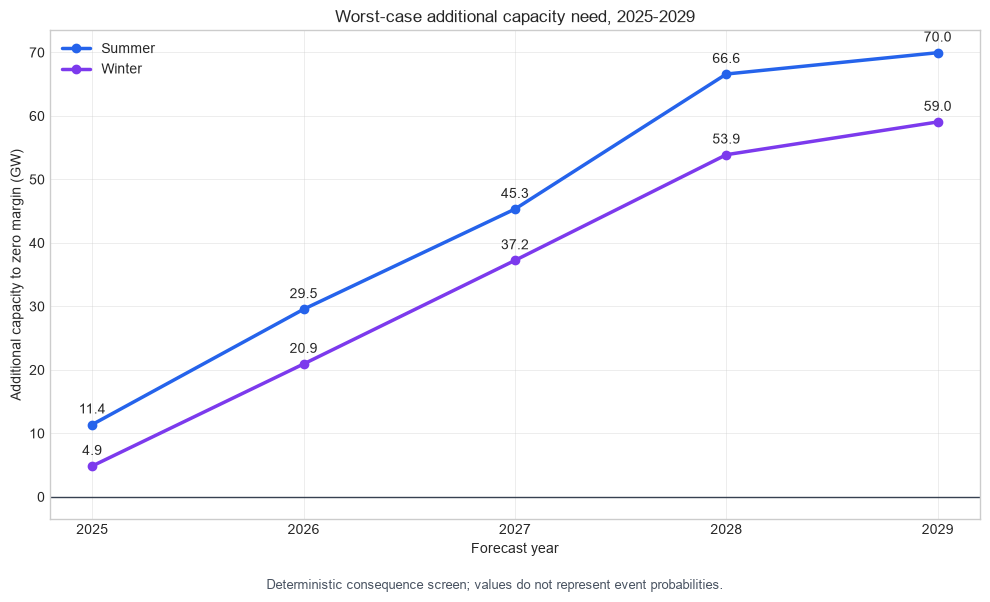

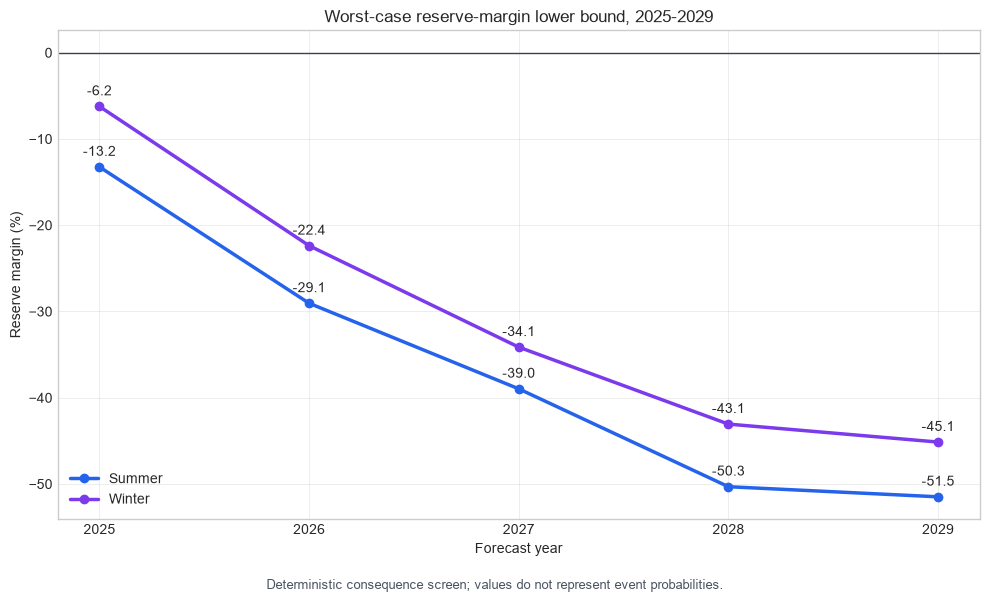

,forecast_year,season,planning_period,growth_scenario,demand_quantile,stress_scenario,severity,seasonal_projected_peak_demand_mw,official_total_capacity_mw,total_supply_loss_lower_mw,...,stressed_reserve_margin_lower,stressed_reserve_margin_upper,stress_capacity_status,system_worst_case_capacity_need_mw,additional_capacity_to_target_upper_mw,worst_case_tie_count,tied_growth_scenarios,worst_case_selection_rule,stressed_reserve_margin_lower_pct,result_scope
0,2025,Summer,2025,Base growth,P95,Compound extreme,Compound stress,85938.352071,103105.481138,28550.048727,...,-0.132455,-0.132454,Deficit,11382.940125,23199.463534,3,Base growth | Low growth | Planning stress growth,Maximum additional capacity required to restor...,-13.245472,Deterministic planning stress screen; not an e...
1,2025,Winter,2025/26,Base growth,P95,Compound extreme,Compound stress,77902.136081,97254.727339,23369.575320,...,-0.062302,-0.051564,Deficit,4853.435264,NaN,3,Base growth | Low growth | Planning stress growth,Maximum additional capacity required to restor...,-6.230170,Deterministic planning stress screen; not an e...
2,2026,Summer,2026,Planning stress growth,P95,Compound extreme,Compound stress,101702.589001,107920.897692,35240.281012,...,-0.290501,-0.285361,Deficit,29544.734624,43528.840611,1,Planning stress growth,Maximum additional capacity required to restor...,-29.050130,Deterministic planning stress screen; not an e...
3,2026,Winter,2026/27,Planning stress growth,P95,Compound extreme,Compound stress,93503.792571,98589.978050,25391.914154,...,-0.223776,-0.217165,Deficit,20923.869619,NaN,1,Planning stress growth,Maximum additional capacity required to restor...,-22.377562,Deterministic planning stress screen; not an e...
4,2027,Summer,2027,Planning stress growth,P95,Compound extreme,Compound stress,116305.555058,107628.293157,35631.872897,...,-0.389711,-0.380972,Deficit,45325.503846,61317.517666,1,Planning stress growth,Maximum additional capacity required to restor...,-38.971057,Deterministic planning stress screen; not an e...
5,2027,Winter,2027/28,Planning stress growth,P95,Compound extreme,Compound stress,109094.547820,96719.047421,24174.715002,...,-0.341378,-0.335032,Deficit,37242.444938,NaN,1,Planning stress growth,Maximum additional capacity required to restor...,-34.137769,Deterministic planning stress screen; not an e...
6,2028,Summer,2028,Planning stress growth,P95,Compound extreme,Compound stress,132358.519176,93370.121741,26591.592601,...,-0.503166,-0.495472,Deficit,66598.306594,84797.602981,1,Planning stress growth,Maximum additional capacity required to restor...,-50.316600,Deterministic planning stress screen; not an e...
7,2028,Winter,2028/29,Planning stress growth,P95,Compound extreme,Compound stress,125151.083324,97011.808193,25008.696474,...,-0.430590,-0.424670,Deficit,53888.749213,NaN,1,Planning stress growth,Maximum additional capacity required to restor...,-43.058955,Deterministic planning stress screen; not an e...
8,2029,Summer,2029,Planning stress growth,P95,Compound extreme,Compound stress,135880.209792,92623.047161,25683.094756,...,-0.514874,-0.507361,Deficit,69961.167998,88644.696844,1,Planning stress growth,Maximum additional capacity required to restor...,-51.487386,Deterministic planning stress screen; not an e...
9,2029,Winter,2029/30,Planning stress growth,P95,Compound extreme,Compound stress,130812.790973,96652.489290,24147.162633,...,-0.451399,-0.445732,Deficit,59048.746244,NaN,1,Planning stress growth,Maximum additional capacity required to restor...,-45.139887,Deterministic planning stress screen; not an e...


,limitation_order,limitation,current_effect,recommended_extension,candidate_stage
0,1,Point-in-time supply vintage,"Results inherit the project, retirement and ca...",Refresh the supply-event table when a newer CD...,08 refresh protocol / 09 industrial extension
1,2,Intermediate-year attribution calibration,"Official total supply covers 2025-2029, while ...",Replace calibration bridges with dated commiss...,09 supply-event model
2,3,Static seasonal scaling,Winter demand is derived from an official scal...,Fit season-specific hourly models with tempera...,09 supply-aware load model
3,4,Deterministic stress assumptions,The 15% and 50% derating assumptions measure c...,Calibrate outage and availability distribution...,09 probabilistic simulation
4,5,Aggregate non-IBR outage proxy,Dispatchable outages use an aggregate non-IBR ...,"Use unit capacity, fuel, outage rate, maintena...",09 unit availability model
5,6,No correlated hourly uncertainty,"Demand, renewable output, outages and storage ...",Run weather-year or Monte Carlo simulations pr...,09 reliability simulation
6,7,No transmission-constrained zonal model,Regional shares cannot identify congestion or ...,"Add transfer limits, transmission constraints ...",09 network-aware extension
7,8,No market-price or bidding layer,Capacity shortfall does not directly produce f...,"Link supply-demand states to scarcity-price, D...",09 market and profit model


In [ ]:
# 07.22A — Generate 2025–2029 decision tables and trend charts
import matplotlib.pyplot as plt

stress_scenarios_0721 = pd.read_csv(
    STRESS_SCENARIOS_0721_PATH
)

stress_summary_0721 = pd.read_csv(
    STRESS_SUMMARY_0721_PATH
)

METHODOLOGY_0718_PATH = (
    CAPACITY_TABLE_DIR
    / "07_18_methodology_summary.csv"
)

LIMITATIONS_0718_PATH = (
    CAPACITY_TABLE_DIR
    / "07_18_limitations_and_next_steps.csv"
)

methodology_0722 = pd.read_csv(
    METHODOLOGY_0718_PATH
)

limitations_0722 = pd.read_csv(
    LIMITATIONS_0718_PATH
)

final_group_keys = [
    "forecast_year",
    "season",
]

worst_capacity_need = (
    stress_scenarios_0721.groupby(
        final_group_keys,
        as_index=False,
    )
    .agg(
        system_worst_case_capacity_need_mw=(
            "additional_capacity_to_zero_margin_upper_mw",
            "max",
        )
    )
)

worst_case_candidates = (
    stress_scenarios_0721.merge(
        worst_capacity_need,
        on=final_group_keys,
        how="inner",
        validate="many_to_one",
    )
)

worst_case_candidates = (
    worst_case_candidates.loc[
        np.isclose(
            worst_case_candidates[
                "additional_capacity_to_zero_margin_upper_mw"
            ],
            worst_case_candidates[
                "system_worst_case_capacity_need_mw"
            ],
            rtol=0,
            atol=1e-6,
        )
    ]
    .copy()
)

worst_case_tie_summary = (
    worst_case_candidates.groupby(
        final_group_keys,
        as_index=False,
    )
    .agg(
        worst_case_tie_count=(
            "growth_scenario",
            "size",
        ),
        tied_growth_scenarios=(
            "growth_scenario",
            lambda values: " | ".join(
                sorted(
                    values.astype(str).unique()
                )
            ),
        ),
    )
)

growth_selection_order = {
    "Base growth": 1,
    "Low growth": 2,
    "Planning stress growth": 3,
}

worst_case_candidates[
    "growth_selection_order"
] = (
    worst_case_candidates[
        "growth_scenario"
    ]
    .map(growth_selection_order)
    .fillna(99)
)

representative_worst_case = (
    worst_case_candidates.sort_values(
        final_group_keys
        + [
            "growth_selection_order",
            "stress_order",
            "demand_quantile",
        ]
    )
    .drop_duplicates(
        subset=final_group_keys,
        keep="first",
    )
)

representative_worst_case = (
    representative_worst_case.merge(
        worst_case_tie_summary,
        on=final_group_keys,
        how="left",
        validate="one_to_one",
    )
)

representative_worst_case[
    "worst_case_selection_rule"
] = (
    "Maximum additional capacity required to restore "
    "zero capacity margin within modeled scenarios"
)

representative_worst_case[
    "stressed_reserve_margin_lower_pct"
] = (
    representative_worst_case[
        "stressed_reserve_margin_lower"
    ]
    * 100
)

representative_worst_case[
    "result_scope"
] = (
    "Deterministic planning stress screen; "
    "not an event probability or market-profit forecast"
)

final_metric_columns = [
    "forecast_year",
    "season",
    "planning_period",
    "growth_scenario",
    "demand_quantile",
    "stress_scenario",
    "severity",
    "seasonal_projected_peak_demand_mw",
    "official_total_capacity_mw",
    "total_supply_loss_lower_mw",
    "total_supply_loss_upper_mw",
    "stressed_available_capacity_lower_mw",
    "stressed_available_capacity_upper_mw",
    "stressed_reserve_margin_lower",
    "stressed_reserve_margin_upper",
    "stress_capacity_status",
    "system_worst_case_capacity_need_mw",
    "additional_capacity_to_target_upper_mw",
    "worst_case_tie_count",
    "tied_growth_scenarios",
    "worst_case_selection_rule",
    "stressed_reserve_margin_lower_pct",
    "result_scope",
]

final_key_metrics_0722 = (
    representative_worst_case[
        final_metric_columns
    ]
    .sort_values(final_group_keys)
    .reset_index(drop=True)
)

assert len(final_key_metrics_0722) == 10, (
    "Final key-metrics table should contain 10 rows."
)

stress_ranking_0722 = (
    stress_summary_0721.sort_values(
        [
            "forecast_year",
            "season",
            "minimum_reserve_margin_lower",
            "maximum_zero_margin_capacity_need_mw",
        ],
        ascending=[
            True,
            True,
            True,
            False,
        ],
    )
    .copy()
)

stress_ranking_0722[
    "risk_rank_within_year_season"
] = (
    stress_ranking_0722.groupby(
        final_group_keys
    )
    .cumcount()
    + 1
)

stress_ranking_0722[
    "risk_tier"
] = np.select(
    [
        stress_ranking_0722[
            "risk_rank_within_year_season"
        ].eq(1),
        stress_ranking_0722[
            "risk_rank_within_year_season"
        ].eq(2),
        stress_ranking_0722[
            "risk_rank_within_year_season"
        ].isin(
            [
                3,
                4,
            ]
        ),
    ],
    [
        "Highest",
        "High",
        "Medium",
    ],
    default="Lower",
)

stress_ranking_0722[
    "ranking_basis"
] = (
    "Ranked by minimum reserve-margin lower bound, "
    "then maximum zero-margin capacity need; "
    "severity only, not probability"
)

assert len(stress_ranking_0722) == 60, (
    "Continuous stress ranking should contain 60 rows."
)

methodology_updates = {
    "Future demand growth": {
        "main_output": (
            "2025-2029 P50/P90/P95 "
            "peak-demand scenarios"
        ),
    },
    "Seasonal demand scaling": {
        "main_input": (
            "07_21 continuous seasonal-demand scaling"
        ),
    },
    "IBR effective capacity": {
        "main_output": (
            "07_20 continuous IBR effective-capacity "
            "detail and summary"
        ),
    },
    "Supply stress testing": {
        "main_input": (
            "07_21 continuous editable stress assumptions"
        ),
        "main_output": (
            "540 continuous demand-supply planning cases"
        ),
    },
    "Decision ranking": {
        "main_input": (
            "07_21 continuous system stress scenarios"
        ),
        "main_output": (
            "07_22 continuous stress ranking "
            "and worst-case metrics"
        ),
    },
    "Decision scope": {
        "main_input": (
            "Audited 07.07-07.21 outputs"
        ),
    },
}

for module_name, column_updates in (
    methodology_updates.items()
):

    module_mask = methodology_0722[
        "module"
    ].eq(module_name)

    for column_name, updated_value in (
        column_updates.items()
    ):

        methodology_0722.loc[
            module_mask,
            column_name,
        ] = updated_value

intermediate_year_mask = (
    limitations_0722[
        "limitation"
    ].eq("Sparse supply endpoints")
)

limitations_0722.loc[
    intermediate_year_mask,
    "limitation",
] = (
    "Intermediate-year attribution calibration"
)

limitations_0722.loc[
    intermediate_year_mask,
    "current_effect",
] = (
    "Official total supply covers 2025-2029, while "
    "intermediate-year IBR attribution uses the "
    "unit-season path plus documented endpoint calibration."
)

limitations_0722.loc[
    intermediate_year_mask,
    "recommended_extension",
] = (
    "Replace calibration bridges with dated commissioning, "
    "retirement, annual ELCC and BESS-duration records "
    "when available."
)

limitations_0722.loc[
    intermediate_year_mask,
    "candidate_stage",
] = "09 supply-event model"

FINAL_METRICS_0722_PATH = (
    CAPACITY_TABLE_DIR
    / "07_22_continuous_final_key_metrics.csv"
)

STRESS_RANKING_0722_PATH = (
    CAPACITY_TABLE_DIR
    / "07_22_continuous_supply_stress_ranking.csv"
)

METHODOLOGY_0722_PATH = (
    CAPACITY_TABLE_DIR
    / "07_22_continuous_methodology_summary.csv"
)

LIMITATIONS_0722_PATH = (
    CAPACITY_TABLE_DIR
    / "07_22_continuous_limitations_and_next_steps.csv"
)

CAPACITY_FIGURE_DIR = (
    PROJECT_ROOT
    / "report"
    / "figures"
    / "capacity_adequacy"
)

CAPACITY_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

WORST_NEED_FIGURE_0722_PATH = (
    CAPACITY_FIGURE_DIR
    / "07_22_continuous_system_worst_case_capacity_need.png"
)

WORST_MARGIN_FIGURE_0722_PATH = (
    CAPACITY_FIGURE_DIR
    / "07_22_continuous_minimum_reserve_margin.png"
)

final_key_metrics_0722.to_csv(
    FINAL_METRICS_0722_PATH,
    index=False,
)

stress_ranking_0722.to_csv(
    STRESS_RANKING_0722_PATH,
    index=False,
)

methodology_0722.to_csv(
    METHODOLOGY_0722_PATH,
    index=False,
)

limitations_0722.to_csv(
    LIMITATIONS_0722_PATH,
    index=False,
)

plt.style.use(
    "seaborn-v0_8-whitegrid"
)

def plot_continuous_metric(
    value_column,
    chart_title,
    y_axis_label,
    output_path,
    value_scale,
):

    figure, axis = plt.subplots(
        figsize=(
            10,
            6,
        )
    )

    for season_name, line_color in [
        (
            "Summer",
            "#2563EB",
        ),
        (
            "Winter",
            "#7C3AED",
        ),
    ]:

        plot_data = (
            final_key_metrics_0722.loc[
                final_key_metrics_0722[
                    "season"
                ].eq(season_name)
            ]
            .sort_values("forecast_year")
        )

        plot_values = (
            plot_data[value_column]
            / value_scale
        )

        axis.plot(
            plot_data["forecast_year"],
            plot_values,
            marker="o",
            linewidth=2.5,
            label=season_name,
            color=line_color,
        )

        for forecast_year, plot_value in zip(
            plot_data["forecast_year"],
            plot_values,
        ):

            axis.annotate(
                f"{plot_value:.1f}",
                (
                    forecast_year,
                    plot_value,
                ),
                xytext=(
                    0,
                    8,
                ),
                textcoords="offset points",
                ha="center",
            )

    axis.axhline(
        0,
        color="#374151",
        linewidth=1,
    )

    axis.set_title(chart_title)

    axis.set_xlabel("Forecast year")

    axis.set_ylabel(y_axis_label)

    axis.set_xticks(
        [
            2025,
            2026,
            2027,
            2028,
            2029,
        ]
    )

    axis.legend()

    figure.text(
        0.5,
        0.01,
        (
            "Deterministic consequence screen; "
            "values do not represent event probabilities."
        ),
        ha="center",
        fontsize=9,
        color="#4B5563",
    )

    figure.tight_layout(
        rect=[
            0,
            0.04,
            1,
            1,
        ]
    )

    figure.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(figure)

plot_continuous_metric(
    value_column=(
        "system_worst_case_capacity_need_mw"
    ),
    chart_title=(
        "Worst-case additional capacity need, 2025-2029"
    ),
    y_axis_label=(
        "Additional capacity to zero margin (GW)"
    ),
    output_path=(
        WORST_NEED_FIGURE_0722_PATH
    ),
    value_scale=1000,
)

plot_continuous_metric(
    value_column=(
        "stressed_reserve_margin_lower_pct"
    ),
    chart_title=(
        "Worst-case reserve-margin lower bound, 2025-2029"
    ),
    y_axis_label="Reserve margin (%)",
    output_path=(
        WORST_MARGIN_FIGURE_0722_PATH
    ),
    value_scale=1,
)

display(final_key_metrics_0722)

display(limitations_0722)

print(
    "Continuous-year final key-metrics rows: ",
    len(final_key_metrics_0722),
)

print(
    "Continuous-year stress-ranking rows: ",
    len(stress_ranking_0722),
)

print(
    "07.22A continuous-year final outputs: PASS"
)

## 07.22B — Final cross-stage QA and closure

Combine QA results from Sections 07.07–07.22. Confirm complete 2025–2029 and summer/winter coverage, consistent stress rankings, and the presence of final tables and two figures. Export both a final-stage QA table and the full-stage QA registry only if every required check passes.

Methods: `pd.read_csv`, `groupby`, `duplicated`, `Path.exists`, `Path.stat`, `pd.concat`, and `to_csv`.

In [ ]:
# 07.22B — Audit the full stage and finalize QA registry
from pathlib import Path

import pandas as pd

from IPython.display import display

PROJECT_ROOT = locate_project_root()

CAPACITY_TABLE_DIR = (
    PROJECT_ROOT
    / "report"
    / "tables"
    / "capacity_adequacy"
)

CAPACITY_FIGURE_DIR = (
    PROJECT_ROOT
    / "report"
    / "figures"
    / "capacity_adequacy"
)

def status_to_bool(series):

    return (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(
            [
                "true",
                "pass",
                "passed",
                "1",
            ]
        )
    )

def summarize_qa_file(
    file_name,
    qa_scope,
    pass_column,
):

    qa_table = pd.read_csv(
        CAPACITY_TABLE_DIR
        / file_name
    )

    pass_flags = status_to_bool(
        qa_table[
            pass_column
        ]
    )

    return {
        "qa_file": file_name,
        "qa_check_count": int(
            len(
                qa_table
            )
        ),
        "qa_pass_count": int(
            pass_flags.sum()
        ),
        "all_checks_passed": bool(
            pass_flags.all()
        ),
        "qa_scope": qa_scope,
    }

legacy_registry = pd.read_csv(
    CAPACITY_TABLE_DIR
    / "07_18_full_stage_qa_registry.csv"
)

legacy_registry[
    "all_checks_passed"
] = status_to_bool(
    legacy_registry[
        "all_checks_passed"
    ]
)

qa_specs = [
    (
        "07_18_final_stage_qa.csv",
        "07_18 final endpoint-stage audit",
        "passed",
    ),
    (
        "07_19_cdr_unit_seasonal_capacity_qa.csv",
        "07_19 continuous unit-season capacity",
        "qa_passed",
    ),
    (
        "07_20_continuous_ibr_effective_capacity_qa.csv",
        "07_20 continuous IBR effective capacity",
        "qa_passed",
    ),
    (
        "07_21_continuous_capacity_adequacy_qa.csv",
        "07_21A continuous capacity adequacy",
        "qa_passed",
    ),
    (
        "07_21_continuous_supply_stress_qa.csv",
        "07_21B continuous supply stress",
        "qa_passed",
    ),
]

new_registry_rows = [
    summarize_qa_file(
        *spec
    )
    for spec in qa_specs
]

pre_final_registry = pd.concat(
    [
        legacy_registry,
        pd.DataFrame(
            new_registry_rows
        ),
    ],
    ignore_index=True,
)

final_key_metrics = pd.read_csv(
    CAPACITY_TABLE_DIR
    / "07_22_continuous_final_key_metrics.csv"
)

stress_ranking = pd.read_csv(
    CAPACITY_TABLE_DIR
    / "07_22_continuous_supply_stress_ranking.csv"
)

methodology_summary = pd.read_csv(
    CAPACITY_TABLE_DIR
    / "07_22_continuous_methodology_summary.csv"
)

limitations_summary = pd.read_csv(
    CAPACITY_TABLE_DIR
    / "07_22_continuous_limitations_and_next_steps.csv"
)

required_final_table_paths = [
    (
        CAPACITY_TABLE_DIR
        / "07_22_continuous_final_key_metrics.csv"
    ),
    (
        CAPACITY_TABLE_DIR
        / "07_22_continuous_supply_stress_ranking.csv"
    ),
    (
        CAPACITY_TABLE_DIR
        / "07_22_continuous_methodology_summary.csv"
    ),
    (
        CAPACITY_TABLE_DIR
        / "07_22_continuous_limitations_and_next_steps.csv"
    ),
]

required_final_figure_paths = [
    (
        CAPACITY_FIGURE_DIR
        / "07_22_continuous_system_worst_case_capacity_need.png"
    ),
    (
        CAPACITY_FIGURE_DIR
        / "07_22_continuous_minimum_reserve_margin.png"
    ),
]

ranking_group_sizes = (
    stress_ranking
    .groupby(
        [
            "forecast_year",
            "season",
        ]
    )
    .size()
)

ranking_rank_sets = (
    stress_ranking
    .groupby(
        [
            "forecast_year",
            "season",
        ]
    )[
        "risk_rank_within_year_season"
    ]
    .apply(
        lambda values: sorted(
            pd.to_numeric(
                values
            )
            .astype(int)
            .tolist()
        )
    )
)

duplicate_final_keys = int(
    final_key_metrics
    .duplicated(
        [
            "forecast_year",
            "season",
        ]
    )
    .sum()
)

negative_capacity_needs = int(
    (
        pd.to_numeric(
            final_key_metrics[
                "system_worst_case_capacity_need_mw"
            ]
        )
        < 0
    )
    .sum()
)

final_table_file_count = int(
    sum(
        path.exists()
        and path.stat().st_size > 0
        for path
        in required_final_table_paths
    )
)

final_figure_file_count = int(
    sum(
        path.exists()
        and path.stat().st_size > 0
        for path
        in required_final_figure_paths
    )
)

final_qa_rows = []

def add_check(
    qa_check,
    observed_value,
    expected_value,
    qa_passed,
):

    final_qa_rows.append(
        {
            "qa_check": qa_check,
            "observed_value": observed_value,
            "expected_value": expected_value,
            "qa_passed": bool(
                qa_passed
            ),
        }
    )

add_check(
    "All registered 07.07-07.21 QA modules pass",
    int(
        pre_final_registry[
            "all_checks_passed"
        ].sum()
    ),
    int(
        len(
            pre_final_registry
        )
    ),
    pre_final_registry[
        "all_checks_passed"
    ].all(),
)

add_check(
    "Final key-metric row count",
    len(
        final_key_metrics
    ),
    10,
    len(
        final_key_metrics
    )
    == 10,
)

observed_years = sorted(
    final_key_metrics[
        "forecast_year"
    ]
    .astype(int)
    .unique()
    .tolist()
)

add_check(
    "Final forecast-year coverage",
    str(
        observed_years
    ),
    str(
        [
            2025,
            2026,
            2027,
            2028,
            2029,
        ]
    ),
    observed_years
    == [
        2025,
        2026,
        2027,
        2028,
        2029,
    ],
)

observed_seasons = sorted(
    final_key_metrics[
        "season"
    ]
    .unique()
    .tolist()
)

add_check(
    "Final season coverage",
    str(
        observed_seasons
    ),
    str(
        [
            "Summer",
            "Winter",
        ]
    ),
    observed_seasons
    == [
        "Summer",
        "Winter",
    ],
)

add_check(
    "Duplicate final year-season keys",
    duplicate_final_keys,
    0,
    duplicate_final_keys
    == 0,
)

add_check(
    "Negative worst-case capacity needs",
    negative_capacity_needs,
    0,
    negative_capacity_needs
    == 0,
)

add_check(
    "Stress-ranking row count",
    len(
        stress_ranking
    ),
    60,
    len(
        stress_ranking
    )
    == 60,
)

add_check(
    "Stress scenarios per year-season",
    str(
        sorted(
            ranking_group_sizes
            .unique()
            .tolist()
        )
    ),
    str(
        [
            6,
        ]
    ),
    (
        ranking_group_sizes
        == 6
    ).all(),
)

valid_rank_sets = ranking_rank_sets.apply(
    lambda values: values
    == [
        1,
        2,
        3,
        4,
        5,
        6,
    ]
)

add_check(
    "Risk ranks 1-6 per year-season",
    int(
        valid_rank_sets.sum()
    ),
    10,
    valid_rank_sets.all(),
)

add_check(
    "Methodology-summary row count",
    len(
        methodology_summary
    ),
    10,
    len(
        methodology_summary
    )
    == 10,
)

add_check(
    "Limitations row count",
    len(
        limitations_summary
    ),
    8,
    len(
        limitations_summary
    )
    == 8,
)

old_limitation_count = int(
    limitations_summary[
        "limitation"
    ]
    .eq(
        "Sparse supply endpoints"
    )
    .sum()
)

add_check(
    "Obsolete sparse-endpoint limitation removed",
    old_limitation_count,
    0,
    old_limitation_count
    == 0,
)

new_limitation_count = int(
    limitations_summary[
        "limitation"
    ]
    .eq(
        "Intermediate-year attribution calibration"
    )
    .sum()
)

add_check(
    "Intermediate-year attribution limitation documented",
    new_limitation_count,
    1,
    new_limitation_count
    == 1,
)

add_check(
    "All required final tables exist and are non-empty",
    final_table_file_count,
    len(
        required_final_table_paths
    ),
    final_table_file_count
    == len(
        required_final_table_paths
    ),
)

add_check(
    "Both final figures exist and are non-empty",
    final_figure_file_count,
    len(
        required_final_figure_paths
    ),
    final_figure_file_count
    == len(
        required_final_figure_paths
    ),
)

final_stage_qa = pd.DataFrame(
    final_qa_rows
)

final_stage_qa[
    "qa_status"
] = final_stage_qa[
    "qa_passed"
].map(
    {
        True: "PASS",
        False: "FAIL",
    }
)

if not final_stage_qa[
    "qa_passed"
].all():

    display(
        final_stage_qa.loc[
            ~final_stage_qa[
                "qa_passed"
            ]
        ]
    )

    raise AssertionError(
        "07.22B final-stage QA failed."
    )

final_registry_row = {
    "qa_file": "07_22_continuous_final_stage_qa.csv",
    "qa_check_count": int(
        len(
            final_stage_qa
        )
    ),
    "qa_pass_count": int(
        final_stage_qa[
            "qa_passed"
        ].sum()
    ),
    "all_checks_passed": bool(
        final_stage_qa[
            "qa_passed"
        ].all()
    ),
    "qa_scope": "07_22 continuous final-stage audit",
}

full_stage_qa_registry = pd.concat(
    [
        pre_final_registry,
        pd.DataFrame(
            [
                final_registry_row,
            ]
        ),
    ],
    ignore_index=True,
)

final_stage_qa_path = (
    CAPACITY_TABLE_DIR
    / "07_22_continuous_final_stage_qa.csv"
)

final_stage_qa.to_csv(
    final_stage_qa_path,
    index=False,
)

full_registry_path = (
    CAPACITY_TABLE_DIR
    / "07_22_continuous_full_stage_qa_registry.csv"
)

full_stage_qa_registry.to_csv(
    full_registry_path,
    index=False,
)

display(
    final_stage_qa
)

display(
    full_stage_qa_registry.tail(
        7
    )
)

print(
    "07.22B final QA: ",
    (
        f"{int(final_stage_qa['qa_passed'].sum())}"
        f"/{len(final_stage_qa)} PASS"
    ),
)

print(
    "Full-stage QA registry: ",
    (
        f"{int(full_stage_qa_registry['all_checks_passed'].sum())}"
        f"/{len(full_stage_qa_registry)} PASS"
    ),
)

print(
    "Stage 07 status: COMPLETE"
)

,qa_check,observed_value,expected_value,qa_passed,qa_status
0,All registered 07.07-07.21 QA modules pass,16,16,True,PASS
1,Final key-metric row count,10,10,True,PASS
2,Final forecast-year coverage,"[2025, 2026, 2027, 2028, 2029]","[2025, 2026, 2027, 2028, 2029]",True,PASS
3,Final season coverage,"['Summer', 'Winter']","['Summer', 'Winter']",True,PASS
4,Duplicate final year-season keys,0,0,True,PASS
5,Negative worst-case capacity needs,0,0,True,PASS
6,Stress-ranking row count,60,60,True,PASS
7,Stress scenarios per year-season,[6],[6],True,PASS
8,Risk ranks 1-6 per year-season,10,10,True,PASS
9,Methodology-summary row count,10,10,True,PASS


,qa_file,qa_check_count,qa_pass_count,all_checks_passed,qa_scope
10,07_17_final_tables_qa.csv,10,10,True,07_17_final_tables_qa
11,07_18_final_stage_qa.csv,14,14,True,07_18 final endpoint-stage audit
12,07_19_cdr_unit_seasonal_capacity_qa.csv,11,11,True,07_19 continuous unit-season capacity
13,07_20_continuous_ibr_effective_capacity_qa.csv,13,13,True,07_20 continuous IBR effective capacity
14,07_21_continuous_capacity_adequacy_qa.csv,13,13,True,07_21A continuous capacity adequacy
15,07_21_continuous_supply_stress_qa.csv,17,17,True,07_21B continuous supply stress
16,07_22_continuous_final_stage_qa.csv,15,15,True,07_22 continuous final-stage audit
